# Affordable housing and street safety in New York City

ICS 503 Data Engineering and Visualization, Winter Semester 2026, Project Milestone 1

## Abstract

Do the crash records support the worry that new affordable housing makes nearby streets less safe? We join two NYC Open Data tables that share no key: Affordable Housing Production by Building (every city-financed building since 2014) and Motor Vehicle Collisions - Crashes (here 2016 to 2025). They are joined two ways, by ZIP code and year and by distance (crashes within 250 m of a building). The outcome is the injury crash, because reporting of crashes without injuries changed sharply in 2020 for reasons unrelated to housing. As associations, not effects: sites already stood, before construction, on streets with more injury crashes than typical street points of their borough, and after completion the change near the new buildings we could isolate cannot be told from no change once not-yet-completed sites are accounted for. Sites are not placed at random and only part of the programme could be isolated, so no result is causal.

## Team

The label in the first column is the one used under each question heading in Section 8.

| Member | Name | Student ID | Research questions |
|---|---|---|---|
| M1 | Ahmed Atef | 16007032 | RQ1 Do housing completions improve a forecast of a ZIP code's injury crashes? RQ2 Do injury crashes in a ZIP code move as its stock of affordable units grows? |
| M2 | Nour Mostafa Aly | 16001618 | RQ3 Do injury crashes within 250 m of a new building change after completion? RQ4 Does that change grow with the size of the building? |
| M3 | Yahia Mohamed | 16004934 | RQ5 Is the change different for new construction than for preservation? RQ6 Does the pedestrian and cyclist share of injury crashes change after completion, by borough? |
| M4 | Moaz Ahmed | 16003110 | RQ7 Before the project starts, are the sites already on streets with more injury crashes than typical street locations of the borough? RQ8 Does the hour-of-day mix of injury crashes shift after completion? |
| M5 | Yassin Fady | 16005869 | RQ9 Is the share of deeply affordable units in a ZIP code associated with crash severity or the pedestrian and cyclist share of harm? RQ10 Which contributing-factor groups are over- or under-represented near completed housing? |

## The two datasets

| Domain | Dataset | Page | API |
|---|---|---|---|
| Housing & Development | Affordable Housing Production by Building (`hg8x-zxpr`) | https://data.cityofnewyork.us/d/hg8x-zxpr | https://data.cityofnewyork.us/resource/hg8x-zxpr.csv |
| Transportation | Motor Vehicle Collisions - Crashes (`h9gi-nx95`) | https://data.cityofnewyork.us/d/h9gi-nx95 | https://data.cityofnewyork.us/resource/h9gi-nx95.csv |

## Where each requirement is met

| Requirement | Section |
|---|---|
| Loading through the Open Data API, overview, selection reasoning, feasibility, known issues | 2 Data |
| Exploratory data analysis with statistics and plots | 3 EDA |
| Pre-integration cleaning: missing values, outliers, inconsistencies, formats, duplicates, cleaning log | 4 Cleaning |
| Integration: join key, granularity and aggregation, with reasons | 5 Integration |
| Post-integration cleaning: new missing values, redundant columns, types, conservation checks | 6 Post-integration cleaning |
| Statistics functions used by the questions, with a self-test | 7 Toolkit |
| Ten research questions, one chart each, with the owner named | 8 Research questions |
| Robustness of the main comparison and of the ZIP-level results | 9 Robustness |
| Discovery, limits, impact, individual contributions, how to run | 10 to 14 Findings, limits, impact, contributions, reproducibility |
| Prompts and AI use | final section |

## 1. Setup

Everything the notebook needs is defined in this section: the libraries, one block of named
constants, the plotting style and a few small helpers. Nothing is imported from a project
folder, so the notebook runs on its own next to the two data files (and downloads them from
NYC Open Data if they are not there).

### 1.1 Libraries

In [1]:
import gc
import io
import math
import platform
import time
from pathlib import Path
from urllib.parse import urlencode

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow  # noqa: F401  (backs the "string[pyarrow]" dtype used when the tables are loaded)
import requests
import scipy
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from matplotlib import patheffects
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

### 1.2 Constants

Every threshold used later is named here once, with its unit and the reason for its value.
Changing a value in this cell and re-running the notebook re-does the whole analysis. The years
that depend on the study window (the break year, the base year of the index, the first test
year, the baseline years) are computed from it here and never typed again further down.

In [2]:
# --- The two datasets (NYC Open Data, one per domain) -----------------------------------------
HOUSING_ID = "hg8x-zxpr"   # Housing & Development: Affordable Housing Production by Building
CRASH_ID = "h9gi-nx95"     # Transportation: Motor Vehicle Collisions - Crashes
DATASET_PAGE = "https://data.cityofnewyork.us/d/{}"
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"

# --- Local copies: the only two files this notebook reads or writes ---------------------------
DATA_DIR = Path(".")                                   # same folder as the notebook
HOUSING_FILE = DATA_DIR / f"housing_{HOUSING_ID}.csv"
CRASH_FILE = DATA_DIR / f"crashes_{CRASH_ID}.csv.gz"

# --- Study window --------------------------------------------------------------------------
YEAR_START, YEAR_END = 2016, 2025   # ten full calendar years; 2026 is still incomplete
STUDY_YEARS = list(range(YEAR_START, YEAR_END + 1))

# --- Crash extraction (a filtered, column-limited copy of a 2.2-million-row table) -------------
CRASH_COLUMNS = [
    "collision_id", "crash_date", "crash_time", "borough", "zip_code", "latitude", "longitude",
    "on_street_name", "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2", "vehicle_type_code1",
]
CRASH_WHERE = (f"crash_date between '{YEAR_START}-01-01T00:00:00' "
               f"and '{YEAR_END}-12-31T23:59:59'")
PAGE_SIZE = 50_000          # rows per API request
HOUSING_ROW_LIMIT = 50_000  # far above the table size, so one request returns every row
REQUEST_RETRIES = 6         # attempts per request, with exponential back-off
REQUEST_TIMEOUT_S = 240

# --- Geography -----------------------------------------------------------------------------
BOROUGHS = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
NYC_BOUNDS = {"lat": (40.45, 40.95), "lon": (-74.30, -73.65)}  # generous box around the five boroughs
EARTH_RADIUS_M = 6_371_000
METRES_PER_DEGREE = EARTH_RADIUS_M * math.pi / 180   # length of one degree of latitude on the sphere
BUFFER_M = 250              # "near a building" = within 250 m, roughly three short Manhattan blocks

# --- Analysis ---------------------------------------------------------------------------------
EVENT_WINDOW = 3            # years compared before and after a building's completion
N_BOOT = 1000               # bootstrap resamples behind every confidence interval
CI_LEVEL = 0.95
MIN_GROUP_N = 30            # no statistic is reported for a group smaller than this
SEED = 42                   # one seed, so every random step is repeatable

# --- Years derived from the study window -----------------------------------------------------
BREAK_YEAR = 2020                       # first year of the reporting change (Section 3)
INDEX_BASE_YEAR = BREAK_YEAR - 1        # last full year before the break; indices equal 100 here
N_TEST_YEARS = 3                        # study years held out of every forecast fit
FIRST_TEST_YEAR = YEAR_END - N_TEST_YEARS + 1   # first held-out year
BASELINE_YEARS = (YEAR_START, YEAR_START + EVENT_WINDOW - 1)   # first and last year of the pre-construction baseline

### 1.3 Plot style

Figures are static images, so they stay visible in any viewer (Jupyter, Colab, GitHub, a PDF
export) without an internet connection. The role colours (housing, crash, treated, control,
placebo) come from the Okabe-Ito palette, which remains distinguishable under the common forms
of colour blindness. The five boroughs use a separate set so that a borough is never mistaken
for a role.

In [3]:
PALETTE = {
    "housing": "#0072B2",    # blue: anything measured on the housing side
    "crash": "#D55E00",      # vermilion: anything measured on the crash side
    "treated": "#0072B2",
    "control": "#7F7F7F",
    "placebo": "#E69F00",
    "before": "#B0B0B0",
    "after": "#009E73",
    "accent": "#CC79A7",
    "neutral": "#4D4D4D",
}
# Boroughs get their own qualitative set (Paul Tol's "muted" scheme, chosen because its colours stay
# apart under the common forms of colour blindness), so none of them borrows the colour of a role
# above (blue = housing, vermilion = crash, orange = placebo). No grey is used, because grey reads as
# "no data". Borough figures also carry a label or a marker, so colour is never the only cue.
BOROUGH_COLORS = dict(zip(BOROUGHS, ["#DDCC77", "#44AA99", "#AA4499", "#88CCEE", "#332288"]))
SEQUENTIAL_CMAP = "viridis"   # ordered quantities

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110, "savefig.dpi": 110,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9.5, "grid.alpha": 0.35,
    "font.family": "DejaVu Sans",
})


def finish(ax, title, xlabel, ylabel, note=None):
    """Label one axes consistently: title, axis labels with units, and an optional footnote."""
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if note:
        ax.annotate(note, xy=(0, -0.2), xycoords="axes fraction", fontsize=8.5,
                    color=PALETTE["neutral"], va="top")
    return ax


def show(fig=None):
    """Lay out and draw the current figure (the one place that calls plt.show)."""
    (fig or plt.gcf()).tight_layout()
    plt.show()


def interval_rows(ax, labels, estimate, low, high, null=0.0, color=None, title="", xlabel=""):
    """Dot-and-interval chart: one row per label, a dashed line at the null value."""
    rows = np.arange(len(labels))[::-1]
    estimate, low, high = (np.asarray(v, dtype=float) for v in (estimate, low, high))
    ax.errorbar(estimate, rows, xerr=[estimate - low, high - estimate], fmt="o", capsize=3,
                color=color or PALETTE["treated"])
    ax.axvline(null, color=PALETTE["neutral"], linestyle="--", linewidth=1)
    ax.set_yticks(rows, labels)
    return finish(ax, title, xlabel, "")


def thousands(ax, axis="y"):
    """Show an axis in plain integers with thousands separators instead of 1e6 notation."""
    formatter = mpl.ticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)
    return ax

### 1.4 Small helpers

`say` prints a sentence whose numbers come from the data, so the commentary never goes stale.
`log_rule` records every cleaning decision in one audit table that Section 4 prints at the end.

In [4]:
CLEANING_LOG = []   # one dict per cleaning rule, filled in Sections 4 and 6


def full_window_years(window=EVENT_WINDOW):
    """Study years that have `window` whole years of crash history on both sides."""
    return [year for year in STUDY_YEARS if year - window >= YEAR_START and year + window <= YEAR_END]


def release(*names):
    """Delete large working objects by name; names that are already gone are skipped.

    A bare `del` fails with a NameError when a cell is run a second time. This version can be
    re-run, and it hands the memory back straight away.
    """
    for name in names:
        globals().pop(name, None)
    gc.collect()


def say(text):
    """Render a Markdown sentence built from computed values (used for data-driven commentary)."""
    display(Markdown(text))


def pct(part, whole):
    """Percentage of `part` in `whole`, safe against an empty denominator."""
    return 100 * part / whole if whole else float("nan")


def n_pct(part, whole, digits=1):
    """'1,234 (5.6%)': a count with its share of a total."""
    return f"{int(part):,} ({pct(part, whole):.{digits}f}%)"


def fmt_ci(estimate, low, high, digits=1, unit=""):
    """'-4.6% (95% CI -11.9% to +3.3%)': an estimate with its interval."""
    f = lambda v: f"{v:+.{digits}f}{unit}"
    return f"{f(estimate)} (95% CI {f(low)} to {f(high)})"


def show_table(frame, rows=20):
    """Display a table without truncating its rows or text columns."""
    with pd.option_context("display.max_rows", rows, "display.max_colwidth", 60):
        display(frame)


def log_rule(dataset, rule, action, rows_before, rows_after, affected, reason):
    """Append one cleaning decision to the audit trail.

    action is one of 'drop', 'impute', 'flag' or 'standardise'; `affected` is the number of rows
    (or cells) the rule changed, which can be non-zero even when no row is dropped.
    """
    CLEANING_LOG.append({
        "dataset": dataset, "rule": rule, "action": action, "rows_before": int(rows_before),
        "rows_after": int(rows_after), "affected": int(affected), "reason": reason,
    })


def missing_table(frame):
    """Per-column missing count and share, sorted from most to least missing."""
    missing = frame.isna().sum()
    table = pd.DataFrame({"missing": missing, "missing_pct": 100 * missing / max(len(frame), 1),
                          "dtype": frame.dtypes.astype(str)})
    return table.sort_values("missing_pct", ascending=False)

## 2. The data

### 2.1 Loading the two datasets

Both tables come from the NYC Open Data API (Socrata) as the assignment shows: dataset id, `$where`,
`$limit` and a stable `$order`. Housing arrives in one request; crashes is a filtered copy (2.5) paged
on the unique, never-missing `collision_id`, so pages cannot overlap or skip rows. The first run saves
both files (several minutes, needs internet); later runs read them offline. Delete a file to refresh it.

In [5]:
# --- Constants shared by Sections 3 and 4 (defined once so the two cannot drift apart) ----------
DATE_FORMAT = "%Y-%m-%dT%H:%M:%S.%f"   # the one timestamp layout the API returns for both tables
BYTES_PER_MB = 1_000_000
CONFIDENTIAL_NAME = "CONFIDENTIAL"     # project_name the publisher uses for withheld records
WITHHELD_ADDRESS = "----"              # house number and street of a withheld record
ZIP_PLACEHOLDER = "10000"              # not a real ZIP: written in the crash table when the officer had none
IQR_MULTIPLIER = 1.5                   # Tukey's fence: 1.5 interquartile ranges beyond the quartiles
EXTREME_INJURED = 10                   # persons; more than this cannot fit in a few cars (bus-scale events)
INTEGER_BIN_COUNT = 30                 # log-spaced bin edges for histograms of unit counts
TOO_MANY_REQUESTS = 429                # HTTP "slow down": worth a retry

# Housing unit columns. A blank in any of them means zero units (shown in Section 3, applied in 4.1).
INCOME_UNIT_COLUMNS = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
                       "moderate_income_units", "middle_income_units", "other_income_units"]
BEDROOM_UNIT_COLUMNS = ["studio_units", "_1_br_units", "_2_br_units", "_3_br_units", "_4_br_units",
                        "_5_br_units", "_6_br_units", "unknown_br_units"]
TENURE_UNIT_COLUMNS = ["counted_rental_units", "counted_homeownership_units"]
TOTAL_UNIT_COLUMNS = ["all_counted_units", "total_units"]
UNIT_COLUMNS = INCOME_UNIT_COLUMNS + BEDROOM_UNIT_COLUMNS + TENURE_UNIT_COLUMNS + TOTAL_UNIT_COLUMNS
HOUSING_REQUIRED = ["project_id", "building_id", "project_name", "borough", "postcode", "latitude", "longitude",
                    "project_start_date", "building_completion_date", "reporting_construction_type", *UNIT_COLUMNS]


def fetch_csv(dataset_id, params):
    """One API request returned as an all-text DataFrame, retried with back-off on 429 and 5xx."""
    url = API_URL.format(dataset_id) + "?" + urlencode(params)
    problem = "no attempt"
    for attempt in range(REQUEST_RETRIES):
        try:
            response = requests.get(url, timeout=REQUEST_TIMEOUT_S)
        except requests.RequestException as error:
            problem = f"network error: {error}"
        else:
            if response.status_code == 200:   # an empty body is the end of the paging
                return pd.read_csv(io.StringIO(response.text), dtype=str) if response.text.strip() else pd.DataFrame()
            problem = f"HTTP {response.status_code}"
            # Any other 4xx means the request itself is wrong, so retrying cannot help.
            if 400 <= response.status_code < 500 and response.status_code != TOO_MANY_REQUESTS:
                raise RuntimeError(f"NYC Open Data rejected the request ({problem}): {url}")
        time.sleep(2 ** attempt)
    raise RuntimeError(f"No answer after {REQUEST_RETRIES} attempts ({problem}): {url}")


def download_housing(path):
    """Download the whole housing table in one request."""
    table = fetch_csv(HOUSING_ID, {"$limit": HOUSING_ROW_LIMIT, "$order": "building_id, project_id"})
    assert len(table) < HOUSING_ROW_LIMIT, "row limit reached (a cut request raises no error): raise it"
    table.to_csv(path, index=False)


def download_crashes(path):
    """Download the filtered crash table with keyset paging, appending each page to a temporary file."""
    partial = path.with_name(path.name + ".part")
    partial.unlink(missing_ok=True)          # a half-finished earlier download is started again
    last_id, saved = 0, 0
    while True:
        page = fetch_csv(CRASH_ID, {"$select": ",".join(CRASH_COLUMNS),
                                    "$where": f"{CRASH_WHERE} AND collision_id > {last_id}",
                                    "$order": "collision_id", "$limit": PAGE_SIZE})
        if page.empty:
            break
        # The API omits a column that is empty on a page, so the full layout is restored.
        page = page.reindex(columns=CRASH_COLUMNS)
        page.to_csv(partial, mode="a", header=saved == 0, index=False, compression="gzip")
        last_id = int(pd.to_numeric(page["collision_id"]).max())
        saved += len(page)
        print(f"  downloaded {saved:>9,} crash rows", end="\r")
    partial.replace(path)                    # renamed only once the last page is in


def load_raw(path, download, required):
    """Read the local copy (downloading it first if missing) as Arrow text, and check its column names."""
    pd.array([], dtype="string[pyarrow]")    # fails at once if pyarrow is missing, not after a download
    if not path.exists():
        print(f"{path.resolve()} not found: downloading from NYC Open Data ...")
        download(path)
    frame = pd.read_csv(path, dtype="string[pyarrow]")   # Arrow strings: a fraction of object memory
    assert set(required) <= set(frame.columns), f"{path.name} lacks API columns {set(required) - set(frame.columns)}"
    return frame


raw_housing = load_raw(HOUSING_FILE, download_housing, HOUSING_REQUIRED)
raw_crashes = load_raw(CRASH_FILE, download_crashes, CRASH_COLUMNS)
print("housing columns:", list(raw_housing.columns), "\ncrash columns:  ", list(raw_crashes.columns))

# --- Helpers shared by Sections 3 and 4, so each rule exists once ---------------------------------
CLOCK_PATTERN = r"^(\d{1,2}):(\d{2})$"                  # crash_time is written H:MM or HH:MM
MID_LATITUDE_DEG = float(np.mean(NYC_BOUNDS["lat"]))    # middle of the city box, for map proportions


def to_number(text, strict=True):
    """Text column to float64; with `strict`, a non-blank value that is not a number stops the notebook."""
    number = pd.Series(pd.to_numeric(text, errors="coerce").to_numpy(dtype="float64", na_value=np.nan),
                       index=text.index, name=text.name)
    if strict:
        unparseable = int((text.notna() & number.isna()).sum())
        assert unparseable == 0, f"{unparseable} non-numeric values in column {text.name}"
    return number


def tukey_upper_fence(values):
    """Third quartile plus IQR_MULTIPLIER interquartile ranges."""
    q1, q3 = np.percentile(values, [25, 75])
    return q3 + IQR_MULTIPLIER * (q3 - q1)


def parse_hour(time_text):
    """Hour (nullable Int8) and minute (float64) from 'H:MM' text; anything else becomes missing."""
    parts = time_text.str.strip().str.extract(CLOCK_PATTERN).astype("float64")
    is_valid = parts[0].between(0, 23) & parts[1].between(0, 59)
    return parts[0].where(is_valid).astype("Int8"), parts[1].where(is_valid)


def memory_mb(frame):
    """Memory held by a frame in megabytes, counting the text inside string columns."""
    return frame.memory_usage(deep=True).sum() / BYTES_PER_MB


def map_axes(ax):
    """Give longitude/latitude axes the proportions of the ground and remove the grid."""
    ax.set_aspect(1 / math.cos(math.radians(MID_LATITUDE_DEG)))
    ax.grid(False)
    return ax


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(item) for item in items]
    return " and ".join(items) if len(items) <= 2 else ", ".join(items[:-1]) + " and " + items[-1]


def integer_log_bins(maximum):
    """Log-axis histogram edges halfway between integers, so small counts leave no empty gaps."""
    steps = np.unique(np.round(np.logspace(0, np.log10(maximum), INTEGER_BIN_COUNT)))
    return np.append(steps - 0.5, maximum + 0.5)

housing columns: ['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units'] 
crash columns:   ['collision_id', 'crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'on_street_name', 'number_of_persons_injured', 'number_of_persons_killed',

### 2.2 Dataset overview
One profile per copy: size, grain, time and place attributes and their completeness (also used in 2.4).

In [6]:
def profile(name, dataset_id, domain, frame, grain, date_column, zip_column, time_columns, place_columns):
    """One column of the overview table for one raw dataset."""
    filled = lambda columns: f"{100 * frame[columns].notna().all(axis=1).mean():.1f}"
    days = frame[date_column].dropna().str.slice(0, 10)   # ISO text: the first ten characters are the day
    return name, {
        "domain": domain, "id": dataset_id, "page": DATASET_PAGE.format(dataset_id), "one row is": grain,
        "rows": f"{len(frame):,}", "columns": frame.shape[1],   # the API column names are printed in 2.1
        "time attributes": ", ".join(time_columns), "place attributes": ", ".join(place_columns),
        "date range": f"{days.min()} to {days.max()} ({date_column})",
        "rows with coordinates (%)": filled(["latitude", "longitude"]),
        "rows with a ZIP code (%)": filled([zip_column]),
        "rows with a borough (%)": filled(["borough"]),
        "distinct ZIP values": frame[zip_column].nunique(),
    }


overview = pd.DataFrame(dict([
    profile("Affordable Housing Production by Building", HOUSING_ID, "Housing & Development", raw_housing,
            "a building in a city-financed affordable housing project", "project_start_date", "postcode",
            ["project_start_date", "project_completion_date", "building_completion_date"],
            ["borough", "postcode", "community_board", "census_tract", "latitude", "longitude"]),
    profile("Motor Vehicle Collisions - Crashes", CRASH_ID, "Transportation", raw_crashes,
            "a police-reported motor vehicle collision", "crash_date", "zip_code",
            ["crash_date", "crash_time"], ["borough", "zip_code", "on_street_name", "latitude", "longitude"]),
]))
shared_columns = set(raw_housing.columns) & set(raw_crashes.columns)
overview.loc["column names shared by both"] = ", ".join(sorted(shared_columns))
with pd.option_context("display.max_colwidth", 90):
    display(overview)
# The assignment requires at least 9 columns per dataset and a shared integration attribute.
assert min(raw_housing.shape[1], raw_crashes.shape[1]) >= 9 and {"borough", "latitude", "longitude"} <= shared_columns

,Affordable Housing Production by Building,Motor Vehicle Collisions - Crashes
domain,Housing & Development,Transportation
id,hg8x-zxpr,h9gi-nx95
page,https://data.cityofnewyork.us/d/hg8x-zxpr,https://data.cityofnewyork.us/d/h9gi-nx95
one row is,a building in a city-financed affordable housing project,a police-reported motor vehicle collision
rows,"9,551","1,504,722"
columns,41,19
time attributes,"project_start_date, project_completion_date, building_completion_date","crash_date, crash_time"
place attributes,"borough, postcode, community_board, census_tract, latitude, longitude","borough, zip_code, on_street_name, latitude, longitude"
date range,2014-01-03 to 2026-06-30 (project_start_date),2016-01-01 to 2025-12-31 (crash_date)
rows with coordinates (%),79.5,91.7


### 2.3 Why these two datasets

Do streets around new affordable housing differ in injury crashes, and change at completion? Both
sides need a precise place and date. Housing gives the events: completion date, units by income
band, new construction or preservation (no new residents: a natural comparison) and a point. Crashes
give the outcome: date, time, point, casualties by pedestrian, cyclist and motorist.

| Catalog | Alternative considered | Why it was weaker for this question |
|---|---|---|
| Housing | DOB violations, HPD complaints | Describe existing buildings; no date when new homes open, no household count. |
| Housing | DOB permits and job filings | An intention to build; no affordable-unit count, no dependable completion date. |
| Transportation | Parking meters, street permits | Inventory or activity with no safety outcome. |
| Transportation | Traffic and bike counts, bus delays | Few locations, or no coordinate, so most sites have no observation nearby. |
| Transportation | Taxi trips | Located by taxi zone only, and too large for a notebook. |

The deciding point: both tables carry coordinates, ZIP, borough and exact date, allowing two
independent joins (ZIP by year, and distance) that check each other. No other pair had all four.

### 2.4 Feasibility check

The catalog lists the crash table as "SIRTA Data", so a feasibility check is included (from 2.2):

* **Size.** Both clear nine columns; ten years of crashes put many collisions around each building.
* **Geographic and temporal attributes.** Borough, ZIP, coordinates and date on both; crash time too.
* **Expected integration.** No shared row key; the tables meet at ZIP by year and by distance
  (a crash within 250 m of a building), both built in Section 5.
* **Support for the question.** Most rows have coordinates and crash years span before and after
  most completions. Coverage gaps are not random (Section 3).

### 2.5 Why the crash table is a filtered copy

The cell prints the exact request (constants from 1.2), checks the copy matches it, and sizes it.

In [7]:
CRASH_COLUMNS_NOT_LOADED = ["location", "off_street_name", "cross_street_name",   # text repeated elsewhere
                            *[f"contributing_factor_vehicle_{n}" for n in (3, 4, 5)],
                            "vehicle_type_code2", *[f"vehicle_type_code_{n}" for n in (3, 4, 5)]]
crash_request = pd.Series({
    "$select": ", ".join(CRASH_COLUMNS), "$order": "collision_id",
    "$where": CRASH_WHERE + " AND collision_id > (last collision_id of the previous page)",
    "$limit": f"{PAGE_SIZE:,} rows per request, repeated until a request returns no rows",
    "columns not requested": ", ".join(CRASH_COLUMNS_NOT_LOADED)}, name="value")
with pd.option_context("display.max_colwidth", None):
    display(crash_request.to_frame())

# The copy must match the request: every year inside the window and every collision once.
assert raw_crashes["crash_date"].str.slice(0, 4).astype(int).between(YEAR_START, YEAR_END).all()
assert raw_crashes["collision_id"].is_unique, "paging returned a collision twice"
cohort_years = full_window_years()   # completion years with EVENT_WINDOW whole years on each side
say(f"The copy holds **{len(raw_crashes):,} crashes** from {YEAR_START} to {YEAR_END} ({len(STUDY_YEARS)} "
    f"years), {len(CRASH_COLUMNS)} of the {len(CRASH_COLUMNS) + len(CRASH_COLUMNS_NOT_LOADED)} source "
    f"columns, no `collision_id` twice, and **{memory_mb(raw_crashes):,.0f} MB** as text. Buildings completed "
    f"{cohort_years[0]}-{cohort_years[-1]} have {EVENT_WINDOW} full crash years before and after.")

,value
$select,"collision_id, crash_date, crash_time, borough, zip_code, latitude, longitude, on_street_name, number_of_persons_injured, number_of_persons_killed, number_of_pedestrians_injured, number_of_pedestrians_killed, number_of_cyclist_injured, number_of_cyclist_killed, number_of_motorist_injured, number_of_motorist_killed, contributing_factor_vehicle_1, contributing_factor_vehicle_2, vehicle_type_code1"
$order,collision_id
$where,crash_date between '2016-01-01T00:00:00' and '2025-12-31T23:59:59' AND collision_id > (last collision_id of the previous page)
$limit,"50,000 rows per request, repeated until a request returns no rows"
columns not requested,"location, off_street_name, cross_street_name, contributing_factor_vehicle_3, contributing_factor_vehicle_4, contributing_factor_vehicle_5, vehicle_type_code2, vehicle_type_code_3, vehicle_type_code_4, vehicle_type_code_5"


The copy holds **1,504,722 crashes** from 2016 to 2025 (10 years), 19 of the 29 source columns, no `collision_id` twice, and **437 MB** as text. Buildings completed 2019-2022 have 3 full crash years before and after.

The filter restricts rows by date and columns by name; it does not sample, so every crash in the
window is loaded. **Memory:** the full text table leaves free Colab no room for the spatial join.
**2026** is out because a partial year looks like a fall in crashes; **before 2016** no question
reads (the earliest window starts in 2016). **Columns** left out are later vehicles' factors and
types and street text repeating `on_street_name` and the coordinates. A random sample was rejected:
crashes within 250 m of one building in one year are already few, and sampling would zero many.

### 2.6 Known issues at a glance

| Dataset | Issue | Handled in |
|---|---|---|
| Housing | Unit counts blank where zero; confidential rows without address, ZIP or coordinates | 4.1, 4.3 |
| Housing | No completion date; one building under several projects; right-skewed size | 4.4, 4.2, 4.6 |
| Crashes | ZIP and borough missing together for a large, year-varying share | Section 6 (ZIP recovered from coordinates) |
| Crashes | Coordinates missing, at (0, 0) or outside the city; placeholder ZIP codes | 4.8 |
| Crashes | Reports of crashes without injuries fall sharply from 2020 | Section 3; analyses use injury crashes |
| Crashes | Injured total differs from its parts; a few crashes with very many injured | 4.9, 4.10 |
| Crashes | Factor spelling variants and a large "Unspecified" group; 0:00 doubles as unknown time | 4.11, 4.7 |
| Both | All text; borough letter case differs; rows without a partner after the join | Section 4; Section 6 |

## 3. Exploratory data analysis

This section looks at both tables as loaded, before any cleaning, to find what is in them, what
is wrong with them and what that means for joining them. Every rule in Section 4 answers a
problem seen here first. The raw frames hold text only, so each table gets a temporary numeric
view; the views are deleted at the end and nothing defined here is used later. Text that does not
convert becomes missing in the view and is counted, which is itself a finding.

In [8]:
# --- Constants and helpers used only in this section ---------------------------------------------
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
INJURY_COLUMNS = ["number_of_persons_injured", "number_of_persons_killed",
                  "number_of_pedestrians_injured", "number_of_pedestrians_killed",
                  "number_of_cyclist_injured", "number_of_cyclist_killed",
                  "number_of_motorist_injured", "number_of_motorist_killed"]
INJURY_PARTS = ["number_of_pedestrians_injured", "number_of_cyclist_injured", "number_of_motorist_injured"]
TYPE_COLORS = {"New Construction": PALETTE["housing"], "Preservation": PALETTE["placebo"]}


def to_date(text):
    """Parse a raw ISO timestamp column; anything that does not match the format becomes NaT."""
    return pd.to_datetime(text, format=DATE_FORMAT, errors="coerce")


def column_profile(frame):
    """Per-column profile of a raw table: dtype as loaded, missing count and share, distinct values."""
    table = missing_table(frame)
    table["distinct"] = frame.nunique().reindex(table.index)
    return table.rename(columns={"dtype": "dtype as loaded", "missing_pct": "missing %"}).round(1)


def housing_view(raw):
    """Numeric and datetime view of the raw housing table."""
    view = pd.DataFrame(index=raw.index)
    view["is_confidential"] = (raw["project_name"].str.strip().str.upper() == CONFIDENTIAL_NAME).fillna(False).to_numpy()
    view["construction_type"] = raw["reporting_construction_type"].astype(object)
    for column in UNIT_COLUMNS + ["latitude", "longitude"]:
        view[column] = to_number(raw[column], strict=False)
    for column in ["project_start_date", "project_completion_date", "building_completion_date"]:
        view[column] = to_date(raw[column])
    # The building date is the precise one; the project date stands in when it is absent.
    view["completion_date"] = view["building_completion_date"].fillna(view["project_completion_date"])
    return view


def crash_view(raw):
    """Lean numeric view of the 1.5M-row crash table: only what the charts and facts need."""
    date = to_date(raw["crash_date"])
    assert date.notna().all(), "a crash date does not follow the API date format"
    view = pd.DataFrame({"year": date.dt.year.astype("int16"), "weekday": date.dt.dayofweek.astype("int8")})
    view["hour"], minute = parse_hour(raw["crash_time"])
    view["on_the_hour"] = (minute == 0).to_numpy()
    casualties = pd.DataFrame({c: to_number(raw[c], strict=False).astype("float32") for c in INJURY_COLUMNS})
    view["injured"] = casualties["number_of_persons_injured"]
    view["is_injury"] = casualties.fillna(0).sum(axis=1).gt(0).to_numpy()
    # Compared only where the total is recorded; a missing total is counted as a gap, not a mismatch.
    view["parts_differ"] = ((casualties["number_of_persons_injured"] != casualties[INJURY_PARTS].sum(axis=1))
                            & casualties["number_of_persons_injured"].notna()).to_numpy()
    lat, lon = to_number(raw["latitude"], strict=False), to_number(raw["longitude"], strict=False)
    view["coord_missing"] = (lat.isna() | lon.isna()).to_numpy()
    view["coord_zero"] = ((lat == 0) & (lon == 0)).to_numpy()
    in_box = lat.between(*NYC_BOUNDS["lat"]) & lon.between(*NYC_BOUNDS["lon"])
    view["coord_unusable"] = (~in_box).to_numpy()          # missing, (0, 0) and outside the city box
    view["zip_missing"] = raw["zip_code"].isna().to_numpy()
    view["borough_missing"] = raw["borough"].isna().to_numpy()
    return view


def spelling_report(frame, table_name, columns):
    """Distinct values as written vs after trimming and case-folding, plus stray spaces and digit-only labels."""
    rows = []
    for column in columns:
        text = frame[column].dropna()
        rows.append({"table": table_name, "column": column, "distinct as written": text.nunique(),
                     "after trim + case-fold": text.str.strip().str.casefold().nunique(),
                     "padded with spaces": int((text != text.str.strip()).sum()),
                     "digit-only labels": int(text.str.fullmatch(r"\d+").sum())})
    return pd.DataFrame(rows).set_index(["table", "column"])


eda_housing = housing_view(raw_housing)
eda_crashes = crash_view(raw_crashes)
housing_profile, crash_profile = column_profile(raw_housing), column_profile(raw_crashes)

### 3.1 Descriptive statistics

One profile per table (every column was loaded as text, so dtype shows the loading choice, not the
content), then the summary of the numeric fields. Reading everything as text and converting
explicitly was chosen over letting pandas guess types: guessing turns ZIP codes and identifiers
into decimals as soon as one value is missing, and a decimal ZIP no longer matches a text ZIP.

In [9]:
say(f"**Housing:** {raw_housing.shape[0]:,} rows x {raw_housing.shape[1]} columns, "
    f"{int((housing_profile['missing'] > 0).sum())} columns with gaps. **Crashes:** "
    f"{raw_crashes.shape[0]:,} rows x {raw_crashes.shape[1]} columns, "
    f"{int((crash_profile['missing'] > 0).sum())} columns with gaps.")
show_table(housing_profile, rows=60)
show_table(crash_profile, rows=30)

numeric = pd.DataFrame({"housing total_units": eda_housing["total_units"].reset_index(drop=True),
                        "crash persons injured": eda_crashes["injured"].reset_index(drop=True)})
describe = numeric.describe(percentiles=[0.5, 0.95, 0.99]).T.round(2)
describe.insert(0, "rows with a value", describe.pop("count").astype(int))
show_table(describe)

**Housing:** 9,551 rows x 41 columns, 29 columns with gaps. **Crashes:** 1,504,722 rows x 19 columns, 10 columns with gaps.

,missing,missing %,dtype as loaded,distinct
_6_br_units,9524,99.700,string,5
_5_br_units,9478,99.200,string,11
_4_br_units,8990,94.100,string,34
unknown_br_units,8862,92.800,string,21
other_income_units,8191,85.800,string,5
moderate_income_units,7857,82.300,string,104
extremely_low_income_units,7470,78.200,string,190
middle_income_units,6860,71.800,string,153
counted_homeownership_units,6821,71.400,string,137
studio_units,6353,66.500,string,157


,missing,missing %,dtype as loaded,distinct
zip_code,508284,33.800,string,233
borough,508028,33.800,string,5
on_street_name,379864,25.200,string,21643
contributing_factor_vehicle_2,272828,18.100,string,60
longitude,125582,8.300,string,111767
latitude,125582,8.300,string,159500
vehicle_type_code1,15459,1.000,string,1852
contributing_factor_vehicle_1,6442,0.400,string,61
number_of_persons_killed,36,0.000,string,7
number_of_persons_injured,18,0.000,string,29


,rows with a value,mean,std,min,50%,95%,99%,max
housing total_units,9551,46.650,92.480,1.000,12.000,213.500,429.500,"1,320.000"
crash persons injured,1504704,0.370,0.740,0.000,0.000,2.000,3.000,40.000


### 3.2 Missing values (chart 1)

Both tables are shown on the same 0 to 100% scale. The housing gaps are of three kinds (unit
counts, location fields, dates) and the crash gaps are concentrated in location.

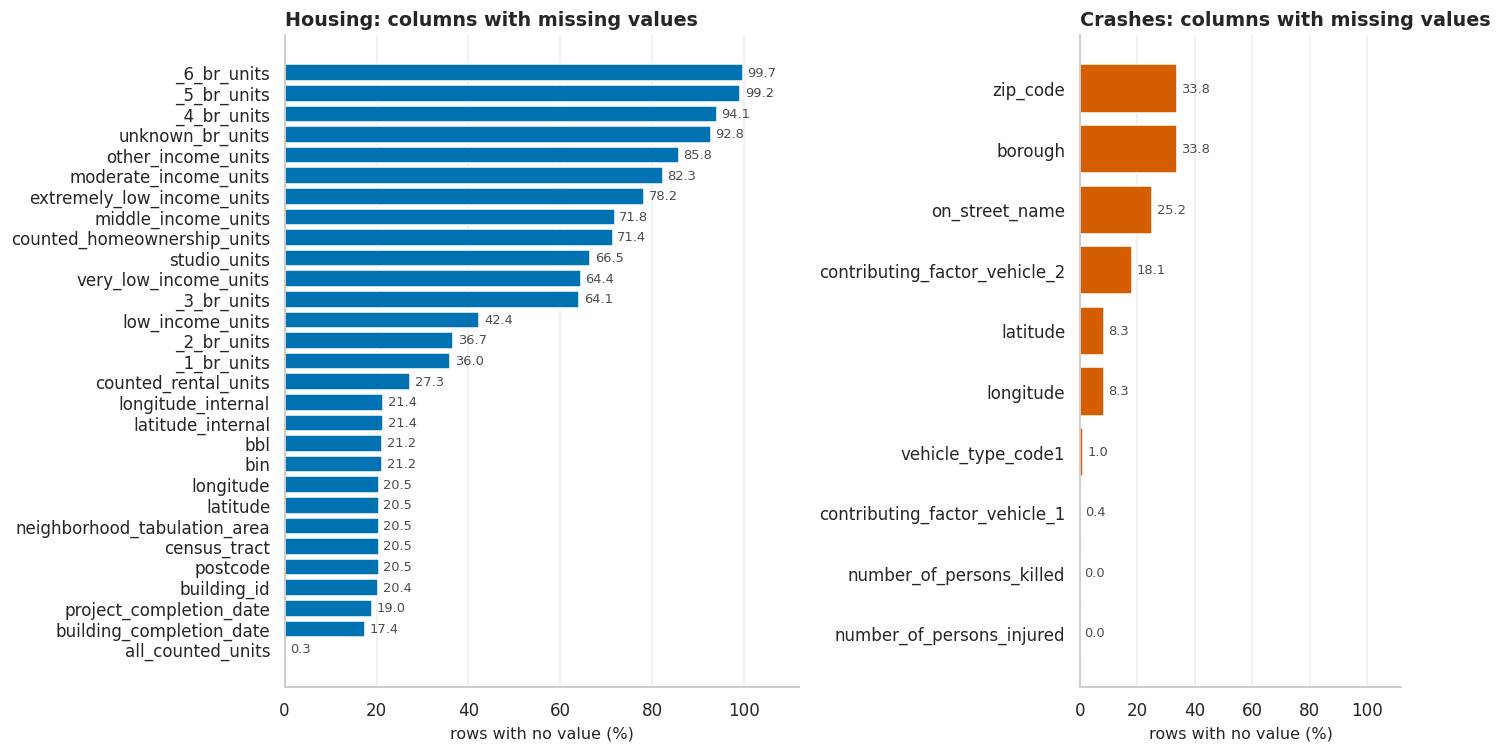

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True, gridspec_kw={"width_ratios": [1.6, 1]})
for ax, table, title in [(axes[0], housing_profile, "Housing"), (axes[1], crash_profile, "Crashes")]:
    gaps = table[table["missing"] > 0].sort_values("missing %")
    bars = ax.barh(gaps.index, gaps["missing %"], color=PALETTE["housing" if title == "Housing" else "crash"])
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8.5, color=PALETTE["neutral"])
    ax.grid(axis="y", visible=False)
    finish(ax, f"{title}: columns with missing values", "rows with no value (%)", "")
axes[0].set_xlim(0, 112)
show(fig)

Most housing unit columns are blank for most rows, the location fields share one gap, and in the
crash table ZIP code and borough go missing together.

In [11]:
housing_blank = eda_housing[UNIT_COLUMNS].isna()
filled = eda_housing[UNIT_COLUMNS].fillna(0)
located = eda_housing["latitude"].notna() & eda_housing["longitude"].notna()
hidden = eda_housing["is_confidential"]
units = eda_housing["total_units"]
same_day = int((eda_housing["completion_date"] == eda_housing["project_start_date"]).sum())
repeat_ids = int(raw_housing["building_id"].dropna().duplicated().sum())
say(f"**Housing facts (computed).** {n_pct(housing_blank.to_numpy().sum(), housing_blank.size)} of unit cells "
    f"are blank and only {int((eda_housing[UNIT_COLUMNS] == 0).to_numpy().sum())} hold a written zero; with blanks "
    f"read as zero the income bands add up to `all_counted_units` in "
    f"{n_pct((filled[INCOME_UNIT_COLUMNS].sum(axis=1) == filled['all_counted_units']).sum(), len(filled))} of rows, "
    f"so blank means zero. **Confidential** rows: {n_pct(hidden.sum(), len(hidden))}, holding "
    f"{n_pct(units[hidden].sum(), units.sum())} of units; {int((~hidden & ~located).sum())} other rows lack "
    f"coordinates. **{repeat_ids}** rows repeat a `building_id`. "
    f"{n_pct(same_day, len(eda_housing))} of buildings complete on their project start day, and {int((eda_housing['completion_date'] > pd.Timestamp(f'{YEAR_END}-12-31')).sum())} "
    f"completion dates fall after {YEAR_END}.")

crash_year = eda_crashes.groupby("year")
say(f"**Crash facts (computed).** ZIP and borough both missing in "
    f"{n_pct((eda_crashes['zip_missing'] & eda_crashes['borough_missing']).sum(), len(eda_crashes))} of crashes. "
    f"Coordinates are missing in {n_pct(eda_crashes['coord_missing'].sum(), len(eda_crashes))} and "
    f"{eda_crashes['coord_zero'].sum():,} sit at (0, 0). Persons injured differs from the sum of its three "
    f"parts in {eda_crashes['parts_differ'].sum():,} crashes. "
    f"{n_pct((raw_crashes['contributing_factor_vehicle_1'] == 'Unspecified').sum(), raw_crashes['contributing_factor_vehicle_1'].notna().sum())} "
    f"of recorded first factors are `Unspecified`. {n_pct(eda_crashes['on_the_hour'].sum(), eda_crashes['hour'].notna().sum())} "
    f"of crashes are logged exactly on the hour.")

**Housing facts (computed).** 106,309 (61.8%) of unit cells are blank and only 0 hold a written zero; with blanks read as zero the income bands add up to `all_counted_units` in 9,551 (100.0%) of rows, so blank means zero. **Confidential** rows: 1,949 (20.4%), holding 2,806 (0.6%) of units; 9 other rows lack coordinates. **124** rows repeat a `building_id`. 2,824 (29.6%) of buildings complete on their project start day, and 476 completion dates fall after 2025.

**Crash facts (computed).** ZIP and borough both missing in 508,028 (33.8%) of crashes. Coordinates are missing in 125,582 (8.3%) and 6,769 sit at (0, 0). Persons injured differs from the sum of its three parts in 10,405 crashes. 362,110 (24.2%) of recorded first factors are `Unspecified`. 294,594 (19.6%) of crashes are logged exactly on the hour.

### 3.3 Housing: building size, completions and location (charts 2 to 4)

`total_units` drives several questions, so its shape matters. The histogram uses a log axis
because almost every building would otherwise fall in the first bar. It marks the median and the
Tukey upper fence (third quartile + 1.5 x IQR), the usual outlier rule.

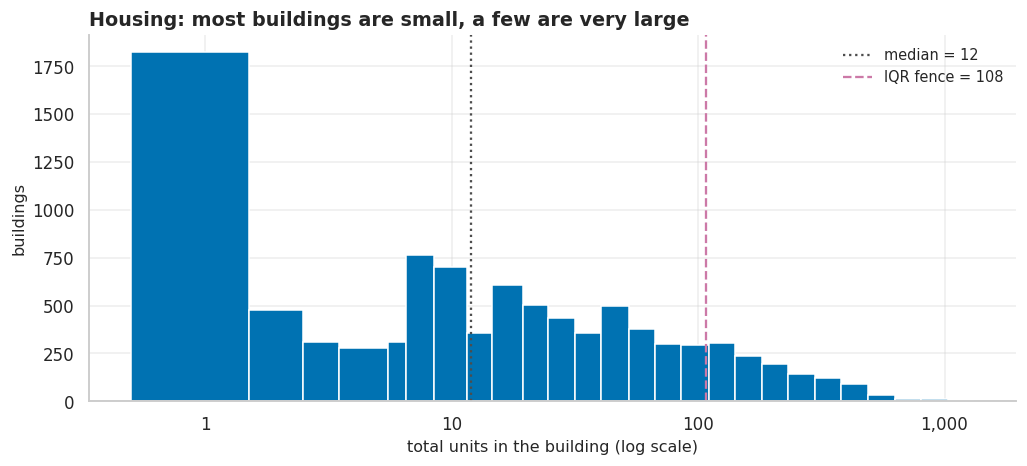

1,171 (12.3%) of buildings lie above the fence and the largest has 1,320 units. Large buildings are real and are what RQ4 needs, so Section 4 flags them and does not remove them.

In [12]:
sizes = units.dropna()
fence = tukey_upper_fence(sizes)
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.hist(sizes, bins=integer_log_bins(sizes.max()), color=PALETTE["housing"], edgecolor="white")
ax.set_xscale("log")
thousands(ax, axis="x")
ax.axvline(sizes.median(), color=PALETTE["neutral"], linestyle=":", label=f"median = {sizes.median():.0f}")
ax.axvline(fence, color=PALETTE["accent"], linestyle="--", label=f"IQR fence = {fence:.0f}")
ax.legend()
finish(ax, "Housing: most buildings are small, a few are very large",
       "total units in the building (log scale)", "buildings")
show(fig)
say(f"{n_pct((sizes > fence).sum(), len(sizes))} of buildings lie above the fence and the largest has "
    f"{sizes.max():,.0f} units. Large buildings are real and are what RQ4 needs, so Section 4 flags them and "
    f"does not remove them.")

Completions per year, split by type. A building counts in the year of its completion date.

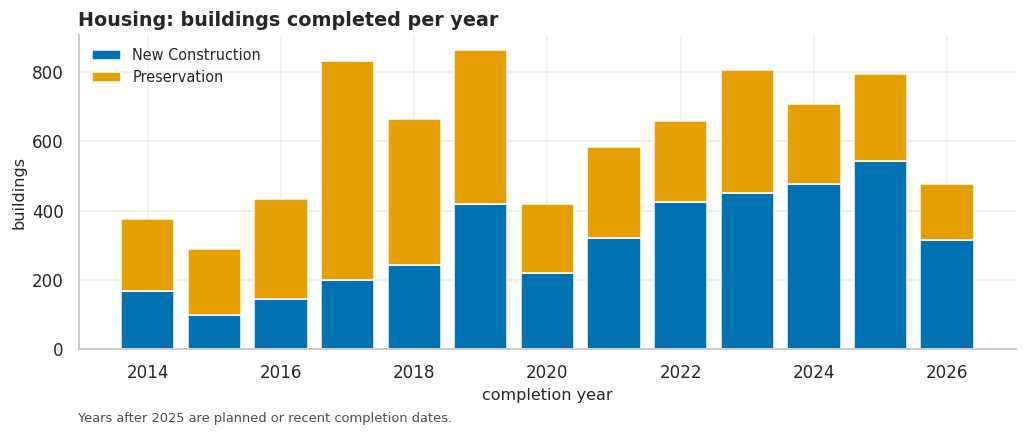

In [13]:
by_year = (eda_housing.groupby([eda_housing["completion_date"].dt.year, "construction_type"]).size()
           .unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bottom = np.zeros(len(by_year))
for name, color in TYPE_COLORS.items():
    ax.bar(by_year.index, by_year[name], bottom=bottom, color=color, label=name)
    bottom += by_year[name].to_numpy()
ax.legend()
finish(ax, "Housing: buildings completed per year", "completion year", "buildings",
       note=f"Years after {YEAR_END} are planned or recent completion dates.")
show(fig)

Map of the buildings that have coordinates. Confidential rows have none, so they are absent
here; Section 4 keeps them for borough totals only.

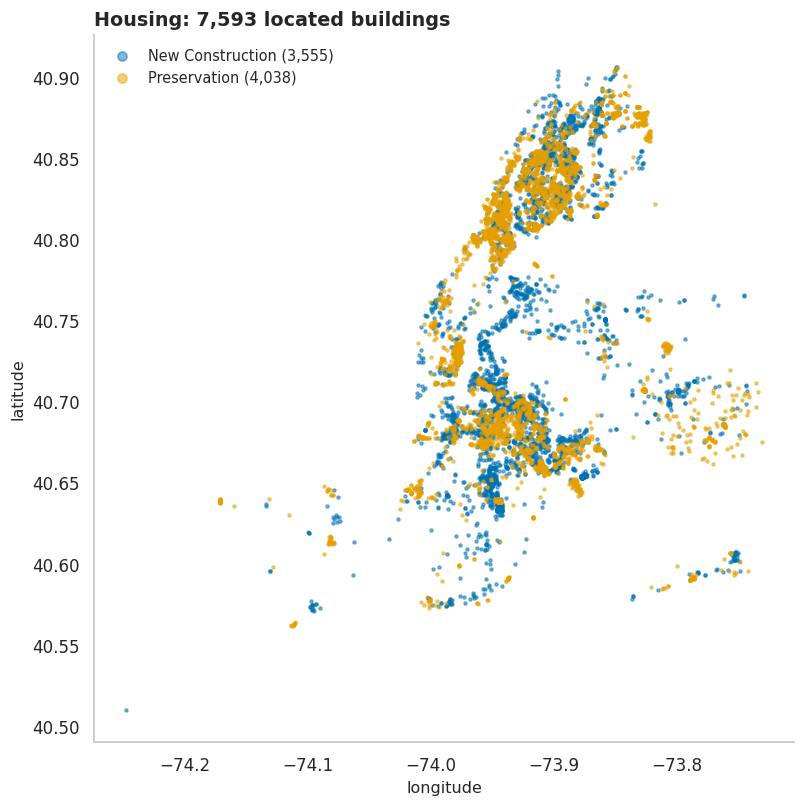

In [14]:
in_city = located & eda_housing["latitude"].between(*NYC_BOUNDS["lat"]) & eda_housing["longitude"].between(*NYC_BOUNDS["lon"])
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for name, color in TYPE_COLORS.items():
    points = eda_housing[in_city & (eda_housing["construction_type"] == name)]
    ax.scatter(points["longitude"], points["latitude"], s=4, alpha=0.5, color=color,
               label=f"{name} ({len(points):,})")
ax.legend(markerscale=3, loc="upper left")
map_axes(ax)
finish(ax, f"Housing: {in_city.sum():,} located buildings", "longitude", "latitude")
show(fig)

### 3.4 Crashes: location gaps, the 2020 break, time of day and outliers (charts 5 to 8)

The first chart splits two location gaps by year: crashes without a ZIP code, and crashes
without usable coordinates (missing, at (0, 0) or outside the city box). They decide which
crashes can take part in the ZIP join and the distance join.

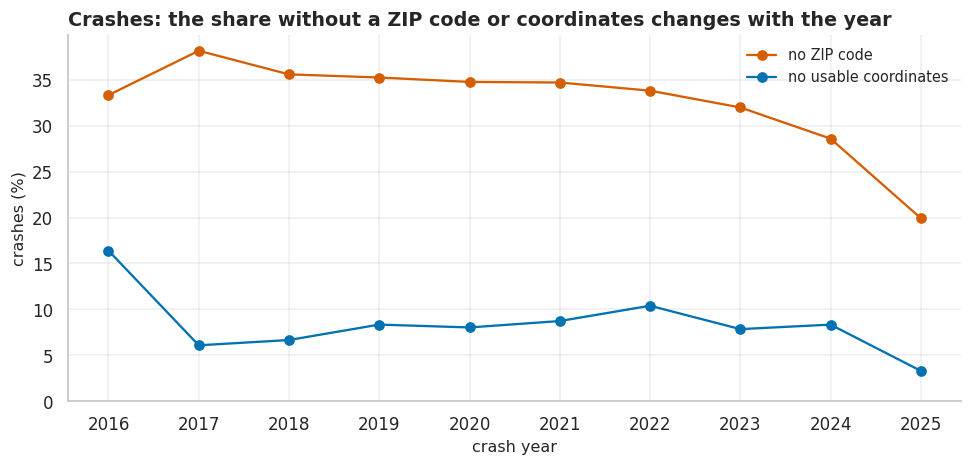

No ZIP code: 33.3% in 2016 and 19.9% in 2025. No usable coordinates: 16.4% in 2016 against 3.3% to 10.4% later. A gap that varies by year would bias any before/after count, so Section 6.1 recovers ZIP codes from coordinates and checks the result.

In [15]:
gap_by_year = pd.DataFrame({
    "no ZIP code": crash_year["zip_missing"].mean() * 100,
    "no usable coordinates": crash_year["coord_unusable"].mean() * 100})
fig, ax = plt.subplots(figsize=(9, 4.4))
for column, color in [("no ZIP code", PALETTE["crash"]), ("no usable coordinates", PALETTE["housing"])]:
    ax.plot(gap_by_year.index, gap_by_year[column], marker="o", color=color, label=column)
ax.set_xticks(gap_by_year.index)
ax.set_ylim(0)
ax.legend()
finish(ax, "Crashes: the share without a ZIP code or coordinates changes with the year",
       "crash year", "crashes (%)")
show(fig)
say(f"No ZIP code: {gap_by_year['no ZIP code'].iloc[0]:.1f}% in {YEAR_START} and "
    f"{gap_by_year['no ZIP code'].iloc[-1]:.1f}% in {YEAR_END}. No usable coordinates: "
    f"{gap_by_year['no usable coordinates'].loc[YEAR_START]:.1f}% in {YEAR_START} against "
    f"{gap_by_year['no usable coordinates'].loc[YEAR_START + 1:].min():.1f}% to "
    f"{gap_by_year['no usable coordinates'].loc[YEAR_START + 1:].max():.1f}% later. A gap that varies by year "
    f"would bias any before/after count, so Section 6.1 recovers ZIP codes from coordinates and checks the result.")

**The 2020 reporting break.** The outcome of the whole project is the crash count, so its
definition has to be stable over time. The chart compares all crashes with injury crashes (at
least one person injured or killed).

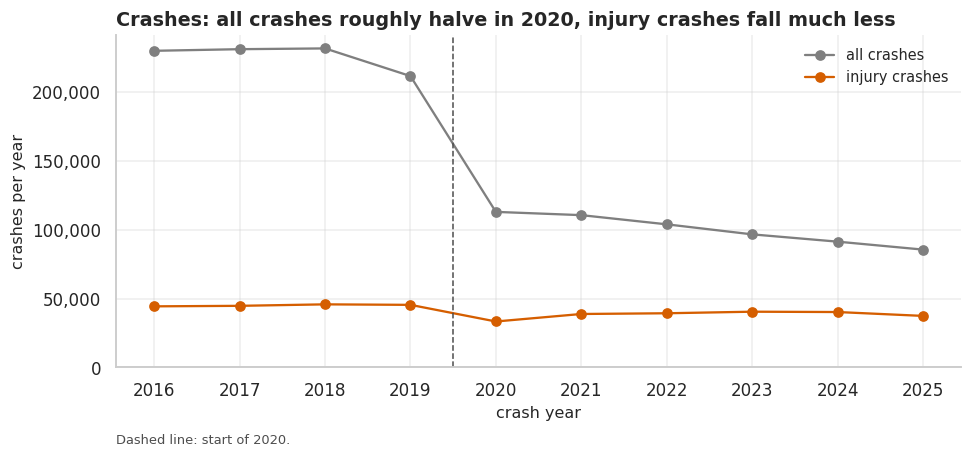

From 2019 to 2020 all crashes change by -46.6% and injury crashes by -26.6%. The part of the fall beyond the injury crashes fits a change in reporting of crashes without injury, which has nothing to do with housing (the pandemic fall in traffic affects both), so **the outcome used throughout is the injury crash**. Counting all crashes would let a city-wide reporting change look like a local effect.

In [16]:
yearly = pd.DataFrame({"all crashes": crash_year.size(), "injury crashes": crash_year["is_injury"].sum()})
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(yearly.index, yearly["all crashes"], marker="o", color=PALETTE["control"], label="all crashes")
ax.plot(yearly.index, yearly["injury crashes"], marker="o", color=PALETTE["crash"], label="injury crashes")
ax.axvline(BREAK_YEAR - 0.5, color=PALETTE["neutral"], linestyle="--", linewidth=1)
ax.set_xticks(yearly.index)
ax.set_ylim(0)
thousands(ax)
ax.legend()
finish(ax, f"Crashes: all crashes roughly halve in {BREAK_YEAR}, injury crashes fall much less",
       "crash year", "crashes per year", note=f"Dashed line: start of {BREAK_YEAR}.")
show(fig)
drop_all = pct(yearly.loc[BREAK_YEAR, "all crashes"], yearly.loc[BREAK_YEAR - 1, "all crashes"]) - 100
drop_injury = pct(yearly.loc[BREAK_YEAR, "injury crashes"], yearly.loc[BREAK_YEAR - 1, "injury crashes"]) - 100
say(f"From {BREAK_YEAR - 1} to {BREAK_YEAR} all crashes change by {drop_all:+.1f}% and injury crashes by "
    f"{drop_injury:+.1f}%. The part of the fall beyond the injury crashes fits a change in reporting of "
    f"crashes without injury, which has nothing to do with housing (the pandemic fall in traffic affects both), so **the outcome used throughout is the injury crash**. Counting all "
    f"crashes would let a city-wide reporting change look like a local effect.")

Crashes by weekday and hour. The 0:00 column is not a rush of midnight crashes: 0:00 is the
value stored when the time is unknown (see the count below).

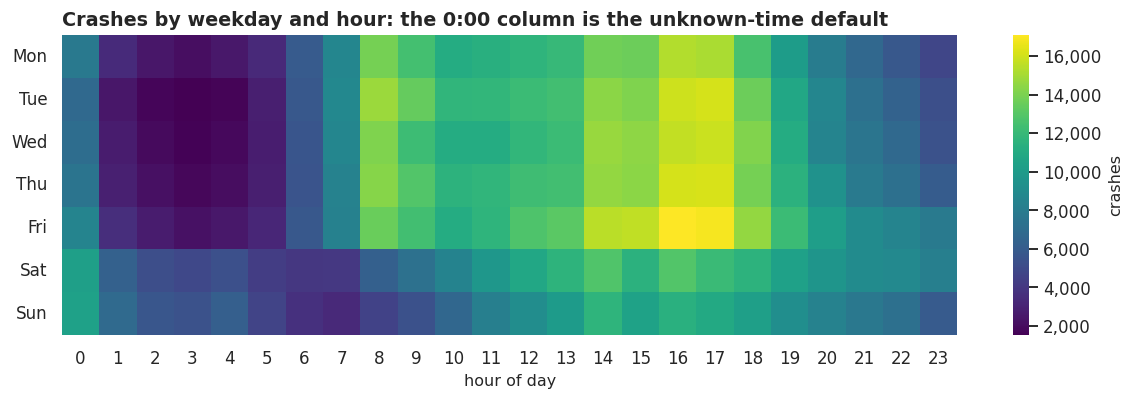

23,717 crashes are stamped 0:00 against 4,547 at 1:00. Section 4 flags them as unknown time and keeps them out of every hour-of-day result.

In [17]:
valid = eda_crashes["hour"].notna()
cells = np.bincount(eda_crashes.loc[valid, "weekday"].astype(int) * 24 + eda_crashes.loc[valid, "hour"].astype(int),
                    minlength=7 * 24).reshape(7, 24)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(pd.DataFrame(cells, index=WEEKDAYS), cmap=SEQUENTIAL_CMAP, ax=ax,
            cbar_kws={"label": "crashes", "format": mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}")})
ax.set_yticklabels(WEEKDAYS, rotation=0)
finish(ax, "Crashes by weekday and hour: the 0:00 column is the unknown-time default", "hour of day", "")
show(fig)
midnight, one_am = (int((raw_crashes["crash_time"] == t).sum()) for t in ("0:00", "1:00"))
say(f"{midnight:,} crashes are stamped 0:00 against {one_am:,} at 1:00. Section 4 flags them as unknown "
    f"time and keeps them out of every hour-of-day result.")

Persons injured per crash, on a log count axis, to see how far the tail reaches. More than
`EXTREME_INJURED` people cannot fit in a few cars, so the tail marks bus-scale events.

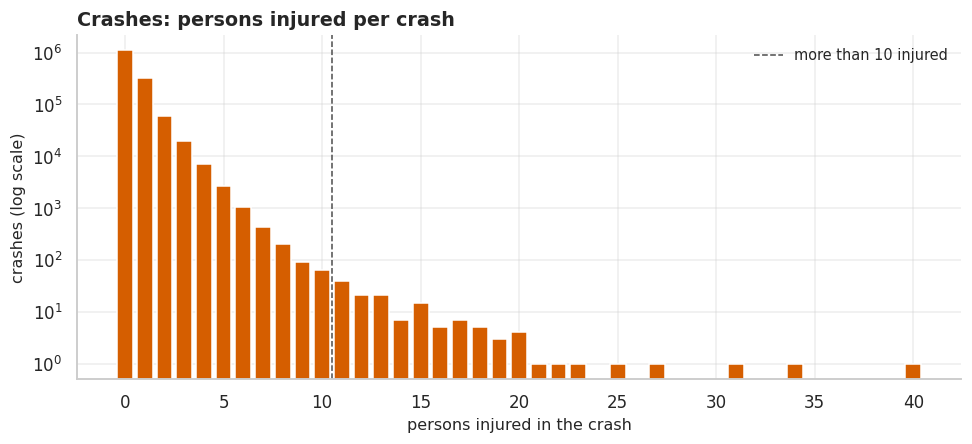

135 crashes injure more than 10 people (maximum 40). They are real events, so Section 4 flags and does not cap them (Section 4.10 counts one more extreme crash, because 4.9 raises some injury totals).

In [18]:
injured_counts = eda_crashes["injured"].dropna().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(injured_counts.index, injured_counts.values, color=PALETTE["crash"], width=0.8)
ax.set_yscale("log")
ax.axvline(EXTREME_INJURED + 0.5, color=PALETTE["neutral"], linestyle="--", linewidth=1,
           label=f"more than {EXTREME_INJURED} injured")
ax.legend()
finish(ax, "Crashes: persons injured per crash", "persons injured in the crash", "crashes (log scale)")
show(fig)
say(f"{int((eda_crashes['injured'] > EXTREME_INJURED).sum())} crashes injure more than {EXTREME_INJURED} people "
    f"(maximum {int(eda_crashes['injured'].max())}). They are real events, so Section 4 flags and does not cap them "
    f"(Section 4.10 counts one more extreme crash, because 4.9 raises some injury totals).")

### 3.5 Category spellings and duplicates

Categorical columns are compared as written and after trimming and case-folding. Differences
between the two counts mean the same category is spelled in several ways and would split a
group-by. The two tables also write the borough differently, which matters for the join.

In [19]:
spellings = pd.concat([
    spelling_report(raw_housing, "housing", ["borough", "reporting_construction_type", "extended_affordability_status"]),
    spelling_report(raw_crashes, "crashes", ["borough", "contributing_factor_vehicle_1", "vehicle_type_code1"])])
show_table(spellings)
zip_text = raw_crashes["zip_code"].dropna()
not_five_digits = int((~zip_text.str.fullmatch(r"\d{5}")).sum())
say(f"Borough is written in title case in housing (e.g. `{raw_housing['borough'].dropna().iloc[0]}`) and in upper case "
    f"in crashes (e.g. `{raw_crashes['borough'].dropna().iloc[0]}`). Crash ZIP codes: "
    f"{n_pct((zip_text == ZIP_PLACEHOLDER).sum(), len(raw_crashes), digits=2)} are the placeholder `{ZIP_PLACEHOLDER}` and "
    f"{not_five_digits:,} are not five digits.")

duplicates = pd.DataFrame({
    "rows": [len(raw_housing), len(raw_crashes)],
    "full-row duplicates": [int(raw_housing.duplicated().sum()), int(raw_crashes.duplicated().sum())],
    "repeated key": [repeat_ids, int(raw_crashes["collision_id"].duplicated().sum())]},
    index=["housing (key: building_id)", "crashes (key: collision_id)"])
show_table(duplicates)

distinct as written  after trim + case-fold  padded with spaces  digit-only labels
table   column                                                                                                           
housing borough                                          5                       5                   0                  0
        reporting_construction_type                      2                       2                   0                  0
        extended_affordability_status                    2                       2                   0                  0
crashes borough                                          5                       5                   0                  0
        contributing_factor_vehicle_1                   61                      59                   0                111
        vehicle_type_code1                            1852                    1289                 792                 21

Borough is written in title case in housing (e.g. `Manhattan`) and in upper case in crashes (e.g. `MANHATTAN`). Crash ZIP codes: 637 (0.04%) are the placeholder `10000` and 0 are not five digits.

,rows,full-row duplicates,repeated key
housing (key: building_id),9551,0,124
crashes (key: collision_id),1504722,0,0


### 3.6 Issues found and how Section 4 handles them

In [20]:
issues = pd.DataFrame([
    ("Housing: confidential rows with no address, ZIP or coordinates",
     n_pct(hidden.sum(), len(hidden)), "Flagged and kept for borough totals; excluded from ZIP and distance joins."),
    ("Housing: unit columns blank where the value is zero",
     n_pct(housing_blank.to_numpy().sum(), housing_blank.size), "Blank filled with 0; identity checks confirm the sums."),
    ("Housing: repeated building_id", f"{repeat_ids:,} rows", "Duplicate rows dropped so units are not double counted."),
    ("Housing: heavy right tail in building size", n_pct((sizes > fence).sum(), len(sizes)),
     "Flagged above the IQR fence, not removed."),
    ("Housing: completion on the start day",
     n_pct(same_day, len(eda_housing)), "Flagged: no observable construction period."),
    ("Crashes: ZIP code missing (and a few placeholder codes)", n_pct(eda_crashes["zip_missing"].sum(), len(eda_crashes)),
     "Set to missing, recovered from coordinates after the join (Section 6)."),
    ("Crashes: coordinates missing, at (0, 0) or outside the city box", n_pct(eda_crashes["coord_unusable"].sum(), len(eda_crashes)),
     "Set to missing and flagged; used for borough and ZIP totals only."),
    (f"Crashes: reporting break in {BREAK_YEAR}", f"{drop_all:+.1f}% all vs {drop_injury:+.1f}% injury",
     "Outcome restricted to injury crashes."),
    ("Crashes: 0:00 is the unknown-time default", f"{midnight:,} at 0:00 vs {one_am:,} at 1:00",
     "Flagged and excluded from hour-of-day work."),
    ("Crashes: injured total differs from sum of parts", f"{eda_crashes['parts_differ'].sum():,} crashes",
     "Total raised to the sum when smaller; surplus stored separately and flagged."),
    ("Crashes: very large injury counts", f"{int((eda_crashes['injured'] > EXTREME_INJURED).sum())} crashes",
     "Flagged, not capped."),
    ("Categories: borough case differs; factor labels vary", f"{len(spellings)} columns compared",
     "One spelling per category; labels standardised."),
], columns=["issue", "size", "handling in Section 4"]).set_index("issue")
show_table(issues, rows=15)

,size,handling in Section 4
issue,,
"Housing: confidential rows with no address, ZIP or coordinates","1,949 (20.4%)",Flagged and kept for borough totals; excluded from ZIP a...
Housing: unit columns blank where the value is zero,"106,309 (61.8%)",Blank filled with 0; identity checks confirm the sums.
Housing: repeated building_id,124 rows,Duplicate rows dropped so units are not double counted.
Housing: heavy right tail in building size,"1,171 (12.3%)","Flagged above the IQR fence, not removed."
Housing: completion on the start day,"2,824 (29.6%)",Flagged: no observable construction period.
Crashes: ZIP code missing (and a few placeholder codes),"508,284 (33.8%)","Set to missing, recovered from coordinates after the joi..."
"Crashes: coordinates missing, at (0, 0) or outside the city box","132,500 (8.8%)",Set to missing and flagged; used for borough and ZIP tot...
Crashes: reporting break in 2020,-46.6% all vs -26.6% injury,Outcome restricted to injury crashes.
Crashes: 0:00 is the unknown-time default,"23,717 at 0:00 vs 4,547 at 1:00",Flagged and excluded from hour-of-day work.


In [21]:
# Release the temporary views: nothing later in the notebook uses them.
release("eda_housing", "eda_crashes", "numeric", "crash_year", "cells", "valid",
        "housing_blank", "filled", "located", "hidden", "units", "in_city", "by_year")

## 4. Pre-integration cleaning

### 4.0 Policy, and how each decision is recorded

The raw text tables become two typed frames, `housing` and `crashes`, through four actions:

* **Drop** a row only when unusable: no key, a repeat, or outside the window. Missing fields alone
  never drop a row (a crash without a ZIP still counts toward its borough).
* **Impute** only what follows from the same row: blank unit counts that mean zero, a missing
  casualty total equal to its parts. No statistical imputation; missing coordinates and dates stay missing.
* **Flag** what is unusual but plausible, or wrong but unrepairable: the row stays, a boolean marks it.
* **Standardise** when only the form changes: text to dates, case, categories, placeholders to missing.

Every rule goes to `CLEANING_LOG` with rows before and after and the rows (or cells) touched; rules
that find nothing are logged too, so the log also shows what was checked (4.13).

| Task | Housing | Crashes |
|---|---|---|
| Missing values (drop against impute) | 4.1, 4.3, 4.4 | 4.8, 4.9 |
| Outliers (IQR and domain rules) | 4.6 | 4.8 (coordinates), 4.10 |
| Inconsistent data | 4.4, 4.5 | 4.8, 4.9 |
| Format standardisation | 4.1, 4.3, 4.4 | 4.7, 4.8, 4.11 |
| Duplicates | 4.2 | 4.7, 4.8 |

In [22]:
# --- Constants for Section 4 (those shared with Section 3 are in 2.1) ----------------------------
# USPS ZIP ranges per borough (inclusive). 11001 and 11040 straddle the Queens / Nassau line and are
# listed under Queens; 11500-11599 is Nassau County, so Queens is split around it.
NYC_ZIP_RANGES = {
    "Manhattan": [(10001, 10282)], "Staten Island": [(10301, 10314)], "Bronx": [(10451, 10475)],
    "Queens": [(11001, 11001), (11004, 11005), (11040, 11040), (11101, 11120), (11351, 11499), (11690, 11697)],
    "Brooklyn": [(11201, 11256)]}
DEEP_AFFORDABLE_COLUMNS = ["extremely_low_income_units", "very_low_income_units"]
HOUSING_DATE_COLUMNS = ["project_start_date", "project_completion_date", "building_completion_date"]

SIZE_BAND_EDGES = [0, 4, 19, 49, 149, np.inf]                   # total units, upper edge inclusive
SIZE_BAND_LABELS = ["1-4", "5-19", "20-49", "50-149", "150+"]   # from row houses to towers

# Crash casualty columns: raw name -> short name used from here on.
CASUALTY_COLUMNS = {
    "number_of_persons_injured": "injured", "number_of_persons_killed": "killed",
    "number_of_pedestrians_injured": "ped_injured", "number_of_pedestrians_killed": "ped_killed",
    "number_of_cyclist_injured": "cyc_injured", "number_of_cyclist_killed": "cyc_killed",
    "number_of_motorist_injured": "mot_injured", "number_of_motorist_killed": "mot_killed",
}
ROAD_USER_PREFIXES = ["ped", "cyc", "mot"]

# Time-of-day bands as (first hour, last hour), inclusive, 24-hour clock.
HOUR_BANDS = {"Night": (0, 5), "Morning": (6, 11), "Afternoon": (12, 17), "Evening": (18, 23)}

# Contributing-factor groups. Each raw label is trimmed and lower-cased, then takes the group of
# the FIRST pattern it matches, so the order matters (explained line by line).
FACTOR_RULES = [
    # the "no factor recorded" label and bare numeric codes ("80", "1") carry no information
    ("Unspecified", r"^unspecified$|^\d+$"),
    # the one factor that blames a person outside a vehicle; kept apart for RQ6
    ("Pedestrian or cyclist error", r"pedestrian|bicyclist"),
    # before "Vehicle defect" ("defective" pavement), "Improper manoeuvre" ("lane marking") and
    # "Failure to yield or obey" ("traffic control device")
    ("Road or environment", r"pavement|shoulders|lane marking|traffic control device|obstruct|debris"
                            r"|glare|animals"),
    # named parts, so "tire failure" is not caught by "failure to yield" below
    ("Vehicle defect", r"defective|defects|steering|tire|windshield|tinted"),
    # "illnes" absorbs the misspelling "Illnes"; "drugs" absorbs both "(illegal)" spellings
    ("Impairment or medical", r"alcohol|drugs|medication|asleep|fatigued|drowsy|consciousness"
                              r"|illnes|disability"),
    # "cell phone" absorbs "(hand-held)", "(hand-Held)" and "(hands-free)"
    ("Distraction", r"distraction|inattention|cell phone|electronic|texting|headphones|eating"
                    r"|navigation"),
    ("Speed or aggressive driving", r"speed|aggressive|following too closely"),
    ("Failure to yield or obey", r"yield|disregarded|keep right"),
    # after "Road or environment", so "lane" here means lane use, not lane markings
    ("Improper manoeuvre", r"passing|lane|turning|backing|inexperience"),
    ("Other", r"other vehicular|uninvolved|vandalism|driverless|oversized"),
]
FACTOR_GROUPS = [group for group, _ in FACTOR_RULES]
FACTOR_FALLBACK = "Other"   # group for a label no pattern recognises
MAP_SAMPLE_ROWS = 60_000    # crashes drawn in the coordinate figure; enough to show the street grid


def note(dataset, frame, rule, action, affected, reason):
    """Log a rule that keeps every row of `frame`."""
    log_rule(dataset, rule, action, len(frame), len(frame), affected, reason)


def standardise_zip(zip_text):
    """(zip, implied borough): a 5-digit NYC ZIP or missing (blank, 10000 and non-NYC fail the range test)."""
    text = zip_text.str.strip().str.replace(r"\.0$", "", regex=True)
    number = pd.to_numeric(text.where(text.str.fullmatch(r"\d{5}").fillna(False).astype(bool)),
                           errors="coerce").astype("float64")
    implied = pd.Series(np.nan, index=zip_text.index, dtype=object)
    for borough_name, ranges in NYC_ZIP_RANGES.items():
        for low, high in ranges:
            implied[number.between(low, high)] = borough_name
    return text.where(implied.notna()).astype("string[pyarrow]"), implied


def validate_coordinates(lat, lon):
    """(lat, lon, n_zero, n_outside): kept inside NYC_BOUNDS; (0, 0), a failed geocode, is counted apart."""
    is_zero = (lat == 0) & (lon == 0)
    in_box = lat.between(*NYC_BOUNDS["lat"]) & lon.between(*NYC_BOUNDS["lon"])
    is_outside = lat.notna() & lon.notna() & ~in_box & ~is_zero
    keep = in_box & ~is_zero
    return lat.where(keep), lon.where(keep), int(is_zero.sum()), int(is_outside.sum())

### 4.1 Housing: blank unit counts are structural zeros

The unit columns are mostly blank and never zero (Section 3): the publisher writes zero as blank,
so blanks are **imputed as 0**. Dropping those rows would remove almost the whole table; leaving
them missing would make every sum missing. The claim is tested in 4.5: after the fill each
breakdown must add up to `all_counted_units` in every row.

In [23]:
raw_units = raw_housing[UNIT_COLUMNS].apply(to_number)
assert ((raw_units.fillna(0) % 1 == 0) & (raw_units.fillna(0) >= 0)).all().all(), "units must be whole, >= 0"
display(pd.DataFrame({"blank (%)": 100 * raw_units.isna().mean(),
                      "zero before fill (%)": 100 * (raw_units == 0).mean(),
                      "zero after fill (%)": 100 * raw_units.fillna(0).eq(0).mean()}).round(1))

,blank (%),zero before fill (%),zero after fill (%)
extremely_low_income_units,78.200,0.000,78.200
very_low_income_units,64.400,0.000,64.400
low_income_units,42.400,0.000,42.400
moderate_income_units,82.300,0.000,82.300
middle_income_units,71.800,0.000,71.800
other_income_units,85.800,0.000,85.800
studio_units,66.500,0.000,66.500
_1_br_units,36.000,0.000,36.000
_2_br_units,36.700,0.000,36.700
_3_br_units,64.100,0.000,64.100


Blank and zero swap places column by column: a pure relabelling.

### 4.2 Housing: duplicates on the true key

A building can appear in several projects (construction, later preservation): separate investments
with their own dates and units. The key is therefore (`project_id`, `building_id`); rows repeating
it, or identical in every column, are dropped. Withheld rows have no `building_id` (pandas would
match two of them), so only rows with one are compared on the key.

In [24]:
project_id = to_number(raw_housing["project_id"]).astype("int64")
building_id = to_number(raw_housing["building_id"]).astype("Int64")
key = pd.DataFrame({"project_id": project_id, "building_id": building_id})
is_key_repeat = building_id.notna() & key.duplicated()
is_duplicate = (is_key_repeat | raw_housing.duplicated()).to_numpy()
repeated_building = building_id.notna() & building_id.duplicated()
display(pd.Series({
    "identical in every column": int(raw_housing.duplicated().sum()),
    "repeat (project_id, building_id)": int(is_key_repeat.sum()),
    "would go if deduplicated on building_id alone": int(repeated_building.sum()),
}, name="rows").to_frame())

housing_source = raw_housing.loc[~is_duplicate].reset_index(drop=True)
log_rule("housing", "blank unit counts set to 0", "impute", len(raw_housing), len(raw_housing),
         int(raw_units.isna().sum().sum()), "The publisher writes zero as blank; sums need a number. Cells.")
log_rule("housing", "duplicate rows on (project_id, building_id) or on every column", "drop",
         len(raw_housing), len(housing_source), int(is_duplicate.sum()),
         "A repeated key would double count units; building_id alone is not the key.")

housing = pd.DataFrame({
    "housing_id": np.arange(len(housing_source), dtype="int32"),      # surrogate key for later joins
    "project_id": project_id[~is_duplicate].to_numpy(),
    "building_id": building_id[~is_duplicate].reset_index(drop=True),
    "project_name": housing_source["project_name"].str.strip(),
})
units = raw_units.loc[~is_duplicate].reset_index(drop=True).fillna(0).astype("int16")

,rows
identical in every column,0
"repeat (project_id, building_id)",0
would go if deduplicated on building_id alone,124


Deduplicating on `building_id` alone would delete the repeat investments above, so it was rejected;
counts of places rather than investments use the sites of Section 5.

### 4.3 Housing: geographic identifiers, and records that cannot be located

Borough becomes a `BOROUGHS` category; the ZIP stays a five-character string (a label) inside a
borough ZIP range; coordinates must fall inside `NYC_BOUNDS`. Withheld (CONFIDENTIAL) records have
no address, ZIP or coordinates and nothing below the borough, so they cannot be imputed (a random
ZIP would invent a link to crashes), and dropping them would lose their units from borough totals:
they are **kept and flagged** (`is_confidential`). `is_located` is the filter of every spatial analysis.

In [25]:
housing["borough"] = pd.Categorical(housing_source["borough"].str.strip().str.title(), categories=BOROUGHS)
housing["zip"], zip_borough = standardise_zip(housing_source["postcode"])
housing["lat"], housing["lon"], housing_zero, housing_outside = validate_coordinates(
    to_number(housing_source["latitude"]), to_number(housing_source["longitude"]))
housing["is_confidential"] = (housing_source["project_name"].str.strip().str.upper()
                              .eq(CONFIDENTIAL_NAME).fillna(False).to_numpy(dtype=bool))
housing["is_located"] = housing["lat"].notna() & housing["lon"].notna()
house_number = housing_source["house_number"].str.strip()
housing["address"] = (house_number + " " + housing_source["street_name"].str.strip()).where(
    house_number != WITHHELD_ADDRESS)
confidential = housing["is_confidential"]
housing_zip_disagree = zip_borough.notna() & (zip_borough != housing["borough"].astype(object))

note("housing", housing, "borough to category with the BOROUGHS spelling", "standardise",
     int(housing["borough"].isna().sum()), "One spelling on both tables; affected = unrecognised values.")
note("housing", housing, "postcode to 5-character string, checked against NYC ZIP ranges", "standardise",
     int(housing_source["postcode"].notna().sum() - housing["zip"].notna().sum()),
     "ZIP is a label and a join key; affected = codes rejected as not NYC.")
note("housing", housing, "coordinates at (0,0) or outside NYC_BOUNDS set to missing", "standardise",
     housing_zero + housing_outside, "A point outside the city would corrupt distance joins.")
note("housing", housing, "confidential records kept and flagged (is_confidential)", "flag",
     int(confidential.sum()), "No address, ZIP or coordinates, so not imputable; valid for borough totals.")
note("housing", housing, "rows without usable coordinates flagged (is_located = False)", "flag",
     int((~housing["is_located"]).sum()), "Spatial analyses need a point; ZIP and borough analyses do not.")
note("housing", housing, "ZIP range borough differs from stated borough (stated borough kept)", "flag",
     int(housing_zip_disagree.sum()), "Checked only; a few ZIPs legitimately cross a borough line.")

display(housing.assign(units=units["total_units"])
        .groupby(["is_confidential", "is_located"])
        .agg(rows=("housing_id", "size"), total_units=("units", "sum"), with_zip=("zip", "count")))
assert housing["borough"].notna().all()
assert not housing.loc[confidential, ["zip", "lat", "lon", "building_id", "address"]].notna().any().any()
say(f"Unrecognised boroughs: {int(housing['borough'].isna().sum())}; rejected ZIPs: "
    f"{int(housing_source['postcode'].notna().sum() - housing['zip'].notna().sum())}; coordinates at (0,0): "
    f"{housing_zero}, outside the city: {housing_outside}. Confidential: {n_pct(confidential.sum(), len(housing))} "
    f"of rows but {pct(units.loc[confidential, 'total_units'].sum(), units['total_units'].sum()):.2f}% of units. "
    f"ZIP range and stated borough disagree in {int(housing_zip_disagree.sum())} rows, in ZIP "
    f"{join_and(sorted(housing.loc[housing_zip_disagree, 'zip'].unique()))}.")

rows  total_units  with_zip
is_confidential is_located                             
False           False          9          797         0
                True        7593       441985      7593
True            False       1949         2806         0

Unrecognised boroughs: 0; rejected ZIPs: 0; coordinates at (0,0): 0, outside the city: 0. Confidential: 1,949 (20.4%) of rows but 0.63% of units. ZIP range and stated borough disagree in 5 rows, in ZIP 10463.

The fields were already clean, so the work is typing and flags. The few named rows without
coordinates lack a ZIP and tax lot too; an outside geocoding service was rejected as a third source
and network dependency. The disagreeing ZIP is Marble Hill (Manhattan with Bronx mail): borough kept.

### 4.4 Housing: dates, completion and date consistency

Dates are parsed with the one exact layout and `errors="raise"`, so an odd value stops the notebook
instead of silently going missing. Completion is the building's date, else the project's (same-row
imputation); with neither the building is unfinished and the date stays missing. A typical
construction time was rejected: the completion year is the event-study treatment date, and an
invented one would put crashes on the wrong side of it. Completion before the start (the financing
close, which can follow the work) is flagged since the wrong date is unknown; so is same-day completion.

In [26]:
housing_dates = pd.DataFrame({column: pd.to_datetime(housing_source[column], format=DATE_FORMAT, errors="raise")
                              for column in HOUSING_DATE_COLUMNS})
assert housing_dates["project_start_date"].notna().all()
housing["project_start_date"] = housing_dates["project_start_date"]
housing["completion_date"] = housing_dates["building_completion_date"].fillna(housing_dates["project_completion_date"])
housing["start_year"] = housing["project_start_date"].dt.year.astype("int16")
housing["completion_year"] = housing["completion_date"].dt.year.astype("Int16")
housing["is_completed"] = housing["completion_date"].notna()
housing["completion_before_start"] = (housing["completion_date"] < housing["project_start_date"]).to_numpy()
housing["same_day_completion"] = (housing["completion_date"] == housing["project_start_date"]).to_numpy()
filled_from_project = int((housing_dates["building_completion_date"].isna() & housing["is_completed"]).sum())
in_window = housing["is_completed"] & housing["completion_year"].between(YEAR_START, YEAR_END).fillna(False)

note("housing", housing, "three date columns parsed from text with one exact layout", "standardise", 0,
     "Dates must be comparable; any unparseable value would stop the notebook.")
note("housing", housing, "completion_date = building date, else project date", "impute", filled_from_project,
     "Deterministic fill from the same row; rows with neither date stay missing.")
note("housing", housing, "no completion date: is_completed = False, date left missing", "flag",
     int((~housing["is_completed"]).sum()), "No treatment date; an invented one would misplace crashes.")
note("housing", housing, "completion before project start flagged (completion_before_start)", "flag",
     int(housing["completion_before_start"].sum()), "Impossible order, but which date is wrong is unknown.")
note("housing", housing, "completion on the start date flagged (same_day_completion)", "flag",
     int(housing["same_day_completion"].sum()), "No observable construction period.")

say(f"The project date fills {filled_from_project} missing building dates; "
    f"{n_pct((~housing['is_completed']).sum(), len(housing))} rows have neither and count as not completed. "
    f"Completion precedes the start in {int(housing['completion_before_start'].sum())} rows and equals it in "
    f"{int(housing['same_day_completion'].sum()):,}. {int(in_window.sum()):,} completions fall in "
    f"{YEAR_START}-{YEAR_END}, {int((in_window & housing['is_located']).sum()):,} of them located.")

The project date fills 13 missing building dates; 1,653 (17.3%) rows have neither and count as not completed. Completion precedes the start in 21 rows and equals it in 2,824. 6,756 completions fall in 2016-2025, 5,399 of them located.

### 4.5 Housing: unit consistency and derived unit measures

Income bands, bedroom counts and tenure must each add up to `all_counted_units`, which cannot exceed
`total_units` (it adds market-rate units). Had a blank meant "unknown" (4.1), sums would fall short.
`deep_affordable_share` (extremely + very low income over counted units) is left **missing** where
nothing is counted: zero would claim "no deep affordability" rather than "no restricted units".

In [27]:
counted = units["all_counted_units"]
unit_checks = pd.Series({
    "income bands sum to counted units": int((units[INCOME_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
    "bedroom counts sum to counted units": int((units[BEDROOM_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
    "rental + homeownership = counted units": int((units[TENURE_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
    "counted units exceed total units": int((counted > units["total_units"]).sum()),
    "total units below 1": int((units["total_units"] < 1).sum()),
}, name="rows violating")
display(unit_checks.to_frame())
note("housing", housing, "unit identities (three breakdowns = counted <= total, total >= 1)", "flag",
     int(unit_checks.sum()), "Must hold if blank means zero; affected = violations.")
assert unit_checks.sum() == 0, "a unit identity is broken: blank may not mean zero"

housing[UNIT_COLUMNS] = units
housing["construction_type"] = pd.Categorical(housing_source["reporting_construction_type"].str.strip().str.title(),
                                              categories=["New Construction", "Preservation"])
housing["deep_affordable_units"] = units[DEEP_AFFORDABLE_COLUMNS].sum(axis=1).astype("int16")
housing["deep_affordable_share"] = (housing["deep_affordable_units"] / counted.where(counted > 0)).astype("float64")
note("housing", housing, "deep_affordable_share left missing where counted units = 0", "flag",
     int((counted == 0).sum()), "A share with a zero denominator is undefined.")
assert housing["construction_type"].notna().all()

,rows violating
income bands sum to counted units,0
bedroom counts sum to counted units,0
rental + homeownership = counted units,0
counted units exceed total units,0
total units below 1,0


No row breaks an identity, which confirms that blank means zero, so no repair rule is needed.

### 4.6 Housing: size outliers

Size drives RQ4. Tukey's rule assumes symmetry but sizes are right-skewed, so it runs on the raw
count and on log10. Decision: **flag and keep**. The largest records are real developments (below),
and removing or capping them deletes the buildings most likely to change a street. `size_band`
gives five ordered bands for analyses sensitive to the tail.

In [28]:
total_units = units["total_units"].astype("float64")
size_fence = tukey_upper_fence(total_units)
log_size_fence = 10 ** tukey_upper_fence(np.log10(total_units))   # fence in log units, back to units
housing["is_size_outlier"] = (total_units > size_fence).to_numpy()
housing["size_band"] = pd.cut(total_units, bins=SIZE_BAND_EDGES, labels=SIZE_BAND_LABELS, ordered=True)
note("housing", housing, "total_units above the Tukey fence flagged (is_size_outlier), not removed", "flag",
     int(housing["is_size_outlier"].sum()), "Large buildings are real and are what RQ4 needs.")

display(housing.nlargest(5, "total_units")[["project_name", "borough", "total_units", "construction_type",
                                             "completion_year"]])
display(housing.groupby("size_band", observed=True)
        .agg(rows=("housing_id", "size"), total_units=("total_units", "sum"), flagged=("is_size_outlier", "sum")))
say(f"The raw-scale fence is {size_fence:.0f} units and flags {n_pct(housing['is_size_outlier'].sum(), len(housing))} "
    f"rows holding {pct(total_units[housing['is_size_outlier']].sum(), total_units.sum()):.0f}% of all units. "
    f"On the log scale the fence is {log_size_fence:,.0f} units and flags {int((total_units > log_size_fence).sum())} "
    f"rows; the largest building has {int(total_units.max()):,} units.")

,project_name,borough,total_units,construction_type,completion_year
226,25 WATER STREET,Manhattan,1320,New Construction,2026
4865,605 WEST 42ND ST,Manhattan,1175,New Construction,2016
4866,605 WEST 42ND STREET PHASE II,Manhattan,1175,New Construction,2017
5196,5 POINTZ LIC,Queens,1122,New Construction,2023
6729,12 ROCKWELL PLACE,Brooklyn,1046,New Construction,<NA>


,rows,total_units,flagged
size_band,,,
1-4,2821,4551,0
5-19,2806,29723,0
20-49,1682,52942,0
50-149,1427,123171,356
150+,815,235201,815


The raw-scale fence is 108 units and flags 1,171 (12.3%) rows holding 63% of all units. On the log scale the fence is 2,614 units and flags 0 rows; the largest building has 1,320 units.

A rule that flags this large a share is measuring skew, not finding errors: on the log scale,
where its assumption holds better, nothing is extreme. The flag therefore reads "large building".

### 4.7 Crashes: key, duplicates, dates and time of day

Crash rows are dropped only for no `collision_id`, a repeated one, or a date that fails to parse or
lies outside the window; the tests run although the download filtered on date, so a changed
download cannot slip through. A unique key rules out full-row duplicates (double filings: 4.8).
The hour becomes a small integer in four six-hour bands (RQ8). 0:00 is also written when the time
is unknown, so crashes at exactly 0:00 are flagged `time_unknown` and left out of hour-of-day work.

In [29]:
crash_rows_raw, crash_raw_names, crash_memory_raw = len(raw_crashes), list(raw_crashes.columns), memory_mb(raw_crashes)
crash_columns_raw = len(crash_raw_names)

collision_id = pd.to_numeric(raw_crashes["collision_id"], errors="coerce").astype("float64")
has_id = collision_id.notna()
is_repeat = has_id & collision_id.duplicated()
crash_date = pd.to_datetime(raw_crashes["crash_date"], format=DATE_FORMAT, errors="coerce")
keep = has_id & ~is_repeat & crash_date.dt.year.between(YEAR_START, YEAR_END)
log_rule("crashes", "missing or non-numeric collision_id", "drop", crash_rows_raw, int(has_id.sum()),
         int((~has_id).sum()), "A crash without a key cannot be counted once and only once.")
log_rule("crashes", "duplicate collision_id (first kept)", "drop", int(has_id.sum()), int((has_id & ~is_repeat).sum()),
         int(is_repeat.sum()), "One row per collision; a repeat would double count its casualties.")
log_rule("crashes", f"crash_date unparseable or outside {YEAR_START}-{YEAR_END}", "drop",
         int((has_id & ~is_repeat).sum()), int(keep.sum()), int((has_id & ~is_repeat & ~keep).sum()),
         "Only full calendar years are comparable.")
# Usually nothing is dropped; then the raw frame is used as it is instead of copying 1.5 million rows.
crash_source = raw_crashes if keep.all() else raw_crashes.loc[keep].reset_index(drop=True)
crash_date = crash_date[keep].reset_index(drop=True)

crashes = pd.DataFrame({
    "collision_id": collision_id[keep].astype("int64").to_numpy(),
    "crash_date": crash_date.to_numpy(),
    "year": crash_date.dt.year.astype("int16").to_numpy(),
    "month": crash_date.dt.month.astype("int8").to_numpy(),
})
release("collision_id", "has_id", "is_repeat", "keep")
crash_hour, crash_minute = parse_hour(crash_source["crash_time"])
crashes["hour"] = crash_hour        # same 0..n index as crashes; keeps the nullable Int8 dtype
band = pd.Series(np.nan, index=crashes.index, dtype=object)
for band_name, (first_hour, last_hour) in HOUR_BANDS.items():
    band[crashes["hour"].between(first_hour, last_hour).fillna(False).to_numpy(dtype=bool)] = band_name
crashes["hour_band"] = pd.Categorical(band, categories=list(HOUR_BANDS), ordered=True)
crashes["time_unknown"] = ((crash_hour == 0) & (crash_minute == 0)).fillna(False).to_numpy(dtype=bool)

note("crashes", crashes, "crash_date parsed to datetime; year and month derived", "standardise", 0,
     "Text dates cannot be grouped by year.")
note("crashes", crashes, "crash_time to hour (Int8) and four named hour bands; invalid time left missing",
     "standardise", int(crashes["hour"].isna().sum()), "Time of day is analysed in bands; affected = invalid times.")
note("crashes", crashes, "crash time exactly 0:00 flagged as unknown time", "flag", int(crashes["time_unknown"].sum()),
     "0:00 is the default for a missing time; excluded from hour-of-day work")
assert crashes["collision_id"].is_unique

at_one = int(((crash_hour == 1) & (crash_minute == 0)).sum())
say(f"Rows in {crash_rows_raw:,}, out {len(crashes):,}: the key is complete and unique and every date lies "
    f"between {crashes['crash_date'].min():%Y-%m-%d} and {crashes['crash_date'].max():%Y-%m-%d}. Invalid times: "
    f"{int(crashes['hour'].isna().sum())}. Exactly 0:00 is recorded {int(crashes['time_unknown'].sum()):,} times "
    f"against {at_one:,} at 1:00, so it is flagged. Minutes are rounded by the recorder: "
    f"{pct((crash_minute == 0).sum(), len(crashes)):.1f}% fall on the hour (1.7% if even), so time is "
    f"analysed by band or hour, never by minute.")
release("crash_hour", "crash_minute", "band")

Rows in 1,504,722, out 1,504,722: the key is complete and unique and every date lies between 2016-01-01 and 2025-12-31. Invalid times: 0. Exactly 0:00 is recorded 23,717 times against 4,547 at 1:00, so it is flagged. Minutes are rounded by the recorder: 19.6% fall on the hour (1.7% if even), so time is analysed by band or hour, never by minute.

### 4.8 Crashes: borough, ZIP code, coordinates and possible double filings

Borough (upper case here, title case in housing) becomes the same category. The housing ZIP
validator sets blanks, the 10000 placeholder (a fake neighbourhood) and non-NYC codes to missing; the
row stays. Coordinates at (0, 0) or outside `NYC_BOUNDS` become missing, not clipped (clipping piles
crashes onto boundary streets). Missing ZIPs are **not filled here**: Section 6 recovers them from
coordinates, where accuracy can be tested on held-out rows.

In [30]:
raw_lat, raw_lon = to_number(crash_source["latitude"]), to_number(crash_source["longitude"])
raw_lat_range, raw_lon_range = (raw_lat.min(), raw_lat.max()), (raw_lon.min(), raw_lon.max())
coordinates_missing = int(raw_lat.isna().sum())
crash_lat, crash_lon, crash_zero, crash_outside = validate_coordinates(raw_lat, raw_lon)
crashes["lat"], crashes["lon"] = crash_lat.to_numpy(), crash_lon.to_numpy()
crashes["is_located"] = crashes["lat"].notna().to_numpy()
release("raw_lat", "raw_lon", "crash_lat", "crash_lon")

crashes["borough"] = pd.Categorical(crash_source["borough"].str.strip().str.title(), categories=BOROUGHS)
zip_text = crash_source["zip_code"].str.strip()
clean_zip, crash_zip_borough = standardise_zip(crash_source["zip_code"])
crashes["zip"] = clean_zip          # a Series, so the Arrow string dtype matches housing
zip_rejected = int((zip_text.notna() & clean_zip.isna()).sum())
zip_placeholder = int((zip_text == ZIP_PLACEHOLDER).sum())
crash_zip_disagree = (crash_zip_borough.notna() & crashes["borough"].notna()
                      & (crash_zip_borough != crashes["borough"].astype(object))).to_numpy()
release("zip_text", "clean_zip", "crash_zip_borough")

note("crashes", crashes, "borough to title case, category with the BOROUGHS spelling", "standardise",
     int(crash_source["borough"].notna().sum()), "Upper case here, title case in housing; one spelling needed.")
note("crashes", crashes, "zip_code blank, placeholder 10000 or outside NYC ranges set to missing", "standardise",
     zip_rejected, "Junk codes would form fake neighbourhoods in the ZIP panel; the crash row is kept.")
note("crashes", crashes, "coordinates at (0,0) set to missing", "standardise", crash_zero,
     "A failed geocode leaves this placeholder; it marks no place.")
note("crashes", crashes, "coordinates outside NYC_BOUNDS set to missing", "standardise", crash_outside,
     "Domain rule: a crash in this table cannot lie outside the city; clipping would misplace it.")
note("crashes", crashes, "rows without usable coordinates flagged (is_located = False)", "flag",
     int((~crashes["is_located"]).sum()), "Kept for borough and ZIP totals; excluded from distance analyses.")
note("crashes", crashes, "missing zip left missing at this stage", "flag", int(crashes["zip"].isna().sum()),
     "Recovered from coordinates after integration (Section 6), where accuracy can be tested.")
note("crashes", crashes, "ZIP range borough differs from stated borough (stated borough kept)", "flag",
     int(crash_zip_disagree.sum()), "Checked only; ZIPs on the Brooklyn / Queens line cross the boundary.")

border_zip_boroughs = crashes.loc[crashes["zip"].isin(["11001", "11040"]), "borough"].value_counts()
say(f"ZIP: {zip_rejected:,} codes rejected ({zip_placeholder} of them the 10000 placeholder); "
    f"{n_pct(crashes['zip'].isna().sum(), len(crashes))} rows now have no ZIP and {crashes['zip'].nunique()} "
    f"distinct ZIPs remain. Borough is missing in {n_pct(crashes['borough'].isna().sum(), len(crashes))} rows, "
    f"nearly always together with the ZIP ({int((crashes['borough'].notna() & crashes['zip'].isna()).sum()):,} "
    f"rows have a borough but no ZIP). ZIP range and stated borough disagree in {int(crash_zip_disagree.sum())} "
    f"rows, mostly in {join_and(crashes.loc[crash_zip_disagree, 'zip'].value_counts().index[:3])}. The two ZIPs "
    f"shared with Nassau County carry {int(border_zip_boroughs.sum())} crashes, "
    f"{int(border_zip_boroughs.get('Queens', 0))} of them recorded in Queens.")

ZIP: 638 codes rejected (637 of them the 10000 placeholder); 508,922 (33.8%) rows now have no ZIP and 231 distinct ZIPs remain. Borough is missing in 508,028 (33.8%) rows, nearly always together with the ZIP (894 rows have a borough but no ZIP). ZIP range and stated borough disagree in 322 rows, mostly in 11237, 11208 and 11385. The two ZIPs shared with Nassau County carry 817 crashes, 817 of them recorded in Queens.

Borough and ZIP go missing together (highways and bridges have no postal address); disagreements sit
on the Brooklyn-Queens line, so the stated borough is kept. The figure validates the coordinate rule:
every raw pair's outcome (left) and a sample of cleaned points by borough (right; rings: no borough).

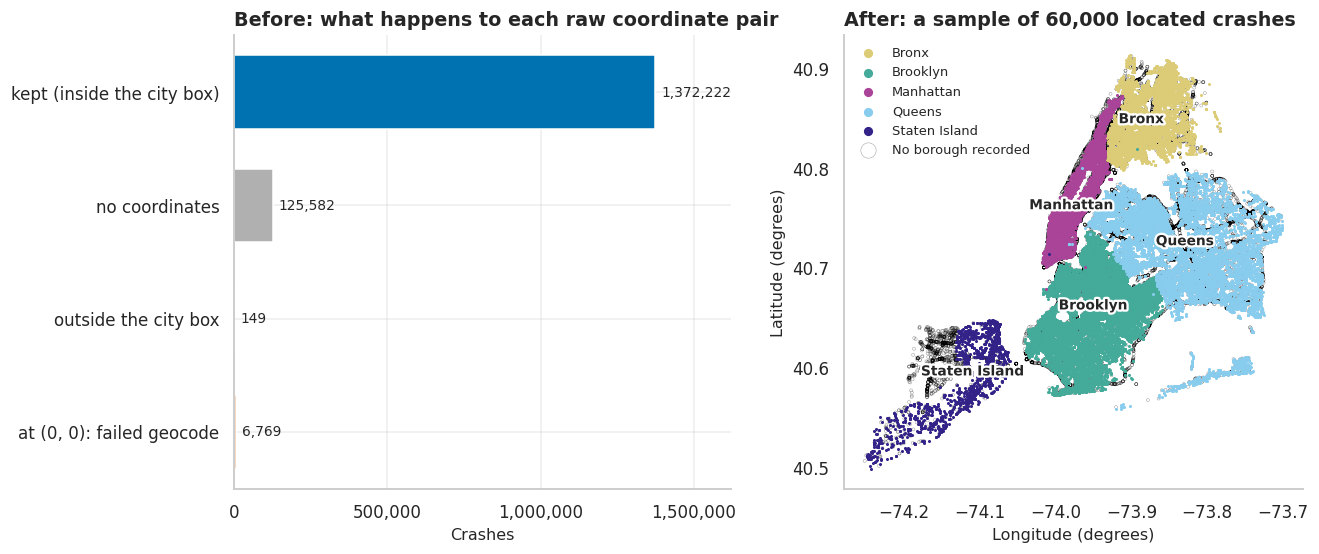

Raw longitudes ran from -201.4 to 0.0 and latitudes from 0.0 to 43.3; after cleaning they run from -74.255 to -73.663 and 40.499 to 40.913.

In [31]:
coordinate_outcomes = pd.Series({
    "kept (inside the city box)": int(crashes["is_located"].sum()),
    "no coordinates": coordinates_missing,
    "outside the city box": crash_outside,
    "at (0, 0): failed geocode": crash_zero,
})
assert coordinate_outcomes.sum() == len(crashes), "every raw coordinate pair has exactly one outcome"
map_sample = crashes.loc[crashes["is_located"], ["lat", "lon", "borough"]].sample(MAP_SAMPLE_ROWS, random_state=SEED)

fig, (ax_outcome, ax_map) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
bars = ax_outcome.barh(coordinate_outcomes.index[::-1], coordinate_outcomes.to_numpy()[::-1], height=0.65,
                       color=[PALETTE["crash"], PALETTE["accent"], PALETTE["before"], PALETTE["housing"]])
ax_outcome.bar_label(bars, labels=[f"{v:,}" for v in coordinate_outcomes.to_numpy()[::-1]], padding=4, fontsize=9)
ax_outcome.set_xlim(0, coordinate_outcomes.max() * 1.18)
ax_outcome.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=4))
thousands(ax_outcome, axis="x")
finish(ax_outcome, "Before: what happens to each raw coordinate pair", "Crashes", "")
for borough_name in BOROUGHS:
    points = map_sample[map_sample["borough"] == borough_name]
    ax_map.scatter(points["lon"], points["lat"], s=1, color=BOROUGH_COLORS[borough_name], rasterized=True,
                   label=borough_name, zorder=2)
    ax_map.text(points["lon"].median(), points["lat"].median(), borough_name, ha="center", fontsize=9,
                fontweight="bold", zorder=5, path_effects=[patheffects.withStroke(linewidth=3, foreground="white")])
no_borough = map_sample[map_sample["borough"].isna()]
ax_map.scatter(no_borough["lon"], no_borough["lat"], s=4, facecolors="none", edgecolors="black",
               linewidths=0.25, alpha=0.5, rasterized=True, label="No borough recorded", zorder=1)
map_axes(ax_map)
ax_map.legend(loc="upper left", fontsize=8.5, markerscale=5)
finish(ax_map, f"After: a sample of {MAP_SAMPLE_ROWS:,} located crashes", "Longitude (degrees)", "Latitude (degrees)")
show(fig)
say(f"Raw longitudes ran from {raw_lon_range[0]:.1f} to {raw_lon_range[1]:.1f} and latitudes from "
    f"{raw_lat_range[0]:.1f} to {raw_lat_range[1]:.1f}; after cleaning they run from {crashes['lon'].min():.3f} "
    f"to {crashes['lon'].max():.3f} and {crashes['lat'].min():.3f} to {crashes['lat'].max():.3f}.")

The rejected pairs would stretch any map across half the globe; cleaned, the sample draws the street
grid with each colour in its borough. The second figure shows which location fields each year keeps.

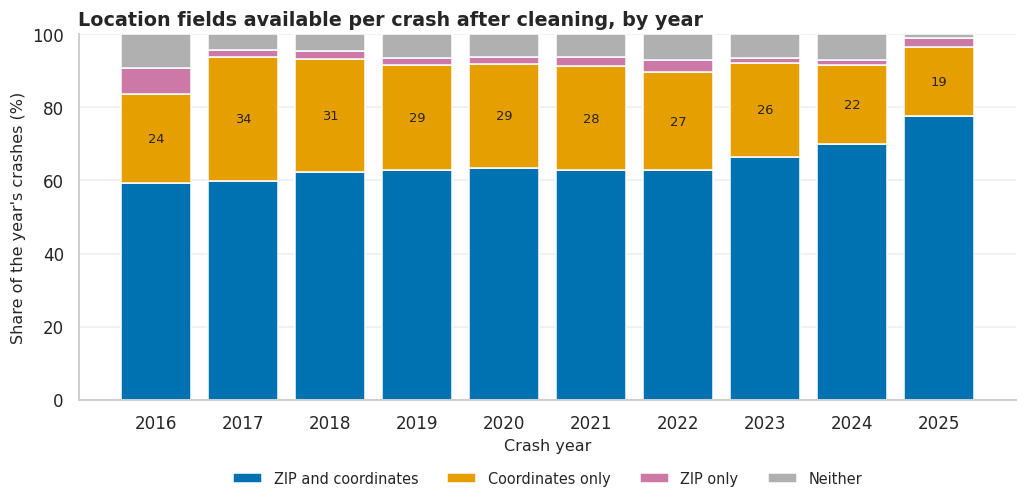

Coordinates without a ZIP: 419,495 (27.9%) crashes, from 19% in 2025 to 34% in 2017. Neither field: 89,427 (5.9%).

In [32]:
LOCATION_STATES = ["ZIP and coordinates", "Coordinates only", "ZIP only", "Neither"]
has_zip = crashes["zip"].notna().to_numpy()
location_state = np.select([has_zip & crashes["is_located"], ~has_zip & crashes["is_located"], has_zip],
                           LOCATION_STATES[:3], default=LOCATION_STATES[3])
location_by_year = (pd.crosstab(crashes["year"], location_state, normalize="index")
                    .reindex(columns=LOCATION_STATES, fill_value=0) * 100)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bottom = np.zeros(len(location_by_year))
state_colors = [PALETTE["housing"], PALETTE["placebo"], PALETTE["accent"], PALETTE["before"]]
for state, color in zip(LOCATION_STATES, state_colors):
    ax.bar(location_by_year.index, location_by_year[state], bottom=bottom, color=color, edgecolor="white",
           width=0.8, label=state)
    bottom += location_by_year[state].to_numpy()
for year, share in location_by_year["Coordinates only"].items():
    ax.text(year, location_by_year.loc[year, "ZIP and coordinates"] + share / 2, f"{share:.0f}", ha="center",
            va="center", fontsize=8.5)
ax.set_xticks(location_by_year.index)
ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
finish(ax, "Location fields available per crash after cleaning, by year", "Crash year",
       "Share of the year's crashes (%)")
show(fig)
coordinates_only = location_by_year["Coordinates only"]
say(f"Coordinates without a ZIP: {n_pct((location_state == 'Coordinates only').sum(), len(crashes))} crashes, from "
    f"{coordinates_only.min():.0f}% in {int(coordinates_only.idxmin())} to {coordinates_only.max():.0f}% in "
    f"{int(coordinates_only.idxmax())}. Neither field: {n_pct((location_state == 'Neither').sum(), len(crashes))}.")

The orange band is why ZIP recovery matters: a ZIP panel from the blue band alone would move with
reporting practice, and dropping these rows would remove a different share each year.

**Possible double filings** agree on date, time, exact coordinates, first vehicle and injured count.
They are counted but **kept**: two real crashes at a busy junction in one minute look identical.
Only located rows are compared; without a point, two crashes match on little more than the clock.

In [33]:
signature = pd.DataFrame({
    "date": crashes["crash_date"], "time": crash_source["crash_time"].array,
    "lat": crashes["lat"], "lon": crashes["lon"], "vehicle": crash_source["vehicle_type_code1"].array,
    "injured": crash_source["number_of_persons_injured"].array,
})[crashes["is_located"]]
possible_duplicates = int(signature.duplicated().sum())
release("signature")
note("crashes", crashes, "same date, time, coordinates, vehicle type and injuries under another id (counted, kept)",
     "flag", possible_duplicates, "Double filing or two real crashes at one junction; they cannot be told apart.")
say(f"{n_pct(possible_duplicates, len(crashes), digits=2)} rows repeat an earlier row's signature under another "
    f"collision_id: too few for the keep-or-drop choice to move any result.")

1,918 (0.13%) rows repeat an earlier row's signature under another collision_id: too few for the keep-or-drop choice to move any result.

### 4.9 Crashes: casualty counts, and totals that do not match their parts

Casualty columns must be whole and non-negative and become small integers. A blank total is
**imputed** as the sum of its parts (its definition). A total **below** its parts is raised to them
(a total cannot hold fewer people than it names). A total **above** is kept: the three roles miss
e.g. e-scooter riders, so lowering it would delete injured people and assigning a role would be a
guess. The surplus goes to `other_injured`, so total = ped + cyc + mot + other in every row.

In [34]:
casualties = pd.DataFrame({short: to_number(crash_source[column]) for column, short in CASUALTY_COLUMNS.items()})
values = casualties.to_numpy()
assert not (values < 0).any() and not (values % 1 > 0).any(), "casualty counts must be whole and >= 0"
casualty_report = {}
for outcome in ["injured", "killed"]:
    part_columns = [f"{prefix}_{outcome}" for prefix in ROAD_USER_PREFIXES]
    assert casualties[part_columns].notna().all().all(), "role counts are expected to be complete"
    parts = casualties[part_columns].sum(axis=1)
    reported = casualties[outcome]
    # Missing total -> sum of parts; below its parts -> raised; above -> kept, surplus stored apart.
    cleaned = np.maximum(reported.fillna(parts), parts)
    # Conservation: people after cleaning = reported + imputed + raised, so no one was removed.
    assert cleaned.sum() == reported.sum() + parts[reported.isna()].sum() + (parts - reported).clip(lower=0).sum()
    casualty_report[outcome] = {"missing": int(reported.isna().sum()), "below": int((reported < parts).sum()),
                                "above": int((reported > parts).sum()),
                                "surplus_people": int((reported - parts).clip(lower=0).sum())}
    casualties[outcome] = cleaned
    casualties[f"other_{outcome}"] = cleaned - parts
assert casualties.max().max() <= np.iinfo(np.int8).max, "a casualty count no longer fits in int8"
for column in [*CASUALTY_COLUMNS.values(), "other_injured"]:
    crashes[column] = casualties[column].astype("int8").to_numpy()
crashes["is_injury_crash"] = ((crashes["injured"].astype("int16") + crashes["killed"]) > 0).to_numpy()
crashes["ped_cyc_harm"] = (crashes[["ped_injured", "ped_killed", "cyc_injured", "cyc_killed"]]
                          .sum(axis=1) > 0).to_numpy()
surplus_rows = (casualties["other_injured"] > 0).to_numpy()
release("casualties", "values")

report = pd.DataFrame(casualty_report).T
note("crashes", crashes, "eight casualty columns to small integers; checked whole and non-negative", "standardise", 0,
     "Counts were text; a negative or fractional value would stop the notebook.")
note("crashes", crashes, "missing persons injured / killed total = sum of pedestrians, cyclists, motorists", "impute",
     int(report["missing"].sum()), "The total is defined as the sum of its parts, so the fill is exact.")
note("crashes", crashes, "persons total below the sum of its parts raised to the sum", "impute",
     int(report["below"].sum()), "A total cannot be smaller than the people it contains.")
note("crashes", crashes, "persons total above the sum of its parts kept; injured surplus stored in "
     "other_injured", "flag", int(report["above"].sum()),
     "The surplus is people outside the three roles (e.g. e-scooter riders); lowering would delete them.")
display(report.rename(columns={"missing": "total missing (imputed)", "below": "total below parts (raised)",
                               "above": "total above parts (kept)", "surplus_people": "people in the surplus"}))

first_vehicle = crash_source["vehicle_type_code1"].str.strip().str.title()
is_micromobility = first_vehicle.isin(["E-Scooter", "E-Bike"]).fillna(False).to_numpy(dtype=bool)
say(f"{pct((crashes['year'].to_numpy()[surplus_rows] > BREAK_YEAR).sum(), surplus_rows.sum()):.0f}% of the "
    f"{surplus_rows.sum():,} surplus rows fall after {BREAK_YEAR}, and an e-scooter or e-bike is the first vehicle "
    f"in {pct((is_micromobility & surplus_rows).sum(), surplus_rows.sum()):.1f}% of them against "
    f"{pct(is_micromobility.sum(), len(crashes)):.2f}% of all crashes. After cleaning: "
    f"{n_pct(crashes['is_injury_crash'].sum(), len(crashes))} injury crashes, "
    f"{int(crashes['ped_cyc_harm'].sum()):,} harming a pedestrian or cyclist, {int(crashes['injured'].sum()):,} "
    f"people injured and {int(crashes['killed'].sum()):,} killed.")

,total missing (imputed),total below parts (raised),total above parts (kept),people in the surplus
injured,18,227,10178,10876
killed,36,6,74,75


96% of the 10,178 surplus rows fall after 2020, and an e-scooter or e-bike is the first vehicle in 29.7% of them against 0.47% of all crashes. After cleaning: 409,967 (27.2%) injury crashes, 142,014 harming a pedestrian or cyclist, 550,991 people injured and 2,617 killed.

The surplus follows the reporting change and is rich in e-scooters and e-bikes: a change in who is
counted, not random error, so it is real people (named `other_`, as cars still dominate). Note that
`ped_cyc_harm` excludes injured e-scooter and e-bike riders.

### 4.10 Crashes: extreme injury counts

Dozens injured could be a typo or a bus crash. Tukey's rule is tried, then a domain rule (more than
`EXTREME_INJURED`). Decision: **flag and keep**; capping would erase real events and break 4.9's identity.

In [35]:
injury_fence = tukey_upper_fence(crashes["injured"])
injury_only_fence = tukey_upper_fence(crashes.loc[crashes["is_injury_crash"], "injured"])
extreme = (crashes["injured"] > EXTREME_INJURED).to_numpy()
note("crashes", crashes, f"more than {EXTREME_INJURED} injured in one crash (counted, not capped)", "flag",
     int(extreme.sum()), "Bus-scale events are real; capping would erase them and break total = sum of parts.")
display(crashes.loc[extreme, ["crash_date", "borough", "injured", "ped_injured", "mot_injured", "killed"]]
        .assign(first_vehicle=first_vehicle[extreme].to_numpy()).nlargest(8, "injured"))
is_bus = first_vehicle.eq("Bus").fillna(False).to_numpy(dtype=bool)
say(f"Tukey's fence is {injury_fence:.1f} injured on all crashes and {injury_only_fence:.1f} on injury crashes, "
    f"flagging {int((crashes['injured'] > injury_fence).sum()):,} and "
    f"{int((crashes['injured'] > injury_only_fence).sum()):,} ordinary multi-injury crashes. The domain rule "
    f"finds {int(extreme.sum())} crashes with {int(crashes.loc[extreme, 'injured'].sum()):,} injured (maximum "
    f"{int(crashes['injured'].max())}); a bus is the first vehicle in {pct((is_bus & extreme).sum(), extreme.sum()):.0f}% "
    f"of them against {pct(is_bus.sum(), len(crashes)):.1f}% of all crashes.")

,crash_date,borough,injured,ped_injured,mot_injured,killed,first_vehicle
1187622,2022-07-21,NaN,40,0,40,0,Bus
1254634,2023-04-07,Queens,34,0,34,0,Bus
660588,2017-10-10,Bronx,31,0,31,0,Bus
309469,2017-05-18,Manhattan,27,27,0,1,Sedan
1326575,2023-12-28,Staten Island,25,0,25,0,Box Truck
1252135,2023-03-17,Queens,23,0,23,0,Station Wagon/Sport Utility Vehicle
511944,2018-04-06,Brooklyn,22,0,21,0,Sedan
1232114,2023-01-02,NaN,21,19,2,0,Station Wagon/Sport Utility Vehicle


Tukey's fence is 2.5 injured on all crashes and 1.0 on injury crashes, flagging 31,065 and 91,152 ordinary multi-injury crashes. The domain rule finds 136 crashes with 1,940 injured (maximum 40); a bus is the first vehicle in 36% of them against 1.7% of all crashes.

Most crashes injure nobody, so the IQR fence flags ordinary multi-injury crashes (skew, not
errors). Buses are over-represented among the largest events (the two shares are printed above), kept as reported; "did a crash injure anyone" ignores them.

### 4.11 Crashes: contributing factors grouped into categories

The first factor is free text with spelling and case variants, numeric codes and rare labels. For
RQ10 the ordered keywords of `FACTOR_RULES` reduce it to ten groups (a keyword also catches a future
variant, unlike a label dictionary). Missing, "Unspecified" and numeric codes share one kept group,
whose size is a finding in itself; an unrecognised label goes to "Other" and is counted.

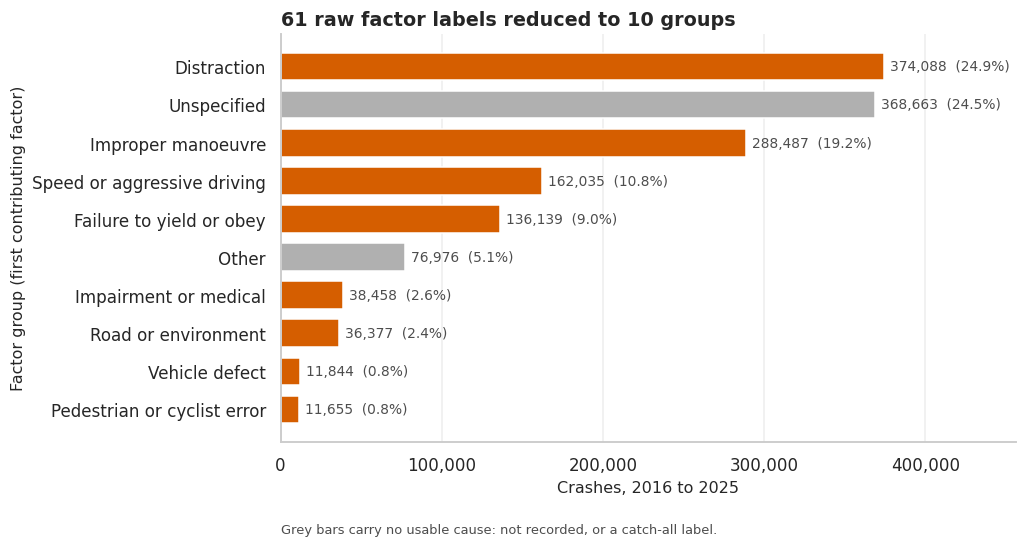

61 labels (59 after trimming and lower-casing) and 6,442 missing values become 10 groups; numeric codes cover 111 rows and 0 labels fell to the fallback. 'Unspecified' holds 24.5% of crashes, a limit RQ10 has to state.

In [36]:
factor_text = crash_source["contributing_factor_vehicle_1"]
label_counts = factor_text.value_counts()
normalised = pd.Series(label_counts.index.astype(str), index=label_counts.index).str.strip().str.lower()
label_group = pd.Series(np.nan, index=label_counts.index, dtype=object)
for group_name, pattern in FACTOR_RULES:          # first match wins: only unclaimed labels are assigned
    label_group[normalised.str.contains(pattern, regex=True) & label_group.isna()] = group_name
unrecognised = int(label_group.isna().sum())
label_group = label_group.fillna(FACTOR_FALLBACK)
# Patterns run on the few dozen distinct labels; the result is mapped back to 1.5 million rows.
label_to_group = dict(zip(label_counts.index.astype(str), label_group))
crashes["factor_group"] = pd.Categorical(factor_text.astype(object).map(label_to_group).fillna("Unspecified"),
                                         categories=FACTOR_GROUPS)
factor_missing = int(factor_text.isna().sum())
numeric_rows = int(label_counts[normalised.str.fullmatch(r"\d+")].sum())
note("crashes", crashes, "contributing_factor_vehicle_1 mapped to ten factor groups by ordered keywords",
     "standardise", len(crashes) - factor_missing, "Dozens of labels with spelling variants are too fragmented.")
note("crashes", crashes, "missing factor and numeric junk codes assigned to 'Unspecified'", "standardise",
     factor_missing + numeric_rows, "No factor was recorded; the crash is kept and the gap stays visible.")
assert set(crashes["factor_group"].unique()) == set(FACTOR_GROUPS), "a factor group is empty"

group_counts = crashes["factor_group"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(group_counts.index.astype(str), group_counts.to_numpy(), height=0.72,
        color=[PALETTE["before"] if g in ("Unspecified", "Other") else PALETTE["crash"] for g in group_counts.index])
for position, count in enumerate(group_counts):
    ax.text(count + group_counts.max() * 0.01, position, f"{count:,}  ({pct(count, len(crashes)):.1f}%)",
            va="center", fontsize=9, color=PALETTE["neutral"])
ax.set_xlim(0, group_counts.max() * 1.22)
thousands(ax, axis="x")
ax.grid(axis="y", visible=False)
finish(ax, f"{len(label_counts)} raw factor labels reduced to {len(FACTOR_GROUPS)} groups",
       f"Crashes, {YEAR_START} to {YEAR_END}", "Factor group (first contributing factor)",
       note="Grey bars carry no usable cause: not recorded, or a catch-all label.")
show(fig)
say(f"{len(label_counts)} labels ({normalised.nunique()} after trimming and lower-casing) and {factor_missing:,} "
    f"missing values become {len(FACTOR_GROUPS)} groups; numeric codes cover {numeric_rows} rows and "
    f"{unrecognised} labels fell to the fallback. 'Unspecified' holds "
    f"{pct(group_counts['Unspecified'], len(crashes)):.1f}% of crashes, a limit RQ10 has to state.")

# The raw crash text is no longer needed (crash_source is the same object when no row was dropped).
release("raw_crashes", "crash_source", "crash_date", "first_vehicle", "is_micromobility", "is_bus", "factor_text",
        "map_sample", "no_borough", "points", "location_state", "has_zip", "surplus_rows", "extreme")

### 4.12 Final shape and invariants

Columns are put in a fixed order. Raw columns no later section reads are not carried forward:
finer housing identifiers with no crash counterpart (tax lot, census tract, council district,
community board), the second coordinate pair, the status fields and the two source completion
dates (merged into `completion_date`); for crashes, street name, second factor and vehicle type,
used above for checks only. Flags that were only counted (possible duplicates, extreme injuries)
live in the log rather than as columns.

In [37]:
HOUSING_COLUMN_ORDER = [
    "housing_id", "project_id", "building_id", "project_name", "address",
    "borough", "zip", "lat", "lon", "is_confidential", "is_located",
    "project_start_date", "completion_date", "start_year", "completion_year", "is_completed",
    "completion_before_start", "same_day_completion", "construction_type", *UNIT_COLUMNS,
    "deep_affordable_units", "deep_affordable_share", "is_size_outlier", "size_band",
]
CRASH_COLUMN_ORDER = [
    "collision_id", "crash_date", "year", "month", "hour", "hour_band", "time_unknown",
    "borough", "zip", "lat", "lon", "is_located",
    "injured", "killed", "ped_injured", "ped_killed", "cyc_injured", "cyc_killed",
    "mot_injured", "mot_killed", "other_injured", "is_injury_crash", "ped_cyc_harm", "factor_group",
]
assert set(HOUSING_COLUMN_ORDER) == set(housing.columns), set(HOUSING_COLUMN_ORDER) ^ set(housing.columns)
assert set(CRASH_COLUMN_ORDER) == set(crashes.columns), set(CRASH_COLUMN_ORDER) ^ set(crashes.columns)
housing, crashes = housing[HOUSING_COLUMN_ORDER], crashes[CRASH_COLUMN_ORDER]
note("housing", housing, "raw columns not carried forward under their raw name (typed, renamed or unused)", "drop",
     len(set(raw_housing.columns) - set(housing.columns)), "Affected counts columns, not rows.")
note("crashes", crashes, "raw text columns not carried forward under their raw name (typed, renamed or unused)",
     "drop", len(set(crash_raw_names) - set(crashes.columns)), "Affected counts columns, not rows.")


def logged_drops(dataset):
    """Rows removed by the logged rules of one dataset."""
    return sum(entry["rows_before"] - entry["rows_after"] for entry in CLEANING_LOG if entry["dataset"] == dataset)


# Row conservation: every row that left was removed by a logged rule; keys stay unique.
assert len(housing) == len(raw_housing) - logged_drops("housing")
assert len(crashes) == crash_rows_raw - logged_drops("crashes")
assert housing["housing_id"].is_unique and crashes["collision_id"].is_unique
assert list(housing["borough"].cat.categories) == BOROUGHS == list(crashes["borough"].cat.categories)
assert housing["zip"].dtype == crashes["zip"].dtype

### 4.13 Cleaning log and before/after summary

Every rule in the order it ran; `affected` counts rows unless the rule says cells or columns.

In [38]:
cleaning_log_table = pd.DataFrame(CLEANING_LOG)
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(cleaning_log_table)
display(cleaning_log_table.assign(rows_dropped=cleaning_log_table["rows_before"] - cleaning_log_table["rows_after"])
        .groupby(["dataset", "action"]).agg(rules=("rule", "size"), rows_dropped=("rows_dropped", "sum")))

before_after = pd.DataFrame({
    "rows before": [len(raw_housing), crash_rows_raw], "rows after": [len(housing), len(crashes)],
    "columns before": [raw_housing.shape[1], crash_columns_raw], "columns after": [housing.shape[1], crashes.shape[1]],
    "memory before (MB)": [memory_mb(raw_housing), crash_memory_raw],
    "memory after (MB)": [memory_mb(housing), memory_mb(crashes)],
    "missing cells after": [int(housing.isna().sum().sum()), int(crashes.isna().sum().sum())],
}, index=["housing", "crashes"]).round(1)
display(before_after)
remaining = pd.concat({"housing": housing.isna().sum(), "crashes": crashes.isna().sum()})
display(remaining[remaining > 0].rename("missing after cleaning").to_frame())
say(f"{len(cleaning_log_table)} rules logged; {logged_drops('housing')} housing and {logged_drops('crashes')} crash "
    f"rows dropped, leaving {len(housing):,} and {len(crashes):,}. The typed crash frame takes "
    f"{before_after.loc['crashes', 'memory after (MB)']:.0f} MB against "
    f"{before_after.loc['crashes', 'memory before (MB)']:.0f} MB as raw text.")

,dataset,rule,action,rows_before,rows_after,affected,reason
0,housing,blank unit counts set to 0,impute,9551,9551,106309,The publisher writes zero as blank; sums need a number. Cells.
1,housing,"duplicate rows on (project_id, building_id) or on every column",drop,9551,9551,0,A repeated key would double count units; building_id alone is not the key.
2,housing,borough to category with the BOROUGHS spelling,standardise,9551,9551,0,One spelling on both tables; affected = unrecognised values.
3,housing,"postcode to 5-character string, checked against NYC ZIP ranges",standardise,9551,9551,0,ZIP is a label and a join key; affected = codes rejected as not NYC.
4,housing,"coordinates at (0,0) or outside NYC_BOUNDS set to missing",standardise,9551,9551,0,A point outside the city would corrupt distance joins.
5,housing,confidential records kept and flagged (is_confidential),flag,9551,9551,1949,"No address, ZIP or coordinates, so not imputable; valid for borough totals."
6,housing,rows without usable coordinates flagged (is_located = False),flag,9551,9551,1958,Spatial analyses need a point; ZIP and borough analyses do not.
7,housing,ZIP range borough differs from stated borough (stated borough kept),flag,9551,9551,5,Checked only; a few ZIPs legitimately cross a borough line.
8,housing,three date columns parsed from text with one exact layout,standardise,9551,9551,0,Dates must be comparable; any unparseable value would stop the notebook.
9,housing,"completion_date = building date, else project date",impute,9551,9551,13,Deterministic fill from the same row; rows with neither date stay missing.


rules  rows_dropped
dataset action                          
crashes drop             4             0
        flag             7             0
        impute           2             0
        standardise      9             0
housing drop             2             0
        flag             9             0
        impute           2             0
        standardise      4             0

,rows before,rows after,columns before,columns after,memory before (MB),memory after (MB),missing cells after
housing,9551,9551,41,41,5.300,1.700,13107
crashes,1504722,1504722,19,24,436.800,97.000,1281950


missing after cleaning
housing building_id                              1949
        address                                  1949
        zip                                      1958
        lat                                      1958
        lon                                      1958
        completion_date                          1653
        completion_year                          1653
        deep_affordable_share                      29
crashes borough                                508028
        zip                                    508922
        lat                                    132500
        lon                                    132500

39 rules logged; 0 housing and 0 crash rows dropped, leaving 9,551 and 1,504,722. The typed crash frame takes 97 MB against 437 MB as raw text.

No row was lost: the keys were sound and every other problem was standardised or flagged. Missing
values remain only where the information never existed. The crash frame shrinks because counts are
one-byte integers and labels categories. Raw crashes were released after 4.11, so re-running
Section 4 needs Section 2.1 first.

## 5. Integration

A housing row is a building in a subsidised project and a crash row is one collision. This
section builds the tables that let a housing variable and a crash variable be read side by
side, at two levels: a ZIP by year panel, where both tables are first reduced to the same grain,
and a spatial level, where a crash is linked to the buildings within `BUFFER_M` metres of it.

### 5.1 The problem: no shared key

`collision_id` identifies a crash and (`project_id`, `building_id`) a housing row. Neither
appears in the other table, so there is nothing to join row to row. What the tables share is
where and when, and each bridge gives a different grain.

| Bridge | Grain | Can answer | Cannot answer |
|---|---|---|---|
| Time (year) | city by year | whether the two series move together | anything about place (ten points) |
| Borough | borough by year | broad contrasts; the only level that includes confidential housing | neighbourhood differences |
| ZIP code | ZIP by year | change within a neighbourhood over time | what happens on the streets next to one building |
| Coordinates | building by year | crashes around a building before and after it is completed | records without coordinates |

Time and borough are too coarse to carry the analysis and serve as controls and reference
totals. The ZIP and the coordinates are the two working bridges.

In [39]:
# --- Constants for Section 5 ------------------------------------------------------------------
N_STUDY_YEARS = len(STUDY_YEARS)
RADIUS_CANDIDATES_M = [100, 150, 250, 400, 500]   # radii compared in 5.3.1; reused in Section 9
CHECK_SITE_SAMPLE = 300                          # buildings in the brute-force check of the tree
CHECK_CRASH_SAMPLE = 20_000                      # crashes in that check
BYTES_PER_GB = 1_000_000_000
CLUSTER_SIZE_EDGES = [0, 1, 5, 20, 100, np.inf]          # buildings per cluster, upper edge inclusive
CLUSTER_SIZE_LABELS = ["1", "2-5", "6-20", "21-100", "101+"]

EVENT_GROUPS = ["treated", "comparison"]
SITE_ATTRIBUTES = ["housing_id", "project_id", "building_id", "project_name", "borough", "zip", "lat", "lon",
                   "start_year", "completion_year", "is_completed", "same_day_completion",
                   "completion_before_start", "construction_type", "total_units", "all_counted_units",
                   "deep_affordable_units", "deep_affordable_share", "size_band", "is_size_outlier"]
SITE_COUNT_COLUMNS = ["crashes", "injury_crashes", "ped_cyc_crashes", "persons_injured"]
HOUSING_PANEL_MEASURES = ["buildings_completed", "units_completed", "affordable_units_completed",
                          "deep_affordable_units", "new_construction_units", "preservation_units"]
CRASH_PANEL_MEASURES = ["crashes", "injury_crashes", "persons_injured", "persons_killed", "ped_cyc_crashes"]

In [40]:
# How much of each table every bridge can reach.
bridge_coverage = pd.DataFrame({
    "housing rows with the key": [int(housing["completion_year"].notna().sum()), int(housing["borough"].notna().sum()),
                                  int(housing["zip"].notna().sum()), int(housing["is_located"].sum())],
    "crash rows with the key": [int(crashes["year"].notna().sum()), int(crashes["borough"].notna().sum()),
                                int(crashes["zip"].notna().sum()), int(crashes["is_located"].sum())],
}, index=["Time (completion / crash year)", "Borough", "ZIP code", "Coordinates"])
bridge_coverage.insert(1, "% of housing", (100 * bridge_coverage["housing rows with the key"] / len(housing)).round(1))
bridge_coverage["% of crashes"] = (100 * bridge_coverage["crash rows with the key"] / len(crashes)).round(1)
display(bridge_coverage)

,housing rows with the key,% of housing,crash rows with the key,% of crashes
Time (completion / crash year),7898,82.700,1504722,100.000
Borough,9551,100.000,996694,66.200
ZIP code,7593,79.500,995800,66.200
Coordinates,7593,79.500,1372222,91.200


The housing rows without a ZIP or coordinates are the confidential records. The crash rows
without a ZIP are the larger gap; most of them still have coordinates, which is why the spatial
level reaches more crashes than the ZIP level before any repair (Section 6.1).

#### 5.1.1 Why the tables are not merged row to row on ZIP

A ZIP is a key in neither table, so a row merge on ZIP pairs every building with every crash of
its ZIP and any sum over the result counts each crash once per building. The size of that merge
follows from the row counts per ZIP without running it.

In [41]:
housing_per_zip = housing["zip"].value_counts()
crashes_per_zip = crashes["zip"].value_counts()
shared_zips = housing_per_zip.index.intersection(crashes_per_zip.index)
injured_per_zip = crashes.groupby("zip", observed=True)["injured"].sum().reindex(shared_zips)
merged_rows_total = int((housing_per_zip[shared_zips] * crashes_per_zip[shared_zips]).sum())
injured_true = int(injured_per_zip.sum())
injured_after_merge = int((housing_per_zip[shared_zips] * injured_per_zip).sum())
say(f"A row merge on ZIP would return {merged_rows_total:,} rows, {merged_rows_total / len(crashes):,.0f} times "
    f"the crash table, and the {injured_true:,} people injured in those ZIPs would sum to "
    f"{injured_after_merge:,}, an overcount by a factor of {injured_after_merge / injured_true:.0f}. The rule "
    f"from here on is to aggregate each table to a common grain first and merge second, one row to one row.")

A row merge on ZIP would return 58,421,026 rows, 39 times the crash table, and the 331,113 people injured in those ZIPs would sum to 22,152,790, an overcount by a factor of 67. The rule from here on is to aggregate each table to a common grain first and merge second, one row to one row.

### 5.2 Level A: a ZIP by year panel

The common grain is one row per ZIP and calendar year: the crash year for crashes, and the
completion year for housing, because a building adds residents and street activity only once
it is finished. Buildings without a completion date and confidential rows (no ZIP) contribute
nothing at this level.

Two unit totals are kept. `units_completed` counts every unit in the building, including
market-rate ones; `affordable_units_completed` counts the units the programme counts as
affordable, and the split by kind (`new_construction_units`, `preservation_units`) uses the
same affordable count so that the parts add up to it. A building can appear in two projects
(for example a new building later preserved again); its units are counted once, at its first
completion, while `buildings_completed` still counts every completed project-building row.

This first panel is deliberately naive: reported ZIPs and an outer merge, to expose what does
not match. Section 6 repairs the gaps and rebuilds the panel with the same functions.

In [42]:
def is_repeat_building(housing_frame):
    """True for completed rows whose building was already completed under an earlier project."""
    completed = housing_frame[housing_frame["is_completed"] & housing_frame["building_id"].notna()]
    ordered = completed.sort_values(["completion_date", "project_id"])
    repeat = ordered["building_id"].duplicated(keep="first")
    return repeat.reindex(housing_frame.index, fill_value=False)


def aggregate_housing_to_zip_year(housing_frame):
    """Completed housing rows with a ZIP, summed to one row per (zip, completion year).

    Unit columns use one row per building (its first completion); `year` keeps the nullable
    dtype of `completion_year`, which Section 6.3 fixes.
    """
    first = ~is_repeat_building(housing_frame)
    completed = housing_frame[housing_frame["is_completed"] & housing_frame["zip"].notna()]
    first = first[completed.index]
    affordable = completed["all_counted_units"].where(first, 0)
    kind = completed["construction_type"]
    measures = pd.DataFrame({
        "zip": completed["zip"], "year": completed["completion_year"],
        "buildings_completed": 1,
        "units_completed": completed["total_units"].where(first, 0),
        "affordable_units_completed": affordable,
        "deep_affordable_units": completed["deep_affordable_units"].where(first, 0),
        "new_construction_units": affordable.where(kind == "New Construction", 0),
        "preservation_units": affordable.where(kind == "Preservation", 0),
    })
    return (measures.groupby(["zip", "year"], as_index=False)[HOUSING_PANEL_MEASURES].sum()
            .astype({column: "int32" for column in HOUSING_PANEL_MEASURES}))


def aggregate_crashes_to_zip_year(crash_frame, zip_column="zip"):
    """Crashes that have a value in `zip_column`, summed to one row per (zip, crash year)."""
    with_zip = crash_frame[crash_frame[zip_column].notna()]
    measures = pd.DataFrame({
        "zip": with_zip[zip_column], "year": with_zip["year"], "crashes": 1,
        "injury_crashes": with_zip["is_injury_crash"].astype("int32"),
        "persons_injured": with_zip["injured"].astype("int32"),
        "persons_killed": with_zip["killed"].astype("int32"),
        "ped_cyc_crashes": with_zip["ped_cyc_harm"].astype("int32"),
    })
    return measures.groupby(["zip", "year"], as_index=False)[CRASH_PANEL_MEASURES].sum()


housing_by_zip_year = aggregate_housing_to_zip_year(housing)
crashes_by_zip_year_reported = aggregate_crashes_to_zip_year(crashes)
housing_in_study_years = housing_by_zip_year[housing_by_zip_year["year"].between(YEAR_START, YEAR_END)]
naive_panel = housing_in_study_years.merge(crashes_by_zip_year_reported, on=["zip", "year"], how="outer",
                                           indicator="match")
# Both aggregates are unique on (zip, year), so the merge is one row to one row.
assert not naive_panel.duplicated(["zip", "year"]).any()
assert len(naive_panel) <= len(housing_in_study_years) + len(crashes_by_zip_year_reported)

repeat_rows = is_repeat_building(housing)
naive_match = naive_panel["match"].value_counts()
housing_zips_without_crashes = sorted(set(housing_by_zip_year["zip"]) - set(crashes_by_zip_year_reported["zip"]))
crashes_without_zip = int(crashes["zip"].isna().sum())
say(f"{repeat_rows.sum()} completed rows repeat a building already completed under an earlier project; their "
    f"{int(housing.loc[repeat_rows, 'total_units'].sum()):,} units are not counted a second time. The naive "
    f"panel has {len(naive_panel):,} rows for {naive_panel['zip'].nunique()} ZIP codes, "
    f"{naive_panel['zip'].nunique() * N_STUDY_YEARS - len(naive_panel):,} short of a balanced panel. "
    f"{naive_match['both']:,} rows matched on both sides, {naive_match['right_only']:,} have crashes and no "
    f"housing row and {naive_match['left_only']} have housing and no crash row, which leaves "
    f"{int(naive_panel[HOUSING_PANEL_MEASURES + CRASH_PANEL_MEASURES].isna().sum().sum()):,} missing cells. "
    f"Housing ZIP codes never used by the crash table: {', '.join(housing_zips_without_crashes) or 'none'}. "
    f"{n_pct(crashes_without_zip, len(crashes))} crashes have no ZIP and reach no row at all.")

78 completed rows repeat a building already completed under an earlier project; their 5,955 units are not counted a second time. The naive panel has 2,112 rows for 232 ZIP codes, 208 short of a balanced panel. 854 rows matched on both sides, 1,256 have crashes and no housing row and 2 have housing and no crash row, which leaves 7,546 missing cells. Housing ZIP codes never used by the crash table: 10303. 508,922 (33.8%) crashes have no ZIP and reach no row at all.

Three different gaps hide behind these numbers. A ZIP-year with crashes and no housing row is
the normal case: nothing was completed there that year, so the missing housing values are
zeros. A housing ZIP with no crash row at all is not a ZIP without crashes; the crash table
simply does not use that code, and a zero there would be false. The crashes without a ZIP are
the largest problem and are invisible in the panel, because a row without a key drops out of a
grouped table without leaving a missing value; their share also changes from year to year
(Section 4.8), which would put a record-keeping trend into the panel. Section 6.1 handles all three.

### 5.3 Level B: spatial proximity

The second level asks which crashes happened within `BUFFER_M` metres of each building. Degrees
are not a unit of length (at New York's latitude a degree of longitude is about three quarters of
a degree of latitude), so distances use the haversine great-circle formula, with latitude
$\varphi$ and longitude $\lambda$ in radians and $R$ = `EARTH_RADIUS_M`:

$$d = 2R \arcsin\sqrt{\sin^2\frac{\varphi_2-\varphi_1}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\lambda_2-\lambda_1}{2}}$$

Treating the Earth as a sphere is wrong by a fraction of a percent, about a metre at this radius,
less than the geocoding error. To avoid comparing every building with every crash, a ball tree
over the crashes (the larger table) is queried once per building; a radius query skips every
group of points that lies entirely outside the radius. The tree works on the unit sphere, so a
radius in metres is divided by $R$ before a query and distances are multiplied by $R$ after it.

In [43]:
def to_radians(lat, lon):
    """Stack latitude and longitude (degrees) into the (n, 2) radian array the haversine tree expects."""
    return np.radians(np.column_stack([np.asarray(lat, dtype="float64"), np.asarray(lon, dtype="float64")]))


def haversine_m(lat_a, lon_a, lat_b, lon_b):
    """Great-circle distance in metres between points given in degrees (arrays broadcast)."""
    phi_a, phi_b = np.radians(lat_a), np.radians(lat_b)
    half_dlambda = np.radians(np.asarray(lon_b) - np.asarray(lon_a)) / 2
    inside = np.sin((phi_b - phi_a) / 2) ** 2 + np.cos(phi_a) * np.cos(phi_b) * np.sin(half_dlambda) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(inside))


def build_haversine_tree(lat, lon):
    """Ball tree over points given in degrees; point i of the tree is row i of the inputs."""
    return BallTree(to_radians(lat, lon), metric="haversine")


def pairs_within_radius(tree, lat, lon, radius_m):
    """All (query point, tree point) pairs within `radius_m`: query positions, tree positions, metres.

    The tree answers with one ragged list per query point; flattening it into three pair arrays
    lets everything downstream run as vectorised numpy.
    """
    neighbours, distances = tree.query_radius(to_radians(lat, lon), radius_m / EARTH_RADIUS_M,
                                              return_distance=True)
    sizes = np.fromiter((len(found) for found in neighbours), dtype=np.int64, count=len(neighbours))
    query_index = np.repeat(np.arange(len(neighbours)), sizes)
    if sizes.sum() == 0:
        return query_index, np.empty(0, dtype=np.int64), np.empty(0, dtype="float64")
    return query_index, np.concatenate(neighbours), np.concatenate(distances) * EARTH_RADIUS_M


# Row positions identify crashes from here on, so the index must be 0..n-1.
crashes = crashes.reset_index(drop=True)
located_housing = housing[housing["is_located"]]
crash_tree_rows = np.flatnonzero(crashes["is_located"].to_numpy())   # row in `crashes` of each tree point
crash_tree = build_haversine_tree(crashes["lat"].to_numpy()[crash_tree_rows], crashes["lon"].to_numpy()[crash_tree_rows])

# Check the tree against every distance computed directly, on a sample small enough for a full matrix.
check_sites = located_housing.sample(CHECK_SITE_SAMPLE, random_state=SEED)
check_rows = np.random.default_rng(SEED).choice(crash_tree_rows, size=CHECK_CRASH_SAMPLE, replace=False)
check_lat, check_lon = crashes["lat"].to_numpy()[check_rows], crashes["lon"].to_numpy()[check_rows]
tree_query, tree_point, tree_distance = pairs_within_radius(
    build_haversine_tree(check_lat, check_lon), check_sites["lat"].to_numpy(), check_sites["lon"].to_numpy(), BUFFER_M)
all_distances = haversine_m(check_sites["lat"].to_numpy()[:, None], check_sites["lon"].to_numpy()[:, None],
                            check_lat[None, :], check_lon[None, :])
brute_query, brute_point = np.nonzero(all_distances <= BUFFER_M)
tree_order = np.lexsort((tree_point, tree_query))     # np.nonzero returns pairs in this order
assert (tree_query[tree_order] == brute_query).all() and (tree_point[tree_order] == brute_point).all()
assert np.allclose(tree_distance[tree_order], all_distances[brute_query, brute_point], atol=1e-6)
full_matrix_cells = len(crash_tree_rows) * len(located_housing)
say(f"On a sample of {CHECK_SITE_SAMPLE} buildings and {CHECK_CRASH_SAMPLE:,} crashes the tree and the full "
    f"distance matrix return the same {len(brute_query):,} pairs and the same distances. For all the data a "
    f"distance matrix would need {full_matrix_cells:,} values, about "
    f"{full_matrix_cells * 8 / BYTES_PER_GB:.0f} GB, which the tree never forms.")

On a sample of 300 buildings and 20,000 crashes the tree and the full distance matrix return the same 3,157 pairs and the same distances. For all the data a distance matrix would need 10,419,281,646 values, about 83 GB, which the tree never forms.

#### 5.3.1 Why a 250 m buffer, and why not tracts or grid cells

The buffer must catch the crashes a building's residents could be part of on their way in and
out, and tolerate crash locations that are snapped to the nearest intersection, so it should
not be shorter than a block. It must also stay small enough to belong to the building, since
every extra metre adds streets shared with neighbours. The table puts numbers on that trade-off
for five radii. It uses injury crashes only (the primary outcome) and queries the tree once at
the largest radius, then filters the distances for the smaller ones.

In [44]:
def site_crash_pairs(site_frame, tree, tree_rows, radius_m=BUFFER_M):
    """One row per (site, crash) with the crash within `radius_m` of the site (`crash_row` = row in `crashes`)."""
    site_position, tree_position, distance_m = pairs_within_radius(
        tree, site_frame["lat"].to_numpy(), site_frame["lon"].to_numpy(), radius_m)
    return pd.DataFrame({
        "site_id": site_frame["site_id"].to_numpy()[site_position].astype("int32"),
        "crash_row": tree_rows[tree_position].astype("int32"),
        "distance_m": distance_m.astype("float32"),
    })


injury_tree_rows = crash_tree_rows[crashes["is_injury_crash"].to_numpy()[crash_tree_rows]]
injury_tree = build_haversine_tree(crashes["lat"].to_numpy()[injury_tree_rows], crashes["lon"].to_numpy()[injury_tree_rows])
radius_sites = located_housing[["lat", "lon"]].assign(site_id=np.arange(len(located_housing), dtype="int32"))
widest_pairs = site_crash_pairs(radius_sites, injury_tree, injury_tree_rows, max(RADIUS_CANDIDATES_M))

radius_rows = []
for radius in RADIUS_CANDIDATES_M:
    pairs = widest_pairs[widest_pairs["distance_m"] <= radius]
    per_site_year = np.bincount(pairs["site_id"], minlength=len(radius_sites)) / N_STUDY_YEARS
    radius_rows.append({
        "radius (m)": radius,
        "% of located injury crashes near a site": pct(pairs["crash_row"].nunique(), len(injury_tree_rows)),
        "sites sharing each near crash (mean)": len(pairs) / pairs["crash_row"].nunique(),
        "injury crashes per site and year (median)": float(np.median(per_site_year)),
        "% of sites below one injury crash a year": 100 * float((per_site_year < 1).mean()),
    })
radius_table = pd.DataFrame(radius_rows).set_index("radius (m)")
display(radius_table.round(1))
release("widest_pairs", "injury_tree", "radius_sites", "pairs")

,% of located injury crashes near a site,sites sharing each near crash (mean),injury crashes per site and year (median),% of sites below one injury crash a year
radius (m),,,,
100,27.100,2.400,2.500,21.800
150,40.300,3.700,6.500,4.900
250,57.700,7.200,19.200,0.500
400,72.400,14.400,50.900,0.000
500,78.300,20.600,80.300,0.000


A small radius gives counts too low to compare (many sites see less than one injury crash a
year), and a large one turns "near a building" into "anywhere in the built-up city", with each
crash shared by many sites. 250 m is the smallest radius at which nearly every site sees at
least one injury crash a year, a walk of about three minutes. Its overlap is handled explicitly
in 5.4, and Section 9 repeats the main results at other radii.

Census tracts would give fixed, non-overlapping areas, but the crash table has no tract and the
notebook reads no boundary file. A fixed grid needs no file, but it is not centred on the
buildings: a building at the edge of its cell would be compared with crashes up to a cell width
away on one side and none on the other. A buffer is centred on each building by construction.

### 5.4 Sites, clusters and the site by year table

A **site** is one located housing row, one building in one project, completed or not (the
unfinished ones are the comparison group later). Sites stand close together, and two sites
less than `BUFFER_M` apart count many of the same crashes, so they are not independent. Sites
are grouped into **clusters**: the connected components of the graph that links every pair
within `BUFFER_M`. Intervals at the spatial level use a cluster bootstrap (redraw whole clusters
many times and read the spread of the re-estimates), so sites that share crashes stay together.

One more dependence is not removed by clusters: many projects complete several buildings in the
same year (sites keep `project_id` and `cluster_id`, so later sections can check a
one-building-per-project sample). 5.4.2 measures it once the cohorts are defined.

In [45]:
def connected_clusters(first, second, n_points):
    """Label the connected components of an undirected graph given as two arrays of linked points."""
    links = coo_matrix((np.ones(len(first), dtype=np.int8), (first, second)), shape=(n_points, n_points))
    return connected_components(links, directed=False)[1].astype("int32")


def site_neighbour_pairs(site_frame, radius_m):
    """Pairs of sites within `radius_m` of each other, both directions, including each site with itself."""
    lat, lon = site_frame["lat"].to_numpy(), site_frame["lon"].to_numpy()
    first, second, _ = pairs_within_radius(build_haversine_tree(lat, lon), lat, lon, radius_m)
    return first, second


sites = located_housing[SITE_ATTRIBUTES].reset_index(drop=True)
sites.insert(0, "site_id", np.arange(len(sites), dtype="int32"))
# The 250 m neighbour pairs are built once and reused by the clusters, the event screen and its check.
site_first, site_second = site_neighbour_pairs(sites, BUFFER_M)
sites.insert(1, "cluster_id", connected_clusters(site_first, site_second, len(sites)))
# Other sites within the buffer (the pair list includes each site with itself).
sites["n_sites_within_buffer"] = (np.bincount(site_first, minlength=len(sites)) - 1).astype("int32")
assert len(sites) == int(housing["is_located"].sum())
assert not sites.duplicated(["project_id", "building_id"]).any()

cluster_sizes = sites.groupby("cluster_id").size()
cluster_bands = pd.cut(cluster_sizes, CLUSTER_SIZE_EDGES, labels=CLUSTER_SIZE_LABELS)
cluster_summary = pd.DataFrame({"clusters": cluster_bands.value_counts().reindex(CLUSTER_SIZE_LABELS),
                                "sites": cluster_sizes.groupby(cluster_bands, observed=False).sum()})
cluster_summary["% of sites"] = (100 * cluster_summary["sites"] / len(sites)).round(1)
display(cluster_summary.rename_axis("sites in the cluster"))
largest_clusters = cluster_sizes.sort_values(ascending=False)
say(f"The {len(sites):,} sites form {len(cluster_sizes):,} clusters. The three largest hold "
    f"{', '.join(f'{size:,}' for size in largest_clusters.head(3))} sites, together "
    f"{pct(largest_clusters.head(3).sum(), len(sites)):.0f}% of all sites, and the median site has "
    f"{sites['n_sites_within_buffer'].median():.0f} other sites within {BUFFER_M} m.")

,clusters,sites,% of sites
sites in the cluster,,,
1,276,276,3.600
2-5,197,543,7.200
6-20,58,584,7.700
21-100,24,927,12.200
101+,7,5263,69.300


The 7,593 sites form 562 clusters. The three largest hold 2,000, 1,508, 935 sites, together 59% of all sites, and the median site has 12 other sites within 250 m.

Subsidised housing is concentrated: where most of it stands, nearly every building has another
within the buffer and the chain of neighbours runs for kilometres. The effective number of
independent units is therefore far below the number of sites, and cluster intervals will be wide.

#### 5.4.1 Counting crashes per site and calendar year

For every site and study year: all crashes in the buffer, injury crashes (the primary outcome),
injury crashes that hurt a pedestrian or cyclist, and persons injured. Each (site, crash) pair
exists once, so a crash is counted once per site.

In [46]:
def build_site_year(pairs, crash_frame, n_sites):
    """Balanced site x study-year table of crash counts from a (site, crash) pair list.

    One flat position per (site, year) lets a single `bincount` per measure do the counting.
    """
    crash_rows = pairs["crash_row"].to_numpy()
    year_offset = crash_frame["year"].to_numpy()[crash_rows].astype("int64") - YEAR_START
    flat_position = pairs["site_id"].to_numpy().astype("int64") * N_STUDY_YEARS + year_offset
    weights = {"crashes": None,
               "injury_crashes": crash_frame["is_injury_crash"].to_numpy()[crash_rows].astype("float64"),
               "ped_cyc_crashes": crash_frame["ped_cyc_harm"].to_numpy()[crash_rows].astype("float64"),
               "persons_injured": crash_frame["injured"].to_numpy()[crash_rows].astype("float64")}
    table = pd.DataFrame({"site_id": np.repeat(np.arange(n_sites, dtype="int32"), N_STUDY_YEARS),
                          "year": np.tile(np.asarray(STUDY_YEARS, dtype="int16"), n_sites)})
    for column in SITE_COUNT_COLUMNS:
        table[column] = np.bincount(flat_position, weights=weights[column],
                                    minlength=n_sites * N_STUDY_YEARS).astype("int32")
    return table


site_pairs = site_crash_pairs(sites, crash_tree, crash_tree_rows, BUFFER_M)
site_year = build_site_year(site_pairs, crashes, len(sites))
# Each crash once per site, a balanced table, and nested counts.
assert not site_pairs.duplicated(["site_id", "crash_row"]).any()
assert site_year["crashes"].sum() == len(site_pairs) and len(site_year) == len(sites) * N_STUDY_YEARS
assert (site_year["ped_cyc_crashes"] <= site_year["injury_crashes"]).all()
assert (site_year["injury_crashes"] <= site_year["crashes"]).all()

injury_pairs = site_pairs[crashes["is_injury_crash"].to_numpy()[site_pairs["crash_row"].to_numpy()]]
clusters_per_crash = (injury_pairs.assign(cluster_id=sites["cluster_id"].to_numpy()[injury_pairs["site_id"]])
                      .groupby("crash_row")["cluster_id"].nunique())
say(f"There are {len(site_pairs):,} (site, crash) pairs within {BUFFER_M} m. The {len(injury_pairs):,} injury "
    f"pairs involve {len(clusters_per_crash):,} different injury crashes, so summing site counts would count "
    f"the average crash {len(injury_pairs) / len(clusters_per_crash):.1f} times. By cluster, "
    f"{pct((clusters_per_crash > 1).sum(), len(clusters_per_crash)):.1f}% of those crashes are still shared "
    f"between two or more clusters, the dependence the cluster bootstrap does not remove.")

There are 5,410,285 (site, crash) pairs within 250 m. The 1,557,791 injury pairs involve 216,203 different injury crashes, so summing site counts would count the average crash 7.2 times. By cluster, 9.2% of those crashes are still shared between two or more clusters, the dependence the cluster bootstrap does not remove.

Site counts are therefore never summed across sites. They are repeated measurements of the
streets around each building, compared with the same site in other years.

#### 5.4.2 The event-time table

Calendar years are re-expressed relative to the completion year: `rel_year` runs from minus to
plus `EVENT_WINDOW`. A **cohort** is the set of sites completed in one calendar year; only
cohorts whose whole window lies inside the study years are used. Because crash reporting changed
during these years (Section 3), each cohort gets **comparison** sites observed over the same
calendar years: located sites not completed by the end of the window (completed later, or not
yet). They were chosen for the same programme, so they resemble the treated sites more than
arbitrary street corners would. A comparison site serves every cohort it qualifies for; all its
copies are resampled together.

A site is `contaminated` when another completion falls inside its buffer: for a comparison site,
any neighbour completed inside the window (`near_completion_in_window`) or before it
(`near_earlier_completion`); for a treated site, a neighbour completed in a different year of
its window, which would blur before and after. Neighbours completed in the same year count as
the same event. The flagged rows stay in the table so Section 9 can relax the screen. Buffers
up to twice the radius apart still share crashes; the screen-off rows of Section 9.2 repeat the comparison without
such overlaps.

In [47]:
def event_cohorts(completion_year, window=EVENT_WINDOW):
    """Completion years present in the data whose full window lies inside the study years."""
    years_in_data = set(np.unique(completion_year[~np.isnan(completion_year)]).astype(int).tolist())
    return [year for year in full_window_years(window) if year in years_in_data]


def cohort_members(site_frame, first, second, cohort, window):
    """Treated and comparison sites of one cohort, with their contamination flags (one row per site)."""
    completion = site_frame["completion_year"].astype("float64").to_numpy()
    is_treated = completion == cohort
    is_comparison = np.isnan(completion) | (completion > cohort + window)   # not completed by the window's end
    neighbour_completion = completion[second]
    is_other_site = first != second
    in_window = is_other_site & (neighbour_completion >= cohort - window) & (neighbour_completion <= cohort + window)
    # A neighbour completed in the site's own year is the same event; comparison sites have no own year.
    separate_event = in_window & (neighbour_completion != completion[first])
    earlier = is_other_site & (neighbour_completion < cohort - window)
    near_in_window = np.bincount(first[separate_event], minlength=len(site_frame)) > 0
    near_earlier = np.bincount(first[earlier], minlength=len(site_frame)) > 0
    member = is_treated | is_comparison
    return pd.DataFrame({
        "site_id": site_frame["site_id"].to_numpy()[member],
        "cohort": np.int16(cohort),
        "group": pd.Categorical(np.where(is_treated[member], "treated", "comparison"), categories=EVENT_GROUPS),
        "near_completion_in_window": near_in_window[member],
        "near_earlier_completion": near_earlier[member],
        "contaminated": np.where(is_treated[member], near_in_window[member],
                                 near_in_window[member] | near_earlier[member]),
    })


def build_event_panel(site_frame, site_year_frame, radius_m=BUFFER_M, window=EVENT_WINDOW, neighbour_pairs=None):
    """Site x cohort x relative-year table with crash counts, group and contamination flags.

    `radius_m` is the contamination distance (the radius used to count the crashes);
    `neighbour_pairs` is `site_neighbour_pairs(site_frame, radius_m)` when the caller has it.
    """
    first, second = neighbour_pairs if neighbour_pairs is not None else site_neighbour_pairs(site_frame, radius_m)
    cohorts = event_cohorts(site_frame["completion_year"].astype("float64").to_numpy(), window)
    members = pd.concat([cohort_members(site_frame, first, second, cohort, window) for cohort in cohorts],
                        ignore_index=True)
    relative_years = np.arange(-window, window + 1, dtype="int8")
    panel = members.loc[members.index.repeat(len(relative_years))].reset_index(drop=True)
    panel["rel_year"] = np.tile(relative_years, len(members))
    panel["year"] = (panel["cohort"] + panel["rel_year"]).astype("int16")
    panel = panel.merge(site_year_frame, on=["site_id", "year"], how="left", validate="many_to_one")
    attributes = site_frame[["site_id", "cluster_id", "completion_year", "construction_type",
                             "borough", "size_band", "total_units"]]
    panel = panel.merge(attributes, on="site_id", how="left", validate="many_to_one")
    ordered = ["site_id", "cluster_id", "cohort", "group", "rel_year", "year", *SITE_COUNT_COLUMNS,
               "contaminated", "near_completion_in_window", "near_earlier_completion", "completion_year",
               "construction_type", "borough", "size_band", "total_units"]
    return panel[ordered]


event_panel = build_event_panel(sites, site_year, neighbour_pairs=(site_first, site_second))
assert not event_panel.duplicated(["site_id", "cohort", "rel_year"]).any()
assert event_panel[SITE_COUNT_COLUMNS].notna().all().all()
event_sites = event_panel[event_panel["rel_year"] == 0]
treated_sites = event_sites[event_sites["group"] == "treated"]
assert (treated_sites["completion_year"] == treated_sites["cohort"]).all()
assert treated_sites["site_id"].is_unique, "a treated site has one cohort"

# Independent check of the screen: no clean comparison site has any other site within the buffer
# that is completed by the end of its cohort's window.
site_completion = sites["completion_year"].astype("float64").to_numpy()
is_other = site_first != site_second
earliest_neighbour = (pd.Series(site_completion[site_second[is_other]]).groupby(site_first[is_other]).min()
                      .reindex(range(len(sites))).to_numpy())
clean_comparison = event_sites[(event_sites["group"] == "comparison") & ~event_sites["contaminated"]]
assert not (earliest_neighbour[clean_comparison["site_id"]] <= clean_comparison["cohort"] + EVENT_WINDOW).any()

cohort_counts = (event_sites.assign(clean=~event_sites["contaminated"])
                 .groupby(["cohort", "group"], observed=True)
                 .agg(candidates=("site_id", "size"), clean=("clean", "sum")).unstack("group"))
cohort_counts.columns = [f"{group}: {kind}" for kind, group in cohort_counts.columns]
display(cohort_counts[[f"{group}: {kind}" for group in EVENT_GROUPS for kind in ["candidates", "clean"]]])

# Projects that complete several buildings in one cohort (see the note in 5.4).
treated_per_project = treated_sites.merge(sites[["site_id", "project_id"]], on="site_id").groupby("project_id").size()
multi_building = treated_per_project[treated_per_project > 1]
say(f"The event table has {len(event_panel):,} rows. Of {len(treated_sites):,} treated sites, "
    f"{n_pct(int(cohort_counts['treated: clean'].sum()), len(treated_sites), 0)} pass the screen. "
    f"{len(multi_building)} projects complete more than one building in a cohort and hold "
    f"{pct(multi_building.sum(), len(treated_sites)):.0f}% of the treated sites; the largest has "
    f"{multi_building.max()} buildings. Such buildings share one completion and mostly one cluster, so "
    f"they are not separate events.")

,treated: candidates,treated: clean,comparison: candidates,comparison: clean
cohort,,,,
2019,757,157,3721,696
2020,360,44,3082,538
2021,497,59,2539,422
2022,472,46,1946,213


The event table has 93,618 rows. Of 2,086 treated sites, 306 (15%) pass the screen. 151 projects complete more than one building in a cohort and hold 51% of the treated sites; the largest has 75 buildings. Such buildings share one completion and mostly one cluster, so they are not separate events.

The screen removes most candidates on both sides; without it, most comparison sites would have
a completed building in their buffer and the comparison would be between treated streets and
other treated streets. The clean sites are not a random subset: a site with no completed
neighbour lies in a less dense part of the programme, so event-table results describe those
places and are stated with their sample sizes. Keeping contaminated sites with the number of
nearby completions as a control was rejected, because it replaces a clear rule with an
assumption about how effects add up.

### 5.5 The nearest site of every crash

The composition questions work from the pair list, where a crash near two sites counts for
both. For the dashboard each crash also gets one `near_site_id`, its **nearest** site within the
buffer. Ties (one building in two projects) go to the earlier completion, then the lower
`site_id`, so the assignment is a deterministic partition.

In [48]:
def nearest_site(pairs, site_frame, n_crashes):
    """Site id of the nearest site within the buffer for each crash (missing when none)."""
    crash_rows, site_ids = pairs["crash_row"].to_numpy(), pairs["site_id"].to_numpy()
    completion = site_frame["completion_year"].astype("float64").to_numpy()[site_ids]
    # Sort by crash, distance, completion (missing last), site id; the first pair per crash wins.
    order = np.lexsort((site_ids, np.nan_to_num(completion, nan=np.inf), pairs["distance_m"].to_numpy(), crash_rows))
    sorted_rows = crash_rows[order]
    winners = order[np.r_[True, sorted_rows[1:] != sorted_rows[:-1]]]
    near = pd.array(np.full(n_crashes, pd.NA), dtype="Int32")
    near[crash_rows[winners]] = site_ids[winners]
    return near


crashes["near_site_id"] = nearest_site(site_pairs, sites, len(crashes))
assert crashes["near_site_id"].notna().sum() == site_pairs["crash_row"].nunique()
say(f"{n_pct(crashes['near_site_id'].notna().sum(), len(crashes))} crashes lie within {BUFFER_M} m of at least "
    f"one site and are tagged with the nearest one.")

782,969 (52.0%) crashes lie within 250 m of at least one site and are tagged with the nearest one.

### 5.6 What the integrated tables look like

None of these tables comes from a row-level key join between housing and crashes: the spatial
tables count crashes inside buffers and the ZIP panel aggregates first. The naive panel is
replaced in Section 6; the spatial tables are final. The crash tree, the pair list and the
functions stay defined because Section 9 re-runs these steps at other radii.

In [49]:
integrated_overview = pd.DataFrame([
    ("sites", "one located building in one project", sites, "site_id"),
    ("site_year", "site x calendar year", site_year, "site_id, year"),
    ("event_panel", "site x cohort x relative year", event_panel, "site_id, cohort, rel_year"),
    ("site_pairs", "site x crash within the buffer", site_pairs, "site_id, crash_row"),
    ("naive_panel (replaced in 6.1)", "ZIP x year, unbalanced", naive_panel, "zip, year"),
], columns=["table", "grain", "frame", "unique key"]).set_index("table")
integrated_overview.insert(1, "rows", integrated_overview["frame"].map(len))
integrated_overview.insert(2, "columns", integrated_overview["frame"].map(lambda frame: frame.shape[1]))
display(integrated_overview.drop(columns="frame"))
display(event_panel[event_panel["rel_year"].isin([-1, 0, 1])].head(3))

release("housing_per_zip", "crashes_per_zip", "injured_per_zip", "check_sites", "check_rows", "all_distances",
        "tree_query", "tree_point", "tree_distance", "brute_query", "brute_point", "tree_order", "injury_pairs",
        "clusters_per_crash", "event_sites", "treated_sites", "earliest_neighbour",
        "treated_per_project", "integrated_overview", "located_housing", "is_other", "repeat_rows")

,grain,rows,columns,unique key
table,,,,
sites,one located building in one project,7593,23,site_id
site_year,site x calendar year,75930,6,"site_id, year"
event_panel,site x cohort x relative year,93618,18,"site_id, cohort, rel_year"
site_pairs,site x crash within the buffer,5410285,3,"site_id, crash_row"
naive_panel (replaced in 6.1),"ZIP x year, unbalanced",2112,14,"zip, year"


,site_id,cluster_id,cohort,group,rel_year,year,crashes,injury_crashes,ped_cyc_crashes,persons_injured,contaminated,near_completion_in_window,near_earlier_completion,completion_year,construction_type,borough,size_band,total_units
2,1,0,2019,treated,-1,2018,172,37,6,45,True,True,False,2019,Preservation,Manhattan,150+,306
3,1,0,2019,treated,0,2019,150,36,9,65,True,True,False,2019,Preservation,Manhattan,150+,306
4,1,0,2019,treated,1,2020,127,35,12,52,True,True,False,2019,Preservation,Manhattan,150+,306


## 6. Post-integration cleaning

Section 4 cleaned each table by itself. Some problems only exist once the tables meet, and the
naive panel of 5.2 showed them: cells that became missing because one side had no row, a housing
ZIP the crash table never uses, and many crashes absent because they carry no ZIP. This section
repairs what can be repaired, counts what cannot, fixes the form of the integrated tables, and
records each rule in the same log as Section 4.

| Problem created by integration | Where |
|---|---|
| New missing values from the joins | 6.1 |
| Inconsistent or redundant columns | 6.2 |
| Data type mismatches between the tables | 6.3 |
| Conservation of rows and totals | 6.4 |
| A citywide reference series | 6.5 |

In [50]:
# --- Constants for Section 6 ------------------------------------------------------------------
ZIP_FINE_CANDIDATES = [0.0005, 0.001, 0.002]   # fine grid cells tried for the ZIP vote (degrees)
ZIP_COARSE_DEGREES = 0.004                       # fallback cell when the fine cell has no labelled crash
BOROUGH_CELL_DEGREES = (0.004, 0.016, 0.05)      # cascade for the borough vote (a borough is large)
SELECT_SHARE, TEST_SHARE = 0.10, 0.10            # shares of crash locations held out to choose and to test
CELL_KEY_BASE = 10_000_000                       # cell key = row * base + column; |column| stays far below it
# Street names that mark highways, bridges, tunnels and ramps, where few crashes report a ZIP.
HIGHWAY_PATTERN = (r"EXPRESSWAY|EXPWY|EXPY|PARKWAY|PKWY|HIGHWAY|HWY|BRIDGE|BRDG|RAMP|TUNNEL|THRUWAY|"
                   r"TURNPIKE|\bFDR\b|HENRY HUDSON|HARLEM RIVER DR|MAJOR DEEGAN|\bBQE\b|\bBELT\b")
# A report contradicts its location when its ~5 km area has many reports and nearly all name another borough.
CONFLICT_CELL_DEGREES, CONFLICT_MIN_REPORTS, CONFLICT_MIN_SHARE = 0.05, 200, 0.99
# A ZIP needs this many crashes over the study years (50 a year) to enter the panel; smaller codes
# are single office towers or post-office codes, not neighbourhoods.
MIN_ZIP_CRASHES = 500
INDEX_BASE = 100               # the index equals this value in INDEX_BASE_YEAR (Section 1)
PER_THOUSAND = 1000            # deaths are expressed per 1,000 injury crashes
AXIS_HEADROOM = 1.15           # axes extend this factor past the largest value so labels fit
POST_LOG_START = len(CLEANING_LOG)   # rules logged from here on belong to this section

### 6.1 New missing values created by the joins

The naive panel's gaps are restated as counts so that the same table can be shown after the
repair. The three kinds of gap of 5.2 get three treatments: a ZIP-year without completions is a
known zero and is filled with 0 (a mean would invent completions); a housing ZIP the crash
table never uses gets no zero and is left out with its units counted; crashes without a ZIP
are given one from their coordinates where possible.

In [51]:
def panel_gap_report(panel, crash_frame):
    """Counts that describe how complete a ZIP x year table is against the crash table."""
    measures = [column for column in HOUSING_PANEL_MEASURES + CRASH_PANEL_MEASURES if column in panel]
    crashes_placed = int(panel["crashes"].sum())
    return {
        "rows": len(panel), "ZIP codes": panel["zip"].nunique(),
        "rows missing from a balanced panel": panel["zip"].nunique() * N_STUDY_YEARS - len(panel),
        "missing cells": int(panel[measures].isna().sum().sum()),
        "crashes placed in a row": crashes_placed,
        "% of all crashes placed": round(pct(crashes_placed, len(crash_frame)), 1),
        "crashes with no ZIP": int(crash_frame["zip"].isna().sum()),
    }


gaps_before = panel_gap_report(naive_panel, crashes)

#### 6.1.1 Recovering the ZIP of a crash from its coordinates

No boundary file is used, but most crashes report both a ZIP and coordinates, so the crash table
can teach the boundaries itself. The city is divided into square cells and each cell takes the
ZIP reported most often inside it; a crash without a ZIP takes the ZIP of its cell, falling back
to a coarser cell when its fine cell holds no labelled crash. One helper, `cell_mode`, does the
vote here, for the borough in 6.2 and for the screen of contradictory reports.

The accuracy test must hide whole locations, not single rows: crashes are recorded at
intersections, and a hidden crash usually has a twin at exactly the same point that would vote
for it. The labelled crashes are therefore split by exact coordinate into a training part, a
selection part (to choose the fine cell size) and a separate test part (to report accuracy).
Two alternatives were rejected: the ZIP of the single nearest crash (one mislabelled report
would decide everything around it), and leaving the ZIP missing (three of the ten research
questions, RQ1, RQ2 and RQ9, are ZIP-level).

In [52]:
def cell_key(lat, lon, cell_degrees):
    """One int64 per square grid cell of side `cell_degrees` degrees."""
    row = np.floor(np.asarray(lat, dtype="float64") / cell_degrees).astype("int64")
    column = np.floor(np.asarray(lon, dtype="float64") / cell_degrees).astype("int64")
    return row * CELL_KEY_BASE + column


def cell_mode(lat, lon, labels, cell_degrees):
    """Per grid cell: the most frequent label (ties to the lowest), its share and the number of reports."""
    votes = (pd.DataFrame({"cell": cell_key(lat, lon, cell_degrees), "label": np.asarray(labels, dtype=object)})
             .value_counts().rename("votes").reset_index()
             .sort_values(["cell", "votes", "label"], ascending=[True, False, True]))
    reports = votes.groupby("cell")["votes"].sum()
    top = votes.drop_duplicates("cell").set_index("cell")
    return pd.DataFrame({"label": top["label"], "share": top["votes"] / reports, "reports": reports})


def learn_lookups(frame, column, cell_sizes):
    """One `cell_mode` lookup of `column` per cell size, finest first."""
    return [(size, cell_mode(frame["lat"], frame["lon"], frame[column], size)) for size in cell_sizes]


def label_from_cells(lat, lon, lookups):
    """Label of each point from the first lookup whose cell holds a vote; level 0 = no lookup covers it."""
    label = np.full(len(lat), None, dtype=object)
    level = np.zeros(len(lat), dtype="int8")
    for number, (size, modes) in enumerate(lookups, start=1):
        found = pd.Series(cell_key(lat, lon, size)).map(modes["label"]).to_numpy(dtype=object)
        fill = (level == 0) & pd.notna(found)
        label[fill], level[fill] = found[fill], number
    return label, level


def contradicts_area(reports):
    """True for reports whose borough differs from the one nearly every report in their wide area gives."""
    with_borough = reports[reports["borough"].notna()]
    borough = with_borough["borough"].astype(str)
    areas = cell_mode(with_borough["lat"], with_borough["lon"], borough, CONFLICT_CELL_DEGREES)
    settled = areas.loc[(areas["reports"] >= CONFLICT_MIN_REPORTS) & (areas["share"] >= CONFLICT_MIN_SHARE), "label"]
    expected = pd.Series(cell_key(with_borough["lat"], with_borough["lon"], CONFLICT_CELL_DEGREES),
                         index=with_borough.index).map(settled)
    return (expected.notna() & (expected != borough)).reindex(reports.index, fill_value=False)


# The recovery overwrites `zip`; a second run would find nothing left to recover.
assert "zip_imputed" not in crashes.columns, "6.1 has already run on this `crashes`; restart and run all"
labelled = crashes.loc[crashes["is_located"] & crashes["zip"].notna(), ["lat", "lon", "zip", "borough"]]
zip_targets = crashes["is_located"].to_numpy() & crashes["zip"].isna().to_numpy()

# Split by exact location, so that all crashes at one point fall in the same part.
location = labelled.groupby(["lat", "lon"], sort=False).ngroup().to_numpy()
draw = np.random.default_rng(SEED).random(location.max() + 1)[location]
part = np.where(draw < SELECT_SHARE, "select", np.where(draw < SELECT_SHARE + TEST_SHARE, "test", "train"))
train_all = labelled[part == "train"]
# Reports that their own coordinates contradict (for example a Brooklyn ZIP on a point in Staten
# Island) are not used as evidence; on a highway one of them could decide a whole cell. The screen
# sees the training part only.
train_rows = train_all[~contradicts_area(train_all).to_numpy()]
select_rows, test_rows = labelled[part == "select"], labelled[part == "test"]

# Choose the fine cell on the selection part: share of rows given the reported ZIP (uncovered = wrong).
cell_trial_rows = []
for fine in ZIP_FINE_CANDIDATES:
    predicted, level = label_from_cells(select_rows["lat"], select_rows["lon"],
                                        learn_lookups(train_rows, "zip", (fine, ZIP_COARSE_DEGREES)))
    cell_trial_rows.append({"fine cell (degrees)": f"{fine:g}", "fine cell side (m)": round(fine * METRES_PER_DEGREE),
                            "answered by the fine cell (%)": 100 * (level == 1).mean(),
                            "correct (% of selection rows)": 100 * (predicted == select_rows["zip"].to_numpy(dtype=object)).mean()})
cell_comparison = pd.DataFrame(cell_trial_rows).set_index("fine cell (degrees)")
display(cell_comparison.round(2))
ZIP_CELL_DEGREES = (float(cell_comparison["correct (% of selection rows)"].idxmax()), ZIP_COARSE_DEGREES)

,fine cell side (m),answered by the fine cell (%),correct (% of selection rows)
fine cell (degrees),,,
0.0005,56,88.580,96.730
0.001,111,97.260,95.290
0.002,222,99.720,92.870


The chosen cascade is then scored once on the untouched test locations, overall and on crashes
on highways, bridges, tunnels and ramps (found by street name in the raw file). Those roads
matter because few of their crashes report a ZIP, so they are a far larger share of the rows to
fill than of the rows used to test.

In [53]:
street = pd.read_csv(CRASH_FILE, usecols=["collision_id", "on_street_name"], dtype="string[pyarrow]")
street["collision_id"] = pd.to_numeric(street["collision_id"], errors="coerce")
street = street.dropna(subset=["collision_id"]).drop_duplicates("collision_id")
on_highway_by_id = street.set_index(street["collision_id"].astype("int64"))["on_street_name"].str.upper().str.contains(
    HIGHWAY_PATTERN, regex=True).fillna(False).astype(bool)
on_highway = crashes["collision_id"].astype("int64").map(on_highway_by_id).fillna(False).to_numpy(bool)

test_predicted, test_level = label_from_cells(test_rows["lat"], test_rows["lon"],
                                              learn_lookups(train_rows, "zip", ZIP_CELL_DEGREES))
test_correct = test_predicted == test_rows["zip"].to_numpy(dtype=object)
test_highway = on_highway[test_rows.index]
accuracy_rows = {}
for name, rows in [("all test crashes", np.ones(len(test_rows), bool)), ("highway, bridge or ramp", test_highway),
                   ("other streets", ~test_highway)]:
    covered = rows & (test_level > 0)
    accuracy_rows[name] = {"test crashes": int(rows.sum()), "covered (%)": pct(covered.sum(), rows.sum()),
                           "fine cell (% of covered)": pct((rows & (test_level == 1)).sum(), covered.sum()),
                           "accuracy where covered (%)": 100 * test_correct[covered].mean()}
zip_accuracy = pd.DataFrame(accuracy_rows).T
display(zip_accuracy.round(2))

holdout_accuracy = zip_accuracy.loc["all test crashes", "accuracy where covered (%)"]
highway_share_labelled = 100 * on_highway[labelled.index].mean()
highway_share_targets = 100 * on_highway[zip_targets].mean()
# Expected accuracy on the rows actually filled: test accuracy reweighted to their highway share.
expected_accuracy = (highway_share_targets * zip_accuracy.loc["highway, bridge or ramp", "accuracy where covered (%)"]
                     + (100 - highway_share_targets) * zip_accuracy.loc["other streets", "accuracy where covered (%)"]) / 100
say(f"{pct(labelled.duplicated(['lat', 'lon'], keep=False).sum(), len(labelled)):.1f}% of labelled crashes share "
    f"their exact coordinates with another, which is why the holdout hides whole locations. The fine cell of "
    f"{ZIP_CELL_DEGREES[0]:g} degrees (about {ZIP_CELL_DEGREES[0] * METRES_PER_DEGREE:.0f} m) scores best on the "
    f"selection part. On the test locations the recovered ZIP equals the reported one for "
    f"{holdout_accuracy:.2f}% of covered crashes. Highways, bridges and ramps are "
    f"{highway_share_labelled:.1f}% of labelled crashes but {highway_share_targets:.1f}% of the crashes to fill, "
    f"and there the accuracy is {zip_accuracy.loc['highway, bridge or ramp', 'accuracy where covered (%)']:.1f}%. "
    f"Reweighted to that mix the expected accuracy of the filled values is about {expected_accuracy:.1f}%. Both "
    f"figures are upper bounds: the rows to fill lie, by definition, where fewer neighbours report a ZIP.")

,test crashes,covered (%),fine cell (% of covered),accuracy where covered (%)
all test crashes,"96,288.000",99.930,88.840,96.920
"highway, bridge or ramp","2,673.000",99.510,95.150,90.680
other streets,"93,615.000",99.950,88.660,97.100


81.7% of labelled crashes share their exact coordinates with another, which is why the holdout hides whole locations. The fine cell of 0.0005 degrees (about 56 m) scores best on the selection part. On the test locations the recovered ZIP equals the reported one for 96.92% of covered crashes. Highways, bridges and ramps are 2.5% of labelled crashes but 36.9% of the crashes to fill, and there the accuracy is 90.7%. Reweighted to that mix the expected accuracy of the filled values is about 94.7%. Both figures are upper bounds: the rows to fill lie, by definition, where fewer neighbours report a ZIP.

Most remaining errors are intersections on a ZIP boundary, reported with either code. The lookup
is now learned from all labelled crashes (minus contradictory reports) and applied; `zip_imputed`
marks every filled row so any result can be recomputed on reported ZIPs only.

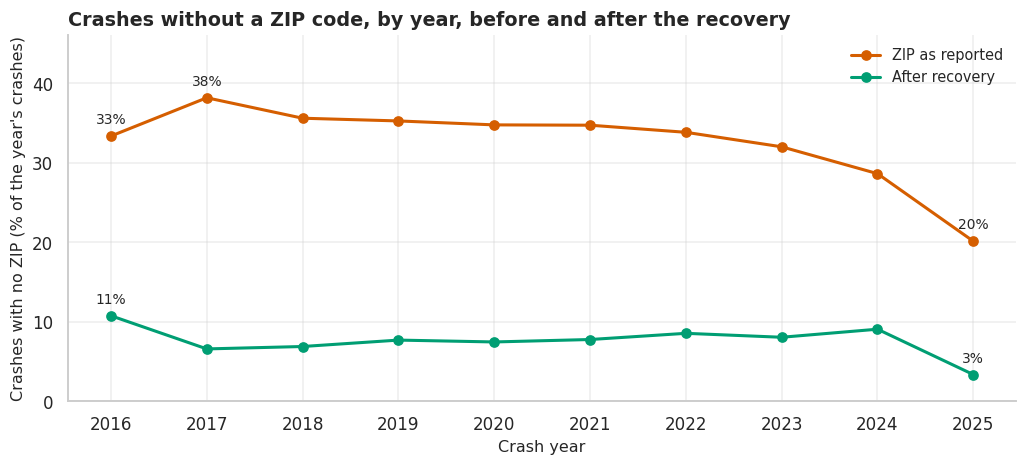

In [54]:
location_conflict = contradicts_area(labelled).reindex(crashes.index, fill_value=False)
zip_lookups = learn_lookups(labelled[~location_conflict[labelled.index].to_numpy()], "zip", ZIP_CELL_DEGREES)
recovered_zip, recovered_level = label_from_cells(crashes["lat"].to_numpy()[zip_targets],
                                                  crashes["lon"].to_numpy()[zip_targets], zip_lookups)

zip_missing_before = crashes["zip"].isna().to_numpy()
zip_reported = crashes["zip"].copy()
filled_zip = crashes["zip"].to_numpy(dtype=object)
filled_zip[zip_targets] = recovered_zip
crashes["zip"] = pd.Series(filled_zip).where(pd.notna(filled_zip), pd.NA).astype(zip_reported.dtype)
crashes["zip_imputed"] = zip_reported.isna().to_numpy() & crashes["zip"].notna().to_numpy()
zip_missing_after = crashes["zip"].isna().to_numpy()

n_imputed = int(crashes["zip_imputed"].sum())
n_no_cell = int((zip_targets & zip_missing_after).sum())
n_no_location = int((~crashes["is_located"].to_numpy() & zip_missing_after).sum())
# Reported ZIPs are untouched, filled values are ZIPs the crash table already uses, and every gap is counted.
assert crashes.loc[zip_reported.notna(), "zip"].eq(zip_reported.dropna()).all()
assert set(crashes.loc[crashes["zip_imputed"], "zip"].unique()) <= set(labelled["zip"].unique())
assert n_imputed + n_no_cell + n_no_location == int(zip_missing_before.sum())
log_rule("crashes", "reports whose borough contradicts their coordinates not used to teach the ZIP lookup",
         "flag", len(crashes), len(crashes), int(location_conflict.sum()),
         "Their wide area has many reports and nearly all give another borough. The reported values are kept.")
log_rule("crashes", f"missing zip recovered from coordinates (modal ZIP of a {ZIP_CELL_DEGREES[0]:g} degree cell, "
         f"else a {ZIP_CELL_DEGREES[1]:g} degree cell); flagged zip_imputed", "impute", len(crashes), len(crashes),
         n_imputed, f"Location-grouped test accuracy {holdout_accuracy:.1f}% (upper bound). Dropping the rows "
         f"would lose {100 * zip_missing_before.mean():.0f}% of the crashes, unevenly by year.")
log_rule("crashes", "zip still missing after recovery (no coordinates, or no labelled crash in either cell)",
         "flag", len(crashes), len(crashes), n_no_cell + n_no_location,
         "No value with evidence; kept for city totals and spatial work, excluded from the ZIP panel.")

missing_by_year = pd.DataFrame({"ZIP as reported": zip_missing_before, "After recovery": zip_missing_after}
                               ).groupby(crashes["year"].to_numpy()).mean() * 100
fig, ax = plt.subplots(figsize=(9.5, 4.4))
for column, color in zip(missing_by_year.columns, [PALETTE["crash"], PALETTE["after"]]):
    ax.plot(missing_by_year.index, missing_by_year[column], color=color, linewidth=2, marker="o", label=column)
    for year in sorted({missing_by_year.index[0], missing_by_year[column].idxmax(), missing_by_year.index[-1]}):
        ax.annotate(f"{missing_by_year.loc[year, column]:.0f}%", (year, missing_by_year.loc[year, column]),
                    xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(missing_by_year.index)
ax.set_ylim(0, missing_by_year.to_numpy().max() * AXIS_HEADROOM * 1.05)
ax.legend(loc="upper right")
finish(ax, "Crashes without a ZIP code, by year, before and after the recovery",
       "Crash year", "Crashes with no ZIP (% of the year's crashes)")
show(fig)

In [55]:
before_range, after_range = missing_by_year["ZIP as reported"], missing_by_year["After recovery"]
say(f"{n_imputed:,} crashes received a ZIP ({pct(n_imputed, int(zip_missing_before.sum())):.1f}% of those without "
    f"one; {pct((recovered_level == 1).sum(), n_imputed):.0f}% from the fine cell). The share without a ZIP falls "
    f"from {100 * zip_missing_before.mean():.1f}% to {100 * zip_missing_after.mean():.1f}%, and its spread across "
    f"years from {before_range.max() - before_range.min():.1f} to {after_range.max() - after_range.min():.1f} "
    f"points. {n_no_location:,} crashes have neither ZIP nor coordinates and {n_no_cell:,} lie in cells where no "
    f"crash reports a ZIP; these {n_pct(n_no_location + n_no_cell, len(crashes))} stay out of the ZIP panel.")

391,799 crashes received a ZIP (77.0% of those without one; 72% from the fine cell). The share without a ZIP falls from 33.8% to 7.8%, and its spread across years from 18.0 to 7.4 points. 89,427 crashes have neither ZIP nor coordinates and 27,696 lie in cells where no crash reports a ZIP; these 117,123 (7.8%) stay out of the ZIP panel.

The upper line is the artificial trend the naive panel would have carried: the share of crashes
missing from it moved by many points between years for reasons unrelated to safety. After the
recovery the gap is much smaller and flatter. What remains comes mainly from crashes without
coordinates, a share that was higher in the first study year, so ZIP-level comparisons that
include that year should be read with it in mind; the panel carries the number of imputed
crashes per row for checks on reported ZIPs only (Section 9).

#### 6.1.2 The final ZIP by year panel

The panel is rebuilt with the aggregation functions of 5.2 on the recovered ZIPs. Its ZIP codes
are those with at least `MIN_ZIP_CRASHES` crashes over the study years (the housing ZIP the
crash table never uses falls below it too); every such ZIP is crossed with every study year, and
cells without a source row are zeros on both sides.

In [56]:
def build_zip_year_panel(housing_aggregate, crash_aggregate, panel_zips):
    """Balanced ZIP x study-year table: every ZIP in `panel_zips` in every study year, zeros filled in.

    The keys are converted to plain text and integers first, because the two aggregates arrive
    with different key dtypes (6.3).
    """
    grid = pd.MultiIndex.from_product([sorted(panel_zips), STUDY_YEARS], names=["zip", "year"])

    def on_grid(aggregate, measures):
        keyed = aggregate.assign(zip=aggregate["zip"].astype(object), year=aggregate["year"].astype("int64"))
        return keyed.set_index(["zip", "year"])[measures].reindex(grid, fill_value=0)

    return pd.concat([on_grid(housing_aggregate, HOUSING_PANEL_MEASURES),
                      on_grid(crash_aggregate, CRASH_PANEL_MEASURES)], axis=1).reset_index()


crashes_by_zip_year = aggregate_crashes_to_zip_year(crashes)
crashes_per_zip = crashes_by_zip_year.groupby("zip")["crashes"].sum()
panel_zips = sorted(crashes_per_zip.index[crashes_per_zip >= MIN_ZIP_CRASHES])
n_small_zips = int((crashes_per_zip < MIN_ZIP_CRASHES).sum())
zip_year = build_zip_year_panel(housing_by_zip_year, crashes_by_zip_year, panel_zips)

# How many of each row's crashes rest on a recovered ZIP (for checks on reported ZIPs only).
imputed = crashes[crashes["zip_imputed"]]
imputed_counts = (pd.DataFrame({"zip": imputed["zip"].astype(object), "year": imputed["year"].astype("int64"),
                                "crashes_zip_imputed": 1, "injury_crashes_zip_imputed": imputed["is_injury_crash"]})
                  .groupby(["zip", "year"]).sum())
zip_year = zip_year.join(imputed_counts, on=["zip", "year"])
zip_year[list(imputed_counts.columns)] = zip_year[list(imputed_counts.columns)].fillna(0)
crashes["in_zip_panel"] = crashes["zip"].isin(panel_zips).to_numpy()

structural_zero_rows = int((zip_year["buildings_completed"] == 0).sum())
housing_zips_excluded = sorted(set(housing["zip"].dropna()) - set(panel_zips))
log_rule("zip panel", "ZIP-years with crashes and no completion: housing measures set to 0", "impute",
         len(zip_year), len(zip_year), structural_zero_rows,
         "Structural zero: no row in the housing aggregate means nothing was completed there that year.")
log_rule("zip panel", f"ZIP codes with fewer than {MIN_ZIP_CRASHES} crashes in {N_STUDY_YEARS} years left out",
         "drop", (len(panel_zips) + n_small_zips) * N_STUDY_YEARS, len(zip_year), n_small_zips,
         "Single-building and post-office codes, and a housing ZIP the crash table never uses; a zero crash "
         "count there would be false. Rows are ZIP-years, affected counts ZIP codes.")
display(pd.DataFrame({"naive panel (5.2)": gaps_before, "final panel": panel_gap_report(zip_year, crashes)},
                     dtype=object))
say(f"The final panel has {len(zip_year):,} rows, {len(panel_zips)} ZIP codes in each of {N_STUDY_YEARS} years, "
    f"with no missing cell. {n_pct(structural_zero_rows, len(zip_year), 0)} ZIP-years had no completion and carry "
    f"zeros on the housing side; {n_small_zips} low-volume ZIP codes were left out. Housing ZIP codes outside the "
    f"panel: {', '.join(housing_zips_excluded)} (their units are counted in 6.4).")

,naive panel (5.2),final panel
rows,"2,112.000","1,720.000"
ZIP codes,232.000,172.000
rows missing from a balanced panel,208.000,0.000
missing cells,"7,546.000",0.000
crashes placed in a row,"995,800.000","1,383,685.000"
% of all crashes placed,66.200,92.000
crashes with no ZIP,"508,922.000","117,123.000"


The final panel has 1,720 rows, 172 ZIP codes in each of 10 years, with no missing cell. 870 (51%) ZIP-years had no completion and carry zeros on the housing side; 59 low-volume ZIP codes were left out. Housing ZIP codes outside the panel: 10044, 10069, 10158, 10302, 10303 (their units are counted in 6.4).

Zero completions is a fact; zero crashes in a ZIP the crash table never uses would be an artefact.

### 6.2 Inconsistent or redundant columns

#### 6.2.1 Borough: one attribute, two sources

Both tables carry a borough, so a ZIP has two candidate boroughs, and a crash with a recovered
ZIP has no borough at all, because borough and ZIP are missing together in the crash table
(Section 4.8). The panel takes one borough per ZIP: the crash table decides (thousands of rows
per ZIP), housing fills in. A crash keeps the borough it reported, because the report is the
observation and the lookup a summary; a crash without one takes the borough of its ZIP.
Overwriting every crash with its ZIP's borough was the alternative, rejected because it would
replace reported values for tidiness.

In [57]:
def modal_borough_by_zip(frame, zip_column):
    """Per ZIP: the most frequent borough among rows that have both."""
    rows = frame[frame[zip_column].notna() & frame["borough"].notna()]
    counts = pd.DataFrame({"zip": rows[zip_column].astype(object), "borough": rows["borough"].astype(object)}).value_counts().rename("count")
    return counts.reset_index().sort_values(["zip", "count", "borough"], ascending=[True, False, True]
                                            ).drop_duplicates("zip").set_index("zip")["borough"]


borough_from_crashes = modal_borough_by_zip(crashes.assign(zip=zip_reported), "zip")
borough_from_housing = modal_borough_by_zip(housing, "zip")
shared = borough_from_crashes.index.intersection(borough_from_housing.index)
sources_disagree = int((borough_from_crashes[shared] != borough_from_housing[shared]).sum())
zip_borough = borough_from_crashes.combine_first(borough_from_housing)
assert set(panel_zips) <= set(zip_borough.index)

borough_reported = crashes["borough"].notna().to_numpy()      # what the police wrote down
borough_of_zip = crashes["zip"].astype(object).map(zip_borough).to_numpy(dtype=object)
fill_from_zip = ~borough_reported & pd.notna(borough_of_zip)
# A second check of the ZIP recovery, on rows that really lacked a ZIP: does the borough of the
# recovered ZIP match the borough the officer wrote down?
check_rows = crashes["zip_imputed"].to_numpy() & borough_reported
recovery_agrees = borough_of_zip[check_rows] == crashes["borough"].astype(object).to_numpy()[check_rows]
filled_borough = crashes["borough"].astype(object).to_numpy()
filled_borough[fill_from_zip] = borough_of_zip[fill_from_zip]

zip_year["borough"] = zip_year["zip"].map(zip_borough)
log_rule("zip panel", "two borough sources (crash reports, housing rows) resolved into one borough per ZIP",
         "standardise", len(zip_year), len(zip_year), sources_disagree,
         "Crash-modal borough, housing as fallback. Affected counts ZIPs where the two sources disagreed.")
log_rule("crashes", "missing borough filled from the main borough of the crash's ZIP", "impute",
         len(crashes), len(crashes), int(fill_from_zip.sum()),
         "Borough and ZIP are missing together; once the ZIP is recovered the borough follows from it.")

A crash can have coordinates and still lie in a cell where no crash reported a ZIP, so its
borough stays empty, and such gaps fall unevenly on the boroughs. For these crashes the borough
alone is voted by `cell_mode` over reported boroughs, from a 0.004 degree cell up to a 0.05
degree one; a borough is large, so a wide cell rarely crosses its edge. The vote is checked on
the same location-grouped test part as the ZIP. The ZIP stays empty: ZIP areas are small and the
panel should hold only ZIPs with cell-level evidence.

In [58]:
voters = labelled.assign(borough=labelled["borough"].astype(object))
train_voters = voters.loc[train_rows.index].dropna(subset=["borough"])
test_voters = voters.loc[test_rows.index].dropna(subset=["borough"])
voted_test, _ = label_from_cells(test_voters["lat"], test_voters["lon"],
                                 learn_lookups(train_voters, "borough", BOROUGH_CELL_DEGREES))
borough_vote_accuracy = 100 * (voted_test == test_voters["borough"].to_numpy(dtype=object)).mean()

# Final vote: every reported, uncontradicted borough of a located crash votes.
all_voters = crashes.loc[crashes["is_located"].to_numpy() & borough_reported & ~location_conflict.to_numpy(),
                         ["lat", "lon", "borough"]].astype({"borough": object})
lacking = crashes["is_located"].to_numpy() & pd.isna(filled_borough)
voted, _ = label_from_cells(crashes["lat"].to_numpy()[lacking], crashes["lon"].to_numpy()[lacking],
                            learn_lookups(all_voters, "borough", BOROUGH_CELL_DEGREES))
filled_borough[np.flatnonzero(lacking)] = voted
crashes["borough"] = pd.Categorical(filled_borough, categories=BOROUGHS)
n_voted = int(pd.notna(voted).sum())
log_rule("crashes", "borough of located crashes with no ZIP voted by reported boroughs in their grid cell",
         "impute", len(crashes), len(crashes), n_voted,
         f"Cells with no reported ZIP left an uneven gap by borough; test accuracy {borough_vote_accuracy:.1f}%. "
         "The ZIP stays empty.")
say(f"Housing and crashes name a different borough for {sources_disagree} of the {len(shared)} ZIP codes they share. "
    f"{int(fill_from_zip.sum()):,} crashes take the borough of their ZIP; where a recovered ZIP can be compared "
    f"with a reported borough ({int(check_rows.sum()):,} crashes) the two agree {100 * recovery_agrees.mean():.1f}% "
    f"of the time. {n_voted:,} more located crashes get a voted borough (test accuracy "
    f"{borough_vote_accuracy:.1f}%), and {n_pct(crashes['borough'].isna().sum(), len(crashes))} crashes, almost "
    f"all without coordinates, stay without one.")

Housing and crashes name a different borough for 0 of the 157 ZIP codes they share. 391,244 crashes take the borough of their ZIP; where a recovered ZIP can be compared with a reported borough (555 crashes) the two agree 99.1% of the time. 27,597 more located crashes get a voted borough (test accuracy 99.7%), and 89,187 (5.9%) crashes, almost all without coordinates, stay without one.

#### 6.2.2 Duplicate and leftover columns

Integration left columns that say the same thing twice or only served a step above. Each was
reviewed; the claim behind every drop is checked first.

In [59]:
assert (crashes["zip"].where(~crashes["zip_imputed"]).isna() == zip_reported.isna().to_numpy()).all()
assert (sites["is_completed"] == sites["completion_year"].notna()).all()
assert (zip_year["new_construction_units"] + zip_year["preservation_units"]
        <= zip_year["affordable_units_completed"]).all()
column_review = pd.DataFrame([
    ("crashes", "zip as reported", "drop", "Equal to zip wherever zip_imputed is False, and missing elsewhere."),
    ("naive_panel, crashes_by_zip_year_reported", "whole tables", "drop", "Replaced by zip_year."),
    ("crashes", "is_located", "keep", "Same as lat not missing, but used as a filter in every spatial step."),
    ("sites", "is_completed", "keep", "Same as completion_year not missing; kept for readable filters."),
    ("sites / zip_year", "borough and zip in both", "keep",
     "Not duplicates: one is the building's own borough and ZIP, the other the panel key."),
    ("zip_year", "new_construction_units, preservation_units", "keep",
     "Parts of affordable_units_completed, but each is a variable of its own in Section 8."),
], columns=["table", "column", "decision", "reason"])
show_table(column_review)
release("naive_panel", "crashes_by_zip_year_reported", "zip_reported")

,table,column,decision,reason
0,crashes,zip as reported,drop,"Equal to zip wherever zip_imputed is False, and missing ..."
1,"naive_panel, crashes_by_zip_year_reported",whole tables,drop,Replaced by zip_year.
2,crashes,is_located,keep,"Same as lat not missing, but used as a filter in every s..."
3,sites,is_completed,keep,Same as completion_year not missing; kept for readable f...
4,sites / zip_year,borough and zip in both,keep,Not duplicates: one is the building's own borough and ZI...
5,zip_year,"new_construction_units, preservation_units",keep,"Parts of affordable_units_completed, but each is a varia..."


#### 6.2.3 Cumulative units

Several questions need the stock (affordable units standing in the ZIP by a given year) rather
than the yearly flow. A running sum over the unbalanced housing aggregate would skip years
without a completion and lose completions before the first study year, so the stock is summed
on a complete grid from the first completion year in the housing table, then cut to the study
years. Housing built before the table starts is not in the data, so the stock is the stock added
since then.

In [60]:
CUMULATIVE_COLUMNS = {"cum_affordable_units": "affordable_units_completed",
                      "cum_deep_affordable_units": "deep_affordable_units"}
housing_first_year = int(housing_by_zip_year["year"].min())
history = pd.MultiIndex.from_product([panel_zips, range(housing_first_year, YEAR_END + 1)], names=["zip", "year"])
keyed = housing_by_zip_year.assign(zip=housing_by_zip_year["zip"].astype(object),
                                   year=housing_by_zip_year["year"].astype("int64")).set_index(["zip", "year"])
cumulative = (keyed[list(CUMULATIVE_COLUMNS.values())].reindex(history, fill_value=0)
              .groupby(level="zip").cumsum().set_axis(list(CUMULATIVE_COLUMNS), axis=1))
zip_year = zip_year.join(cumulative, on=["zip", "year"])

# The stock grows by exactly the year's completions, and ends at the sum of all completions to date.
stock_change = zip_year.groupby("zip")["cum_affordable_units"].diff()
assert (stock_change.dropna() == zip_year.loc[stock_change.notna(), "affordable_units_completed"]).all()
assert (zip_year.loc[zip_year["year"] == YEAR_END, "cum_affordable_units"].sum()
        == keyed.loc[keyed.index.get_level_values("zip").isin(panel_zips)
                     & (keyed.index.get_level_values("year") <= YEAR_END), "affordable_units_completed"].sum())
log_rule("zip panel", "cumulative unit columns computed on a complete grid from the first housing year",
         "standardise", len(zip_year), len(zip_year), len(CUMULATIVE_COLUMNS),
         "A running sum over the unbalanced aggregate would skip empty years and lose earlier completions. "
         "Affected counts columns.")
start_rows = zip_year["year"] == YEAR_START
stock_at_start = int((zip_year.loc[start_rows, "cum_affordable_units"] - zip_year.loc[start_rows, "affordable_units_completed"]).sum())
say(f"The housing table starts in {housing_first_year}. The panel's ZIP codes enter {YEAR_START} with "
    f"{stock_at_start:,} affordable units completed earlier and end {YEAR_END} with a stock of "
    f"{int(zip_year.loc[zip_year['year'] == YEAR_END, 'cum_affordable_units'].sum()):,}.")

The housing table starts in 2014. The panel's ZIP codes enter 2016 with 12,363 affordable units completed earlier and end 2025 with a stock of 220,701.

### 6.3 Data type mismatches

A join compares key values exactly, so keys that look alike but are stored differently do not
match. With a default load, pandas reads the housing postcode as a decimal number (the column
has blanks) while crash ZIPs are text, which is why Section 2 loaded every column as text; the
cell below shows what a join on default types would have found. The year is a nullable integer
in housing (unfinished buildings have none) and a plain integer in crashes, and merges and grids
turn counts into decimals or 64-bit integers and labels into plain objects. Every integrated
table is therefore cast to one declared schema, and the schema is asserted.

In [61]:
default_zip_text = set(pd.read_csv(HOUSING_FILE, usecols=["postcode"])["postcode"].dropna().astype(str))
crash_zip_text = set(crashes["zip"].dropna().astype(object))
clean_zip_text = set(housing["zip"].dropna().astype(object))
key_match = pd.DataFrame({"distinct housing ZIPs": [len(default_zip_text), len(clean_zip_text)],
                          "found among crash ZIPs": [len(default_zip_text & crash_zip_text),
                                                     len(clean_zip_text & crash_zip_text)],
                          "example": [sorted(default_zip_text)[0], sorted(clean_zip_text)[0]]},
                         index=["default load (number)", "as cleaned (text)"])
display(key_match)

COUNT = "int32"
ZIP_DTYPE = housing["zip"].dtype
SCHEMAS = {
    "zip_year": {"zip": ZIP_DTYPE, "year": "int16", "borough": "category",
                 **dict.fromkeys(HOUSING_PANEL_MEASURES + list(CUMULATIVE_COLUMNS) + CRASH_PANEL_MEASURES, COUNT),
                 "crashes_zip_imputed": COUNT, "injury_crashes_zip_imputed": COUNT},
    "sites": {"site_id": "int32", "cluster_id": "int32", "housing_id": "int32",
              "project_id": "int64", "building_id": "int64", "project_name": housing["project_name"].dtype,
              "borough": "category", "zip": ZIP_DTYPE, "lat": "float64", "lon": "float64", "start_year": "int16",
              "completion_year": "Int16", "is_completed": "bool", "same_day_completion": "bool",
              "completion_before_start": "bool", "construction_type": "category", "total_units": "int16",
              "all_counted_units": "int16", "deep_affordable_units": "int16", "deep_affordable_share": "float64",
              "size_band": "category", "is_size_outlier": "bool", "n_sites_within_buffer": "int32"},
    "site_year": {"site_id": "int32", "year": "int16", **dict.fromkeys(SITE_COUNT_COLUMNS, COUNT)},
    "event_panel": {"site_id": "int32", "cluster_id": "int32", "cohort": "int16",
                    "group": "category", "rel_year": "int8", "year": "int16", **dict.fromkeys(SITE_COUNT_COLUMNS, COUNT),
                    "contaminated": "bool", "near_completion_in_window": "bool", "near_earlier_completion": "bool",
                    "completion_year": "Int16", "construction_type": "category", "borough": "category",
                    "size_band": "category", "total_units": "int16"},
}
CRASH_NEW_COLUMNS = {"zip": ZIP_DTYPE, "zip_imputed": "bool", "borough": "category", "in_zip_panel": "bool",
                     "near_site_id": "Int32"}


def cast_to_schema(frame, schema):
    """The frame with exactly the schema's columns, in its order and dtypes; counts must be whole and complete."""
    assert set(schema) == set(frame.columns), set(schema) ^ set(frame.columns)
    result = frame[list(schema)].copy()
    for column, dtype in schema.items():
        if dtype == "category" and result[column].dtype != "category":
            result[column] = pd.Categorical(result[column], categories=BOROUGHS)   # only borough arrives as text
            assert result[column].notna().all(), f"{column}: label outside the declared levels"
        elif dtype != "category":
            if dtype == COUNT:
                values = result[column].astype("float64")
                assert values.notna().all() and (values == np.floor(values)).all(), f"{column}: not a whole count"
            result[column] = result[column].astype(dtype)
    return result


tables = {"zip_year": zip_year, "sites": sites, "site_year": site_year, "event_panel": event_panel}
n_dtype_changes = sum(str(frame[column].dtype) != str(dtype) for name, frame in tables.items()
                      for column, dtype in SCHEMAS[name].items() if dtype != "category")
zip_year, sites, site_year, event_panel = (cast_to_schema(tables[name], SCHEMAS[name]) for name in tables)
release("tables")

# The schema holds, join keys share one dtype, and the keys really join.
for name, frame in [("zip_year", zip_year), ("sites", sites), ("site_year", site_year), ("event_panel", event_panel)]:
    assert all(frame[column].dtype == dtype for column, dtype in SCHEMAS[name].items()), name
assert all(crashes[column].dtype == dtype for column, dtype in CRASH_NEW_COLUMNS.items())
assert zip_year["zip"].dtype == crashes["zip"].dtype == housing["zip"].dtype == sites["zip"].dtype
assert zip_year["year"].dtype == crashes["year"].dtype == site_year["year"].dtype == event_panel["year"].dtype
for frame in (zip_year, sites, event_panel, crashes, housing):
    assert list(frame["borough"].cat.categories) == BOROUGHS
assert crashes["near_site_id"].dropna().isin(sites["site_id"]).all()
assert set(zip_year["zip"]) <= set(crashes["zip"].dropna())
assert key_match.loc["default load (number)", "found among crash ZIPs"] == 0   # the sentence below relies on it

log_rule("zip panel", "integrated tables cast to a declared schema (keys, counts, categories)", "standardise",
         len(zip_year), len(zip_year), n_dtype_changes,
         "Merges and grids returned object keys, 64-bit and decimal counts. Affected counts columns across the "
         "four tables.")
say(f"Read with default types, none of the {key_match.iloc[0, 0]} housing postcodes equals a crash ZIP as text; as "
    f"cleaned, {key_match.iloc[1, 1]} of {key_match.iloc[1, 0]} do. A merge on the default keys would have "
    f"returned an empty match without an error. The cast changed {n_dtype_changes} columns across the four "
    f"tables. Identifiers that can be missing keep a nullable integer type on purpose (`near_site_id`, "
    f"`completion_year`): a zero or minus one there would look like a real value.")

,distinct housing ZIPs,found among crash ZIPs,example
default load (number),158,0,10001.0
as cleaned (text),158,157,10001


Read with default types, none of the 158 housing postcodes equals a crash ZIP as text; as cleaned, 157 of 158 do. A merge on the default keys would have returned an empty match without an error. The cast changed 6 columns across the four tables. Identifiers that can be missing keep a nullable integer type on purpose (`near_site_id`, `completion_year`): a zero or minus one there would look like a real value.

### 6.4 Conservation checks

Every crash is either in a row of the panel or in one excluded group, measure by measure, and
every housing unit is in the panel's yearly columns or a counted exclusion; the asserts stop the run otherwise.

In [62]:
crash_measure_sources = {"crashes": None, "injury_crashes": "is_injury_crash", "persons_injured": "injured",
                         "persons_killed": "killed", "ped_cyc_crashes": "ped_cyc_harm"}
crash_groups = {
    "In the ZIP panel": crashes["in_zip_panel"].to_numpy(),
    f"ZIP with fewer than {MIN_ZIP_CRASHES} crashes": (crashes["zip"].notna() & ~crashes["in_zip_panel"]).to_numpy(),
    "No ZIP, coordinates in an unlabelled cell": (crashes["zip"].isna() & crashes["is_located"]).to_numpy(),
    "No ZIP and no coordinates": (crashes["zip"].isna() & ~crashes["is_located"]).to_numpy(),
}
assert (np.column_stack(list(crash_groups.values())).sum(axis=1) == 1).all(), "every crash is in exactly one group"
conservation = pd.DataFrame({
    measure: {group: int(mask.sum()) if source is None else int(crashes[source].to_numpy()[mask].sum())
              for group, mask in crash_groups.items()}
    for measure, source in crash_measure_sources.items()})
conservation.loc["Total"] = conservation.sum()
conservation["% of crashes"] = (100 * conservation["crashes"] / len(crashes)).round(2)
display(conservation)
for measure, source in crash_measure_sources.items():
    assert conservation.loc["Total", measure] == (len(crashes) if source is None else int(crashes[source].sum()))
    assert zip_year[measure].sum() == conservation.loc["In the ZIP panel", measure], measure

# Housing: units of a repeated building are counted once, at its first completion (5.2).
completed, repeat = housing["is_completed"], is_repeat_building(housing)
in_panel_zip = housing["zip"].isin(panel_zips)
housing_groups = {
    "In the ZIP panel": completed & ~repeat & in_panel_zip & housing["completion_year"].between(YEAR_START, YEAR_END),
    f"Completed before {YEAR_START} (in the stock only)": completed & ~repeat & in_panel_zip & (housing["completion_year"] < YEAR_START),
    f"Completed after {YEAR_END}": completed & ~repeat & in_panel_zip & (housing["completion_year"] > YEAR_END),
    "Completed again under a later project": completed & repeat,
    "Completed, ZIP not in the panel": completed & ~repeat & housing["zip"].notna() & ~in_panel_zip,
    "Completed, no ZIP (confidential)": completed & ~repeat & housing["zip"].isna(),
    "No completion date": ~completed,
}
housing_conservation = pd.DataFrame({
    "rows": {group: int(mask.sum()) for group, mask in housing_groups.items()},
    "total_units": {group: int(housing.loc[mask, "total_units"].sum()) for group, mask in housing_groups.items()},
})
housing_conservation.loc["Total"] = housing_conservation.sum()
housing_conservation["% of units"] = (100 * housing_conservation["total_units"] / housing["total_units"].sum()).round(1)
display(housing_conservation)
assert housing_conservation.loc["Total", "rows"] == len(housing)
assert housing_conservation.loc["Total", "total_units"] == housing["total_units"].sum()
assert zip_year["units_completed"].sum() == housing_conservation.loc["In the ZIP panel", "total_units"]
# The panel is unique on its key, balanced, complete and its counts are nested.
assert not zip_year.duplicated(["zip", "year"]).any() and len(zip_year) == len(panel_zips) * N_STUDY_YEARS
assert zip_year.notna().all().all()
assert (zip_year["ped_cyc_crashes"] <= zip_year["injury_crashes"]).all()
assert (zip_year["injury_crashes"] <= zip_year["crashes"]).all()
assert (zip_year["deep_affordable_units"] <= zip_year["affordable_units_completed"]).all()

say(f"All checks pass. {n_pct(conservation.loc['In the ZIP panel', 'crashes'], len(crashes))} crashes and "
    f"{pct(conservation.loc['In the ZIP panel', 'injury_crashes'], conservation.loc['Total', 'injury_crashes']):.1f}% "
    f"of injury crashes are in the panel; the rest are in three counted groups. The panel's yearly columns hold "
    f"{housing_conservation.loc['In the ZIP panel', '% of units']:.1f}% of all housing units; the largest group "
    f"outside is buildings with no completion date "
    f"({housing_conservation.loc['No completion date', '% of units']:.1f}%), which the spatial level uses as "
    f"comparison sites.")

,crashes,injury_crashes,persons_injured,persons_killed,ped_cyc_crashes,% of crashes
In the ZIP panel,1383685,376836,503028,2336,135581,91.960
ZIP with fewer than 500 crashes,3914,837,1048,7,371,0.260
"No ZIP, coordinates in an unlabelled cell",27696,7431,10887,55,1248,1.840
No ZIP and no coordinates,89427,24863,36028,219,4814,5.940
Total,1504722,409967,550991,2617,142014,100.000


,rows,total_units,% of units
In the ZIP panel,5340,287267,64.500
Completed before 2016 (in the stock only),247,12758,2.900
Completed after 2025,346,24182,5.400
Completed again under a later project,78,5955,1.300
"Completed, ZIP not in the panel",7,1608,0.400
"Completed, no ZIP (confidential)",1880,2693,0.600
No completion date,1653,111125,24.900
Total,9551,445588,100.000


All checks pass. 1,383,685 (92.0%) crashes and 91.9% of injury crashes are in the panel; the rest are in three counted groups. The panel's yearly columns hold 64.5% of all housing units; the largest group outside is buildings with no completion date (24.9%), which the spatial level uses as comparison sites.

### 6.5 A citywide yearly index for reference

Every comparison over time has to be read against the city as a whole. `city_year` gives yearly
totals over all cleaned crashes, with or without a ZIP or coordinates, and an index that sets
`INDEX_BASE_YEAR` to 100; both series share one axis as indices since their levels differ.

,year,crashes,injury_crashes,persons_injured,persons_killed,ped_cyc_crashes,injury_share,deaths_per_1000_injury_crashes,crash_index,injury_crash_index
0,2016,229833,44362,60614,247,15681,0.193,5.568,108.675,97.630
1,2017,231007,44733,60751,261,15554,0.194,5.835,109.230,98.446
2,2018,231564,45804,61985,232,15460,0.198,5.065,109.494,100.803
3,2019,211486,45439,61391,244,15218,0.215,5.370,100.000,100.000
4,2020,112918,33362,44615,269,11968,0.295,8.063,53.393,73.422
5,2021,110558,38810,51786,297,12184,0.351,7.653,52.277,85.411
6,2022,103887,39336,51933,290,13639,0.379,7.372,49.122,86.569
7,2023,96607,40472,54252,280,13833,0.419,6.918,45.680,89.069
8,2024,91316,40229,54030,268,14366,0.441,6.662,43.178,88.534
9,2025,85546,37420,49634,229,14111,0.437,6.120,40.450,82.352


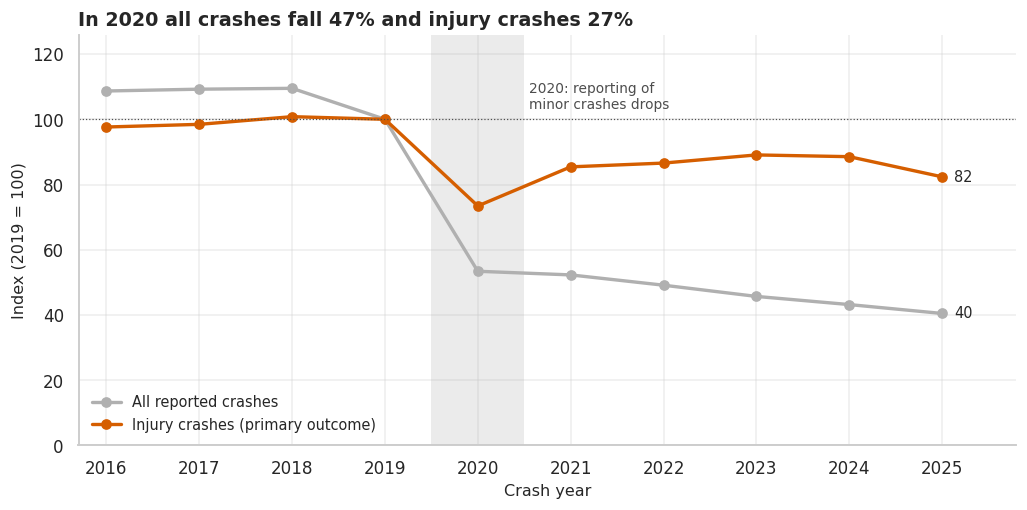

In [63]:
city_year = (crashes.groupby("year")
             .agg(crashes=("collision_id", "size"), injury_crashes=("is_injury_crash", "sum"),
                  persons_injured=("injured", "sum"), persons_killed=("killed", "sum"),
                  ped_cyc_crashes=("ped_cyc_harm", "sum"))
             .astype(COUNT).reset_index())
city_year["year"] = city_year["year"].astype("int16")
city_year["injury_share"] = city_year["injury_crashes"] / city_year["crashes"]
# Deaths are recorded whatever the severity, so this ratio shows whether the remaining injury
# crashes are more severe after the break, or whether minor ones went missing.
city_year["deaths_per_1000_injury_crashes"] = PER_THOUSAND * city_year["persons_killed"] / city_year["injury_crashes"]
base_row = city_year.set_index("year").loc[INDEX_BASE_YEAR]
city_year["crash_index"] = INDEX_BASE * city_year["crashes"] / base_row["crashes"]
city_year["injury_crash_index"] = INDEX_BASE * city_year["injury_crashes"] / base_row["injury_crashes"]
assert list(city_year["year"]) == STUDY_YEARS and city_year["crashes"].sum() == len(crashes)
show_table(city_year.round(3))

city_by_year = city_year.set_index("year")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for column, label, color in [("crash_index", "All reported crashes", PALETTE["before"]),
                             ("injury_crash_index", "Injury crashes (primary outcome)", PALETTE["crash"])]:
    ax.plot(city_year["year"], city_year[column], color=color, linewidth=2.2, marker="o", label=label)
    ax.annotate(f"{city_year[column].iloc[-1]:.0f}", (YEAR_END, city_year[column].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9.5)
ax.axhline(INDEX_BASE, color=PALETTE["neutral"], linewidth=0.8, linestyle=":")
ax.axvspan(BREAK_YEAR - 0.5, BREAK_YEAR + 0.5, color=PALETTE["before"], alpha=0.25, linewidth=0)
ax.annotate(f"{BREAK_YEAR}: reporting of\nminor crashes drops", (BREAK_YEAR + 0.55, INDEX_BASE * 1.07),
            fontsize=9, color=PALETTE["neutral"], va="center")
ax.set_xticks(STUDY_YEARS)
ax.set_xlim(YEAR_START - 0.3, YEAR_END + 0.8)
ax.set_ylim(0, city_year[["crash_index", "injury_crash_index"]].max().max() * AXIS_HEADROOM)
ax.legend(loc="lower left")
finish(ax, f"In {BREAK_YEAR} all crashes fall {INDEX_BASE - city_by_year.loc[BREAK_YEAR, 'crash_index']:.0f}% and "
           f"injury crashes {INDEX_BASE - city_by_year.loc[BREAK_YEAR, 'injury_crash_index']:.0f}%",
       "Crash year", f"Index ({INDEX_BASE_YEAR} = {INDEX_BASE})")
show(fig)

In [64]:
deaths_rate = city_by_year["deaths_per_1000_injury_crashes"]
say(f"Injury crashes reach index {city_by_year.loc[YEAR_END, 'injury_crash_index']:.0f} in {YEAR_END} against "
    f"{city_by_year.loc[YEAR_END, 'crash_index']:.0f} for all crashes, and the share of crashes with an injury or "
    f"death rises from {100 * city_by_year.loc[INDEX_BASE_YEAR, 'injury_share']:.0f}% to "
    f"{100 * city_by_year.loc[YEAR_END, 'injury_share']:.0f}%. Deaths per 1,000 injury crashes run from "
    f"{deaths_rate.loc[:INDEX_BASE_YEAR].min():.1f} to {deaths_rate.loc[:INDEX_BASE_YEAR].max():.1f} up to "
    f"{INDEX_BASE_YEAR} and from {deaths_rate.loc[BREAK_YEAR:].min():.1f} to {deaths_rate.loc[BREAK_YEAR:].max():.1f} "
    f"from {BREAK_YEAR}.")

Injury crashes reach index 82 in 2025 against 40 for all crashes, and the share of crashes with an injury or death rises from 21% to 44%. Deaths per 1,000 injury crashes run from 5.1 to 5.8 up to 2019 and from 6.1 to 8.1 from 2020.

The lines part after the base year and never rejoin: fewer minor collisions were written up, so
a count of all crashes would drop everywhere, whatever was built there. Injury crashes dip less
and are the outcome of Section 8. The higher death rate after the break fits more severe crashes
or unreported minor ones, which the data cannot separate, so every before and after comparison
is made against comparison sites or within the same calendar years.

### 6.6 Rules logged in this section and final outputs

The log lists every rule recorded in Section 6; the table after it the six tables the analysis uses.

In [65]:
post_integration_log = pd.DataFrame(CLEANING_LOG[POST_LOG_START:])
show_table(post_integration_log)
assert set(post_integration_log["action"]) <= {"drop", "impute", "flag", "standardise"}
display(pd.DataFrame({name: {"rows": len(frame), "columns": frame.shape[1]} for name, frame in
                      [("zip_year", zip_year), ("sites", sites), ("site_year", site_year),
                       ("event_panel", event_panel), ("crashes", crashes), ("city_year", city_year)]}).T)

# These six tables are what the analysis sections use; the functions of Sections 5 and 6 stay
# defined so that Section 9 can rebuild the spatial tables at another radius or the panel on reported ZIPs.
release("train_all", "train_rows", "select_rows", "test_rows", "street", "on_highway_by_id", "filled_zip",
        "recovered_zip", "borough_of_zip", "filled_borough", "voters", "train_voters", "test_voters", "all_voters",
        "imputed", "imputed_counts", "keyed", "history", "location", "draw", "part", "default_zip_text",
        "crash_zip_text", "clean_zip_text", "completed", "repeat", "in_panel_zip", "stock_change")

,dataset,rule,action,rows_before,rows_after,affected,reason
0,crashes,reports whose borough contradicts their coordinates not ...,flag,1504722,1504722,441,Their wide area has many reports and nearly all give ano...
1,crashes,missing zip recovered from coordinates (modal ZIP of a 0...,impute,1504722,1504722,391799,Location-grouped test accuracy 96.9% (upper bound). Drop...
2,crashes,"zip still missing after recovery (no coordinates, or no ...",flag,1504722,1504722,117123,No value with evidence; kept for city totals and spatial...
3,zip panel,ZIP-years with crashes and no completion: housing measur...,impute,1720,1720,870,Structural zero: no row in the housing aggregate means n...
4,zip panel,ZIP codes with fewer than 500 crashes in 10 years left out,drop,2310,1720,59,"Single-building and post-office codes, and a housing ZIP..."
5,zip panel,"two borough sources (crash reports, housing rows) resolv...",standardise,1720,1720,0,"Crash-modal borough, housing as fallback. Affected count..."
6,crashes,missing borough filled from the main borough of the cras...,impute,1504722,1504722,391244,Borough and ZIP are missing together; once the ZIP is re...
7,crashes,borough of located crashes with no ZIP voted by reported...,impute,1504722,1504722,27597,Cells with no reported ZIP left an uneven gap by borough...
8,zip panel,cumulative unit columns computed on a complete grid from...,standardise,1720,1720,2,A running sum over the unbalanced aggregate would skip e...
9,zip panel,"integrated tables cast to a declared schema (keys, count...",standardise,1720,1720,6,"Merges and grids returned object keys, 64-bit and decima..."


,rows,columns
zip_year,1720,18
sites,7593,23
site_year,75930,6
event_panel,93618,18
crashes,1504722,27
city_year,10,10


## 7. Analysis toolkit

The research questions reuse a few statistical steps, so they are written once here as small
functions on numpy arrays. Nothing in this section touches the housing or crash data, and 7.5
checks the functions on tiny inputs whose answer is known.

Three ideas shape the section. Crashes near the same building or in the same ZIP are not
independent, so every interval resamples whole clusters (sites or ZIPs), never single
crashes; resampling crashes would make any difference look real. Every function reports how
many units it used. And the data are observational, so the wording helper only ever describes
associations.

### 7.1 Shared statistics (also used by the website)

The cell below is the file `app/stats.py`, pasted in when the notebook is built, so the
notebook and the website compute every interval with the same code, seed and order of draws.

- `bootstrap_ci` recomputes any statistic on `N_BOOT` resamples. With `clusters`, whole clusters
  are drawn with replacement and their rows travel together. Each call starts its own generator
  from `SEED`, so a result does not depend on which cells ran before it.
- `percentile_ci` reads the interval off the replicates. A replicate that cannot be computed
  (say, a resample without a control site) is NaN; if more than `MAX_FAILED_SHARE` fail, no
  interval is reported, because silently dropping them would make an unstable estimate look
  stable. `bootstrap_p_value` is the share of replicates beyond zero, used only where several
  results are adjusted together (7.4); its floor is about `2 / N_BOOT`.
- `log_ratio` measures a site's change as log((after + 0.5) / (before + 0.5)). The half-crash
  offset (`LOG_RATIO_OFFSET`) keeps sites with a zero count; dropping them (the alternative)
  would remove exactly the quiet sites. Logs make a site going from 4 to 2 crashes count like one
  going from 40 to 20, where levels would let a few busy avenues decide.
- `did_log_ratio` is the difference-in-differences: treated mean log ratio minus control mean
  log ratio over the same calendar years, compared inside strata (for example cohorts) and
  averaged with treated counts as weights. A stratum without both arms is dropped and counted.
  `type_contrast` does this for two treated types against one shared control group in a single
  bootstrap, so their difference is paired. `event_profile` gives the indexed yearly means
  behind the event charts.

In [66]:
# The same code as app/stats.py, which the website uses.
"""Shared statistics: cluster bootstrap, difference-in-differences and the event-study profile.

This file is the single home of this code. The notebook pastes it into Section 7 (see
tools/assemble_notebook.py) and the website imports it, so both compute every interval with the
same resampling scheme, seed and order of random draws. Pure numpy and pandas.
"""

import warnings

import numpy as np
import pandas as pd

N_BOOT = 1000                 # bootstrap resamples behind every interval (equal to Section 1's value)
CI_LEVEL = 0.95
SEED = 42
LOG_RATIO_OFFSET = 0.5        # crashes added to both counts, so a site with zero crashes keeps a finite ratio
MAX_FAILED_SHARE = 0.10       # no interval is reported when more replicates than this share fail
PERCENT = 100
PRE_PERIOD_INDEX = 100        # the mean of the pre-completion years is set to 100 in the event chart
NEUTRAL_PERCENTILE = 50       # mean percentile that sites would have if they were typical streets


def percentile_ci(samples, level: float = CI_LEVEL) -> dict:
    """Percentile interval of bootstrap replicates (rows); NaN where too many replicates failed."""
    values = np.asarray(samples, dtype=float)
    n_failed = np.isnan(values).sum(axis=0)
    tail_pct = PERCENT * (1 - level) / 2
    with warnings.catch_warnings():          # an all-NaN column warns; its NaN is the wanted answer
        warnings.simplefilter("ignore", category=RuntimeWarning)
        low = np.nanpercentile(values, tail_pct, axis=0)
        high = np.nanpercentile(values, PERCENT - tail_pct, axis=0)
    too_many_failed = n_failed > MAX_FAILED_SHARE * values.shape[0]
    low, high = np.where(too_many_failed, np.nan, low), np.where(too_many_failed, np.nan, high)
    if values.ndim == 1:
        return {"low": float(low), "high": float(high), "n_failed": int(n_failed)}
    return {"low": low, "high": high, "n_failed": n_failed}


def bootstrap_p_value(replicates, null_value: float = 0.0) -> float:
    """Two-sided bootstrap p-value: twice the smaller share of replicates on either side of the null."""
    values = np.asarray(replicates, dtype=float)
    values = values[~np.isnan(values)]
    if values.size == 0:
        return float("nan")
    at_or_below = int((values <= null_value).sum())
    at_or_above = int((values >= null_value).sum())
    # One is added to count and total so the p-value is never exactly zero (floor about 2 / N_BOOT).
    return float(min(1.0, 2 * (min(at_or_below, at_or_above) + 1) / (values.size + 1)))


def cluster_layout(clusters, n_rows: int):
    """(order, starts, sizes): cluster j owns rows order[starts[j]:starts[j] + sizes[j]]."""
    if clusters is None:                     # every row is its own cluster
        return np.arange(n_rows), np.arange(n_rows), np.ones(n_rows, dtype=np.int64)
    codes, _ = pd.factorize(np.asarray(clusters))
    assert len(codes) == n_rows and (codes >= 0).all(), "one non-missing cluster label per row"
    order = np.argsort(codes, kind="stable")
    sizes = np.bincount(codes)
    return order, np.cumsum(sizes) - sizes, sizes


def draw_rows(generator, layout) -> np.ndarray:
    """Row numbers of one resample: clusters drawn with replacement, their rows kept together."""
    order, starts, sizes = layout
    picked = generator.integers(0, len(sizes), len(sizes))
    picked_sizes = sizes[picked]
    # Without a Python loop: picked cluster j contributes positions starts[j] .. starts[j] + size - 1.
    block_ends = np.cumsum(picked_sizes)
    position_in_block = np.arange(block_ends[-1]) - np.repeat(block_ends - picked_sizes, picked_sizes)
    return order[np.repeat(starts[picked], picked_sizes) + position_in_block]


def bootstrap_ci(statistic, *arrays, clusters=None, n_boot: int = N_BOOT, seed: int = SEED,
                 level: float = CI_LEVEL) -> dict:
    """Percentile bootstrap of `statistic(*arrays)`, resampling rows or whole clusters.

    Returns estimate, low, high, p_value (against zero), n, n_clusters, n_failed, replicates.
    """
    arrays = [np.asarray(array) for array in arrays]
    n_rows = len(arrays[0])
    assert n_rows > 0 and all(len(array) == n_rows for array in arrays), "row-aligned, non-empty arrays"
    layout = cluster_layout(clusters, n_rows)
    generator = np.random.default_rng(seed)  # a fresh generator: results do not depend on call order
    with np.errstate(invalid="ignore", divide="ignore"):
        estimate = np.asarray(statistic(*arrays), dtype=float)
        replicates = np.full((n_boot,) + estimate.shape, np.nan)
        for replicate in range(n_boot):
            rows = draw_rows(generator, layout)
            replicates[replicate] = statistic(*[array[rows] for array in arrays])
    interval = percentile_ci(replicates, level)
    if estimate.ndim == 0:
        estimate, p_value = float(estimate), bootstrap_p_value(replicates)
    else:
        p_value = np.array([bootstrap_p_value(column) for column in replicates.T])
    return {"estimate": estimate, "low": interval["low"], "high": interval["high"], "p_value": p_value,
            "n": int(n_rows), "n_clusters": int(len(layout[2])), "n_failed": interval["n_failed"],
            "replicates": replicates}


def log_points_to_percent(log_points):
    """A difference in logs as a percentage change: 100 * (exp(x) - 1)."""
    return PERCENT * np.expm1(log_points)


def log_ratio(before, after) -> np.ndarray:
    """log((after + 0.5) / (before + 0.5)) for counts, element by element."""
    before, after = np.asarray(before, dtype=float), np.asarray(after, dtype=float)
    return np.log((after + LOG_RATIO_OFFSET) / (before + LOG_RATIO_OFFSET))


def stratified_difference(change, treated, strata_codes, n_strata: int) -> dict:
    """Treated-minus-control mean of `change`, compared inside strata and weighted by treated counts.

    Strata lacking either arm are dropped from both sides; the counts are of the units used.
    """
    treated_n = np.bincount(strata_codes[treated], minlength=n_strata)
    control_n = np.bincount(strata_codes[~treated], minlength=n_strata)
    treated_sum = np.bincount(strata_codes[treated], weights=change[treated], minlength=n_strata)
    control_sum = np.bincount(strata_codes[~treated], weights=change[~treated], minlength=n_strata)
    comparable = (treated_n > 0) & (control_n > 0)
    if not comparable.any():
        return {"estimate": float("nan"), "treated_change": float("nan"), "control_change": float("nan"),
                "n_treated": 0, "n_control": 0, "n_strata": 0}
    weights = treated_n[comparable] / treated_n[comparable].sum()
    treated_change = float((weights * treated_sum[comparable] / treated_n[comparable]).sum())
    control_change = float((weights * control_sum[comparable] / control_n[comparable]).sum())
    return {"estimate": treated_change - control_change, "treated_change": treated_change,
            "control_change": control_change, "n_treated": int(treated_n[comparable].sum()),
            "n_control": int(control_n[comparable].sum()), "n_strata": int(comparable.sum())}


def did_log_ratio(before, after, treated, strata=None, clusters=None, n_boot: int = N_BOOT,
                  seed: int = SEED, level: float = CI_LEVEL) -> dict:
    """Difference-in-differences of the log after/before ratio, strata weighted, clusters resampled.

    Returns estimate, low, high (log points), percent_change, percent_low, percent_high, p_value,
    treated_change, control_change, n_treated, n_control, n_strata (all as used), n_treated_dropped,
    n_control_dropped, n_clusters and n_failed.
    """
    change = log_ratio(before, after)
    treated = np.asarray(treated, dtype=bool)
    if strata is None:
        strata_codes, n_strata = np.zeros(len(change), dtype=np.int64), 1
    else:
        strata_codes, strata_labels = pd.factorize(np.asarray(strata))
        n_strata = len(strata_labels)
    point = stratified_difference(change, treated, strata_codes, n_strata)

    def did_estimate(change_rows, treated_rows, strata_rows):
        return stratified_difference(change_rows, treated_rows, strata_rows, n_strata)["estimate"]

    boot = bootstrap_ci(did_estimate, change, treated, strata_codes, clusters=clusters,
                        n_boot=n_boot, seed=seed, level=level)
    return {**point, "low": boot["low"], "high": boot["high"], "p_value": boot["p_value"],
            "percent_change": float(log_points_to_percent(point["estimate"])),
            "percent_low": float(log_points_to_percent(boot["low"])),
            "percent_high": float(log_points_to_percent(boot["high"])),
            "n_treated_dropped": int(treated.sum()) - point["n_treated"],
            "n_control_dropped": int((~treated).sum()) - point["n_control"],
            "n_clusters": boot["n_clusters"], "n_failed": boot["n_failed"]}


def type_contrast(before, after, arm, strata, clusters) -> dict:
    """DiD for two treated arms against one shared comparison arm, and their difference.

    arm: 0 = comparison, 1 and 2 = the two treated types. One joint bootstrap, so the shared
    comparison sites are the same in both estimates and the difference is paired. Returns three
    dicts (`first`, `second`, `difference`) in percent.
    """
    change = log_ratio(before, after)
    arm = np.asarray(arm)
    strata_codes, strata_labels = pd.factorize(np.asarray(strata))
    n_strata = len(strata_labels)

    def type_estimates(change_rows, arm_rows, strata_rows):
        by_type = []
        for treated_arm in (1, 2):
            rows = (arm_rows == 0) | (arm_rows == treated_arm)
            by_type.append(stratified_difference(change_rows[rows], arm_rows[rows] == treated_arm,
                                                 strata_rows[rows], n_strata)["estimate"])
        return np.array([by_type[0], by_type[1], by_type[0] - by_type[1]])

    boot = bootstrap_ci(type_estimates, change, arm, strata_codes, clusters=clusters)
    counts = [int((arm == 1).sum()), int((arm == 2).sum())]
    counts.append(sum(counts))
    names = ["first", "second", "difference"]
    return {name: {"percent_change": float(log_points_to_percent(boot["estimate"][position])),
                   "percent_low": float(log_points_to_percent(boot["low"][position])),
                   "percent_high": float(log_points_to_percent(boot["high"][position])),
                   "p_value": float(boot["p_value"][position]), "n_treated": counts[position],
                   "n_control": int((arm == 0).sum()), "n_clusters": boot["n_clusters"]}
            for position, name in enumerate(names)}


def event_profile(counts, treated, cohorts, clusters, n_pre: int) -> dict:
    """Mean crashes per site by relative year, indexed to the pre-completion mean, for both groups.

    counts: (rows, relative years). Both groups are averaged cohort by cohort and the cohorts are
    weighted by the treated counts, so the two lines describe the same mix of calendar years.
    Returns {"treated": {...}, "comparison": {...}}, each with `index`, `low`, `high` (arrays over
    relative years) and `n_sites`.
    """
    counts = np.asarray(counts, dtype=float)
    treated = np.asarray(treated, dtype=bool)
    cohort_codes, cohort_labels = pd.factorize(np.asarray(cohorts))
    clusters = np.asarray(clusters)
    n_cohorts = len(cohort_labels)
    cohort_weights = np.bincount(cohort_codes[treated], minlength=n_cohorts).astype(float)

    def indexed_means(count_rows, codes):
        sizes = np.bincount(codes, minlength=n_cohorts)
        present = (sizes > 0) & (cohort_weights > 0)
        if not present.any():
            return np.full(count_rows.shape[1], np.nan)
        sums = np.column_stack([np.bincount(codes, weights=count_rows[:, column], minlength=n_cohorts)
                                for column in range(count_rows.shape[1])])
        cohort_means = sums[present] / sizes[present, None]
        yearly = (cohort_weights[present] / cohort_weights[present].sum()) @ cohort_means
        baseline = yearly[:n_pre].mean()
        # No crash before completion leaves no base for the index: NaN (not infinity) lets the
        # bootstrap count the replicate as failed.
        if baseline <= 0:
            return np.full(count_rows.shape[1], np.nan)
        return PRE_PERIOD_INDEX * yearly / baseline

    profile = {}
    for is_treated, group in [(True, "treated"), (False, "comparison")]:
        rows = treated == is_treated
        boot = bootstrap_ci(indexed_means, counts[rows], cohort_codes[rows], clusters=clusters[rows])
        profile[group] = {"index": boot["estimate"], "low": boot["low"], "high": boot["high"],
                          "n_sites": int(rows.sum())}
    return profile


def mean_percentile_excess(percentiles) -> float:
    """Mean percentile minus 50: zero when the places rank like typical streets."""
    return float(percentiles.mean() - NEUTRAL_PERCENTILE)


def spearman_rho(first, second) -> float:
    """Spearman rank correlation (average ranks for ties); NaN for under 3 pairs or a constant side."""
    first_ranks = pd.Series(np.asarray(first, dtype=float)).rank().to_numpy()
    second_ranks = pd.Series(np.asarray(second, dtype=float)).rank().to_numpy()
    if len(first_ranks) < 3 or first_ranks.std() == 0 or second_ranks.std() == 0:
        return float("nan")
    return float(np.corrcoef(first_ranks, second_ranks)[0, 1])


### 7.2 Notebook-only constants and the rank correlation

Spearman's rho is used instead of Pearson's because unit and crash counts are heavily skewed,
and ranks are not driven by the few largest ZIPs. Fewer than `MIN_GROUP_N` pairs give no
estimate. `group_adjusted_spearman_ci` removes each group's (borough's) mean from both variables
before ranking, so a correlation that only reflects differences between boroughs disappears; the
group means are recomputed in every resample, and single-member groups are left out.

In [67]:
FALSE_DISCOVERY_RATE = 0.05   # share of flagged results allowed to be false alarms (Benjamini-Hochberg)


def empty_result(n, **extra):
    """Result dict used when there are too few units to estimate anything."""
    return {"estimate": float("nan"), "low": float("nan"), "high": float("nan"),
            "p_value": float("nan"), "n": int(n), "n_clusters": 0, "n_failed": 0, **extra}


def demean_by_group(values, group_codes, n_groups):
    """Subtract from each value the mean of its group (codes 0..n_groups-1)."""
    sums = np.bincount(group_codes, weights=values, minlength=n_groups)
    sizes = np.bincount(group_codes, minlength=n_groups)
    return values - (sums / np.maximum(sizes, 1))[group_codes]   # empty groups are never indexed


def spearman_ci(x, y, clusters=None, min_n=MIN_GROUP_N, n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Spearman's rho with a (cluster) bootstrap interval over the complete pairs."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    complete = ~(np.isnan(x) | np.isnan(y))
    if complete.sum() < min_n:
        return empty_result(complete.sum())
    kept_clusters = None if clusters is None else np.asarray(clusters)[complete]
    result = bootstrap_ci(spearman_rho, x[complete], y[complete], clusters=kept_clusters,
                          n_boot=n_boot, seed=seed, level=level)
    del result["replicates"]
    return result


def group_adjusted_spearman_ci(x, y, groups, clusters=None, min_n=MIN_GROUP_N,
                               n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Spearman's rho after removing group means from x and y; adds `n_groups` to spearman_ci's dict."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    group_codes, group_labels = pd.factorize(np.asarray(groups))
    usable = ~(np.isnan(x) | np.isnan(y)) & (group_codes >= 0)
    # Sizes are counted after incomplete rows are removed: a group left with one row would demean to 0.
    usable_sizes = np.bincount(group_codes[usable], minlength=len(group_labels))
    usable &= usable_sizes[np.maximum(group_codes, 0)] >= 2
    n_groups = int(len(np.unique(group_codes[usable])))
    if usable.sum() < min_n:
        return empty_result(usable.sum(), n_groups=n_groups)

    def within_group_rho(x_rows, y_rows, code_rows):
        return spearman_rho(demean_by_group(x_rows, code_rows, len(group_labels)),
                            demean_by_group(y_rows, code_rows, len(group_labels)))

    kept_clusters = None if clusters is None else np.asarray(clusters)[usable]
    result = bootstrap_ci(within_group_rho, x[usable], y[usable], group_codes[usable],
                          clusters=kept_clusters, n_boot=n_boot, seed=seed, level=level)
    del result["replicates"]
    return {**result, "n_groups": n_groups}


def linear_slope(x, y):
    """Least-squares slope of y on x; NaN when x does not vary."""
    x_centred = x - x.mean()
    spread = (x_centred ** 2).sum()
    return float((x_centred * (y - y.mean())).sum() / spread) if spread > 0 else float("nan")

### 7.3 Within-ZIP slopes in a panel

For a balanced ZIP-by-year matrix, `two_way_demean` removes each ZIP's mean and each year's
mean, so whatever is fixed for a ZIP (size, street layout) and whatever hit all ZIPs in a year
(the 2020 reporting drop) is gone. `within_slope` regresses the demeaned outcome on one or
several demeaned regressors (the two-way fixed-effects estimate) and resamples whole ZIPs, so
a ZIP's years stay together; the demeaning is redone in every resample.

`lead_lag_panel` shifts one regressor to build leads and lags. A lead is a future value:
future housing cannot affect today's crashes, so a lead slope away from zero warns that ZIPs
were already on different paths. The slopes still rest on the assumption that ZIPs would
otherwise have moved in parallel, which the leads can question but not prove.

In [68]:
def two_way_demean(matrix):
    """matrix - row means - column means + grand mean, for a balanced unit-by-period matrix."""
    values = np.asarray(matrix, dtype=float)
    assert values.ndim == 2 and not np.isnan(values).any(), "the panel must be balanced"
    return values - values.mean(axis=1, keepdims=True) - values.mean(axis=0, keepdims=True) + values.mean()


def within_coefficients(outcome, regressor_stack):
    """Least-squares slopes of the demeaned outcome (units, periods) on a (units, k, periods) stack."""
    n_regressors = regressor_stack.shape[1]
    design = np.column_stack([two_way_demean(regressor_stack[:, k, :]).ravel() for k in range(n_regressors)])
    coefficients, _, rank, _ = np.linalg.lstsq(design, two_way_demean(outcome).ravel(), rcond=None)
    return coefficients if rank == n_regressors else np.full(n_regressors, np.nan)   # collinear: no answer


def within_slope(outcome, regressors, n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Two-way fixed-effects slopes with a unit bootstrap.

    regressors: one matrix shaped like `outcome`, or {name: matrix} for joint slopes. Returns a
    DataFrame indexed by name: estimate, low, high, p_value, n_units, n_periods, n_failed.
    """
    named = regressors if isinstance(regressors, dict) else {"regressor": regressors}
    outcome = np.asarray(outcome, dtype=float)
    stack = np.stack([np.asarray(matrix, dtype=float) for matrix in named.values()], axis=1)
    assert stack.shape[::2] == outcome.shape, "every regressor must have the shape of the outcome"
    result = bootstrap_ci(within_coefficients, outcome, stack, n_boot=n_boot, seed=seed, level=level)
    return pd.DataFrame({"estimate": result["estimate"], "low": result["low"], "high": result["high"],
                         "p_value": result["p_value"], "n_units": outcome.shape[0],
                         "n_periods": outcome.shape[1], "n_failed": result["n_failed"]},
                        index=pd.Index(list(named), name="regressor"))


def shift_name(shift):
    """Label of a shifted regressor: negative shifts are leads, positive shifts are lags."""
    if shift < 0:
        return f"lead {-shift}"
    return "same year" if shift == 0 else f"lag {shift}"


def lead_lag_panel(outcome, regressor, shifts):
    """(trimmed outcome, {name: shifted regressor}, kept column positions), furthest lead first.

    Shift s > 0 pairs the outcome in period t with the regressor in t - s (a lag); s < 0 with t + |s|.
    """
    outcome, regressor = np.asarray(outcome, dtype=float), np.asarray(regressor, dtype=float)
    kept_columns = np.arange(max(max(shifts), 0), outcome.shape[1] - max(-min(shifts), 0))
    assert len(kept_columns) >= 2, "the leads and lags leave fewer than two usable periods"
    shifted = {shift_name(shift): regressor[:, kept_columns - shift] for shift in sorted(shifts)}
    return outcome[:, kept_columns], shifted, kept_columns

### 7.4 Several tests at once, forecasts, and wording

`benjamini_hochberg` adjusts p-values read together so that, among results below
`FALSE_DISCOVERY_RATE`, at most that share is expected to be false alarms. It is less strict
than Bonferroni, which suits a handful of related tests where missing a real pattern also costs.

`time_split_evaluation` fits one model per feature list on the years before a cut-off and scores
it on the later years. Splitting by time, not at random, keeps a ZIP's future out of training.
The first list is the baseline; each other list gets its paired difference in mean absolute
error, with an interval from resampling test ZIPs (fitted models held fixed, so fitting
uncertainty is not included).

`describe_effect` writes the result sentence from the numbers, so text cannot drift from the
chart. It never uses causal words: an interval including the reference value is reported as
such and nothing more is concluded.

In [69]:
def benjamini_hochberg(p_values):
    """Benjamini-Hochberg adjusted p-values in input order (NaN stays NaN and is not counted)."""
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)
    valid = ~np.isnan(p_values)
    n_tests = int(valid.sum())
    if n_tests == 0:
        return adjusted
    order = np.argsort(p_values[valid])
    scaled = p_values[valid][order] * n_tests / np.arange(1, n_tests + 1)
    monotone = np.minimum.accumulate(scaled[::-1])[::-1]   # a larger p may not get a smaller adjusted p
    in_input_order = np.empty(n_tests)
    in_input_order[order] = np.minimum(monotone, 1.0)
    adjusted[valid] = in_input_order
    return adjusted


def mean_gap(first, second):
    """Difference of two means (the paired difference in absolute errors)."""
    return float(first.mean() - second.mean())


def time_split_evaluation(frame, target, feature_sets, time_column, first_test_period,
                          cluster_column=None, make_model=LinearRegression):
    """Fit before `first_test_period`, score from it on, and compare feature sets with the first.

    Returns (summary, predictions). summary is indexed by feature-set name: mae,
    mae_minus_baseline, low, high, p_value, n_features, n_train, n_test, n_test_clusters.
    predictions holds the test rows with one prediction column per feature set.
    """
    is_test = (frame[time_column] >= first_test_period).to_numpy()
    train, test = frame[~is_test], frame[is_test]
    assert len(train) and len(test), "the cut-off leaves an empty training or test set"
    predictions = test[[time_column, target] + ([cluster_column] if cluster_column else [])].copy()
    for name, columns in feature_sets.items():
        model = make_model().fit(train[columns].to_numpy(dtype=float), train[target].to_numpy(dtype=float))
        predictions[name] = model.predict(test[columns].to_numpy(dtype=float))

    actual = test[target].to_numpy(dtype=float)
    test_clusters = test[cluster_column].to_numpy() if cluster_column else None
    baseline = next(iter(feature_sets))
    baseline_errors = np.abs(actual - predictions[baseline].to_numpy())
    rows = []
    for name, columns in feature_sets.items():
        errors = np.abs(actual - predictions[name].to_numpy())
        row = {"feature_set": name, "mae": float(errors.mean()), "mae_minus_baseline": 0.0,
               "low": float("nan"), "high": float("nan"), "p_value": float("nan"),
               "n_features": len(columns), "n_train": len(train), "n_test": len(test),
               "n_test_clusters": len(test) if test_clusters is None else len(pd.unique(test_clusters))}
        if name != baseline:
            # Both error vectors are indexed by the same resampled rows: a paired comparison.
            gap = bootstrap_ci(mean_gap, errors, baseline_errors, clusters=test_clusters)
            row.update(mae_minus_baseline=gap["estimate"], low=gap["low"], high=gap["high"],
                       p_value=gap["p_value"])
        rows.append(row)
    return pd.DataFrame(rows).set_index("feature_set"), predictions


def describe_effect(estimate, low, high, unit, n, subject="The estimate", n_unit="observations",
                    above=None, below=None, null_value=0.0, digits=2, level=CI_LEVEL):
    """One associational sentence: estimate, interval, n, and which side of `null_value` it lies on.

    above / below: what an interval entirely above / below the null fits ("which fits ...").
    """
    sample = f"n = {n:,} {n_unit}"
    if any(np.isnan(value) for value in (estimate, low, high)):
        return f"{subject} could not be estimated reliably ({sample}), so nothing is concluded from it."
    reference = "zero" if null_value == 0 else f"{null_value:g}"
    unit_text = f" {unit}" if unit else ""
    opening = (f"{subject} is {estimate:+.{digits}f}{unit_text} ({PERCENT * level:.0f}% interval "
               f"{low:+.{digits}f} to {high:+.{digits}f}, {sample})")
    if low <= null_value <= high:
        return f"{opening}. The interval includes {reference}."
    side = "above" if low > null_value else "below"
    meaning = (above if side == "above" else below) or f"a value {side} {reference}"
    return f"{opening}. The interval lies {side} {reference}, which fits {meaning}."

### 7.5 Self-test

Each check runs a function on a tiny made-up input whose answer is exact (a constant, copies
inside clusters, sites whose crashes exactly double, a panel built from known slopes), and
stops the notebook if the answer is wrong. Fewer resamples are used, since only correctness is
checked.

In [70]:
SELF_TEST_BOOT = 200          # resamples per check; enough to exercise the code path
SELF_TEST_TOLERANCE = 1e-9


def check(description, condition):
    """Stop on a failed self-test, otherwise print one line."""
    assert condition, f"self-test failed: {description}"
    print(f"ok  {description}")


def close(value, expected):
    """True when value equals expected up to floating-point noise."""
    return bool(np.allclose(value, expected, atol=SELF_TEST_TOLERANCE, equal_nan=True))


def run_self_tests():
    """Run the checks; the temporaries stay local so no later cell can pick one up."""
    rng = np.random.default_rng(SEED)
    constant = bootstrap_ci(np.mean, np.full(40, 5.0), n_boot=SELF_TEST_BOOT)
    check("bootstrap_ci: a constant input gives that constant with a zero-width interval",
          close([constant["estimate"], constant["low"], constant["high"]], [5, 5, 5]))

    values, labels = np.repeat(rng.normal(size=20), 50), np.repeat(np.arange(20), 50)   # 20 clusters of copies
    by_row = bootstrap_ci(np.mean, values, n_boot=SELF_TEST_BOOT)
    by_cluster = bootstrap_ci(np.mean, values, clusters=labels, n_boot=SELF_TEST_BOOT)
    check("bootstrap_ci: copies inside a cluster add no information, so the cluster interval is far wider",
          by_cluster["high"] - by_cluster["low"] > 3 * (by_row["high"] - by_row["low"]))

    treated = np.r_[np.ones(8, dtype=bool), np.zeros(8, dtype=bool)]
    doubled = did_log_ratio(np.ones(16), np.r_[np.full(8, 2.5), np.ones(8)], treated, n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: treated counts double ((2.5 + 0.5) / (1 + 0.5)), controls do not, so DiD = log 2",
          close([doubled["estimate"], doubled["low"], doubled["percent_change"]], [np.log(2), np.log(2), 100]))

    # Stratum A: 2 treated (x2) and 3 controls; B: 6 treated (x4) and 2 controls; C: 3 treated, no control.
    strata = np.array(["A"] * 5 + ["B"] * 8 + ["C"] * 3)
    in_arm = np.array([True, True, False, False, False] + [True] * 6 + [False] * 2 + [True] * 3)
    after = np.where(in_arm, np.where(strata == "A", 2.5, 5.5), 1.0)
    weighted = did_log_ratio(np.ones(16), after, in_arm, strata=strata, n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: strata weighted by treated counts, the stratum without a control dropped",
          close(weighted["estimate"], (2 * np.log(2) + 6 * np.log(4)) / 8)
          and (weighted["n_treated"], weighted["n_strata"], weighted["n_treated_dropped"]) == (8, 2, 3))

    unit_effect, year_effect = rng.normal(size=(15, 1)), rng.normal(size=(1, 8))
    first, second = rng.normal(size=(15, 8)), rng.normal(size=(15, 8))
    slopes = within_slope(unit_effect + year_effect + 2 * first - 3 * second, {"a": first, "b": second},
                          n_boot=SELF_TEST_BOOT)
    check("within_slope: recovers slopes 2 and -3 through unit and year effects",
          close(slopes["estimate"], [2, -3]) and close(slopes["low"], [2, -3]))

    lagged = np.zeros((15, 8))
    lagged[:, 1:] = 4 * first[:, :-1]                                      # outcome follows last year's value
    trimmed, shifted, kept = lead_lag_panel(lagged, first, [-1, 0, 1])
    check("lead_lag_panel: an outcome that follows last year's regressor loads on 'lag 1' only",
          list(shifted) == ["lead 1", "same year", "lag 1"] and list(kept) == [1, 2, 3, 4, 5, 6]
          and close(within_slope(trimmed, shifted, n_boot=SELF_TEST_BOOT)["estimate"], [0, 0, 4]))

    check("benjamini_hochberg: [0.005, 0.5, nan, 0.02] becomes [0.015, 0.5, nan, 0.03]",
          close(benjamini_hochberg([0.005, 0.5, np.nan, 0.02]), [0.015, 0.5, np.nan, 0.03]))

    frame = pd.DataFrame({"unit": np.repeat(np.arange(12), 6), "year": np.tile(np.arange(2000, 2006), 12),
                          "x": rng.normal(size=72), "z": rng.normal(size=72)})
    frame["y"] = 2 * frame["x"] + 3 * frame["z"]
    summary, _ = time_split_evaluation(frame, "y", {"x": ["x"], "x + z": ["x", "z"]}, "year", 2004, "unit")
    check("time_split_evaluation: trains on the 48 earlier rows, tests on the 24 later rows of 12 units",
          (summary["n_train"] == 48).all() and (summary["n_test"] == 24).all()
          and (summary["n_test_clusters"] == 12).all() and close(summary.loc["x + z", "mae"], 0))


run_self_tests()

ok  bootstrap_ci: a constant input gives that constant with a zero-width interval
ok  bootstrap_ci: copies inside a cluster add no information, so the cluster interval is far wider
ok  did_log_ratio: treated counts double ((2.5 + 0.5) / (1 + 0.5)), controls do not, so DiD = log 2
ok  did_log_ratio: strata weighted by treated counts, the stratum without a control dropped
ok  within_slope: recovers slopes 2 and -3 through unit and year effects
ok  lead_lag_panel: an outcome that follows last year's regressor loads on 'lag 1' only
ok  benjamini_hochberg: [0.005, 0.5, nan, 0.02] becomes [0.015, 0.5, nan, 0.03]
ok  time_split_evaluation: trains on the 48 earlier rows, tests on the 24 later rows of 12 units


## 8. Research questions

All ten questions relate a housing variable to a crash variable, and they share three rules.

- The outcome is the **injury crash** (at least one person injured or killed). Property-damage
  reports collapsed in 2020 (Section 3), so all crashes are not comparable across that year.
- Every interval is a `CI_LEVEL` bootstrap interval that resamples whole groups (a ZIP with all
  its years, or a cluster of neighbouring sites), and every result prints the units it rests on.
- The data are observational, so a difference is an association. An interval that includes zero
  means the data cannot tell a difference from none, not that there is none.

Each question ends in one sentence written from the numbers by `describe_effect` and stored in
`RESULTS` for the summary table of Section 10 (the helper `report` does both for every question
except RQ9, which builds its two-outcome sentence by hand).

In [71]:
RESULTS = {}                 # one entry per research question

FORECAST_LAGS = 2            # years of history per forecast feature; each extra lag costs one of ten study years
UNITS_PER_STEP = 100         # RQ2 slopes are per 100 affordable units, about one mid-sized building
LEAD_LAG_SHIFTS = [-2, -1, 0, 1, 2]   # years; negative = units not completed yet (placebo leads)
PRE_YEARS = list(range(-EVENT_WINDOW, 0))        # event years before completion
POST_YEARS = list(range(1, EVENT_WINDOW + 1))    # after it; the completion year is left out (opens part-way)
REL_YEARS = PRE_YEARS + [0] + POST_YEARS
NEW_CONSTRUCTION = "New Construction"
PRESERVATION = "Preservation"
DOSE_GRID_POINTS = 40        # points of the fitted RQ4 line and its band
RATIO_TICKS = [0.125, 0.25, 0.5, 1, 2, 4, 8]     # after / before ratios labelled on RQ4's log axis


def store_result(key, question, estimate, low, high, n, sentence, unit, level=CI_LEVEL, adjusted_p=None):
    """Keep one question's headline for the summary table in Section 10."""
    RESULTS[key] = {"question": question, "estimate": float(estimate), "ci_low": float(low),
                    "ci_high": float(high), "n": int(n), "unit": unit, "sentence": sentence,
                    "level": float(level), "adjusted_p": None if adjusted_p is None else float(adjusted_p)}


def report(key, question, stored_unit, estimate, low, high, n, extra="", level=CI_LEVEL, adjusted_p=None, **wording):
    """describe_effect -> say -> store_result: the one result sentence of a question.

    `level` (an interval widened for several tests) and `adjusted_p` go to the sentence and the stored row.
    """
    sentence = describe_effect(estimate, low, high, n=n, level=level, **wording)
    store_result(key, question, estimate, low, high, n, sentence, stored_unit, level=level, adjusted_p=adjusted_p)
    say(f"{sentence} {extra}".strip())


def cohort_unit_table(panel, columns, keep_contaminated=False):
    """One row per (site, cohort) of an event table: site_id, cohort, group, treated and `columns`.

    Rows failing the screen of Section 5.4 are left out unless `keep_contaminated`. A comparison
    site appears once for every cohort it serves.
    """
    is_unit = (panel["rel_year"] == 0).to_numpy()
    if not keep_contaminated:
        is_unit &= ~panel["contaminated"].to_numpy()
    units = panel.loc[is_unit, ["site_id", "cohort", "group", *columns]].reset_index(drop=True)
    units["treated"] = (units["group"] == "treated").to_numpy()
    assert not units.duplicated(["site_id", "cohort"]).any()
    return units

### 8.1 RQ1. Does knowing a ZIP's affordable-housing completions improve a forecast of its injury crashes? (M1)

Each model is a linear regression fitted on the years before `FIRST_TEST_YEAR` and scored on the
later years it never saw (a random split would let it learn from a ZIP's future). The baseline
knows only the ZIP's injury crashes in the previous two years; three richer models add last
years' completions, the stock of completed units, or both. The score is the mean absolute error
(MAE); all models are scored on the same ZIP-years, so differences are paired and ZIPs are
resampled. A linear model suits a few hundred training rows and was preferred to a tree model,
since the question is whether housing adds information, not how flexible a model can be.
One leak is accepted: which ZIPs enter the panel and the ZIPs recovered for crashes without one
(Section 6.1) were both decided with crashes that include the test years.

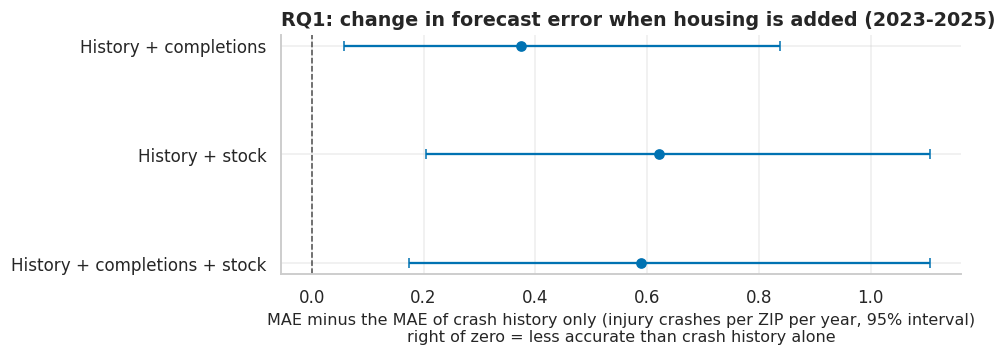

The change in out-of-time forecast error from adding affordable-housing completions and stock is +0.59 injury crashes per ZIP per year (95% interval +0.17 to +1.11, n = 172 ZIP codes). The interval lies above zero, which fits a less accurate forecast. Fitted on 860 ZIP-years (2018-2022) and scored on 516; crash history alone misses by 19.82 injury crashes against an average of 212, so the change is +3.0% of the baseline error.

In [72]:
HISTORY_FEATURES = [f"injury_crashes_lag{lag}" for lag in range(1, FORECAST_LAGS + 1)]
COMPLETION_FEATURES = [f"affordable_units_lag{lag}" for lag in range(1, FORECAST_LAGS + 1)]
FORECAST_FEATURE_SETS = {
    "Crash history only": HISTORY_FEATURES,
    "History + completions": HISTORY_FEATURES + COMPLETION_FEATURES,
    "History + stock": HISTORY_FEATURES + ["affordable_stock_lag1"],
    "History + completions + stock": HISTORY_FEATURES + COMPLETION_FEATURES + ["affordable_stock_lag1"],
}
FORECAST_BASELINE = next(iter(FORECAST_FEATURE_SETS))
FORECAST_FULL = list(FORECAST_FEATURE_SETS)[-1]


def build_forecast_frame(panel, n_lags=FORECAST_LAGS):
    """One row per ZIP and year: the target and features shifted inside the ZIP (earlier years only)."""
    ordered = panel.sort_values(["zip", "year"]).reset_index(drop=True)
    by_zip = ordered.groupby("zip", sort=False)
    frame = ordered[["zip", "year", "borough", "injury_crashes"]].copy()
    for lag in range(1, n_lags + 1):
        frame[f"injury_crashes_lag{lag}"] = by_zip["injury_crashes"].shift(lag)
        frame[f"affordable_units_lag{lag}"] = by_zip["affordable_units_completed"].shift(lag)
    frame["affordable_stock_lag1"] = by_zip["cum_affordable_units"].shift(1)
    frame = frame.dropna().reset_index(drop=True)          # the first n_lags years have no history
    assert len(frame) == panel["zip"].nunique() * (panel["year"].nunique() - n_lags)
    return frame


def forecast_comparison(frame):
    """(summary, predictions) of the out-of-time comparison; adds the gap as % of the baseline MAE."""
    summary, predictions = time_split_evaluation(frame, "injury_crashes", FORECAST_FEATURE_SETS, "year",
                                                 FIRST_TEST_YEAR, cluster_column="zip")
    summary["difference_pct"] = PERCENT * summary["mae_minus_baseline"] / summary.loc[FORECAST_BASELINE, "mae"]
    return summary, predictions


forecast_frame = build_forecast_frame(zip_year)
forecast_summary, forecast_predictions = forecast_comparison(forecast_frame)
rq1 = forecast_summary.loc[FORECAST_FULL]
gaps = forecast_summary.drop(index=FORECAST_BASELINE)

fig, ax = plt.subplots(figsize=(9, 3.4))
interval_rows(ax, list(gaps.index), gaps["mae_minus_baseline"], gaps["low"], gaps["high"], color=PALETTE["housing"],
              title=f"RQ1: change in forecast error when housing is added ({FIRST_TEST_YEAR}-{YEAR_END})",
              xlabel=f"MAE minus the MAE of crash history only (injury crashes per ZIP per year, "
                     f"{CI_LEVEL:.0%} interval)\nright of zero = less accurate than crash history alone")
show(fig)

report("RQ1", "Does knowing a ZIP's affordable-housing completions improve an out-of-time forecast of its "
       "injury crashes?", "MAE difference (injury crashes per ZIP per year)",
       rq1["mae_minus_baseline"], rq1["low"], rq1["high"], int(rq1["n_test_clusters"]),
       unit="injury crashes per ZIP per year", n_unit="ZIP codes",
       subject="The change in out-of-time forecast error from adding affordable-housing completions and stock",
       above="a less accurate forecast", below="a more accurate forecast",
       extra=f"Fitted on {int(rq1['n_train']):,} ZIP-years ({forecast_frame['year'].min()}-{FIRST_TEST_YEAR - 1}) "
             f"and scored on {int(rq1['n_test']):,}; crash history alone misses by "
             f"{forecast_summary.loc[FORECAST_BASELINE, 'mae']:.2f} injury crashes against an average of "
             f"{forecast_predictions['injury_crashes'].mean():.0f}, so the change is "
             f"{rq1['difference_pct']:+.1f}% of the baseline error.")

Housing features did not improve the forecast in this split; the extra coefficients may simply
be fitted to noise in a few hundred ZIP-years (not tested). The interval keeps the fitted models
fixed, so it understates fitting uncertainty, and the result rests on one split and one linear
model; Section 9.6 repeats it on crashes with a reported ZIP only. A ZIP is large, so this says
little about the blocks next to a building, which RQ3 looks at directly.

### 8.2 RQ2. Within a ZIP over time, do injury crashes move as its stock of affordable units grows? (M1)

A two-way fixed-effects regression of log injury crashes on the cumulative units completed
(7.3): ZIP effects remove what is fixed about a ZIP, year effects remove citywide shocks such as
the 2020 break, and whole ZIPs are resampled. The headline is the stock slope, in % per
`UNITS_PER_STEP` units. A single slope cannot show timing, so a second regression enters the
yearly completions at leads and lags; the two leads are placebos (future units cannot affect
crashes). Benjamini-Hochberg (7.4) is applied to the three lags only, which are the tests read
as findings; the leads are diagnostics.

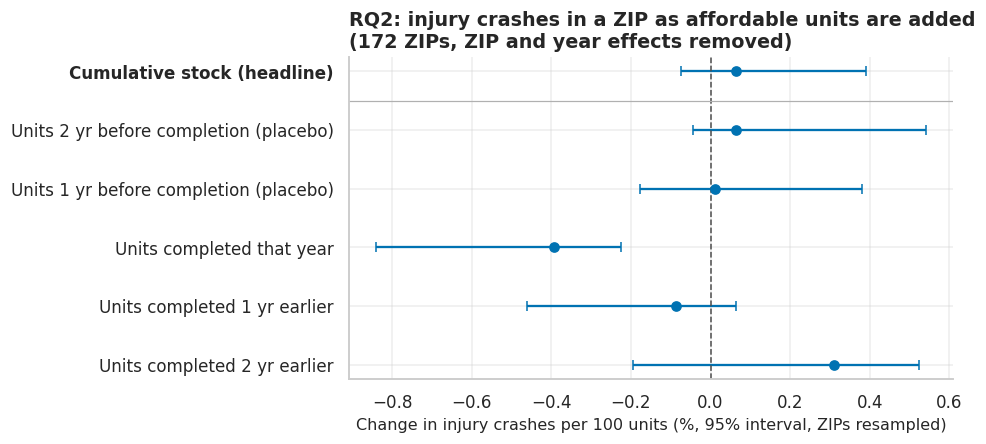

The within-ZIP change in injury crashes as the stock of completed affordable units grows is +0.06 percent per 100 units (95% interval -0.07 to +0.39, n = 172 ZIP codes). The interval includes zero. The stock grew in 143 ZIPs over 10 years. 0 of 2 placebo leads exclude zero; 1 of 3 lags pass Benjamini-Hochberg at 0.05. The completion-year slope is -0.39% (95% CI -0.84% to -0.22%) (adjusted p = 0.012); by kind of project it is new construction +0.38% (95% CI -0.46% to +1.28%); preservation -0.41% (95% CI -1.26% to -0.24%) (unadjusted).

In [73]:
def panel_matrix(panel, column):
    """ZIP-by-year matrix of one panel column (balanced)."""
    matrix = panel.pivot(index="zip", columns="year", values=column)
    assert matrix.notna().all().all(), "the ZIP by year panel must be balanced"
    return matrix.to_numpy(dtype=float)


def stock_regression(panel, completions_column="affordable_units_completed"):
    """(stock_slope, timing): slope on the cumulative stock, and joint lead/lag slopes on yearly completions.

    Both in percent change of injury crashes per UNITS_PER_STEP units; timing has one row per shift.
    """
    log_injury = np.log(panel_matrix(panel, "injury_crashes") + LOG_RATIO_OFFSET)
    stock = panel_matrix(panel, "cum_affordable_units") / UNITS_PER_STEP
    completions = panel_matrix(panel, completions_column) / UNITS_PER_STEP
    stock_slope = within_slope(log_injury, {"cumulative stock": stock}).iloc[0].copy()
    trimmed_outcome, shifted, kept_columns = lead_lag_panel(log_injury, completions, LEAD_LAG_SHIFTS)
    timing = within_slope(trimmed_outcome, shifted)
    timing["shift"] = sorted(LEAD_LAG_SHIFTS)
    timing["first_year"], timing["last_year"] = STUDY_YEARS[kept_columns[0]], STUDY_YEARS[kept_columns[-1]]
    is_lag = timing["shift"] >= 0
    timing["p_adjusted"] = np.nan
    timing.loc[is_lag, "p_adjusted"] = benjamini_hochberg(timing.loc[is_lag, "p_value"].to_numpy())
    for table in (stock_slope, timing):
        for column in ["estimate", "low", "high"]:
            table[f"{column}_pct"] = log_points_to_percent(table[column])
    stock_slope["zips_with_growth"] = int((stock[:, -1] > stock[:, 0]).sum())
    return stock_slope, timing


stock_slope, timing_slopes = stock_regression(zip_year)
same_year_by_kind = {kind: stock_regression(zip_year, column)[1].loc[shift_name(0)]
                     for kind, column in [("new construction", "new_construction_units"),
                                          ("preservation", "preservation_units")]}

# One chart: the headline stock slope on top, the timing slopes below it, on the same % scale.
timing_labels = [f"Units {-s} yr before completion (placebo)" if s < 0 else
                 ("Units completed that year" if s == 0 else f"Units completed {s} yr earlier")
                 for s in timing_slopes["shift"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
interval_rows(ax, ["Cumulative stock (headline)"] + timing_labels,
              np.r_[stock_slope["estimate_pct"], timing_slopes["estimate_pct"]],
              np.r_[stock_slope["low_pct"], timing_slopes["low_pct"]],
              np.r_[stock_slope["high_pct"], timing_slopes["high_pct"]], color=PALETTE["housing"],
              title=f"RQ2: injury crashes in a ZIP as affordable units are added\n"
                    f"({int(stock_slope['n_units'])} ZIPs, ZIP and year effects removed)",
              xlabel=f"Change in injury crashes per {UNITS_PER_STEP} units (%, {CI_LEVEL:.0%} interval, ZIPs resampled)")
ax.axhline(len(timing_labels) - 0.5, color=PALETTE["before"], linewidth=0.8)
ax.get_yticklabels()[0].set_fontweight("bold")
show(fig)

same_year = timing_slopes.loc[shift_name(0)]
leads, lags = timing_slopes[timing_slopes["shift"] < 0], timing_slopes[timing_slopes["shift"] >= 0]
report("RQ2", "Within a ZIP over time, do injury crashes move as the cumulative stock of completed affordable "
       "units grows?", f"% change in injury crashes per {UNITS_PER_STEP} units",
       stock_slope["estimate_pct"], stock_slope["low_pct"], stock_slope["high_pct"], int(stock_slope["n_units"]),
       unit=f"percent per {UNITS_PER_STEP} units", n_unit="ZIP codes",
       subject="The within-ZIP change in injury crashes as the stock of completed affordable units grows",
       above="more injury crashes in the years with a larger stock",
       below="fewer injury crashes in the years with a larger stock",
       extra=f"The stock grew in {int(stock_slope['zips_with_growth'])} ZIPs over {int(stock_slope['n_periods'])} "
             f"years. {int((leads['high'] < 0).sum() + (leads['low'] > 0).sum())} of {len(leads)} placebo leads "
             f"exclude zero; {int((lags['p_adjusted'] < FALSE_DISCOVERY_RATE).sum())} of {len(lags)} lags pass "
             f"Benjamini-Hochberg at {FALSE_DISCOVERY_RATE:.2f}. The completion-year slope is "
             f"{fmt_ci(same_year['estimate_pct'], same_year['low_pct'], same_year['high_pct'], 2, '%')} "
             f"(adjusted p = {same_year['p_adjusted']:.3f}); by kind of project it is "
             + "; ".join(f"{kind} {fmt_ci(row['estimate_pct'], row['low_pct'], row['high_pct'], 2, '%')}"
                         for kind, row in same_year_by_kind.items()) + " (unadjusted).")

A growing stock is not accompanied by a detectable movement in injury crashes, and the placebo
leads sit near zero, so there is no sign that ZIPs about to receive housing were already
diverging. The completion-year dip is the exception, but split by kind it belongs to
preservation, a financing date that brings no new residents (see RQ5), and it does not carry
into later years; with many unadjusted tests in this notebook it is reported, not counted as a
finding. A hundred units is a small change for a ZIP of tens of thousands of residents, so only
a large association could show up here.

### 8.3 RQ3. Do injury crashes within 250 m of a new building change after it is completed? (M2)

Injury crashes within `BUFFER_M` m of new-construction sites are compared over the
`EVENT_WINDOW` years before and after completion, against sites of the same programme not yet
completed in that window, over the same calendar years. A plain before/after would credit the
2020 citywide drop to the buildings. The screens of Section 5.4 apply (Section 9.2 tightens
them). The estimate is a difference-in-differences of log after/before ratios (7.1), compared
inside completion cohorts, weighted by treated counts and pooled because each cohort is small;
whole clusters of neighbouring sites are resampled.

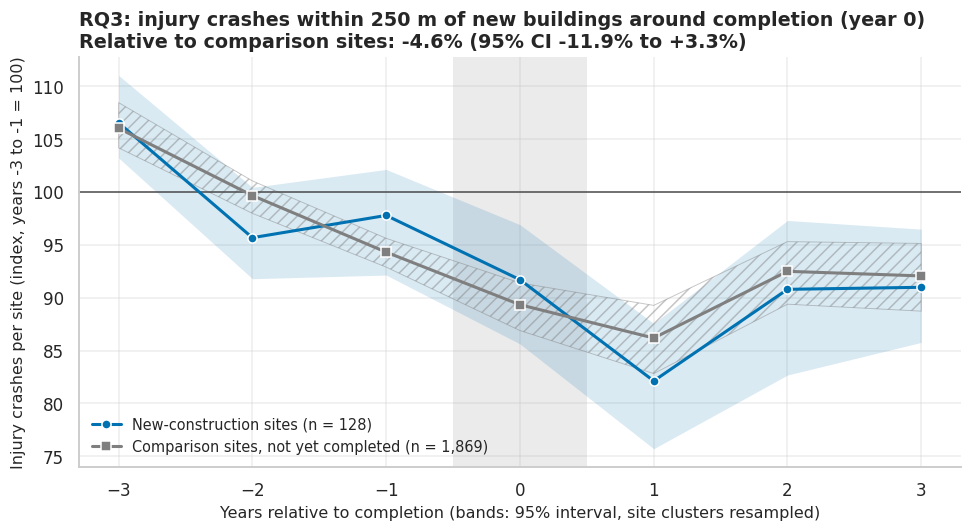

The after-against-before change in injury crashes within 250 m of new buildings, relative to comparison sites, is -4.6 percent (95% interval -11.9 to +3.3, n = 128 new-construction sites). The interval includes zero. It uses 1,869 comparison rows in 4 cohorts and 356 resampled clusters. Treated sites alone changed by -13.8% and comparison sites by -9.7%. The pre-period placebo (year -3 to -1) is +6.6% (95% CI -6.9% to +21.0%).

In [74]:
REL_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in REL_YEARS]
PRE_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in PRE_YEARS]
POST_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in POST_YEARS]


def build_event_sites(panel, count_column="injury_crashes"):
    """One row per clean site and cohort: counts by relative year and before/after totals."""
    clean = panel[~panel["contaminated"]]
    counts = clean.pivot(index=["site_id", "cohort"], columns="rel_year", values=count_column)
    counts.columns = [f"rel_{rel_year:+d}" for rel_year in counts.columns]
    attributes = cohort_unit_table(panel, ["cluster_id", "borough", "construction_type",
                                           "total_units"]).set_index(["site_id", "cohort"])
    table = attributes.join(counts[REL_COLUMNS], validate="one_to_one").reset_index()
    table["before"], table["after"] = table[PRE_COLUMNS].sum(axis=1), table[POST_COLUMNS].sum(axis=1)
    assert table[REL_COLUMNS].notna().all().all() and len(table) == len(counts)
    return table


def event_did(sample, before="before", after="after"):
    """Cohort-stratified DiD of the log after/before ratio, site clusters resampled."""
    return did_log_ratio(sample[before].to_numpy(), sample[after].to_numpy(), sample["treated"].to_numpy(),
                         strata=sample["cohort"].to_numpy(), clusters=sample["cluster_id"].to_numpy())


event_site_table = build_event_sites(event_panel)
new_build_sample = event_site_table[~event_site_table["treated"]
                                    | (event_site_table["construction_type"] == NEW_CONSTRUCTION)].reset_index(drop=True)
new_build_did = event_did(new_build_sample)
assert new_build_did["n_treated_dropped"] == 0 and new_build_did["n_control_dropped"] == 0
# Placebo inside the pre-period (first to last pre-year): nothing was completed in between.
pretrend_did = event_did(new_build_sample, before=PRE_COLUMNS[0], after=PRE_COLUMNS[-1])
new_build_profile = event_profile(new_build_sample[REL_COLUMNS], new_build_sample["treated"],
                                  new_build_sample["cohort"], new_build_sample["cluster_id"], len(PRE_YEARS))

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(PRE_PERIOD_INDEX, color=PALETTE["neutral"], linewidth=1)
ax.axvspan(-0.5, 0.5, color=PALETTE["before"], alpha=0.25, linewidth=0)
for group, color, marker, label in [("treated", PALETTE["treated"], "o", "New-construction sites"),
                                    ("comparison", PALETTE["control"], "s", "Comparison sites, not yet completed")]:
    line = new_build_profile[group]
    # Treated band filled, comparison band hatched, so their overlap stays readable.
    band = {"color": color, "alpha": 0.15} if group == "treated" else \
        {"facecolor": "none", "edgecolor": color, "hatch": "///", "alpha": 0.45}
    ax.fill_between(REL_YEARS, line["low"], line["high"], linewidth=0.6 * (group != "treated"), **band)
    ax.plot(REL_YEARS, line["index"], color=color, marker=marker, linewidth=2, markeredgecolor="white",
            label=f"{label} (n = {line['n_sites']:,})")
ax.set_xticks(REL_YEARS)
ax.legend(loc="lower left")
finish(ax, f"RQ3: injury crashes within {BUFFER_M} m of new buildings around completion (year 0)\n"
           f"Relative to comparison sites: {fmt_ci(new_build_did['percent_change'], new_build_did['percent_low'], new_build_did['percent_high'], 1, '%')}",
       f"Years relative to completion (bands: {CI_LEVEL:.0%} interval, site clusters resampled)",
       f"Injury crashes per site (index, years -{EVENT_WINDOW} to -1 = {PRE_PERIOD_INDEX})")
show(fig)

report("RQ3", f"Do injury crashes within {BUFFER_M} m of new-construction sites change after completion, "
       "relative to not-yet-completed sites?", "% change relative to comparison sites",
       new_build_did["percent_change"], new_build_did["percent_low"], new_build_did["percent_high"],
       new_build_did["n_treated"], unit="percent", n_unit="new-construction sites", digits=1,
       subject=f"The after-against-before change in injury crashes within {BUFFER_M} m of new buildings, "
               f"relative to comparison sites,",
       above="more injury crashes after completion than the comparison sites would suggest",
       below="fewer injury crashes after completion than the comparison sites would suggest",
       extra=f"It uses {new_build_did['n_control']:,} comparison rows in {new_build_did['n_strata']} cohorts and "
             f"{new_build_did['n_clusters']:,} resampled clusters. Treated sites alone changed by "
             f"{log_points_to_percent(new_build_did['treated_change']):+.1f}% and comparison sites by "
             f"{log_points_to_percent(new_build_did['control_change']):+.1f}%. The pre-period placebo "
             f"(year {PRE_YEARS[0]} to {PRE_YEARS[-1]}) is "
             f"{fmt_ci(pretrend_did['percent_change'], pretrend_did['percent_low'], pretrend_did['percent_high'], 1, '%')}.")

The two lines move together: most of the fall at new buildings also happened at comparison
streets, and what remains has an interval that includes zero. No change is detectable, but the
interval holds a moderate fall as well as a small rise, so this is not evidence of no change. The
pre-period placebo is wider than the main interval (Section 9.3 gives a narrower one).
Limits: the "before" years are largely construction years; the screened sites are the less
densely built part of the programme (Section 9.2 looks at dense clusters); and cohorts are the
only strata, while comparison sites spread differently across boroughs (Section 9.4).

### 8.4 RQ4. Does the change around a new building grow with the size of the building? (M2)

If new residents change the street, a tower should leave a bigger mark than a house. Each
treated site's log ratio minus the mean of its cohort's comparison sites (which removes the
calendar years, as in RQ3) is regressed on log2 of the units completed that year within the
buffer, own building included, since neighbours finished together are one event (5.4). The
slope reads per doubling. The comparison means are recomputed in every resample. One slope was
preferred to size bins: it uses every site once, needs no bin edges and is a single test.

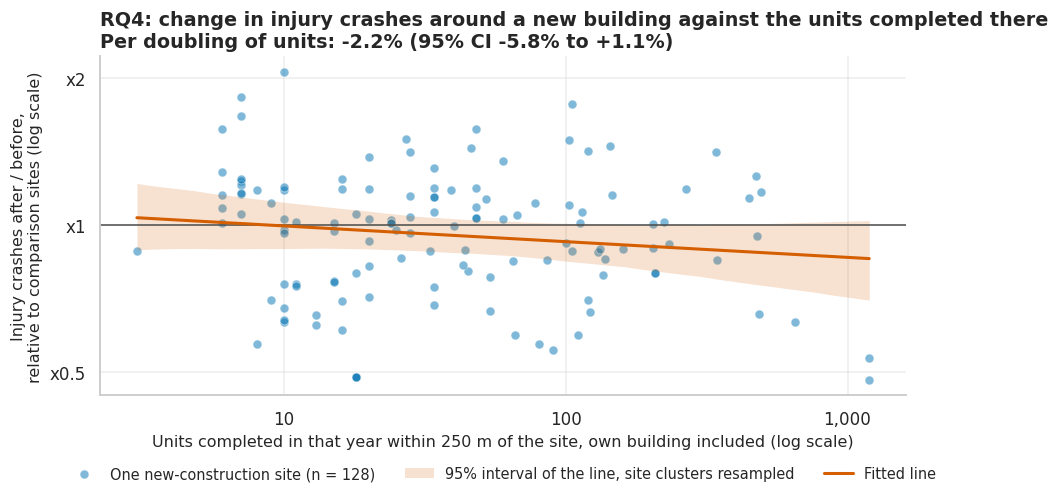

The slope of the after-against-before change in injury crashes on the units completed in that year within 250 m is -2.2 percent per doubling of units (95% interval -5.8 to +1.1, n = 128 new-construction sites). The interval includes zero. Units completed nearby range from 3 to 1,194 (median 34); 44 (34.4%) sites share their event with another building; 356 clusters are resampled.

In [75]:
def cohort_adjusted_change(change, treated, cohort_codes, n_cohorts):
    """Each site's log ratio minus the mean log ratio of its cohort's comparison sites."""
    comparison_n = np.bincount(cohort_codes[~treated], minlength=n_cohorts)
    comparison_sum = np.bincount(cohort_codes[~treated], weights=change[~treated], minlength=n_cohorts)
    # A resample can leave a cohort without comparison sites; its treated sites get NaN there.
    comparison_mean = np.where(comparison_n > 0, comparison_sum / np.maximum(comparison_n, 1), np.nan)
    return change - comparison_mean[cohort_codes]


def add_event_units(sample, site_frame, radius_m=BUFFER_M):
    """Add `event_units` (units completed in the cohort year within radius, own building included)
    and `event_buildings` to the treated rows; comparison rows get NaN and 0."""
    first, second = site_neighbour_pairs(site_frame, radius_m)     # includes each site with itself
    neighbours = pd.DataFrame({"site_id": first,
                               "cohort": site_frame["completion_year"].astype("float64").to_numpy()[second],
                               "units": site_frame["total_units"].to_numpy(dtype=float)[second]})
    per_event = (neighbours.dropna(subset=["cohort"]).groupby(["site_id", "cohort"])["units"]
                 .agg(event_units="sum", event_buildings="size").reset_index())
    is_treated = sample["treated"].to_numpy()
    keys = sample.loc[is_treated, ["site_id", "cohort"]].astype({"site_id": "int64", "cohort": "float64"})
    matched = keys.merge(per_event.astype({"site_id": "int64"}), on=["site_id", "cohort"], how="left",
                         validate="one_to_one")
    event_units, event_buildings = np.full(len(sample), np.nan), np.zeros(len(sample), dtype=np.int64)
    event_units[is_treated] = matched["event_units"].to_numpy()
    event_buildings[is_treated] = matched["event_buildings"].to_numpy(dtype=np.int64)
    assert (event_units[is_treated] >= sample.loc[is_treated, "total_units"].to_numpy()).all()
    return sample.assign(event_units=event_units, event_buildings=event_buildings)


def dose_response(sample, n_grid=DOSE_GRID_POINTS):
    """Slope of the cohort-adjusted log ratio on log2(event units) among treated sites, with a fitted band."""
    change = log_ratio(sample["before"].to_numpy(), sample["after"].to_numpy())
    treated = sample["treated"].to_numpy()
    cohort_codes, cohort_labels = pd.factorize(sample["cohort"])
    log_units = np.log2(np.where(treated, sample["event_units"].to_numpy(dtype=float), 1.0))   # 1 = placeholder
    grid = np.linspace(log_units[treated].min(), log_units[treated].max(), n_grid)

    def slope_and_line(change_rows, treated_rows, cohort_rows, log_unit_rows):
        """[slope, fitted value at each grid point] on one resample."""
        adjusted = cohort_adjusted_change(change_rows, treated_rows, cohort_rows, len(cohort_labels))
        usable = treated_rows & ~np.isnan(adjusted)
        if usable.sum() < MIN_GROUP_N:
            return np.full(1 + n_grid, np.nan)
        slope = linear_slope(log_unit_rows[usable], adjusted[usable])
        intercept = adjusted[usable].mean() - slope * log_unit_rows[usable].mean()
        return np.r_[slope, intercept + slope * grid]

    boot = bootstrap_ci(slope_and_line, change, treated, cohort_codes, log_units,
                        clusters=sample["cluster_id"].to_numpy())
    adjusted = cohort_adjusted_change(change, treated, cohort_codes, len(cohort_labels))
    return {"estimate": float(boot["estimate"][0]), "low": float(boot["low"][0]), "high": float(boot["high"][0]),
            "n_treated": int(treated.sum()), "n_clusters": boot["n_clusters"],
            "points": pd.DataFrame({"units": sample.loc[treated, "event_units"].to_numpy(dtype=float),
                                    "adjusted_change": adjusted[treated]}),
            "line": pd.DataFrame({"units": 2.0 ** grid, "fit": boot["estimate"][1:],
                                  "low": boot["low"][1:], "high": boot["high"][1:]})}


dose_sample = add_event_units(new_build_sample, sites)
dose = dose_response(dose_sample)
dose_pct = {key: float(log_points_to_percent(dose[key])) for key in ["estimate", "low", "high"]}
points, line = dose["points"], dose["line"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axhline(0, color=PALETTE["neutral"], linewidth=1)
ax.scatter(points["units"], points["adjusted_change"], s=34, color=PALETTE["treated"], alpha=0.5,
           edgecolor="white", linewidth=0.6, label=f"One new-construction site (n = {len(points)})")
ax.fill_between(line["units"], line["low"], line["high"], color=PALETTE["crash"], alpha=0.18, linewidth=0,
                label=f"{CI_LEVEL:.0%} interval of the line, site clusters resampled")
ax.plot(line["units"], line["fit"], color=PALETTE["crash"], linewidth=2, label="Fitted line")
ax.set_xscale("log")
thousands(ax, axis="x")
ticks = [t for t in RATIO_TICKS if points["adjusted_change"].min() - 0.3 <= np.log(t) <= points["adjusted_change"].max() + 0.3]
ax.set_yticks(np.log(ticks), [f"x{t:g}" for t in ticks])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
finish(ax, f"RQ4: change in injury crashes around a new building against the units completed there\n"
           f"Per doubling of units: {fmt_ci(dose_pct['estimate'], dose_pct['low'], dose_pct['high'], 1, '%')}",
       f"Units completed in that year within {BUFFER_M} m of the site, own building included (log scale)",
       "Injury crashes after / before,\nrelative to comparison sites (log scale)")
show(fig)

report("RQ4", "Does the before/after change in injury crashes at a new-construction site scale with the number "
       "of units?", "% change per doubling of units", dose_pct["estimate"], dose_pct["low"], dose_pct["high"],
       dose["n_treated"], unit="percent per doubling of units", n_unit="new-construction sites", digits=1,
       subject=f"The slope of the after-against-before change in injury crashes on the units completed in that "
               f"year within {BUFFER_M} m",
       above="a larger rise (or smaller fall) in injury crashes where more units were completed",
       below="a larger fall (or smaller rise) in injury crashes where more units were completed",
       extra=f"Units completed nearby range from {int(points['units'].min())} to {int(points['units'].max()):,} "
             f"(median {points['units'].median():.0f}); "
             f"{n_pct((dose_sample['event_buildings'] > 1).sum(), dose['n_treated'])} sites share their event with "
             f"another building; {dose['n_clusters']:,} clusters are resampled.")

No relation with size is detectable: at every size the sites scatter far more widely than any
tilt of the line. The smallest and largest events lie several doublings apart, so a narrow
interval per doubling still allows a sizeable difference between them. Units only stand in for
residents (no counts of residents, trips or cars exist), many buildings are small, and the screen
of 5.4 tends to remove large projects built in groups, so the remaining large buildings may not be
typical.

### 8.5 RQ5. Is the change different for new construction than for preservation? (M3)

Preservation refinances or renovates an occupied building, so nobody new arrives: it is a
**negative control**. A change that comes with new residents should appear around new
construction and not around preservation; if both show it, it belongs to something else (the
kind of street, or the calendar years). Both types are compared with the same comparison sites
using RQ3's design, and `type_contrast` (7.1) recomputes both estimates in one bootstrap, so the
interval of their difference accounts for the shared comparison sites. Subtracting two separate
bootstraps would treat them as independent and overstate the width.

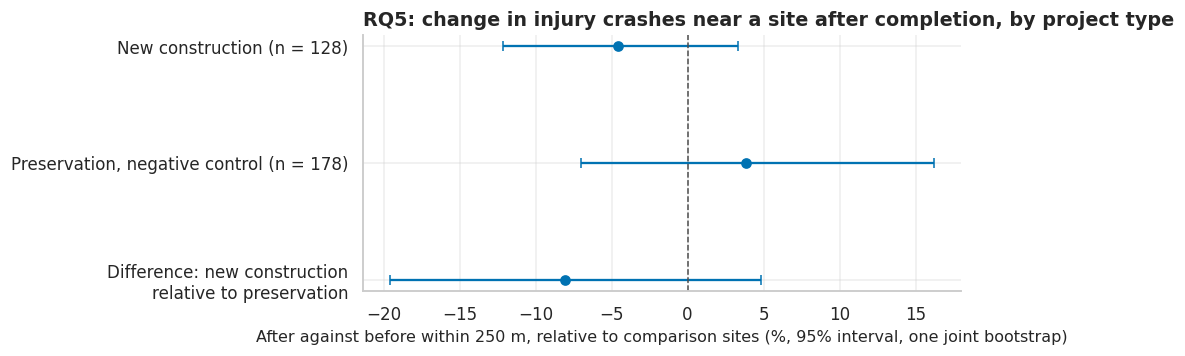

The after-to-before ratio of injury crashes around new construction, relative to the same ratio around preservation, is -8.1 percent (95% interval -19.6 to +4.9, n = 306 completed sites). The interval includes zero. Preservation alone: +3.8% (95% CI -7.0% to +16.2%), with 70% of its sites in the 2019 cohort. The new-construction interval differs slightly from RQ3's because the joint bootstrap also draws clusters holding only preservation sites.

In [76]:
CONTRAST_NAMES = [NEW_CONSTRUCTION, PRESERVATION, "New construction relative to preservation"]
treated = event_site_table["treated"].to_numpy()
construction = event_site_table["construction_type"].astype(str).to_numpy()
assert set(construction[treated]) <= {NEW_CONSTRUCTION, PRESERVATION}
arm = np.where(~treated, 0, np.where(construction == NEW_CONSTRUCTION, 1, 2))    # 0 = comparison
contrast = type_contrast(event_site_table["before"], event_site_table["after"], arm,
                                event_site_table["cohort"], event_site_table["cluster_id"])
rq5_contrast = pd.DataFrame.from_dict(
    {name: {"estimate_pct": row["percent_change"], "low_pct": row["percent_low"], "high_pct": row["percent_high"],
            "p_value": row["p_value"], "n_treated": row["n_treated"], "n_comparison": row["n_control"],
            "n_clusters": row["n_clusters"]} for name, row in zip(CONTRAST_NAMES, contrast.values())},
    orient="index").rename_axis("contrast")
assert np.isclose(rq5_contrast.loc[NEW_CONSTRUCTION, "estimate_pct"], new_build_did["percent_change"]), \
    "the new-construction row must reproduce RQ3"

fig, ax = plt.subplots(figsize=(9, 3.4))
interval_rows(ax, [f"New construction (n = {rq5_contrast['n_treated'].iloc[0]})",
                   f"Preservation, negative control (n = {rq5_contrast['n_treated'].iloc[1]})",
                   "Difference: new construction\nrelative to preservation"],
              rq5_contrast["estimate_pct"], rq5_contrast["low_pct"], rq5_contrast["high_pct"],
              color=PALETTE["treated"],
              title="RQ5: change in injury crashes near a site after completion, by project type",
              xlabel=f"After against before within {BUFFER_M} m, relative to comparison sites "
                     f"(%, {CI_LEVEL:.0%} interval, one joint bootstrap)")
show(fig)

rq5 = rq5_contrast.loc[CONTRAST_NAMES[2]]
preserved_by_cohort = event_site_table[treated & (construction == PRESERVATION)].groupby("cohort").size()
report("RQ5", "Is the before/after change in injury crashes different near New Construction than near "
       "Preservation (the negative control)?", "% difference between the two after/before ratios",
       rq5["estimate_pct"], rq5["low_pct"], rq5["high_pct"], int(rq5["n_treated"]),
       unit="percent", n_unit="completed sites", digits=1,
       subject="The after-to-before ratio of injury crashes around new construction, relative to the same "
               "ratio around preservation,",
       above="a more positive change around new construction than around preservation",
       below="a more negative change around new construction than around preservation",
       extra=f"Preservation alone: {fmt_ci(*rq5_contrast.loc[PRESERVATION, ['estimate_pct', 'low_pct', 'high_pct']], 1, '%')}, "
             f"with {pct(preserved_by_cohort.max(), preserved_by_cohort.sum()):.0f}% of its sites in the "
             f"{preserved_by_cohort.idxmax()} cohort. The new-construction interval differs slightly from RQ3's "
             f"because the joint bootstrap also draws clusters holding only preservation sites.")

The two types cannot be told apart: each interval and the interval of their difference include
zero. The negative control is weak, though. It is imprecise, most of its sites come from one
cohort, its completion date is often an administrative date equal to the start date (Section
4.4), and preserved buildings stand on older, established streets unlike those of new
construction. The contrast is the least precise number of these five questions.

### 8.6 RQ6. Does the pedestrian and cyclist share of injury crashes near affordable-housing sites change after completion, by borough? (M3)

**Method.** RQ6, RQ8 and RQ10 ask whether the *mix* of injury crashes near a site shifts after
completion, so they share one design. For each clean (site, cohort) unit of Section 5 we count
injury crashes per category in the `EVENT_WINDOW` years before and after the completion year
(the year itself is skipped). The share change at completed sites minus the change at
not-yet-completed comparison sites of the same cohort is the gap; cohorts are averaged with the
treated crash counts as weights, and whole clusters are resampled. A plain before/after
comparison was rejected because the citywide victim mix moved in these years (pandemic, e-bikes).
Shares are pooled over sites, because a share at a site with two crashes can only be 0, ½ or 1.
Completed sites of both kinds are pooled to keep the sample usable, and each gap is repeated with
new construction alone (preservation brings no new residents, see 11).

In [77]:
PEDESTRIAN_CYCLIST_LABELS = ["Pedestrian or cyclist hurt", "Only vehicle occupants hurt"]
ALL_BOROUGHS_LABEL = "All boroughs"
COMPOSITION_UNIT_COLUMNS = ["cluster_id", "borough", "construction_type"]   # carried by every (site, cohort) unit


def period_category_counts(units, pairs, crash_frame, category_codes, n_categories, window=EVENT_WINDOW):
    """(before, after) injury-crash counts of shape (units, categories); a negative code leaves a crash out."""
    is_counted = crash_frame["is_injury_crash"].to_numpy() & (category_codes >= 0)
    near = pairs.loc[is_counted[pairs["crash_row"].to_numpy()], ["site_id", "crash_row"]]
    # A comparison site serves several cohorts, so this merge is many to many on purpose.
    near = near.merge(units[["site_id", "cohort"]].assign(unit=np.arange(len(units))), on="site_id")
    crash_rows = near["crash_row"].to_numpy()
    relative_year = crash_frame["year"].to_numpy()[crash_rows].astype(np.int64) - near["cohort"].to_numpy()
    cell = near["unit"].to_numpy() * n_categories + category_codes[crash_rows]
    size = len(units) * n_categories

    def period_counts(in_period):
        return np.bincount(cell[in_period], minlength=size).reshape(len(units), n_categories)

    return (period_counts((relative_year >= -window) & (relative_year <= -1)),
            period_counts((relative_year >= 1) & (relative_year <= window)))


def cohort_weighted_shifts(before, after, treated, cohort_codes, n_cohorts):
    """(3, categories) array: share change at treated sites, at comparison sites, and their gap.

    Cohorts in which either arm has no crashes in a period cannot be compared and are left out.
    """
    n_categories = before.shape[1]
    # Every count belongs to one (arm, cohort, category) cell; one bincount sums all cells at once.
    cell = ((treated.astype(np.int64) * n_cohorts + cohort_codes)[:, None] * n_categories
            + np.arange(n_categories)[None, :]).ravel()
    shape = (2, n_cohorts, n_categories)
    before_sums = np.bincount(cell, weights=before.ravel(), minlength=np.prod(shape)).reshape(shape)
    after_sums = np.bincount(cell, weights=after.ravel(), minlength=np.prod(shape)).reshape(shape)
    before_totals, after_totals = before_sums.sum(axis=2), after_sums.sum(axis=2)
    comparable = ((before_totals > 0) & (after_totals > 0)).all(axis=0)
    if not comparable.any():
        return np.full((3, n_categories), np.nan)
    change = (after_sums[:, comparable] / after_totals[:, comparable, None]
              - before_sums[:, comparable] / before_totals[:, comparable, None])
    treated_events = before_totals[1, comparable] + after_totals[1, comparable]   # arm 1 is the treated arm
    weights = treated_events / treated_events.sum()
    treated_change, comparison_change = (weights[:, None] * change[1]).sum(axis=0), (weights[:, None] * change[0]).sum(axis=0)
    return np.vstack([treated_change, comparison_change, treated_change - comparison_change])


def pooled_shares(counts, is_member):
    """Category shares in percent, pooled over the selected units."""
    totals = counts[is_member].sum(axis=0)
    return PERCENT * totals / totals.sum() if totals.sum() > 0 else np.full(counts.shape[1], np.nan)


def composition_shift(units, before, after, labels):
    """Gap in category shares (percentage points) with a cluster bootstrap; returns (table, summary).

    `low_joint`/`high_joint` widen the interval for the number of categories (Bonferroni): they
    are the interval to quote for a category picked after looking at all of them.
    """
    treated = units["treated"].to_numpy()
    cohort_codes, cohort_labels = pd.factorize(units["cohort"].to_numpy(), sort=True)
    n_categories = len(labels)
    boot = bootstrap_ci(lambda b, a, t, c: cohort_weighted_shifts(b, a, t, c, len(cohort_labels)).ravel(),
                        before, after, treated, cohort_codes, clusters=units["cluster_id"].to_numpy())
    joint_level = 1 - (1 - CI_LEVEL) / n_categories
    joint = percentile_ci(boot["replicates"], level=joint_level)
    points = {key: PERCENT * np.asarray(values).reshape(3, n_categories) for key, values in
              [("estimate", boot["estimate"]), ("low", boot["low"]), ("high", boot["high"]),
               ("low_joint", joint["low"]), ("high_joint", joint["high"])]}
    p_values = np.asarray(boot["p_value"]).reshape(3, n_categories)[2]
    table = pd.DataFrame({
        "treated_before": pooled_shares(before, treated), "treated_after": pooled_shares(after, treated),
        "comparison_before": pooled_shares(before, ~treated), "comparison_after": pooled_shares(after, ~treated),
        "treated_change": points["estimate"][0], "comparison_change": points["estimate"][1],
        "gap": points["estimate"][2], "low": points["low"][2], "high": points["high"][2],
        "low_joint": points["low_joint"][2], "high_joint": points["high_joint"][2],
        "p_value": p_values, "p_adjusted": benjamini_hochberg(p_values),
    }, index=pd.Index(labels, name="category"))
    table["flagged"] = table["p_adjusted"] < FALSE_DISCOVERY_RATE
    summary = {"n_treated_sites": int(units.loc[treated, "site_id"].nunique()),
               "n_comparison_sites": int(units.loc[~treated, "site_id"].nunique()),
               "n_clusters": boot["n_clusters"], "joint_level": joint_level,
               "treated_crashes": int(before[treated].sum() + after[treated].sum())}
    return table, summary


def units_of_kind(kind):
    """Mask of event units with the treated group limited to one kind (comparison units all stay)."""
    return (~event_units["treated"] | (event_units["construction_type"] == kind)).to_numpy()


def new_construction_line(before, after, labels, category):
    """One sentence: the gap of `category` with only new-construction sites as the treated group."""
    keep = units_of_kind(NEW_CONSTRUCTION)
    table, summary = composition_shift(event_units[keep], before[keep], after[keep], labels)
    row = table.loc[category]
    return (f"With only new-construction sites treated ({summary['n_treated_sites']:,} sites) the gap is "
            f"{row['gap']:+.2f} points ({CI_LEVEL:.0%} interval {row['low']:+.2f} to {row['high']:+.2f}).")


event_units = cohort_unit_table(event_panel, COMPOSITION_UNIT_COLUMNS)

For RQ6 the two categories are "a pedestrian or cyclist was hurt" and "only vehicle occupants were
hurt". A borough is estimated only with at least `MIN_GROUP_N` completed and comparison sites, and
the borough p-values are adjusted together (Benjamini-Hochberg), because several boroughs give
chance several tries.

In [78]:
rq6_before, rq6_after = period_category_counts(event_units, site_pairs, crashes,
                                               np.where(crashes["ped_cyc_harm"].to_numpy(), 0, 1), 2)
rq6_rows, rq6_samples = {}, {}
for area in [ALL_BOROUGHS_LABEL, *BOROUGHS]:
    in_area = (np.ones(len(event_units), bool) if area == ALL_BOROUGHS_LABEL
               else (event_units["borough"] == area).to_numpy())
    area_units = event_units[in_area]
    n_treated = int(area_units["treated"].sum())
    n_comparison = int(area_units.loc[~area_units["treated"], "site_id"].nunique())
    rq6_samples[area] = {"n_treated_sites": n_treated, "n_comparison_sites": n_comparison}
    if min(n_treated, n_comparison) < MIN_GROUP_N:
        continue
    table, summary = composition_shift(area_units, rq6_before[in_area], rq6_after[in_area], PEDESTRIAN_CYCLIST_LABELS)
    rq6_rows[area] = table.loc[PEDESTRIAN_CYCLIST_LABELS[0]].drop(["p_adjusted", "flagged", "low_joint", "high_joint"])
    rq6_samples[area].update(summary)
rq6_table = pd.DataFrame(rq6_rows).T.astype(float)
is_borough_row = rq6_table.index != ALL_BOROUGHS_LABEL
rq6_table.loc[is_borough_row, "p_adjusted"] = benjamini_hochberg(rq6_table.loc[is_borough_row, "p_value"].to_numpy())
show_table(rq6_table[["treated_before", "comparison_before", "treated_change", "comparison_change",
                      "gap", "low", "high", "p_value", "p_adjusted"]].round(2))

,treated_before,comparison_before,treated_change,comparison_change,gap,low,high,p_value,p_adjusted
All boroughs,37.630,43.860,-0.210,-1.430,1.220,-1.080,3.390,0.330,NaN
Bronx,30.600,29.480,-1.010,-2.100,1.080,-3.490,5.610,0.660,0.780
Brooklyn,41.100,40.320,0.930,-0.940,1.870,-0.890,7.050,0.190,0.750
Manhattan,49.850,57.760,-2.500,-1.770,-0.720,-4.350,3.430,0.780,0.780
Queens,36.580,42.530,-0.310,0.350,-0.660,-5.460,3.820,0.740,0.780


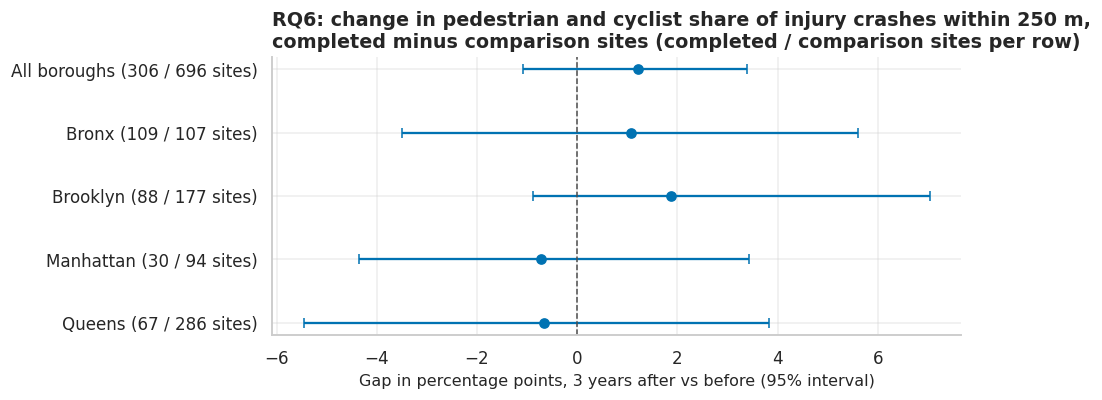

In [79]:
fig, ax = plt.subplots(figsize=(9, 3.8))
interval_rows(ax, [f"{area} ({rq6_samples[area]['n_treated_sites']} / {rq6_samples[area]['n_comparison_sites']} sites)"
                   for area in rq6_table.index], rq6_table["gap"], rq6_table["low"], rq6_table["high"],
              title=f"RQ6: change in pedestrian and cyclist share of injury crashes within {BUFFER_M} m,\n"
                    f"completed minus comparison sites (completed / comparison sites per row)",
              xlabel=f"Gap in percentage points, {EVENT_WINDOW} years after vs before ({CI_LEVEL:.0%} interval)")
show(fig)

In [80]:
rq6_city, rq6_sample = rq6_table.loc[ALL_BOROUGHS_LABEL], rq6_samples[ALL_BOROUGHS_LABEL]
rq6_skipped = [area for area in BOROUGHS if area not in rq6_table.index]
report("RQ6", "Does the pedestrian and cyclist share of injury crashes near sites change after completion?",
       "percentage points, completed minus comparison sites",
       rq6_city["gap"], rq6_city["low"], rq6_city["high"], rq6_sample["n_treated_sites"],
       unit="percentage points",
       n_unit=f"completed sites, against {rq6_sample['n_comparison_sites']:,} comparison sites, in "
              f"{rq6_sample['n_clusters']:,} clusters",
       subject="The gap in the pedestrian and cyclist share of injury crashes (completed minus comparison sites)",
       above="a larger rise in that share around completed buildings",
       below="a smaller rise in that share around completed buildings",
       extra=f"Borough gaps run from {rq6_table.loc[is_borough_row, 'gap'].min():+.1f} to "
             f"{rq6_table.loc[is_borough_row, 'gap'].max():+.1f} points; smallest adjusted p = "
             f"{rq6_table['p_adjusted'].min():.2f}. Not estimated (fewer than {MIN_GROUP_N} sites): "
             f"{', '.join(rq6_skipped) or 'none'}. "
             + new_construction_line(rq6_before, rq6_after, PEDESTRIAN_CYCLIST_LABELS, PEDESTRIAN_CYCLIST_LABELS[0]))

The gap in the pedestrian and cyclist share of injury crashes (completed minus comparison sites) is +1.22 percentage points (95% interval -1.08 to +3.39, n = 306 completed sites, against 696 comparison sites, in 409 clusters). The interval includes zero. Borough gaps run from -0.7 to +1.9 points; smallest adjusted p = 0.75. Not estimated (fewer than 30 sites): Staten Island. With only new-construction sites treated (128 sites) the gap is +1.16 points (95% interval -1.35 to +3.71).

**Reading.** The share changed little around completed sites and fell slightly more around
comparison sites; the gap's interval crosses zero citywide, no borough gap survives the
adjustment, and new construction alone gives almost the same gap. A real shift smaller than the
interval width (a few points) would not be visible. The design allows the two groups to start at
different levels and assumes only that they would have moved alike. The flag misses e-scooter
riders and the clean sites are the less dense part of the programme (see 11).

### 8.7 RQ7. Before the project starts, are affordable-housing sites already on streets with more injury crashes than typical street locations of the same borough? (M4)

**Method.** There is no street map in the two datasets, so "typical street locations" are a
regular grid of points `REFERENCE_SPACING_M` apart, kept when any crash was reported within
`STREET_SNAP_M` m (that drops water, parks and airports). Every grid point and every site gets the
number of injury crashes within `BUFFER_M` m in the baseline years `BASELINE_YEARS`, and each site
is ranked (midrank percentile) among the grid points of its borough. Only sites started after the
baseline are used, so a new building cannot have affected its own count; the headline is new
construction. Typical locations would average `NEUTRAL_PERCENTILE`. Sites linked within 250 m
(the clusters of Section 5) share almost the same buffer, so whole clusters are resampled; a
few clusters chain through whole neighbourhoods, which makes this the cautious interval.
Alternative rejected: a cell-level correlation of units and crashes mostly measures that both are
absent from parks. The ranking within the site's own ZIP code separates neighbourhood from street.
This counts injury crashes; it is not a rate per traveller, so it says "more injury crashes", not
"more dangerous", and the benchmark is street points, not other apartment buildings.

In [81]:
REFERENCE_SPACING_M = BUFFER_M     # one buffer radius, so neighbouring reference buffers overlap
STREET_SNAP_M = 100                # metres; a point is "on a street" if a crash was ever reported this close
PERCENTILE_BIN_WIDTH = 10          # percentile points per bin of the RQ7 histogram
RQ7_BOOTSTRAP_UNIT = "cluster_id"  # sites linked within BUFFER_M (Section 5) are resampled together
RQ7_NEW = "New construction, ranked in the borough"
RQ7_POOLED = "Both kinds pooled, ranked in the borough"
RQ7_WITHIN_ZIP = "New construction, ranked in its own ZIP code"


def reference_street_points(crash_frame, tree, tree_rows):
    """Grid points on the street network, with borough and ZIP of the nearest crash."""
    lat_step = REFERENCE_SPACING_M / METRES_PER_DEGREE
    lon_step = lat_step / math.cos(math.radians(MID_LATITUDE_DEG))   # same spacing in metres both ways
    grid_lat, grid_lon = (axis.ravel() for axis in np.meshgrid(np.arange(*NYC_BOUNDS["lat"], lat_step),
                                                               np.arange(*NYC_BOUNDS["lon"], lon_step), indexing="ij"))
    distance, nearest = tree.query(to_radians(grid_lat, grid_lon), k=1)
    on_street = distance[:, 0] * EARTH_RADIUS_M <= STREET_SNAP_M
    nearest_crash = crash_frame.iloc[tree_rows[nearest[on_street, 0]]]
    points = pd.DataFrame({"lat": grid_lat[on_street], "lon": grid_lon[on_street],
                           "borough": nearest_crash["borough"].to_numpy(),
                           "zip": nearest_crash["zip"].astype(object).to_numpy()})
    return points.dropna(subset=["borough"]).reset_index(drop=True)


def midrank_percentile(values, reference_values):
    """Percentile of each value within the reference, ties counted as half below (so the reference averages 50)."""
    ordered = np.sort(np.asarray(reference_values))
    below = np.searchsorted(ordered, values, side="left")
    below_or_equal = np.searchsorted(ordered, values, side="right")
    return PERCENT * (below + below_or_equal) / (2 * len(ordered))


def percentile_within_groups(values, groups, reference_values, reference_groups):
    """Midrank percentile among the reference values of the same group; NaN for groups under MIN_GROUP_N."""
    percentiles = np.full(len(values), np.nan)
    groups = np.asarray(groups, dtype=object)
    for group, reference in pd.Series(np.asarray(reference_values)).groupby(np.asarray(reference_groups, dtype=object)):
        in_group = groups == group
        if len(reference) >= MIN_GROUP_N and in_group.any():
            percentiles[in_group] = midrank_percentile(np.asarray(values)[in_group], reference.to_numpy())
    return percentiles


# Baseline injury crashes within BUFFER_M of every reference point and of every site started after the baseline.
in_baseline = (crashes["is_injury_crash"] & crashes["is_located"] & crashes["year"].between(*BASELINE_YEARS)).to_numpy()
baseline_tree = build_haversine_tree(crashes["lat"].to_numpy()[in_baseline], crashes["lon"].to_numpy()[in_baseline])
rq7_reference = reference_street_points(crashes, crash_tree, crash_tree_rows)
rq7_sites = sites[sites["start_year"] > BASELINE_YEARS[1]].copy()
for frame in (rq7_reference, rq7_sites):
    frame["baseline_crashes"] = baseline_tree.query_radius(to_radians(frame["lat"].to_numpy(), frame["lon"].to_numpy()),
                                                           BUFFER_M / EARTH_RADIUS_M, count_only=True)
for column, group in [("borough_percentile", "borough"), ("zip_percentile", "zip")]:
    rq7_sites[column] = percentile_within_groups(rq7_sites["baseline_crashes"], rq7_sites[group],
                                                 rq7_reference["baseline_crashes"], rq7_reference[group])
assert rq7_sites["borough_percentile"].notna().all()

# Three specifications, each with whole linked clusters resampled.
is_rq7_new = (rq7_sites["construction_type"].astype(str) == NEW_CONSTRUCTION).to_numpy()
rq7_rows = {}
for name, column, used in [(RQ7_NEW, "borough_percentile", is_rq7_new),
                           (RQ7_POOLED, "borough_percentile", np.ones(len(rq7_sites), bool)),
                           (RQ7_WITHIN_ZIP, "zip_percentile", is_rq7_new & rq7_sites["zip_percentile"].notna().to_numpy())]:
    boot = bootstrap_ci(mean_percentile_excess, rq7_sites.loc[used, column].to_numpy(),
                        clusters=rq7_sites.loc[used, RQ7_BOOTSTRAP_UNIT].to_numpy())
    rq7_rows[name] = {"estimate": boot["estimate"], "low": boot["low"], "high": boot["high"],
                      "n_sites": boot["n"], "units_resampled": boot["n_clusters"]}
rq7_estimates = pd.DataFrame(rq7_rows).T.astype(float).astype({"n_sites": int, "units_resampled": int})
rq7_estimates["bootstrap_unit"] = RQ7_BOOTSTRAP_UNIT
show_table(rq7_estimates.round(2))

by_borough = rq7_sites.groupby("borough", observed=True)
rq7_by_borough = pd.DataFrame({
    "reference_points": rq7_reference.groupby("borough", observed=True).size(),
    "median_crashes_reference": rq7_reference.groupby("borough", observed=True)["baseline_crashes"].median(),
    "sites": by_borough.size(),
    "median_crashes_sites": by_borough["baseline_crashes"].median(),
    "mean_percentile_sites": by_borough["borough_percentile"].mean(),
    "share_above_borough_median_pct": by_borough["borough_percentile"].apply(
        lambda values: PERCENT * (values > NEUTRAL_PERCENTILE).mean()),
})
show_table(rq7_by_borough.round(1))

,estimate,low,high,n_sites,units_resampled,bootstrap_unit
"New construction, ranked in the borough",19.990,10.390,23.060,2789,350,cluster_id
"Both kinds pooled, ranked in the borough",15.510,5.680,20.490,4879,458,cluster_id
"New construction, ranked in its own ZIP code",8.390,4.840,12.050,2662,315,cluster_id


,reference_points,median_crashes_reference,sites,median_crashes_sites,mean_percentile_sites,share_above_borough_median_pct
borough,,,,,,
Bronx,1430,34.000,1569,55.000,67.800,78.400
Brooklyn,2517,41.000,1826,64.000,69.000,80.400
Manhattan,878,64.000,778,68.000,54.600,53.000
Queens,3748,22.000,598,38.000,65.200,70.600
Staten Island,1412,7.000,108,7.000,54.000,44.400


The chart shows how new-construction sites rank: the share of sites in each tenth of the
borough's street points (blue), and the same sites ranked inside their own ZIP code (orange).
Typical street locations would give the flat dashed line.

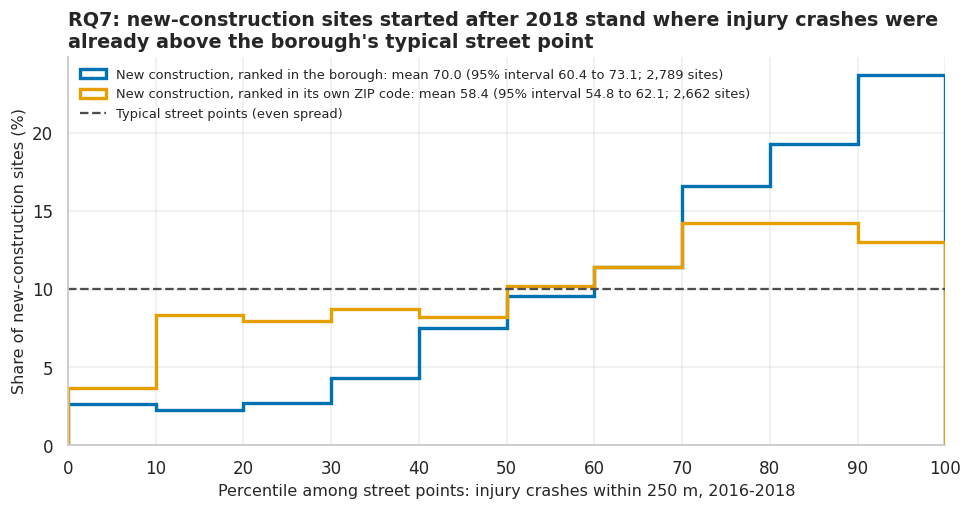

In [82]:
fig, ax = plt.subplots(figsize=(9, 4.8))
edges = np.arange(0, PERCENT + PERCENTILE_BIN_WIDTH, PERCENTILE_BIN_WIDTH)
for name, column, color in [(RQ7_NEW, "borough_percentile", PALETTE["housing"]),
                            (RQ7_WITHIN_ZIP, "zip_percentile", PALETTE["placebo"])]:
    values = rq7_sites.loc[is_rq7_new, column].dropna()
    row = rq7_estimates.loc[name]
    ax.hist(values, bins=edges, weights=np.full(len(values), PERCENT / len(values)), histtype="step",
            linewidth=2.2, color=color,
            label=f"{name}: mean {NEUTRAL_PERCENTILE + row['estimate']:.1f} "
                  f"({CI_LEVEL:.0%} interval {NEUTRAL_PERCENTILE + row['low']:.1f} to "
                  f"{NEUTRAL_PERCENTILE + row['high']:.1f}; {row['n_sites']:,} sites)")
ax.axhline(PERCENTILE_BIN_WIDTH, color=PALETTE["neutral"], linestyle="--", label="Typical street points (even spread)")
ax.set_xticks(edges)
ax.set_xlim(0, PERCENT)
ax.legend(loc="upper left", fontsize=8.5)
finish(ax, f"RQ7: new-construction sites started after {BASELINE_YEARS[1]} stand where injury crashes were\n"
           f"already above the borough's typical street point",
       f"Percentile among street points: injury crashes within {BUFFER_M} m, {BASELINE_YEARS[0]}-{BASELINE_YEARS[1]}",
       "Share of new-construction sites (%)")
show(fig)

In [83]:
rq7_new = rq7_estimates.loc[RQ7_NEW]
rq7_by_kind = rq7_sites.groupby(rq7_sites["construction_type"].astype(str))["borough_percentile"].mean()
report("RQ7", "Before the project starts, are new-construction sites on streets with more injury crashes "
       "than typical street locations of the borough?",
       "percentile points above the typical street point of the borough",
       rq7_new["estimate"], rq7_new["low"], rq7_new["high"], int(rq7_new["n_sites"]),
       unit="percentile points",
       n_unit=f"new-construction sites in {int(rq7_new['units_resampled']):,} linked clusters",
       subject=f"The mean borough percentile of new-construction sites before their project started, minus "
               f"{NEUTRAL_PERCENTILE},",
       above="sites standing where there were already more injury crashes than at the typical street point of the borough",
       below="sites standing where there were fewer injury crashes than at the typical street point of the borough",
       extra=f"Both kinds pooled: {rq7_estimates.loc[RQ7_POOLED, 'estimate']:+.1f} "
             f"({rq7_estimates.loc[RQ7_POOLED, 'low']:+.1f} to {rq7_estimates.loc[RQ7_POOLED, 'high']:+.1f}); new "
             f"construction ranked inside its own ZIP code: {rq7_estimates.loc[RQ7_WITHIN_ZIP, 'estimate']:+.1f} "
             f"({rq7_estimates.loc[RQ7_WITHIN_ZIP, 'low']:+.1f} to {rq7_estimates.loc[RQ7_WITHIN_ZIP, 'high']:+.1f}). "
             f"Mean borough percentile by kind: " + ", ".join(f"{kind} {value:.1f}" for kind, value in rq7_by_kind.items())
             + f". Median baseline count: {rq7_sites.loc[is_rq7_new, 'baseline_crashes'].median():.0f} injury crashes at "
               f"new-construction sites against {rq7_reference['baseline_crashes'].median():.0f} at the median of "
               f"{len(rq7_reference):,} street points.")

The mean borough percentile of new-construction sites before their project started, minus 50, is +19.99 percentile points (95% interval +10.39 to +23.06, n = 2,789 new-construction sites in 350 linked clusters). The interval lies above zero, which fits sites standing where there were already more injury crashes than at the typical street point of the borough. Both kinds pooled: +15.5 (+5.7 to +20.5); new construction ranked inside its own ZIP code: +8.4 (+4.8 to +12.1). Mean borough percentile by kind: New Construction 70.0, Preservation 59.5. Median baseline count: 62 injury crashes at new-construction sites against 27 at the median of 9,985 street points.

**Reading.** New-construction sites rank well above the typical street point of their borough,
and the interval stays far from zero with whole clusters resampled. Part of this is
neighbourhood and part is street: inside their own ZIP code the excess is smaller but still above
zero. Apartment buildings stand on dense blocks near avenues and transit, where more people and
vehicles meet, so this shows where the buildings are, not that the programme picks streets that
are more dangerous per traveller. For the tenants it means the street outside already had more
injury crashes than most of the borough before the project started. Requiring a crash within
`STREET_SNAP_M` drops the quietest streets (raising the benchmark), while edge points have part of
their buffer over water (lowering it); the net direction is unknown.

### 8.8 RQ8. Does the hour-of-day mix of injury crashes near sites shift after completion? (M4)

**Method.** The design of RQ6 with the part of the day (the four `HOUR_BANDS` of Section 4) as the
category. Crashes logged at exactly 0:00 are left out (`time_unknown`, Section 4), because 0:00 is
the default for a missing time and would inflate the night. Twenty-four hourly shares were
rejected as too noisy for this sample. The headline is the largest of the four band gaps; a gap
picked for being largest is biased away from zero, so all four are shown with the interval widened
for four tests.

In [84]:
band_codes = np.where(crashes["time_unknown"].to_numpy(), -1, crashes["hour_band"].cat.codes.to_numpy()).astype(np.int64)
rq8_before, rq8_after = period_category_counts(event_units, site_pairs, crashes, band_codes, len(HOUR_BANDS))
rq8_bands, rq8_sample = composition_shift(event_units, rq8_before, rq8_after, list(HOUR_BANDS))
rq8_band_ranges = {name: f"{first:02d}:00-{last:02d}:59" for name, (first, last) in HOUR_BANDS.items()}
say(f"Crashes with an unknown time left out of hour-of-day work: "
    f"{n_pct(crashes['time_unknown'].sum(), len(crashes))}.")
show_table(rq8_bands.drop(columns="flagged").round(2))

Crashes with an unknown time left out of hour-of-day work: 23,717 (1.6%).

,treated_before,treated_after,comparison_before,comparison_after,treated_change,comparison_change,gap,low,high,low_joint,high_joint,p_value,p_adjusted
category,,,,,,,,,,,,,
Night,10.490,10.770,10.130,11.120,0.250,0.930,-0.680,-2.080,0.880,-2.320,1.290,0.360,0.530
Morning,23.020,21.760,22.290,21.840,-1.260,-0.550,-0.710,-2.780,0.900,-3.050,1.350,0.400,0.530
Afternoon,35.610,36.430,37.850,37.180,0.840,-0.550,1.380,-1.040,3.730,-2.160,4.290,0.240,0.530
Evening,30.880,31.040,29.730,29.850,0.160,0.160,0.000,-1.780,1.890,-2.250,2.410,0.980,0.980


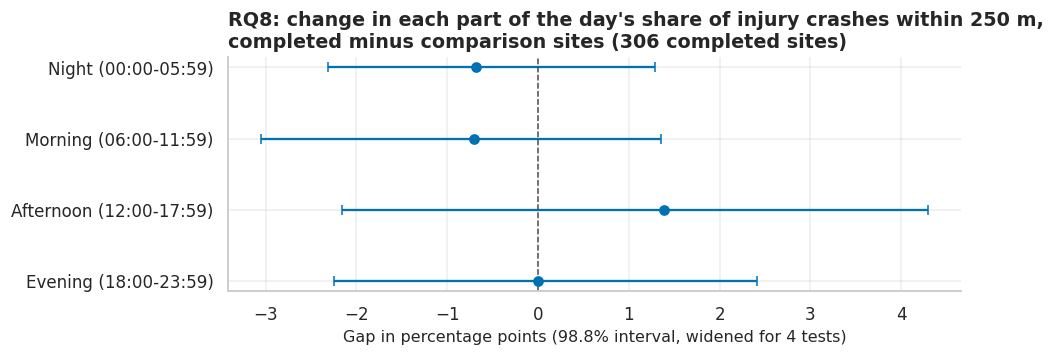

In [85]:
fig, ax = plt.subplots(figsize=(9, 3.4))
interval_rows(ax, [f"{name} ({rq8_band_ranges[name]})" for name in rq8_bands.index],
              rq8_bands["gap"], rq8_bands["low_joint"], rq8_bands["high_joint"],
              title=f"RQ8: change in each part of the day's share of injury crashes within {BUFFER_M} m,\n"
                    f"completed minus comparison sites ({rq8_sample['n_treated_sites']:,} completed sites)",
              xlabel=f"Gap in percentage points ({rq8_sample['joint_level']:.1%} interval, widened for "
                     f"{len(rq8_bands)} tests)")
show(fig)

In [86]:
rq8_top_band = rq8_bands["gap"].abs().idxmax()
rq8_top = rq8_bands.loc[rq8_top_band]
report("RQ8", "Does the hour-of-day mix of injury crashes near sites shift after completion?",
       f"percentage points; largest of {len(rq8_bands)} gaps, interval widened for {len(rq8_bands)} tests",
       rq8_top["gap"], rq8_top["low_joint"], rq8_top["high_joint"], rq8_sample["n_treated_sites"],
       unit="percentage points",
       n_unit=f"completed sites in {rq8_sample['n_clusters']:,} clusters",
       level=rq8_sample["joint_level"], adjusted_p=rq8_top["p_adjusted"],
       subject=f"The largest of the {len(rq8_bands)} part-of-day gaps, for the {rq8_top_band.lower()} "
               f"({rq8_band_ranges[rq8_top_band]}), with its interval widened for {len(rq8_bands)} tests,",
       above=f"relatively more injury crashes in the {rq8_top_band.lower()} around completed buildings",
       below=f"relatively fewer injury crashes in the {rq8_top_band.lower()} around completed buildings",
       extra=f"After Benjamini-Hochberg adjustment {int(rq8_bands['flagged'].sum())} of {len(rq8_bands)} bands keep an "
             f"interval away from zero (adjusted p for the {rq8_top_band.lower()}: {rq8_top['p_adjusted']:.2f}). "
             + new_construction_line(rq8_before, rq8_after, list(HOUR_BANDS), rq8_top_band))

The largest of the 4 part-of-day gaps, for the afternoon (12:00-17:59), with its interval widened for 4 tests, is +1.38 percentage points (99% interval -2.16 to +4.29, n = 306 completed sites in 409 clusters). The interval includes zero. After Benjamini-Hochberg adjustment 0 of 4 bands keep an interval away from zero (adjusted p for the afternoon: 0.53). With only new-construction sites treated (128 sites) the gap is +0.34 points (95% interval -2.50 to +3.14).

**Reading.** No part of the day shifts detectably: every widened interval crosses zero, and no
band survives the adjustment. With a six-hour band the interval is a few points wide, so a smaller
move towards the evening or night would go unseen. The hour is the one the officer wrote down, and
weekdays and weekends are pooled, so opposite changes on the two would cancel.

### 8.9 RQ9. Across ZIP codes, is the share of deeply affordable units associated with the severity of injury crashes or with the pedestrian and cyclist share of harm? (M5)

**Method.** One row per ZIP code of the Section 6 panel: the share of deeply affordable units
(extremely and very low income) among affordable units completed by `YEAR_END`, against two
ten-year outcomes, the pedestrian and cyclist share of injury crashes and deaths per
`PER_THOUSAND` injury crashes. Both are ratios within injury crashes, so the 2020 reporting break
does not enter them. ZIP codes under `MIN_ZIP_AFFORDABLE_UNITS` units are dropped (their share
rests on one or two buildings). A raw citywide correlation would mostly compare boroughs, so
borough means are removed before ranking (Spearman, robust to skew); the two p-values are adjusted
together.

In [87]:
MIN_ZIP_AFFORDABLE_UNITS = 50      # units; below this a ZIP's deep share jumps between 0 and 100%
BOROUGH_MARKERS = dict(zip(BOROUGHS, ["o", "s", "^", "D", "v"]))   # shape as a second cue next to colour
RQ9_OUTCOMES = {   # outcome column -> (panel title, unit of a difference)
    "ped_cyc_share_pct": ("Who is hurt: pedestrian and cyclist share of injury crashes", "percentage points"),
    "deaths_per_1000": (f"How severe: deaths per {PER_THOUSAND:,} injury crashes", "deaths"),
}


def zip_equity_table(panel, min_units=MIN_ZIP_AFFORDABLE_UNITS):
    """One row per ZIP code with at least `min_units` affordable units: deep share and the two outcomes."""
    stock = panel[panel["year"] == YEAR_END].set_index("zip")
    totals = panel.groupby("zip")[["injury_crashes", "ped_cyc_crashes", "persons_killed"]].sum()
    table = pd.DataFrame({
        "borough": stock["borough"].astype(str),
        "affordable_units": stock["cum_affordable_units"],
        "deep_share_pct": PERCENT * stock["cum_deep_affordable_units"]
                          / stock["cum_affordable_units"].where(stock["cum_affordable_units"] > 0),
        "ped_cyc_share_pct": PERCENT * totals["ped_cyc_crashes"] / totals["injury_crashes"],
        "deaths_per_1000": PER_THOUSAND * totals["persons_killed"] / totals["injury_crashes"],
    })
    return table[table["affordable_units"] >= min_units]


def deep_share_associations(zip_table):
    """Borough-adjusted (and raw) Spearman correlation of the deep share with each outcome."""
    rows = {}
    for column in RQ9_OUTCOMES:
        deep, outcome = zip_table["deep_share_pct"].to_numpy(), zip_table[column].to_numpy()
        adjusted = group_adjusted_spearman_ci(deep, outcome, zip_table["borough"].to_numpy())
        raw = spearman_ci(deep, outcome)
        rows[column] = {"rho_within_borough": adjusted["estimate"], "low": adjusted["low"], "high": adjusted["high"],
                        "p_value": adjusted["p_value"], "n": adjusted["n"], "n_boroughs": adjusted["n_groups"],
                        "rho_unadjusted": raw["estimate"], "unadjusted_low": raw["low"], "unadjusted_high": raw["high"]}
    result = pd.DataFrame(rows).T
    result["p_adjusted"] = benjamini_hochberg(result["p_value"].to_numpy(dtype=float))
    return result


rq9_zips = zip_equity_table(zip_year)
rq9_result = deep_share_associations(rq9_zips)
show_table(rq9_result.astype(float).round(3))

,rho_within_borough,low,high,p_value,n,n_boroughs,rho_unadjusted,unadjusted_low,unadjusted_high,p_adjusted
ped_cyc_share_pct,-0.202,-0.376,0.012,0.068,123.000,5.000,-0.146,-0.333,0.060,0.136
deaths_per_1000,0.125,-0.086,0.299,0.264,123.000,5.000,0.132,-0.059,0.307,0.264


Each point is a ZIP code; both axes are differences from the ZIP's own borough mean, which is what
the coefficient ranks. The dashed least-squares line only guides the eye.

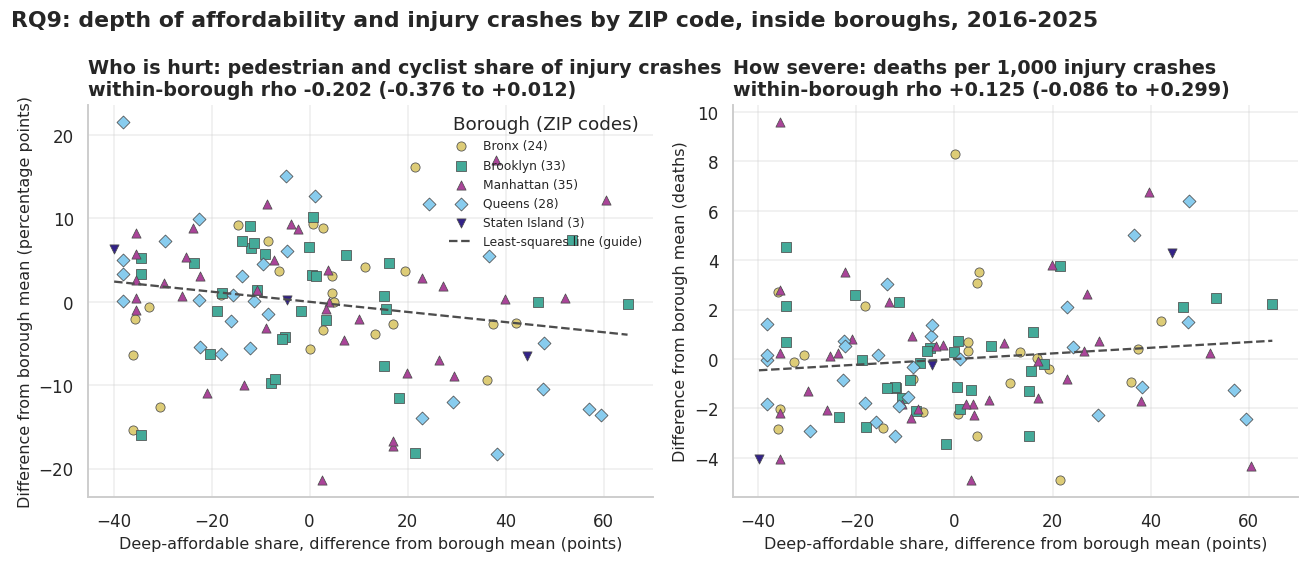

In [88]:
shown = rq9_zips[rq9_zips.groupby("borough")["borough"].transform("size") >= 2]   # one ZIP: no within-borough variation
deep_within = shown["deep_share_pct"] - shown.groupby("borough")["deep_share_pct"].transform("mean")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (column, (title, unit)) in zip(axes, RQ9_OUTCOMES.items()):
    outcome_within = shown[column] - shown.groupby("borough")[column].transform("mean")
    for borough in BOROUGHS:
        in_borough = (shown["borough"] == borough).to_numpy()
        ax.scatter(deep_within[in_borough], outcome_within[in_borough], s=36, color=BOROUGH_COLORS[borough],
                   marker=BOROUGH_MARKERS[borough], edgecolor=PALETTE["neutral"], linewidth=0.5,
                   label=f"{borough} ({int(in_borough.sum())})")
    ends = np.array([deep_within.min(), deep_within.max()])
    ax.plot(ends, linear_slope(deep_within.to_numpy(), outcome_within.to_numpy()) * ends, "--",
            color=PALETTE["neutral"], label="Least-squares line (guide)")
    row = rq9_result.loc[column]
    finish(ax, f"{title}\nwithin-borough rho {row['rho_within_borough']:+.3f} "
               f"({row['low']:+.3f} to {row['high']:+.3f})",
           "Deep-affordable share, difference from borough mean (points)", f"Difference from borough mean ({unit})")
axes[0].legend(title="Borough (ZIP codes)", fontsize=8)
fig.suptitle(f"RQ9: depth of affordability and injury crashes by ZIP code, inside boroughs, {YEAR_START}-{YEAR_END}",
             x=0.01, ha="left", fontweight="bold")
show(fig)

In [89]:
RQ9_DIGITS = 3   # a correlation is shown to three decimals, and the interval is read at that precision
rq9_ped, rq9_deaths = rq9_result.loc["ped_cyc_share_pct"], rq9_result.loc["deaths_per_1000"]
# One decision rule: the interval as printed (rounded to RQ9_DIGITS) decides "includes zero".
rq9_sentence = describe_effect(
    *(round(float(rq9_ped[key]), RQ9_DIGITS) for key in ["rho_within_borough", "low", "high"]), "", int(rq9_ped["n"]),
    n_unit=f"ZIP codes in {int(rq9_ped['n_boroughs'])} boroughs", digits=RQ9_DIGITS,
    subject="The within-borough rank correlation between the deep-affordable share and the pedestrian and "
            "cyclist share of injury crashes",
    above="a higher pedestrian and cyclist share where the affordable stock is deeper",
    below="a lower pedestrian and cyclist share where the affordable stock is deeper")
rq9_sentence += (f" Bootstrap p = {rq9_ped['p_value']:.3f}, {rq9_ped['p_adjusted']:.3f} after adjustment for the "
                 f"two outcomes.")
say(rq9_sentence)
say(describe_effect(
    *(round(float(rq9_deaths[key]), RQ9_DIGITS) for key in ["rho_within_borough", "low", "high"]), "",
    int(rq9_deaths["n"]), n_unit="ZIP codes", digits=RQ9_DIGITS,
    subject=f"For deaths per {PER_THOUSAND:,} injury crashes the within-borough rank correlation",
    above="more deaths per injury crash where the stock is deeper",
    below="fewer deaths per injury crash where the stock is deeper")
    + f" Adjusted p = {rq9_deaths['p_adjusted']:.3f}. Without the borough adjustment the two correlations are "
      f"{rq9_ped['rho_unadjusted']:+.2f} and {rq9_deaths['rho_unadjusted']:+.2f}; {len(rq9_zips)} of "
      f"{zip_year['zip'].nunique()} ZIP codes have at least {MIN_ZIP_AFFORDABLE_UNITS} affordable units.")
# Stored at the printed precision, so Section 10 applies the same decision rule.
store_result("RQ9", "Across ZIP codes, is the deep-affordable share associated with the pedestrian and cyclist "
             "share of harm?", *(round(float(rq9_ped[key]), RQ9_DIGITS) for key in ["rho_within_borough", "low", "high"]),
             rq9_ped["n"],
             rq9_sentence, "rank correlation within borough", adjusted_p=rq9_ped["p_adjusted"])

The within-borough rank correlation between the deep-affordable share and the pedestrian and cyclist share of injury crashes is -0.202 (95% interval -0.376 to +0.012, n = 123 ZIP codes in 5 boroughs). The interval includes zero. Bootstrap p = 0.068, 0.136 after adjustment for the two outcomes.

For deaths per 1,000 injury crashes the within-borough rank correlation is +0.125 (95% interval -0.086 to +0.299, n = 123 ZIP codes). The interval includes zero. Adjusted p = 0.264. Without the borough adjustment the two correlations are -0.15 and +0.13; 123 of 172 ZIP codes have at least 50 affordable units.

**Reading.** Inside a borough, ZIP codes with a deeper affordable mix lean towards a slightly
*lower* pedestrian and cyclist share, the opposite of the concern behind the question; at the
printed precision the interval reaches zero and the adjusted p-value is above the threshold, so it
is a hint, not a finding. Deaths per injury crash show no association either way. These are area
data: the housing variable describes financed units, not who was in the crashes. Neighbouring ZIP
codes resemble each other, which the interval ignores, so it is probably too narrow.

### 8.10 RQ10. Which contributing-factor groups are over- or under-represented near completed housing, after against before? (M5)

**Method.** The design of RQ6 with the contributing-factor group of Section 4 as the category.
Crashes with no factor recorded are left out of the shares (the group is large, says nothing about
the street, and depends on reporting habits); its own shift is shown as a separate check row.
Several groups are tested at once, so p-values are Benjamini-Hochberg adjusted and the headline,
the largest gap, carries the interval widened for the number of groups. Comparing crashes near
housing with crashes elsewhere was rejected: it would compare dense blocks with highways.

In [90]:
UNRECORDED_FACTOR = "Unspecified"  # factor group meaning that the report names no factor
UNRECORDED_LABELS = [UNRECORDED_FACTOR, "Recorded factor"]
factor_names = [name for name in crashes["factor_group"].cat.categories if name != UNRECORDED_FACTOR]
factor_codes = pd.Categorical(crashes["factor_group"], categories=factor_names).codes.astype(np.int64)
rq10_before, rq10_after = period_category_counts(event_units, site_pairs, crashes, factor_codes, len(factor_names))
rq10_factors, rq10_sample = composition_shift(event_units, rq10_before, rq10_after, factor_names)
rq10_factors = rq10_factors.sort_values("gap", ascending=False)

# The check: share of all injury crashes with no factor named, pooled and for each kind of project.
unrecorded_before, unrecorded_after = period_category_counts(
    event_units, site_pairs, crashes, np.where(crashes["factor_group"] == UNRECORDED_FACTOR, 0, 1), 2)
rq10_unrecorded_by_kind = {
    label: composition_shift(event_units[keep], unrecorded_before[keep], unrecorded_after[keep],
                             UNRECORDED_LABELS)[0].loc[UNRECORDED_FACTOR]
    for label, keep in [("both kinds", np.ones(len(event_units), bool)),
                        ("new construction", units_of_kind(NEW_CONSTRUCTION)),
                        ("preservation", units_of_kind(PRESERVATION))]}
rq10_unrecorded = rq10_unrecorded_by_kind["both kinds"]
show_table(rq10_factors.drop(columns="flagged").round(2))

,treated_before,treated_after,comparison_before,comparison_after,treated_change,comparison_change,gap,low,high,low_joint,high_joint,p_value,p_adjusted
category,,,,,,,,,,,,,
Improper manoeuvre,13.330,13.950,14.700,14.520,0.560,-0.250,0.810,-0.930,2.510,-1.800,3.270,0.350,0.930
Failure to yield or obey,21.080,22.220,21.250,21.880,1.090,0.700,0.390,-1.530,2.540,-2.570,3.370,0.630,0.930
Vehicle defect,1.000,1.100,1.200,0.960,0.110,-0.210,0.320,-0.220,0.890,-0.460,1.110,0.260,0.930
Other,4.980,5.210,4.340,4.320,0.260,0.020,0.250,-0.960,1.980,-1.700,2.620,0.710,0.930
Road or environment,3.640,3.300,3.630,3.090,-0.330,-0.460,0.130,-0.870,1.190,-1.140,1.560,0.880,0.930
Pedestrian or cyclist error,2.720,2.710,3.130,3.140,-0.020,-0.050,0.030,-0.680,0.770,-1.070,1.010,0.930,0.930
Speed or aggressive driving,14.160,12.900,13.790,13.290,-1.220,-0.780,-0.440,-3.170,2.730,-3.850,3.710,0.810,0.930
Distraction,33.590,34.460,34.220,35.380,0.870,1.530,-0.650,-4.710,2.130,-5.980,3.310,0.680,0.930
Impairment or medical,5.510,4.150,3.740,3.410,-1.320,-0.490,-0.830,-1.930,0.160,-2.760,0.670,0.100,0.930


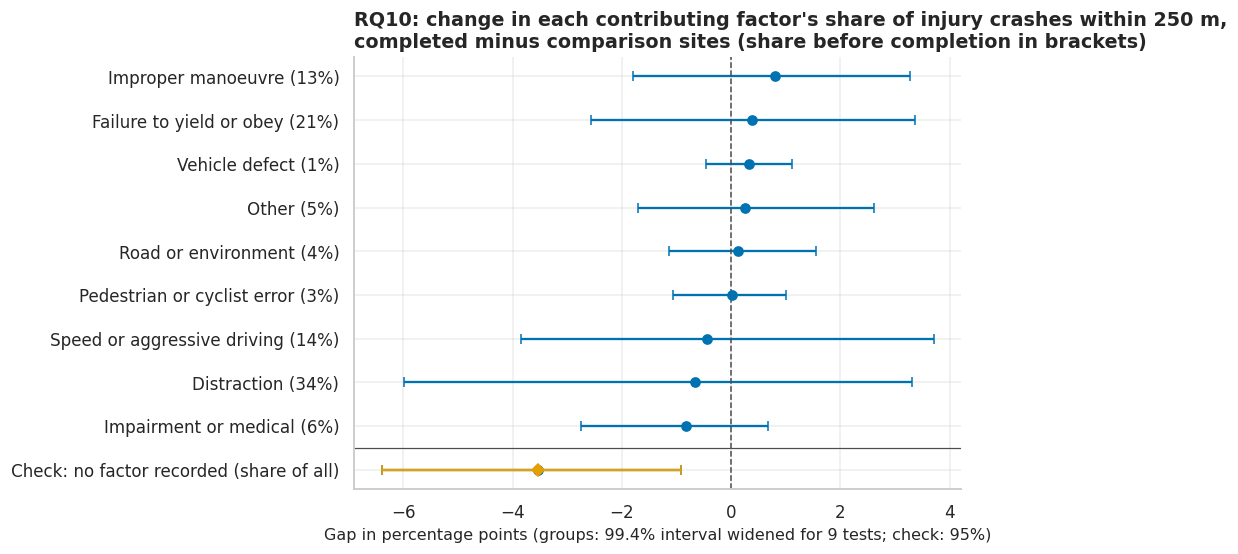

In [91]:
check_label = "Check: no factor recorded (share of all)"
fig, ax = plt.subplots(figsize=(9, 5.2))
labels = [f"{name} ({row.treated_before:.0f}%)" for name, row in rq10_factors.iterrows()] + [check_label]
interval_rows(ax, labels, [*rq10_factors["gap"], rq10_unrecorded["gap"]],
              [*rq10_factors["low_joint"], rq10_unrecorded["low"]], [*rq10_factors["high_joint"], rq10_unrecorded["high"]],
              title=f"RQ10: change in each contributing factor's share of injury crashes within {BUFFER_M} m,\n"
                    f"completed minus comparison sites (share before completion in brackets)",
              xlabel=f"Gap in percentage points (groups: {rq10_sample['joint_level']:.1%} interval widened for "
                     f"{len(rq10_factors)} tests; check: {CI_LEVEL:.0%})")
ax.errorbar(rq10_unrecorded["gap"], 0, xerr=[[rq10_unrecorded["gap"] - rq10_unrecorded["low"]],
                                             [rq10_unrecorded["high"] - rq10_unrecorded["gap"]]],
            fmt="D", capsize=3, color=PALETTE["placebo"])   # the check row (bottom) is not one of the tested groups
ax.axhline(0.5, color=PALETTE["neutral"], linewidth=0.8)
show(fig)

In [92]:
rq10_top_name = rq10_factors["gap"].abs().idxmax()
rq10_top = rq10_factors.loc[rq10_top_name]
report("RQ10", "Which contributing-factor groups are over- or under-represented near completed housing, "
       "after against before?",
       f"percentage points; largest of {len(rq10_factors)} gaps, interval widened for {len(rq10_factors)} tests",
       rq10_top["gap"], rq10_top["low_joint"], rq10_top["high_joint"], rq10_sample["n_treated_sites"],
       unit="percentage points",
       n_unit=f"completed sites in {rq10_sample['n_clusters']:,} clusters",
       level=rq10_sample["joint_level"], adjusted_p=rq10_top["p_adjusted"],
       subject=f"The largest of the {len(rq10_factors)} factor-group gaps, for \"{rq10_top_name}\" among injury "
               f"crashes with a recorded factor, with its interval widened for {len(rq10_factors)} tests,",
       above=f"a growing share of \"{rq10_top_name}\" around completed buildings",
       below=f"a shrinking share of \"{rq10_top_name}\" around completed buildings",
       extra=f"Groups kept after Benjamini-Hochberg adjustment: {int(rq10_factors['flagged'].sum())} of {len(rq10_factors)} "
             f"(smallest adjusted p = {rq10_factors['p_adjusted'].min():.2f}). "
             + new_construction_line(rq10_before, rq10_after, factor_names, rq10_top_name))
say("Check, gap in the share with no factor recorded: " + "; ".join(
    f"{label} {row['gap']:+.1f} points ({row['low']:+.1f} to {row['high']:+.1f})"
    for label, row in rq10_unrecorded_by_kind.items()) + ".")

The largest of the 9 factor-group gaps, for "Impairment or medical" among injury crashes with a recorded factor, with its interval widened for 9 tests, is -0.83 percentage points (99% interval -2.76 to +0.67, n = 306 completed sites in 409 clusters). The interval includes zero. Groups kept after Benjamini-Hochberg adjustment: 0 of 9 (smallest adjusted p = 0.93). With only new-construction sites treated (128 sites) the gap is -0.09 points (95% interval -1.27 to +0.86).

Check, gap in the share with no factor recorded: both kinds -3.5 points (-6.4 to -0.9); new construction -0.8 points (-3.4 to +1.6); preservation -5.7 points (-9.5 to -2.2).

**Reading.** No factor group moves in a way these data can separate from chance: every interval
crosses zero and none survives the adjustment. The check row does move: the share of reports with
no factor named fell around completed sites relative to comparison sites, and the split shows it
belongs to preservation, where nobody new moves in (see 11). It concerns how completely reports
were filled in, is outside the tested set, and is a caveat for the shares above, which are taken
among reports with a recorded factor. The factor is the officer's judgement for the first vehicle
only, and the smallest groups rest on few crashes.

## 9. Robustness checks

The before/after comparison around new-construction sites (RQ3) rests on choices that the data do
not dictate: the 250 m buffer, the injury-crash outcome, the screen against nearby completions,
the comparison strata and the cohorts used. This section re-estimates it with one choice changed
at a time and collects every estimate in one table and one chart. A conclusion is kept only if it
survives choices that could reasonably have been made differently.

**Central comparison.** Treated units are new-construction sites of the cohorts with a full window;
comparison units are sites still not completed at the end of that window. Both pass the screen of
Section 5.4. Injury crashes within the buffer are summed over the `EVENT_WINDOW` years before and
after the completion year (the year itself is skipped). The estimate is the mean log ratio
after/before at treated minus comparison sites, inside each cohort, weighted by treated sites per
cohort, with whole clusters resampled for the interval.

In [93]:
ALTERNATIVE_RADII_M = [150, 400]   # metres; one clearly smaller and one clearly larger than BUFFER_M (Section 5.3)
SHORT_WINDOW = 2                   # years; the placebo is also run with this shorter window
PLACEBO_SHIFT = EVENT_WINDOW       # years by which the placebo moves the completion date earlier
CENTRAL_OUTCOME, ALTERNATIVE_OUTCOME = "injury_crashes", "crashes"
EVENT_UNIT_COLUMNS = ["cluster_id", "contaminated", "construction_type", "borough"]
EARLY_COHORT = YEAR_START + EVENT_WINDOW   # first full-window cohort; its before years start in YEAR_START
LARGEST_CLUSTERS_SHOWN = 3         # clusters whose joint weight Section 10 reports
KIND_CENTRAL, KIND_CHECK, KIND_PLACEBO = "central", "check", "placebo"
CHECK_OUTCOME = "Outcome"          # the all-crashes row; Section 10 reads it
CHECK_SCREEN = "Nearby completions"
assert all(radius in RADIUS_CANDIDATES_M for radius in ALTERNATIVE_RADII_M)


def yearly_counts(site_year_frame, outcome):
    """Sites x study-years matrix of one count column (site_year is sorted by site, then year)."""
    return site_year_frame[outcome].to_numpy().reshape(-1, N_STUDY_YEARS)


def before_after_counts(units, counts, window=EVENT_WINDOW):
    """Add `before` and `after`: the outcome summed over `window` years on each side of the cohort year."""
    relative_years = np.concatenate([np.arange(-window, 0), np.arange(1, window + 1)])
    years = units["cohort"].to_numpy()[:, None] + relative_years[None, :]
    assert years.min() >= YEAR_START and years.max() <= YEAR_END, "a window leaves the study years"
    values = counts[units["site_id"].to_numpy()[:, None], years - YEAR_START]
    return units.assign(before=values[:, :window].sum(axis=1), after=values[:, window:].sum(axis=1))


def comparison_units(panel, counts, keep_contaminated=False):
    """The one event-units builder: new-construction treated and all comparison units, with before/after sums."""
    units = cohort_unit_table(panel, EVENT_UNIT_COLUMNS, keep_contaminated=True)
    keep = ~units["treated"] | (units["construction_type"] == NEW_CONSTRUCTION)
    if not keep_contaminated:
        keep &= ~units["contaminated"]
    return before_after_counts(units[keep].reset_index(drop=True), counts)


def estimate_check(units, check, variant, kind=KIND_CHECK, strata=("cohort",), keeps_screen=True):
    """Difference-in-differences on the log ratio for one specification, as one table row.

    Strata with sites on one side only are left out and counted in the `dropped` columns. No
    estimate is reported when either arm has fewer than MIN_GROUP_N sites.
    """
    result = did_log_ratio(units["before"].to_numpy(), units["after"].to_numpy(), units["treated"].to_numpy(),
                           strata=units[list(strata)].astype(str).agg("|".join, axis=1).to_numpy(),
                           clusters=units["cluster_id"].to_numpy())
    row = {"check": check, "variant": variant, "kind": kind, "keeps_screen": keeps_screen,
           "n_treated": result["n_treated"], "n_comparison": result["n_control"],
           "n_treated_dropped": result["n_treated_dropped"], "n_comparison_dropped": result["n_control_dropped"],
           "n_resampled_units": result["n_clusters"], "n_strata": result["n_strata"],
           "treated_change": result["treated_change"], "comparison_change": result["control_change"]}
    large_enough = min(result["n_treated"], result["n_control"]) >= MIN_GROUP_N
    for column in ["estimate", "low", "high", "p_value", "percent_change", "percent_low", "percent_high"]:
        row[column] = result[column] if large_enough else float("nan")
    return row


def reading(row):
    """Estimate, interval and sample of one table row as a phrase."""
    if np.isnan(row["estimate"]):
        return f"not reported (fewer than {MIN_GROUP_N} sites in an arm)"
    return (f"{row['percent_change']:+.1f}% ({CI_LEVEL:.0%} interval {row['percent_low']:+.1f}% to "
            f"{row['percent_high']:+.1f}%; {row['n_treated']:,} treated and {row['n_comparison']:,} comparison sites)")


injury_counts = yearly_counts(site_year, CENTRAL_OUTCOME)
assert injury_counts.shape == (len(sites), N_STUDY_YEARS)
central_units = comparison_units(event_panel, injury_counts)
central = estimate_check(central_units, "Central estimate", f"{BUFFER_M} m, {EVENT_WINDOW} years, injury crashes",
                         kind=KIND_CENTRAL)
robustness_rows = [central]
show_table(central_units.groupby(["cohort", "group"], observed=True).size().unstack("group"))
say(f"Central estimate: injury crashes change by {log_points_to_percent(central['treated_change']):+.1f}% at "
    f"treated and {log_points_to_percent(central['comparison_change']):+.1f}% at comparison sites; the "
    f"difference is {reading(central)}, bootstrap p = {central['p_value']:.2f}.")

group,treated,comparison
cohort,,
2019,33,696
2020,27,538
2021,32,422
2022,36,213


Central estimate: injury crashes change by -13.8% at treated and -9.7% at comparison sites; the difference is -4.6% (95% interval -11.9% to +3.3%; 128 treated and 1,869 comparison sites), bootstrap p = 0.24.

### 9.1 Outcome: all crashes

Reports of property-damage-only crashes collapsed in 2020 (Section 3) and every window straddles
that year. Replacing injury crashes with all crashes shows how large the break is in a raw
before/after count, and whether comparison sites, which went through the same break, cancel it.

In [94]:
all_crashes = estimate_check(comparison_units(event_panel, yearly_counts(site_year, ALTERNATIVE_OUTCOME)),
                             CHECK_OUTCOME, "All crashes, including property damage only")
robustness_rows.append(all_crashes)
say(f"Undifferenced, all crashes near treated sites change by {log_points_to_percent(all_crashes['treated_change']):+.1f}% "
    f"(comparison sites {log_points_to_percent(all_crashes['comparison_change']):+.1f}%), against "
    f"{log_points_to_percent(central['treated_change']):+.1f}% for injury crashes. After differencing: "
    f"{reading(all_crashes)}.")

Undifferenced, all crashes near treated sites change by -47.2% (comparison sites -46.0%), against -13.8% for injury crashes. After differencing: -2.2% (95% interval -9.9% to +5.2%; 128 treated and 1,869 comparison sites).

The raw all-crash fall is far larger than the injury-crash fall, and a before/after count without
comparison sites would report it as a safety gain near new housing. Comparison sites show almost
the same fall, so the difference agrees with the central estimate. Injury crashes stay the primary
outcome because they do not need the comparison group to cancel the break exactly.

### 9.2 The screen for nearby completions

The screen removes most candidate sites and keeps the less dense part of the programme. Switching
it off admits every candidate, at the cost of comparison streets that already have a completed
building. Neighbouring buildings of one development then enter as separate rows that count the
same streets, so each cluster of treated sites is left out in turn and the estimate is repeated
without the one that moves it most.

In [95]:
def leave_one_cluster_out(units):
    """Point estimate (log points) with each cluster that holds a treated site left out in turn."""
    change = log_ratio(units["before"].to_numpy(), units["after"].to_numpy())
    treated = units["treated"].to_numpy()
    strata_codes, strata_labels = pd.factorize(units["cohort"])
    clusters = units["cluster_id"].to_numpy()
    return pd.Series({cluster: stratified_difference(change[clusters != cluster], treated[clusters != cluster],
                                                     strata_codes[clusters != cluster], len(strata_labels))["estimate"]
                      for cluster in np.unique(clusters[treated])})


unscreened_units = comparison_units(event_panel, injury_counts, keep_contaminated=True)
unscreened = estimate_check(unscreened_units, CHECK_SCREEN, "Screen switched off: every candidate site",
                            keeps_screen=False)
without_one = leave_one_cluster_out(unscreened_units)
dominant_cluster = (without_one - unscreened["estimate"]).abs().idxmax()
in_dominant = (unscreened_units["cluster_id"] == dominant_cluster).to_numpy()
without_dominant = estimate_check(unscreened_units[~in_dominant], CHECK_SCREEN,
                                  "Screen off, without the most influential cluster", keeps_screen=False)
robustness_rows += [unscreened, without_dominant]

dominant_rows = unscreened_units[in_dominant & unscreened_units["treated"].to_numpy()]
dominant_projects = sites["project_name"].astype(str).to_numpy()[dominant_rows["site_id"]]
central_without_one = leave_one_cluster_out(central_units)
say(f"Screen off: {reading(unscreened)}. Leaving out one treated cluster at a time moves it between "
    f"{log_points_to_percent(without_one.min()):+.1f}% and {log_points_to_percent(without_one.max()):+.1f}%. The most "
    f"influential cluster holds {len(dominant_rows):,} treated rows, mostly from \"{pd.Series(dominant_projects).mode()[0]}\" "
    f"(median injury crashes per row: {dominant_rows['before'].median():.0f} before, "
    f"{dominant_rows['after'].median():.0f} after). Without it: {reading(without_dominant)}. In the central sample "
    f"the same exercise moves the estimate only between {log_points_to_percent(central_without_one.min()):+.1f}% and "
    f"{log_points_to_percent(central_without_one.max()):+.1f}%.")

Screen off: +19.9% (95% interval +0.2% to +79.8%; 1,142 treated and 11,288 comparison sites). Leaving out one treated cluster at a time moves it between +3.9% and +30.3%. The most influential cluster holds 99 treated rows, mostly from "Nehemiah Spring Creek Homes at Gateway Estates 4A" (median injury crashes per row: 1 before, 10 after). Without it: +3.9% (95% interval -1.2% to +11.4%; 1,043 treated and 11,228 comparison sites). In the central sample the same exercise moves the estimate only between -5.3% and -3.0%.

The positive estimate without the screen rests on one development of small houses on streets that
had almost no injury crashes before: each house counts those streets again, and a rise from near
zero is a large log ratio. Without it the estimate is small with an interval that includes zero.
Removing the most influential cluster must lower the estimate, so that row is not evidence of the
opposite either; it shows the positive sign rests on one place.

### 9.3 Placebo: a completion date that is too early

If streets about to get a building were already on a different path, the central estimate would
pick that up. Each new-construction site is entered `PLACEBO_SHIFT` years before its real
completion, so both false periods precede the building, and compared with the clean comparison
sites of that earlier cohort. With the 3-year window the last false "after" year is the real
completion year, so the placebo is repeated with a `SHORT_WINDOW`-year window. Both should be near zero.

In [96]:
def placebo_units(shift, window=EVENT_WINDOW):
    """Units in which new-construction sites are dated `shift` years before their real completion."""
    completion = sites["completion_year"].astype("float64").to_numpy()
    first, second = site_neighbour_pairs(sites, BUFFER_M)
    base = cohort_unit_table(event_panel, EVENT_UNIT_COLUMNS, keep_contaminated=True)
    parts = [base.loc[~base["treated"] & ~base["contaminated"], ["site_id", "cohort", "group", "treated", "cluster_id"]]]
    for cohort in sorted(base["cohort"].unique()):
        # The screen of Section 5.4 applied to the false date: no other completion in the window.
        neighbour_done = completion[second]
        in_window = ((first != second) & (neighbour_done >= cohort - window) & (neighbour_done <= cohort + window)
                     & (neighbour_done != completion[first]))
        contaminated = np.bincount(first[in_window], minlength=len(sites)) > 0
        chosen = sites[(completion == cohort + shift) & (sites["construction_type"] == NEW_CONSTRUCTION).to_numpy()
                       & ~contaminated]
        parts.append(pd.DataFrame({"site_id": chosen["site_id"].to_numpy(), "cohort": cohort, "group": "treated",
                                   "treated": True, "cluster_id": chosen["cluster_id"].to_numpy()}))
    units = pd.concat(parts, ignore_index=True)
    assert not units.duplicated(["site_id", "cohort"]).any(), "a site is on both sides of one cohort"
    return units


placebo_base = placebo_units(PLACEBO_SHIFT)
for window in (EVENT_WINDOW, SHORT_WINDOW):
    robustness_rows.append(estimate_check(before_after_counts(placebo_base, injury_counts, window), "Placebo",
                                          f"Completion dated {PLACEBO_SHIFT} years early, {window}-year window",
                                          kind=KIND_PLACEBO))
say("; ".join(f"{row['variant']}: {reading(row)}" for row in robustness_rows[-2:]) + ".")

Completion dated 3 years early, 3-year window: +2.1% (95% interval -4.1% to +10.4%; 245 treated and 1,869 comparison sites); Completion dated 3 years early, 2-year window: -0.4% (95% interval -7.3% to +7.9%; 245 treated and 1,869 comparison sites).

Both placebo estimates are near zero with intervals that include it, so the pre-completion years
give no sign that treated streets were already diverging. Their intervals are about as wide as the
central one, so they rule out a large difference in earlier trends, not one the size of the
central estimate.

### 9.4 Strata, cohorts and duplicated projects

Three changes to who is compared with whom. **Inside cohort and borough:** treated and comparison
sites are spread differently over the boroughs, and reporting did not move alike everywhere after
2020. **Without the earliest cohort:** its before years start in `YEAR_START`, when a much larger
share of crashes lacked usable coordinates (printed below), so fewer crashes could be placed near
any site. **One building per project:** a few projects hold many treated buildings that count the
same streets; keeping one building per project (the first site) in each cohort and arm stops
them from weighing as many independent sites.

In [97]:
inside_borough = estimate_check(central_units, "Comparison group", "Compared inside cohort and borough",
                                strata=("cohort", "borough"))
without_early = estimate_check(central_units[central_units["cohort"] != EARLY_COHORT], "Cohorts",
                               f"Without the {EARLY_COHORT} cohort")
project_of_unit = sites["project_id"].to_numpy()[central_units["site_id"]]
one_per_project = estimate_check(
    central_units[~central_units.assign(project=project_of_unit).duplicated(["cohort", "group", "project"])],
    "Projects", "One building per project")
robustness_rows += [inside_borough, without_early, one_per_project]

unlocated_by_year = PERCENT * (1 - crashes.groupby("year")["is_located"].mean())
treated_projects = pd.Series(project_of_unit[central_units["treated"].to_numpy()]).value_counts()
say(f"Inside cohort and borough: {reading(inside_borough)} ({inside_borough['n_comparison_dropped']} comparison "
    f"rows in one-sided strata left out). Crashes without usable coordinates: {unlocated_by_year[YEAR_START]:.1f}% in "
    f"{YEAR_START}, {unlocated_by_year.drop(YEAR_START).min():.1f}% to {unlocated_by_year.drop(YEAR_START).max():.1f}% "
    f"later; without the {EARLY_COHORT} cohort: {reading(without_early)}. The {treated_projects.sum():,} treated "
    f"units belong to {len(treated_projects):,} projects, the largest with {treated_projects.max()} buildings; one "
    f"building per project: {reading(one_per_project)}.")

Inside cohort and borough: -5.9% (95% interval -13.1% to +1.7%; 128 treated and 1,806 comparison sites) (63 comparison rows in one-sided strata left out). Crashes without usable coordinates: 16.4% in 2016, 3.3% to 10.4% later; without the 2019 cohort: -7.0% (95% interval -17.1% to +2.6%; 95 treated and 1,173 comparison sites). The 128 treated units belong to 117 projects, the largest with 7 buildings; one building per project: -5.6% (95% interval -11.4% to +0.6%; 117 treated and 1,187 comparison sites).

### 9.5 Buffer radius

A smaller buffer keeps only the closest crashes but leaves small, noisy counts; a larger one adds
streets with little to do with the building. The screen and the clusters use the same distance,
so both are rebuilt at 150 m and 400 m, which changes which sites pass.

In [98]:
for radius in ALTERNATIVE_RADII_M:
    # A smaller buffer is a subset of the pairs already found; a larger one needs a new tree query.
    pairs = (site_pairs[site_pairs["distance_m"] <= radius] if radius < BUFFER_M
             else site_crash_pairs(sites, crash_tree, crash_tree_rows, radius))
    first, second = site_neighbour_pairs(sites, radius)
    sites_at_radius = sites.assign(cluster_id=connected_clusters(first, second, len(sites)))
    site_year_at_radius = build_site_year(pairs, crashes, len(sites))
    panel = build_event_panel(sites_at_radius, site_year_at_radius, radius_m=radius, neighbour_pairs=(first, second))
    row = estimate_check(comparison_units(panel, yearly_counts(site_year_at_radius, CENTRAL_OUTCOME)),
                         "Buffer radius", f"{radius} m, screen and clusters rebuilt at {radius} m")
    robustness_rows.append(row)
    say(f"{radius} m: {reading(row)}.")
release("pairs", "panel", "site_year_at_radius", "sites_at_radius")

150 m: +5.4% (95% interval -4.1% to +14.7%; 319 treated and 3,847 comparison sites).

400 m: -7.2% (95% interval -18.5% to +5.4%; 56 treated and 1,090 comparison sites).

The radius changes which sites pass the screen, so the sample moves a lot; the point estimate can
change sign, but every interval includes zero.

### 9.6 ZIP-level results on reported ZIP codes only

RQ1, RQ2 and RQ9 count crashes by ZIP code, and part of the codes were recovered from coordinates
(Section 6.1). A recovered code can be wrong near a boundary, and the recovered share varies by
year. The panel's crash columns are rebuilt from crashes with a police-reported ZIP code and the
three results are estimated again.

In [99]:
def reported_zip_panel(panel, crash_frame):
    """The ZIP x year panel with its crash columns recounted from crashes whose ZIP code was reported."""
    is_reported = (~crash_frame["zip_imputed"] & crash_frame["in_zip_panel"]).to_numpy()
    counts = aggregate_crashes_to_zip_year(crash_frame[is_reported])
    counts = counts.assign(zip=counts["zip"].astype(str), year=counts["year"].astype(int)).set_index(["zip", "year"])
    keys = pd.MultiIndex.from_arrays([panel["zip"].astype(str), panel["year"].astype(int)])
    aligned = counts[CRASH_PANEL_MEASURES].reindex(keys, fill_value=0)
    reported = panel.copy()
    for column in CRASH_PANEL_MEASURES:
        reported[column] = aligned[column].to_numpy().astype(panel[column].dtype)
    # Row conservation: the panel already records how many of its crashes rest on a recovered code.
    assert (reported["injury_crashes"] == panel["injury_crashes"] - panel["injury_crashes_zip_imputed"]).all()
    return reported


def interval_text(estimate, low, high, digits=2):
    """Estimate and interval in one table cell."""
    return f"{estimate:+.{digits}f} ({low:+.{digits}f} to {high:+.{digits}f})"


reported_panel = reported_zip_panel(zip_year, crashes)
reported_forecast = forecast_comparison(build_forecast_frame(reported_panel))[0].loc[FORECAST_FULL]
reported_stock, reported_timing = stock_regression(reported_panel)
reported_equity = deep_share_associations(zip_equity_table(reported_panel))
reported_ped = reported_equity.loc["ped_cyc_share_pct"]
same_year_all = timing_slopes[timing_slopes["shift"] == 0].iloc[0]
same_year_reported = reported_timing[reported_timing["shift"] == 0].iloc[0]
rq9_ped_all = rq9_result.loc["ped_cyc_share_pct"]
zip_level_checks = pd.DataFrame(
    [("RQ1: change in forecast error with housing (injury crashes per ZIP-year)",
      interval_text(rq1["mae_minus_baseline"], rq1["low"], rq1["high"]),
      interval_text(reported_forecast["mae_minus_baseline"], reported_forecast["low"], reported_forecast["high"])),
     (f"RQ2: slope on the cumulative stock (% per {UNITS_PER_STEP} units)",
      interval_text(stock_slope["estimate_pct"], stock_slope["low_pct"], stock_slope["high_pct"]),
      interval_text(reported_stock["estimate_pct"], reported_stock["low_pct"], reported_stock["high_pct"])),
     (f"RQ2: slope on same-year completions (% per {UNITS_PER_STEP} units)",
      interval_text(same_year_all["estimate_pct"], same_year_all["low_pct"], same_year_all["high_pct"]),
      interval_text(same_year_reported["estimate_pct"], same_year_reported["low_pct"], same_year_reported["high_pct"])),
     ("RQ9: within-borough rank correlation, pedestrian and cyclist share",
      interval_text(rq9_ped_all["rho_within_borough"], rq9_ped_all["low"], rq9_ped_all["high"], 3),
      interval_text(reported_ped["rho_within_borough"], reported_ped["low"], reported_ped["high"], 3))],
    columns=["estimate", "all ZIP codes", "reported ZIP codes only"]).set_index("estimate")
show_table(zip_level_checks)
say(f"{pct(zip_year['injury_crashes_zip_imputed'].sum(), zip_year['injury_crashes'].sum()):.1f}% of panel injury "
    f"crashes have a recovered ZIP code. Adjusted p on reported codes: RQ2 same-year slope "
    f"{same_year_reported['p_adjusted']:.3f} (all codes {same_year_all['p_adjusted']:.3f}); RQ9 "
    f"{reported_ped['p_adjusted']:.3f} (all codes {rq9_ped_all['p_adjusted']:.3f}).")
release("reported_panel")

,all ZIP codes,reported ZIP codes only
estimate,,
RQ1: change in forecast error with housing (injury crashes per ZIP-year),+0.59 (+0.17 to +1.11),-0.16 (-0.58 to +0.35)
RQ2: slope on the cumulative stock (% per 100 units),+0.06 (-0.07 to +0.39),+0.19 (-0.03 to +0.75)
RQ2: slope on same-year completions (% per 100 units),-0.39 (-0.84 to -0.22),-0.49 (-1.03 to -0.15)
"RQ9: within-borough rank correlation, pedestrian and cyclist share",-0.202 (-0.376 to +0.012),-0.196 (-0.392 to +0.012)


29.6% of panel injury crashes have a recovered ZIP code. Adjusted p on reported codes: RQ2 same-year slope 0.030 (all codes 0.012); RQ9 0.132 (all codes 0.136).

The small forecast loss of RQ1 disappears on reported codes, so RQ1 reads "housing did not improve
the forecast", not "made it worse". The RQ9 correlation barely moves and stays a hint. The RQ2
same-year slope keeps its sign in both columns; it belongs to preserved units (see 11). Neither
column is the true one, because leaving out recovered codes removes a share that varies by year;
a ZIP-level result counts as solid only if it appears in both.

### 9.7 All checks together

Every specification of the RQ3 comparison, as a percent difference with its interval. The shaded
band is the central interval; the dashed line is no difference.

In [100]:
robustness_table = pd.DataFrame(robustness_rows)
robustness_table["interval_excludes_zero"] = (robustness_table["low"] > 0) | (robustness_table["high"] < 0)
assert not robustness_table.duplicated(["check", "variant"]).any()
show_table(robustness_table.set_index(["check", "variant"])[
    ["n_treated", "n_comparison", "n_resampled_units", "percent_change", "percent_low", "percent_high",
     "p_value", "interval_excludes_zero"]].round(2))

n_treated  n_comparison  n_resampled_units  percent_change  percent_low  percent_high  \
check              variant                                                                                                                                   
Central estimate   250 m, 3 years, injury crashes                          128          1869                356          -4.560      -11.900         3.330   
Outcome            All crashes, including property damage only             128          1869                356          -2.230       -9.920         5.160   
Nearby completions Screen switched off: every candidate site              1142         11288                462          19.860        0.190        79.760   
                   Screen off, without the most influential cluster       1043         11228                461           3.950       -1.230        11.450   
Placebo            Completion dated 3 years early, 3-year window           245          1869                327           2.090       -4.120        10.410   
                   Completion dated 3 years early, 2-year window           245          1869                327          -0.420       -7.300         7.900   
Comparison group   Compared inside cohort and borough                      128          1806                356          -5.880      -13.090         1.730   
Cohorts            Without the 2019 cohort                                  95          1173                288          -6.970      -17.110         2.620   
Projects           One building per project                                117          1187                336          -5.560      -11.350         0.590   
Buffer radius      150 m, screen and clusters rebuilt at 150 m             319          3847                881           5.360       -4.120        14.750   
                   400 m, screen and clusters rebuilt at 400 m              56          1090                150          -7.250      -18.530         5.430   

                                                                     p_value  interval_excludes_zero  
check              variant                                                                            
Central estimate   250 m, 3 years, injury crashes                      0.240                   False  
Outcome            All crashes, including property damage only         0.600                   False  
Nearby completions Screen switched off: every candidate site           0.040                    True  
                   Screen off, without the most influential cluster    0.130                   False  
Placebo            Completion dated 3 years early, 3-year window       0.530                   False  
                   Completion dated 3 years early, 2-year window       0.960                   False  
Comparison group   Compared inside cohort and borough                  0.110                   False  
Cohorts            Without the 2019 cohort                             0.160                   False  
Projects           One building per project                            0.080                   False  
Buffer radius      150 m, screen and clusters rebuilt at 150 m         0.240                   False  
                   400 m, screen and clusters rebuilt at 400 m         0.250                   False

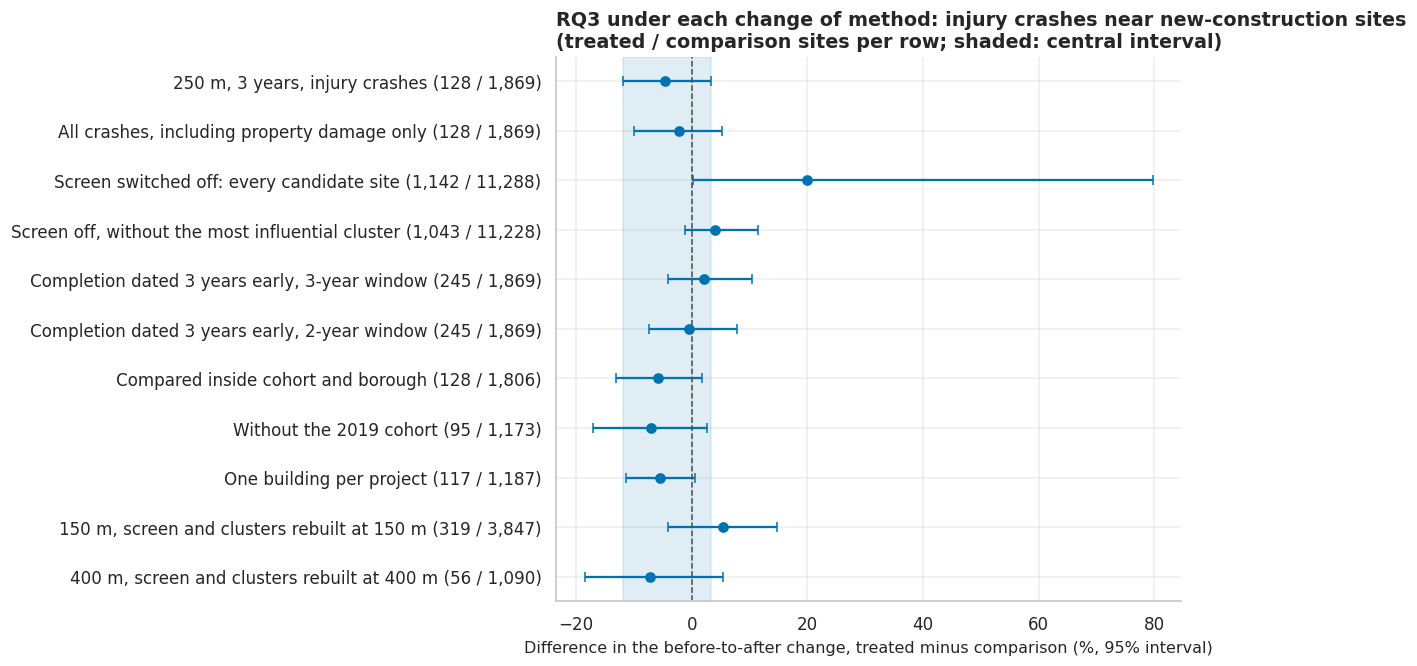

In [101]:
plotted = robustness_table[robustness_table["estimate"].notna()]
fig, ax = plt.subplots(figsize=(11, 0.42 * len(plotted) + 1.6))
ax.axvspan(central["percent_low"], central["percent_high"], color=PALETTE["treated"], alpha=0.12)
interval_rows(ax, [f"{row.variant} ({row.n_treated:,} / {row.n_comparison:,})" for row in plotted.itertuples()],
              plotted["percent_change"], plotted["percent_low"], plotted["percent_high"],
              title="RQ3 under each change of method: injury crashes near new-construction sites\n"
                    "(treated / comparison sites per row; shaded: central interval)",
              xlabel=f"Difference in the before-to-after change, treated minus comparison (%, {CI_LEVEL:.0%} interval)")
show(fig)

In [102]:
changed_rows = robustness_table[(robustness_table["kind"] == KIND_CHECK) & robustness_table["estimate"].notna()]
screened_rows = changed_rows[changed_rows["keeps_screen"]]
placebo_rows = robustness_table[robustness_table["kind"] == KIND_PLACEBO]
say(f"Of {len(changed_rows)} specifications that change one choice, {int((~changed_rows['interval_excludes_zero']).sum())} "
    f"have an interval that includes zero; point estimates run from {changed_rows['percent_change'].min():+.1f}% to "
    f"{changed_rows['percent_change'].max():+.1f}% (central {central['percent_change']:+.1f}%). Across the "
    f"{len(screened_rows)} that keep the screen, the intervals span {screened_rows['percent_low'].min():+.1f}% to "
    f"{screened_rows['percent_high'].max():+.1f}%, and {int(screened_rows['interval_excludes_zero'].sum())} exclude "
    f"zero. Placebo intervals excluding zero: {int(placebo_rows['interval_excludes_zero'].sum())} of {len(placebo_rows)}.")

Of 8 specifications that change one choice, 7 have an interval that includes zero; point estimates run from -7.2% to +19.9% (central -4.6%). Across the 6 that keep the screen, the intervals span -18.5% to +14.7%, and 0 exclude zero. Placebo intervals excluding zero: 0 of 2.

**What holds.** In every specification that keeps the screen, the change in injury crashes around
newly completed new-construction sites cannot be told apart from the change around comparison
sites; the printed span bounds the changes the data can rule out. This does not depend on the
radius, the outcome, borough strata, the earliest cohort or duplicated projects, and the placebo
shows no earlier divergence. **What depends on a choice.** The sign of the point estimate moves
with which sites are admitted, so "crashes fall a little after completion" is not claimed. The
positive estimate without the screen rests on one development (9.2). The screened sample is the
less dense part of the programme, and all of this is association, not cause (see 11).

## 10. What we found

One row per research question, read from `RESULTS` exactly as Section 8 stored it. `kept` means
the interval excludes zero and, where several things were tested together, the adjusted p-value
is below `FALSE_DISCOVERY_RATE`. Units differ, so every row names its own.

In [103]:
OWNERS = {"RQ1": "M1", "RQ2": "M1", "RQ3": "M2", "RQ4": "M2", "RQ5": "M3",
          "RQ6": "M3", "RQ7": "M4", "RQ8": "M4", "RQ9": "M5", "RQ10": "M5"}
# Short chart label, what n counts and what a value right of zero means, per question (labels only).
RESULT_LAYOUT = {
    "RQ1": ("Forecast error when housing is added", "ZIP codes", "right of zero = forecast less accurate with housing"),
    "RQ2": ("Injury crashes as the unit stock grows", "ZIP codes", "right of zero = more injury crashes with a larger stock"),
    "RQ3": ("After against before, new buildings", "new-construction sites", "right of zero = more injury crashes after completion"),
    "RQ4": ("Change by units completed nearby", "new-construction sites", "right of zero = larger rise where more units were completed"),
    "RQ5": ("New construction against preservation", "completed sites", "right of zero = change more positive at new construction"),
    "RQ6": ("Pedestrian and cyclist share", "completed sites", "right of zero = share rose more at completed sites"),
    "RQ7": ("Where new sites stand before the project", "new-construction sites",
            "right of zero = more injury crashes than the typical street point"),
    "RQ8": ("Hour of day (largest band gap)", "completed sites", "right of zero = share rose more at completed sites"),
    "RQ9": ("Deep-affordable share and who is hurt", "ZIP codes",
            "right of zero = higher pedestrian and cyclist share where the stock is deeper"),
    "RQ10": ("Contributing factor (largest group gap)", "completed sites", "right of zero = share rose more at completed sites"),
}
SURPLUS_FROM_YEAR = BREAK_YEAR + 1   # first year in which injured totals above their parts appear regularly (4.9)
STAGE_ORDER = ["raw", "cleaned", "integrated"]


def level_text(level):
    """An interval level as a percentage with one decimal where it is not whole (95%, 98.8%)."""
    return f"{round(100 * level, 1):g}%"


rows = []
for key, (label, n_unit, direction) in RESULT_LAYOUT.items():
    stored = RESULTS[key]
    excludes_zero = bool(stored["ci_low"] > 0 or stored["ci_high"] < 0)
    adjusted_p = stored["adjusted_p"]
    rows.append({"rq": key, "owner": OWNERS[key], "label": label, "question": stored["question"],
                 "estimate": stored["estimate"], "low": stored["ci_low"], "high": stored["ci_high"],
                 "level": stored["level"], "unit": stored["unit"], "n": stored["n"], "n_unit": n_unit,
                 "direction": direction, "adjusted_p": float("nan") if adjusted_p is None else adjusted_p,
                 "excludes_zero": excludes_zero,
                 "kept": excludes_zero and (adjusted_p is None or adjusted_p < FALSE_DISCOVERY_RATE)})
summary_table = pd.DataFrame(rows).set_index("rq")
assert set(summary_table.index) == set(RESULTS), "every research question stores exactly one result"
digits = [3 if "correlation" in unit else 2 for unit in summary_table["unit"]]
show_table(pd.DataFrame({
    "owner": summary_table["owner"], "question": summary_table["question"],
    "estimate (interval)": [f"{row.estimate:+.{d}f} ({row.low:+.{d}f} to {row.high:+.{d}f}, {level_text(row.level)})"
                            for row, d in zip(summary_table.itertuples(), digits)],
    "unit": summary_table["unit"], "n": [f"{n:,} {u}" for n, u in zip(summary_table["n"], summary_table["n_unit"])],
    "kept": summary_table["kept"].map({True: "yes", False: "no"})}))

,owner,question,estimate (interval),unit,n,kept
rq,,,,,,
RQ1,M1,Does knowing a ZIP's affordable-housing completions impr...,"+0.59 (+0.17 to +1.11, 95%)",MAE difference (injury crashes per ZIP per year),172 ZIP codes,yes
RQ2,M1,"Within a ZIP over time, do injury crashes move as the cu...","+0.06 (-0.07 to +0.39, 95%)",% change in injury crashes per 100 units,172 ZIP codes,no
RQ3,M2,Do injury crashes within 250 m of new-construction sites...,"-4.56 (-11.90 to +3.33, 95%)",% change relative to comparison sites,128 new-construction sites,no
RQ4,M2,Does the before/after change in injury crashes at a new-...,"-2.20 (-5.78 to +1.09, 95%)",% change per doubling of units,128 new-construction sites,no
RQ5,M3,Is the before/after change in injury crashes different n...,"-8.10 (-19.58 to +4.86, 95%)",% difference between the two after/before ratios,306 completed sites,no
RQ6,M3,Does the pedestrian and cyclist share of injury crashes ...,"+1.22 (-1.08 to +3.39, 95%)","percentage points, completed minus comparison sites",306 completed sites,no
RQ7,M4,"Before the project starts, are new-construction sites on...","+19.99 (+10.39 to +23.06, 95%)",percentile points above the typical street point of the ...,"2,789 new-construction sites",yes
RQ8,M4,Does the hour-of-day mix of injury crashes near sites sh...,"+1.38 (-2.16 to +4.29, 98.8%)","percentage points; largest of 4 gaps, interval widened f...",306 completed sites,no
RQ9,M5,"Across ZIP codes, is the deep-affordable share associate...","-0.202 (-0.376 to +0.012, 95%)",rank correlation within borough,123 ZIP codes,no


The same ten rows, each on its own axis (a percentage, a correlation and a percentile cannot share
a scale, so interval widths are not comparable between panels). Blue = kept.

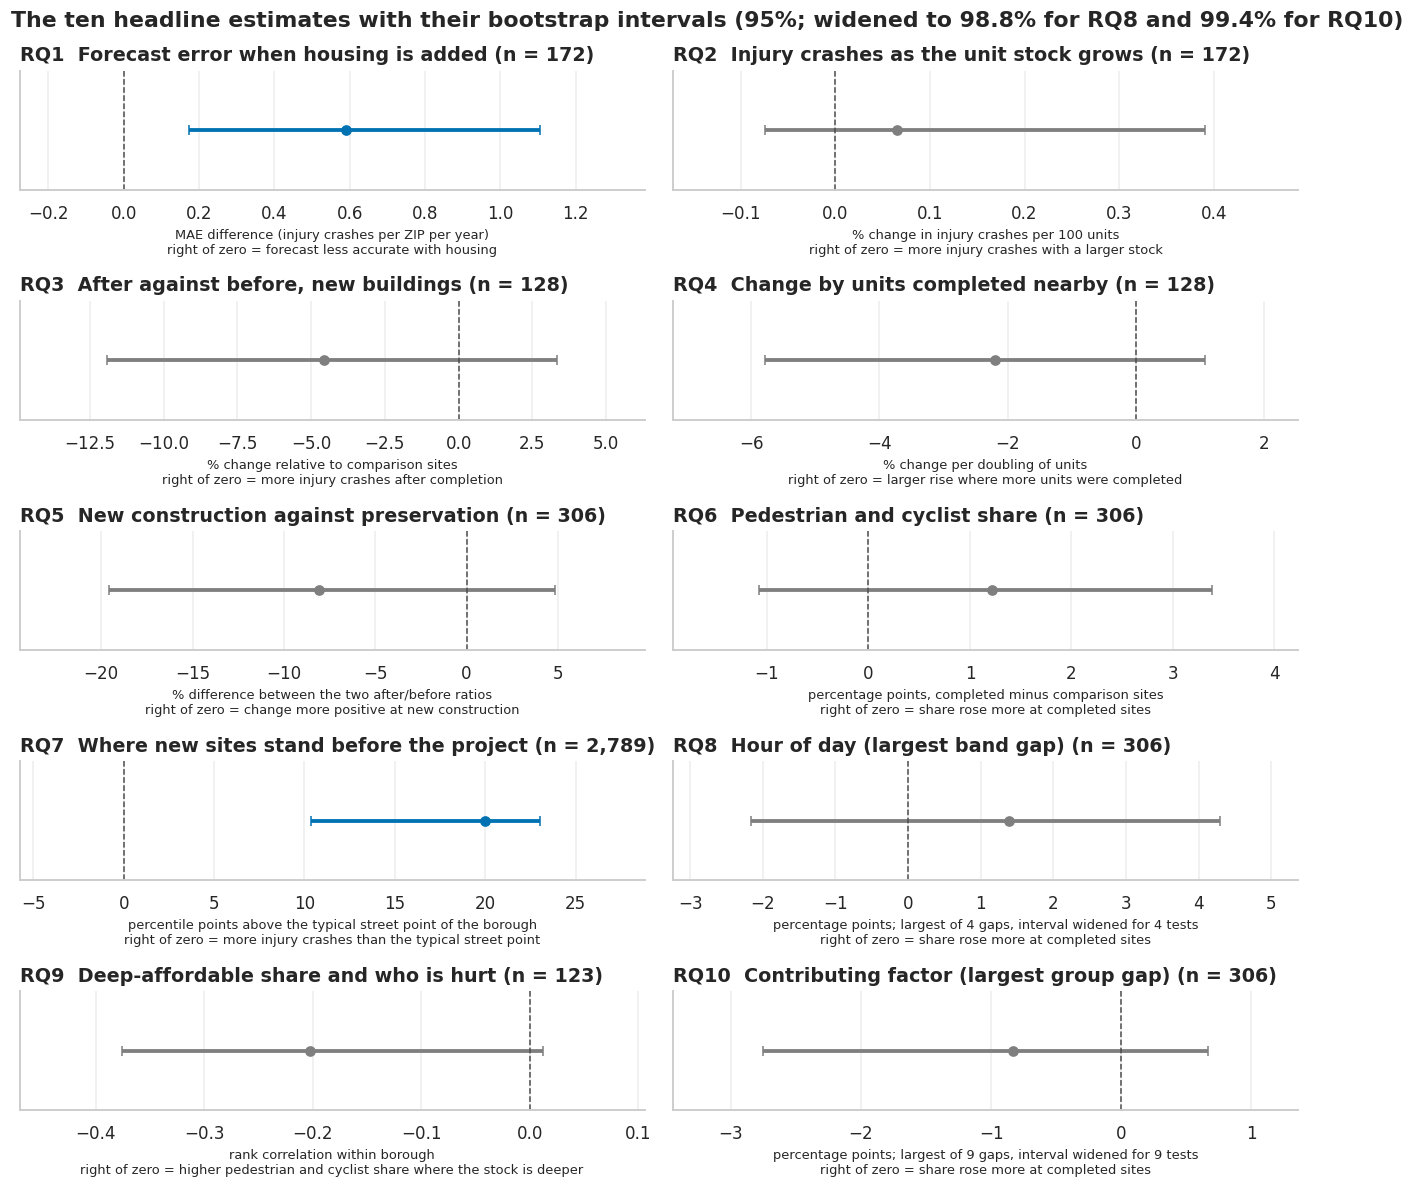

In [104]:
fig, axes = plt.subplots(5, 2, figsize=(12, 11))
for ax, (key, row) in zip(axes.ravel(), summary_table.iterrows()):
    color = PALETTE["treated"] if row["kept"] else PALETTE["control"]
    ax.errorbar(row["estimate"], 0, xerr=[[row["estimate"] - row["low"]], [row["high"] - row["estimate"]]],
                fmt="o", color=color, capsize=3, linewidth=2.5)
    ax.axvline(0, color=PALETTE["neutral"], linestyle="--", linewidth=1)
    reach = max(abs(row["low"]), abs(row["high"]))
    ax.set_xlim(min(row["low"], 0) - 0.25 * reach, max(row["high"], 0) + 0.25 * reach)
    ax.set_yticks([])
    finish(ax, f"{key}  {row['label']} (n = {row['n']:,})", f"{row['unit']}\n{row['direction']}", "")
    ax.title.set_fontsize(10)
    ax.xaxis.label.set_fontsize(8.5)
fig.suptitle(f"The ten headline estimates with their bootstrap intervals ({level_text(CI_LEVEL)}; widened to "
             f"{level_text(summary_table.loc['RQ8', 'level'])} for RQ8 and {level_text(summary_table.loc['RQ10', 'level'])} for RQ10)",
             x=0.01, ha="left", fontweight="bold")
show(fig)

In [105]:
kept = summary_table.index[summary_table["kept"]].tolist()
not_kept = summary_table.index[summary_table["excludes_zero"] & ~summary_table["kept"]].tolist()
say(f"Intervals that exclude zero and are kept: {', '.join(kept) or 'none'}. Excluding zero but not kept after "
    f"adjustment: {', '.join(not_kept) or 'none'}. All others include zero. The ten intervals are not adjusted "
    f"for each other, so one can exclude zero by chance.")

# RQ1 on reported ZIP codes only (Section 9.6): the footnote reads its numbers from the stored objects.
rq1_low, rq1_high = float(reported_forecast["low"]), float(reported_forecast["high"])
rq1_reading = "did not improve the forecast" if rq1_low <= 0 <= rq1_high else (
    "made the forecast worse" if rq1_low > 0 else "improved the forecast")
say(f"*RQ1 footnote.* On ZIP codes with a police-reported code only (Section 9.6) the change in forecast error is "
    f"{float(reported_forecast['mae_minus_baseline']):+.2f} ({rq1_low:+.2f} to {rq1_high:+.2f}), so on those codes housing "
    f"{rq1_reading}; the \"kept\" mark above reads the same way only where the interval excludes zero.")

Intervals that exclude zero and are kept: RQ1, RQ7. Excluding zero but not kept after adjustment: none. All others include zero. The ten intervals are not adjusted for each other, so one can exclude zero by chance.

*RQ1 footnote.* On ZIP codes with a police-reported code only (Section 9.6) the change in forecast error is -0.16 (-0.58 to +0.35), so on those codes housing did not improve the forecast; the "kept" mark above reads the same way only where the interval excludes zero.

**Findings, one line per question.** RQ1: housing information did not improve a ZIP-level crash
forecast. RQ2: a growing affordable stock goes with no detectable movement in a ZIP's injury
crashes. RQ3: around isolated new buildings, injury crashes changed after completion about as much
as around unfinished sites of the same programme. RQ4: no relation with the number of units
completed. RQ5: new construction cannot be told apart from preservation. RQ6, RQ8, RQ10: no
detectable shift in who is hurt, the time of day or the recorded cause. RQ7: new-construction
sites stand where injury crashes were already above the borough's typical street point before the
project started. RQ9: a weak, not-kept hint that ZIP codes with a deeper affordable mix have a
lower pedestrian and cyclist share. Section 9 changed the radius, outcome, strata, cohorts and
screen; the RQ3 reading held in every version that kept the screen.

**Answer to the main question.** For the buildings we could isolate, the crash records do not show
the feared rise after an affordable building opens, but the intervals leave room for a moderate
fall or a small rise. What the records do show is where the buildings are: on streets that already
had many injury crashes (RQ7).

### 10.1 What surprised us

In [106]:
last_year = city_year.loc[city_year["year"] == YEAR_END].iloc[0]
central_row = robustness_table.loc[robustness_table["kind"] == KIND_CENTRAL].iloc[0]
all_crash_row = robustness_table.loc[robustness_table["check"] == CHECK_OUTCOME].iloc[0]
cluster_counts = sites["cluster_id"].value_counts()
treated_candidates = event_panel[(event_panel["group"] == "treated") & (event_panel["rel_year"] == 0)]
surplus = crashes[crashes["other_injured"] > 0]
facts = {
    "crash_index": float(last_year["crash_index"]), "injury_index": float(last_year["injury_crash_index"]),
    "all_crash_change": log_points_to_percent(all_crash_row["treated_change"]),
    "injury_change": log_points_to_percent(central_row["treated_change"]),
    "all_crash_difference": float(all_crash_row["percent_change"]),
    "sites": len(sites), "share_in_largest": pct(cluster_counts.head(LARGEST_CLUSTERS_SHOWN).sum(), len(sites)),
    "median_neighbours": float(sites["n_sites_within_buffer"].median()),
    "treated_candidates": len(treated_candidates), "treated_clean": int((~treated_candidates["contaminated"]).sum()),
    "surplus_crashes": len(surplus), "surplus_share_late": pct((surplus["year"] >= SURPLUS_FROM_YEAR).sum(), len(surplus)),
}
say(f"With {INDEX_BASE_YEAR} = 100, all reported crashes stand at {facts['crash_index']:.0f} in {YEAR_END} and injury "
    f"crashes at {facts['injury_index']:.0f}. Near the RQ3 buildings all crashes change by "
    f"{facts['all_crash_change']:+.0f}% after completion and injury crashes by {facts['injury_change']:+.0f}%. The "
    f"{LARGEST_CLUSTERS_SHOWN} largest clusters hold {facts['share_in_largest']:.0f}% of {facts['sites']:,} sites; the "
    f"median site has {facts['median_neighbours']:.0f} others within {BUFFER_M} m; only {facts['treated_clean']:,} of "
    f"{facts['treated_candidates']:,} completed sites had no other completion nearby in their window. "
    f"{facts['surplus_crashes']:,} crashes report more injured than pedestrians, cyclists and motorists together, "
    f"{facts['surplus_share_late']:.0f}% of them from {SURPLUS_FROM_YEAR} on.")

With 2019 = 100, all reported crashes stand at 40 in 2025 and injury crashes at 82. Near the RQ3 buildings all crashes change by -47% after completion and injury crashes by -14%. The 3 largest clusters hold 59% of 7,593 sites; the median site has 12 others within 250 m; only 306 of 2,086 completed sites had no other completion nearby in their window. 10,178 crashes report more injured than pedestrians, cyclists and motorists together, 96% of them from 2021 on.

- **The record-keeping drop.** Counted as all crashes, streets near a new building seem to lose a
  large part of their crashes after completion. The same fall appears everywhere, because
  property-damage reports dropped in 2020. Without injury crashes and comparison sites we would
  have reported a large safety gain that was only record keeping.
- **How tightly the programme is packed.** Most buildings have other financed buildings within the
  buffer, so the before/after comparison rests on far fewer buildings than the table has rows.
- **Housing did not help a forecast** of ZIP-level injury crashes.
- **Injured totals stopped adding up** after the break; e-scooter and e-bike crashes are
  over-represented among them (4.9), which fits riders counted outside the three categories.

## 11. What the data cannot tell us

Each caveat is stated here once; Sections 8 and 9 point back to it.

In [107]:
confidential = housing["is_confidential"]
panel_crashes = crashes[crashes["in_zip_panel"]]
first_year = crashes[crashes["year"] == YEAR_START]
limits = {
    "confidential_rows": int(confidential.sum()), "confidential_row_share": pct(confidential.sum(), len(housing)),
    "confidential_unit_share": pct(housing.loc[confidential, "total_units"].sum(), housing["total_units"].sum()),
    "same_day_share": pct(housing["same_day_completion"].sum(), housing["is_completed"].sum()),
    "unlocated_share": pct((~crashes["is_located"]).sum(), len(crashes)),
    "unlocated_share_first_year": pct((~first_year["is_located"]).sum(), len(first_year)),
    "outside_panel_share": pct((~crashes["in_zip_panel"]).sum(), len(crashes)),
    "imputed_zip_share": pct(panel_crashes["zip_imputed"].sum(), len(panel_crashes)),
    "no_factor_share": pct((crashes["factor_group"] == UNRECORDED_FACTOR).sum(), len(crashes)),
    "headline_intervals": len(RESULTS), "robustness_intervals": len(robustness_table),
}
say(f"Housing: {limits['confidential_rows']:,} confidential rows ({limits['confidential_row_share']:.1f}%, "
    f"{limits['confidential_unit_share']:.2f}% of units) cannot be located; {limits['same_day_share']:.0f}% of "
    f"completed rows have a completion date equal to the start date. Crashes: {limits['unlocated_share']:.1f}% "
    f"lack usable coordinates ({limits['unlocated_share_first_year']:.1f}% in {YEAR_START}); "
    f"{limits['outside_panel_share']:.1f}% fall outside the ZIP panel and {limits['imputed_zip_share']:.1f}% of those "
    f"inside it have a recovered ZIP code; {limits['no_factor_share']:.1f}% name no contributing factor. Tests: "
    f"{limits['headline_intervals']} headline intervals and {limits['robustness_intervals']} robustness specifications.")

Housing: 1,949 confidential rows (20.4%, 0.63% of units) cannot be located; 36% of completed rows have a completion date equal to the start date. Crashes: 8.8% lack usable coordinates (16.4% in 2016); 8.0% fall outside the ZIP panel and 28.3% of those inside it have a recovered ZIP code; 24.5% name no contributing factor. Tests: 10 headline intervals and 11 robustness specifications.

- **Association, not cause.** Sites are not placed at random (RQ7). Completed sites are compared
  with unfinished sites of the same programme, but the groups still differ, and streets also get
  bike lanes, rezonings or rebuilt junctions that neither table records. For a new building the
  "before" years are construction years, and many completion dates are administrative.
- **The 2020 reporting break.** Property-damage reports collapsed in 2020 and the pandemic changed
  traffic for months; every three-year window contains that year. Injury crashes and comparison
  sites are the defence (9.1), and no cohort lets us look at a completion without the pandemic.
- **Preservation brings no new residents.** It is the placebo of RQ5. The two side results that
  exclude zero, the RQ2 completion-year slope and the RQ10 drop in reports with no factor, are both
  found for preservation and absent for new construction, so neither says what new housing does.
- **The less dense part of the programme.** The screen keeps only sites without another completion
  nearby, so RQ3 to RQ6, RQ8 and RQ10 describe the edges of the programme; inside dense clusters the
  only estimates are those without the screen (9.2).
- **E-scooter and e-bike riders are missing** from the pedestrian and cyclist columns, so those
  shares understate harm to people outside cars. Crashes are police-reported only, and nothing
  measures traffic, so a count of injury crashes is not a risk per trip.
- **Location gaps.** Unlocated crashes are most common in the first study year (9.4); recovered ZIP
  codes can be wrong at boundaries (9.6); confidential housing rows are mostly single homes, so the
  spatial results describe buildings with a published address.
- **Areas are not streets.** RQ1, RQ2 and RQ9 compare ZIP codes; they say nothing about one corner.
- **Many tests.** We adjusted inside each question but not across the notebook.
- **Only financed housing.** Market-rate buildings are in neither table, so a comparison street may
  have gained a private tower unseen, and RQ7 cannot compare with other apartment buildings.

## 12. Who can use this

- **Department of Transportation / Vision Zero.** The housing table lists financed buildings
  before completion, and new-construction addresses lean towards streets with many injury crashes
  (RQ7). Street work could be scheduled along that pipeline. Any before/after evaluation spanning
  2020 should count injury crashes and use comparison streets (9.1).
- **Housing Preservation and Development and developers.** Around the sites we could isolate, a
  completion was not followed by a detectable change in nearby injury crashes (RQ3 to RQ5); this is
  one input when traffic safety comes up in a project review, with the caveat that the interval
  allows a moderate change either way. A separate move-in date in the table would sharpen every
  before/after comparison.
- **Community boards** could ask for street improvements on the strength of the existing crash
  record (RQ7) rather than tie them to the building.
- **Residents** can read RQ6, RQ8 and RQ10 as "no detectable change in who is hurt, when, or why",
  within intervals several points wide.

## 13. Contributions

| Member | Name | Research questions and charts | Data cleaning | Integration | Website | Other work |
|---|---|---|---|---|---|---|
| M1 | Ahmed Atef | RQ1 forecast comparison (dot plot of forecast error); RQ2 within-ZIP slopes (coefficient plot with leads and lags) | Housing: blank unit counts, duplicates, geographic identifiers, dates, unit consistency, size outliers (4.1-4.6) | ZIP by year panel (5.2) | Dropdown filters and the Generate report button | Setup and data loading (1, 2), housing exploration (3.3), README run steps |
| M2 | Nour Mostafa Aly | RQ3 event study (lines with interval bands); RQ4 building size (scatter with fitted slope) | Crashes: key, duplicates, dates, time of day, borough and ZIP (4.7, 4.8) | Ball-tree distance join, choice of the 250 m buffer (5.3) | Event-study cards and the bootstrap callback | Crash exploration (3.4), bootstrap and difference-in-differences toolkit (7) |
| M3 | Yahia Mohamed | RQ5 new construction vs preservation (interval plot); RQ6 pedestrian and cyclist share by borough (interval plot) | Crashes: coordinates, casualty totals, extreme injury counts, factor groups (4.8-4.11) | Sites, clusters and the nearby-completion screen (5.4) | Search box and query parser | Robustness checks (9), data dictionary |
| M4 | Moaz Ahmed | RQ7 site selection (percentile histogram); RQ8 hour of day (interval plot of day parts) | ZIP recovery from coordinates and its holdout validation (6.1) | Tagging crashes with their nearest site (5.5), conservation checks (6.4) | Map and heat-map cards, page layout, accessibility | Deployment configuration, architecture notes |
| M5 | Yassin Fady | RQ9 deep-affordable share across ZIP codes (scatter by borough); RQ10 contributing factors (interval plot) | Post-integration cleaning: borough, redundant columns, data types (6.2, 6.3) | Cumulative stock and citywide index (6.2, 6.5), final schema | Findings and data-and-method sections of the page | Findings, limits, impact, reproducibility (10-14), hosting |

Each member reviewed the code and text of their own two questions and can explain them.

## 14. Reproducibility

Put the notebook in any folder and run all cells. If `housing_hg8x-zxpr.csv` and
`crashes_h9gi-nx95.csv.gz` are missing, Section 2 downloads them from NYC Open Data (several minutes
for the crash table); later runs work offline. Delete the two files to refresh the data. Every
random step uses the seed of Section 1, so a rerun on the same files gives the same numbers. The
written readings were checked against the copy dated below. Website code:
https://github.com/AhmedAtefYoussef/Data-Engineering-Visualization-Project

In [108]:
stages = pd.DataFrame([
    ("raw", "housing, as loaded", len(raw_housing)),
    # The raw crash frame is released after Section 4, so its length is read from the cleaning log.
    ("raw", "crashes, as loaded", next(e["rows_before"] for e in CLEANING_LOG if e["dataset"] == "crashes")),
    ("cleaned", "housing: one row per project and building", len(housing)),
    ("cleaned", "crashes: one row per collision", len(crashes)),
    ("integrated", "zip_year: ZIP code by year", len(zip_year)),
    ("integrated", "sites: located buildings", len(sites)),
    ("integrated", "site_year: site by year", len(site_year)),
    ("integrated", "event_panel: site by cohort by relative year", len(event_panel)),
    ("integrated", "crashes tagged with ZIP code and nearest site", len(crashes)),
], columns=["stage", "table", "rows"])
stages["stage"] = pd.Categorical(stages["stage"], categories=STAGE_ORDER, ordered=True)
stages = stages.set_index(["stage", "table"])
assert stages.loc[("raw", "crashes, as loaded"), "rows"] == len(crashes), "cleaning keeps every crash"
assert crashes["collision_id"].is_unique and not zip_year.duplicated(["zip", "year"]).any()
show_table(stages)
show_table(pd.DataFrame({"version": {
    "Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": mpl.__version__,
    "seaborn": sns.__version__, "requests": requests.__version__, "pyarrow": pyarrow.__version__}}))


def file_stamp(path):
    """Date on which a local data file was last written (the day it was downloaded)."""
    return pd.Timestamp(path.stat().st_mtime, unit="s").strftime("%Y-%m-%d")


say(f"Seed {SEED}; {N_BOOT:,} bootstrap resamples per interval; study window {YEAR_START}-{YEAR_END}. Data as of: "
    f"latest crash {crashes['crash_date'].max():%Y-%m-%d}, latest housing completion "
    f"{housing['completion_date'].max():%Y-%m-%d}; housing file saved {file_stamp(HOUSING_FILE)}, crash file "
    f"{file_stamp(CRASH_FILE)}.")

rows
stage      table                                                 
raw        housing, as loaded                                9551
           crashes, as loaded                             1504722
cleaned    housing: one row per project and building         9551
           crashes: one row per collision                 1504722
integrated zip_year: ZIP code by year                        1720
           sites: located buildings                          7593
           site_year: site by year                          75930
           event_panel: site by cohort by relative year     93618
           crashes tagged with ZIP code and nearest site  1504722

,version
Python,3.14.3
pandas,2.3.3
numpy,2.4.4
scipy,1.17.1
scikit-learn,1.8.0
matplotlib,3.10.9
seaborn,0.13.2
requests,2.34.2
pyarrow,23.0.1


Seed 42; 1,000 bootstrap resamples per interval; study window 2016-2025. Data as of: latest crash 2025-12-31, latest housing completion 2026-08-21; housing file saved 2026-10-10, crash file 2026-10-10.

## 15. Prompts and AI use

The project brief asks the notebook to contain the prompts used. Claude models (through Claude
Code) drafted the code and text under the team's direction; the notebook and website call no model.
The key prompt patterns were:

- **A request with the project description attached**, asking to analyse the data catalogue, pick
  the datasets, split the work among assistants and audit the result against the requirements.
- **One shared brief for every section author**, with checkable rules: injury crashes as the primary
  outcome because of the 2020 break, the two integration levels (ZIP x year, 250 m proximity), no
  data-derived number typed into markdown, an `assert` for each invariant, one chart per question,
  no causal wording.
- **Ownership boundaries:** each assistant edited one file and reported the interface it provides.
- **Reviewers who read but do not edit**, returning findings with location, severity and fix, then
  fix passes by the authors, each run on the real data before acceptance.
- **Model tiering:** a stronger model for design and review, a cheaper one for routine code.

The prompt texts and the build process are in `docs/AI_USE.md`.